# Publication figures

Consolidated, publication-quality figures for the digital-bat paper. Every analysis loads the **17 `DEFAULT_SESSIONS` once** (`use_kinematics=False`) and uses the single consensus joint model `joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth` throughout. Shared style/stat/plot helpers live in `plotting_helpers.py`.

In [154]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import optuna
import hashlib
from sklearn.neighbors import KNeighborsRegressor


sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
import cebra, cebra.data, cebra.models, cebra.solver
from cebra import CEBRA

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
import notebook_helpers as nh
import plotting_helpers as ph

ph.set_pub_style()
ph.FIG_DIR = Path('out/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# Canonical display name for the joint encode/decode transformer (used in all labels).
OUR_MODEL = 'Twin'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cuda


## Shared setup

Load the 17 `DEFAULT_SESSIONS` **once** (`use_kinematics=False`, `behavior_dim==3`, Krishna excluded) and instantiate the single consensus joint model used throughout the paper. Downstream figures reuse these objects; nothing below re-loads data or re-instantiates the model.

In [2]:
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders

# 17 DEFAULT_SESSIONS, position-only (behavior_dim == 3).
session_names = list(DEFAULT_SESSION_NAMES)
data_config = make_data_config(session_names=session_names)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

# Single load in the joint model's *training* universe. make_joint_dataloaders
# loads once (kinematics on) and returns the position-only view `dl_pos` plus the
# shared meta. We use this ONE universe for BOTH the encode and decode arms so
# every analysis shares one flight_path_index (no cross-universe remapping). The
# tradeoff vs the plain position-only loader is that a few tail flights with short
# IMU are dropped — negligible, and it matches how the model was trained.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

bats = ph.bat_order()
BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(f'{len(session_names)} sessions | {n_neurons_total} neurons | behavior_dim={behavior_dim}')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
17 sessions | 3080 neurons | behavior_dim=3


In [3]:
# === Dataset descriptive statistics (paper "Methods"/Table 1 numbers) ===
# Summarises the recording sessions loaded above: neuron / session / bat /
# environment counts, plus per-session flight counts. Everything derives from the
# single joint flight universe (`unit_num_dict` + `dataloaders`), so these numbers
# match every downstream analysis in the paper.
from collections import Counter


def _room(s):
    """3-config recording environment: indoor lab / Dataset-2 outdoor / Krishna flight room."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


# Per-session unique-flight counts, split by train/valid/test, from the shared loaders.
_flight_counts = {}
for _split, _sd in dataloaders.items():
    for _s, _dl in _sd.items():
        _fids = set()
        for _b in _dl:
            _fids.update(np.unique(_b.flight_path_index.numpy()).tolist())
        _flight_counts.setdefault(_s, {})[_split] = len(_fids)

# One row per session.
sess_df = pd.DataFrame([{
    'session': s,
    'bat': parse_bat(s),
    'dataset': s.split('_')[0] + '_' + s.split('_')[1],   # Dataset_1 / Dataset_2 / Dataset_3
    'environment': _room(s),
    'indoor': bool(ph.is_indoor(s)),
    'n_neurons': int(unit_num_dict[s]),
    'n_flights_train': _flight_counts.get(s, {}).get('train', 0),
    'n_flights_valid': _flight_counts.get(s, {}).get('valid', 0),
    'n_flights_test': _flight_counts.get(s, {}).get('test', 0),
} for s in session_names])
sess_df['n_flights'] = sess_df[['n_flights_train', 'n_flights_valid', 'n_flights_test']].sum(axis=1)

# Neurons-per-session summary (mean +/- sem, sd, median, range).
_n = sess_df['n_neurons']
_mean, _sd = _n.mean(), _n.std(ddof=1)
_sem = _sd / np.sqrt(len(_n))

# Per-bat and per-environment rollups.
bat_summary = (sess_df.groupby('bat')
               .agg(n_sessions=('session', 'size'), n_neurons=('n_neurons', 'sum'),
                    n_flights=('n_flights', 'sum'))
               .reset_index().sort_values('bat'))
env_summary = (sess_df.groupby('environment')
               .agg(n_sessions=('session', 'size'), n_bats=('bat', 'nunique'),
                    n_neurons=('n_neurons', 'sum'), n_flights=('n_flights', 'sum'))
               .reset_index())

# Putative cell-type breakdown across all neurons, if available in meta.
_ptype = Counter()
for s in session_names:
    _pt = meta_info_dict.get('pType', {}).get(s)
    if _pt is not None:
        _ptype.update(str(x) for x in np.asarray(_pt).ravel())

# ---- Headline numbers ----
print('=' * 64)
print('DATASET DESCRIPTIVE STATISTICS')
print('=' * 64)
print(f'Sessions          : {len(session_names)}')
print(f'Bats              : {sess_df["bat"].nunique()}  ({", ".join(sorted(sess_df["bat"].unique()))})')
print(f'Environments      : {sess_df["environment"].nunique()}  ({", ".join(sorted(sess_df["environment"].unique()))})')
print(f'Datasets          : {sess_df["dataset"].nunique()}  ({", ".join(sorted(sess_df["dataset"].unique()))})')
print(f'Indoor / outdoor  : {int(sess_df["indoor"].sum())} / {int((~sess_df["indoor"]).sum())} sessions')
print(f'Total neurons     : {int(_n.sum())}')
print(f'Total flights     : {int(sess_df["n_flights"].sum())} '
      f'(train {int(sess_df["n_flights_train"].sum())} / '
      f'valid {int(sess_df["n_flights_valid"].sum())} / '
      f'test {int(sess_df["n_flights_test"].sum())})')
print(f'Bin width         : {bin_width * 1e3:.0f} ms   |   behavior_dim = {behavior_dim}')
print('-' * 64)
print(f'Neurons / session : {_mean:.1f} +/- {_sem:.1f} (sem), sd {_sd:.1f}, '
      f'median {_n.median():.0f} [range {_n.min()}-{_n.max()}]')
print(f'Sessions / bat    : mean {bat_summary["n_sessions"].mean():.1f} '
      f'[range {bat_summary["n_sessions"].min()}-{bat_summary["n_sessions"].max()}]')
if _ptype:
    print(f'Putative types    : {dict(_ptype)}')
print('=' * 64)

display(sess_df)
display(bat_summary)
display(env_summary)


DATASET DESCRIPTIVE STATISTICS
Sessions          : 17
Bats              : 6  (00000, 14445, 14543, 14611, 29959, 32622)
Environments      : 2  (dataset_2, lab)
Datasets          : 3  (Dataset_1, Dataset_2, Dataset_3)
Indoor / outdoor  : 13 / 4 sessions
Total neurons     : 3080
Total flights     : 1738 (train 1208 / valid 252 / test 278)
Bin width         : 100 ms   |   behavior_dim = 3
----------------------------------------------------------------
Neurons / session : 181.2 +/- 20.2 (sem), sd 83.1, median 168 [range 54-394]
Sessions / bat    : mean 2.8 [range 2-4]
Putative types    : {'pPYR': 1893, 'pINT': 207, '[]': 462, 'unclassified': 518}


,session,bat,dataset,environment,indoor,n_neurons,n_flights_train,n_flights_valid,n_flights_test,n_flights
0,Dataset_3_14543_240420,14543,Dataset_3,lab,True,126,94,20,21,135
1,Dataset_3_14543_240421,14543,Dataset_3,lab,True,100,78,16,18,112
2,Dataset_3_29959_240402,29959,Dataset_3,lab,True,317,101,21,23,145
3,Dataset_3_29959_240403,29959,Dataset_3,lab,True,191,88,19,20,127
4,Dataset_3_29959_240404,29959,Dataset_3,lab,True,190,54,11,13,78
5,Dataset_2_14445_231208,14445,Dataset_2,dataset_2,False,237,53,11,13,77
6,Dataset_2_14445_231209,14445,Dataset_2,dataset_2,False,168,53,11,12,76
7,Dataset_1_32622_231009,32622,Dataset_1,lab,True,95,54,11,13,78
8,Dataset_1_32622_231010,32622,Dataset_1,lab,True,54,65,14,15,94
9,Dataset_1_32622_231007,32622,Dataset_1,lab,True,167,67,14,16,97


,bat,n_sessions,n_neurons,n_flights
0,00000,4,870,466
1,14445,2,405,153
2,14543,2,226,247
3,14611,2,422,127
4,29959,4,841,476
5,32622,3,316,269


,environment,n_sessions,n_bats,n_neurons,n_flights
0,dataset_2,4,2,827,280
1,lab,13,4,2253,1458


In [4]:
from digitalbat.models.joint import JointMaskedTransformer

# --- Consensus model: the single joint encode/decode transformer used paper-wide
# (encode+decode+cross, tuned 1000 ep; joint-encode-decode.ipynb §6.10).
JOINT_CKPT = './out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth'  # cross_1000 production model (encode+decode+cross, tuned 1000ep; joint-encode-decode.ipynb §6.10)
# JOINT_CKPT = './out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft.pth'  # warm-started 6-scheme finetune (md5 79f7f15b) -- overwritten by cross weights 07-09
# JOINT_CKPT = './out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft_5scheme.pth'  # original 5-scheme finetune (md5 726b6ab) -- true infillft weights that produced the old figures
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)
INPUT_TRANSFORM = 'identity'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}

set_random_state(seed)
if os.path.exists(JOINT_CKPT):
    joint_model = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, input_transform=INPUT_TRANSFORM,
        session_to_room=session_to_room, **JOINT_PARAMS).to(device)
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    joint_model = joint_model.eval()
else:
    # Train-if-missing: 200-trial Optuna search (use_kinematics=False, fde_weight=0.5),
    # then train the winner. Reproduces the consensus checkpoint named above.
    from digitalbat.training.joint_trainer import ensure_joint_model
    joint_model, _jp, JOINT_CKPT = ensure_joint_model(
        dataloaders, unit_num_dict, session_to_room, meta_info_dict, device,
        seed=seed, out_dir='./out/joint', n_trials=200)
    JOINT_PARAMS = dict(num_layers=_jp['num_layers'], latent_dim=_jp['latent_dim'],
                        num_heads=4, ff_dim=_jp['ff_dim'], dropout=_jp['dropout'])

# Encode and decode arms share ONE flight universe (see the data-load cell), so the
# decode-arm loaders/meta are simply the shared ones — no separate universe.
joint_loaders, joint_meta = dataloaders, meta_info_dict
print('consensus joint model ready:', JOINT_CKPT)

consensus joint model ready: ./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


In [5]:
# Encode-arm adapter + per-neuron encode-metric helper now live in the package
# (digitalbat.models.joint), keeping this notebook focused on the figures.
from digitalbat.models.joint import JointEncoderAdapter, encode_eval_records

bat_former = JointEncoderAdapter(joint_model, unit_num_dict).to(device).eval()

### Training utilities (train-if-missing)

Every model below loads its cached checkpoint if present; otherwise it is **trained
here** (the training code is ported from the source notebooks — `model_comparison`,
`decode-position-comparison`, `perturbations`) and saved, so `figures.ipynb` is
reproducible from scratch and fast on re-runs. Set `FORCE_RETRAIN = True` to ignore
the cache.

In [6]:
# === Training utilities: load-or-train for every model ===
import optuna
from copy import deepcopy
from digitalbat.models.former_defaults import make_trainer_config
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.models.glm import coupling_group_penalty

optuna.logging.set_verbosity(optuna.logging.WARNING)
from tqdm import tqdm as _tqdm


def _optuna_progress(study, trial):
    """Print one line after every Optuna trial so searches are never silent."""
    v = f'{trial.value:.4f}' if trial.value is not None else str(trial.value)
    try:
        best = f'{study.best_value:.4f}'
    except ValueError:
        best = 'n/a'
    print(f'    [optuna] trial {trial.number + 1} value={v} best={best} params={trial.params}', flush=True)
FORCE_RETRAIN = False
GLM_N_TRIALS, GLM_WD_RANGE, GLM_ALPHA_RANGE = 10, (1e-4, 50.0), (1e-4, 1e2)
NB_N_TRIALS = 20


def _exists(path):
    return (not FORCE_RETRAIN) and os.path.exists(path)


# --- GLM trainer (Poisson NLL; coupling params get lower LR + group-lasso) ---
def _val_fde_glm(model, flight_cluster=None):
    model.eval(); scores = []
    is_joint = getattr(model, 'joint', False)
    with torch.no_grad():
        for s, sd in dataloaders['valid'].items():
            yt, yp = [], []
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                m = b.mask.to(device)
                out = model(s, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
                v = m == 1.0
                yt.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
            scores.append(poisson_fde_population(np.vstack(yt), np.vstack(yp)))
    return float(np.nanmedian(np.hstack(scores)))


def train_glm(model, alpha=0.0, weight_decay=1.0, flight_cluster=None, n_epochs=1000,
              lr=1e-2, coup_lr=1e-3, grad_clip=5.0, patience=20, label=''):
    model = model.to(device)
    loss_fn = nn.PoissonNLLLoss(log_input=False).to(device)
    is_joint = getattr(model, 'joint', False); use_coup = getattr(model, 'use_coup', False)
    coup_ids = set(id(p) for p in model.coup_weights.parameters()) if use_coup else set()
    opt = torch.optim.AdamW(
        [{'params': [p for p in model.parameters() if id(p) not in coup_ids], 'weight_decay': weight_decay, 'lr': lr},
         {'params': [p for p in model.parameters() if id(p) in coup_ids], 'weight_decay': 0.0, 'lr': coup_lr}], lr=lr)
    best, best_w, no_imp = -np.inf, None, 0
    bar = _tqdm(range(n_epochs), desc=f'  train_glm{label}', leave=False)
    for _ in bar:
        model.train()
        for s, sd in dataloaders['train'].items():
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                X, Y, M = b.behavior.to(device), b.spike.to(device), b.mask.to(device)
                out = model(s, X, M, spike=Y, cluster_idx=ci); v = M == 1.0
                loss = loss_fn(out[v], Y[v])
                if use_coup:
                    loss = loss + alpha * coupling_group_penalty(model.coup_weights[s])
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip); opt.step()
        val = _val_fde_glm(model, flight_cluster)
        if val > best:
            best, best_w, no_imp = val, deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
        bar.set_postfix(val=f'{val:.4f}', best=f'{best:.4f}', no_imp=no_imp)
        if no_imp >= patience:
            break
    bar.close()
    if best_w is not None:
        model.load_state_dict(best_w)
    return best


def ensure_glm(path, make_model, cond='position', search_alpha=False):
    """GLM train-if-missing: Optuna over weight_decay (+ coupling alpha), then save."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    fc = flight_cluster if cond == 'joint' else None
    print(f'  [train GLM] {os.path.basename(path)}')

    def objective(trial):
        wd = trial.suggest_float('weight_decay', *GLM_WD_RANGE, log=True)
        a = trial.suggest_float('alpha', *GLM_ALPHA_RANGE, log=True) if search_alpha else 0.0
        set_random_state(seed)
        return train_glm(make_model().to(device), alpha=a, weight_decay=wd, flight_cluster=fc,
                         label=f' t{trial.number + 1}/{GLM_N_TRIALS}')

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=GLM_N_TRIALS, callbacks=[_optuna_progress])
    bp = study.best_params
    print(f'    [GLM] best params: {bp}', flush=True)
    set_random_state(seed); m = make_model().to(device)
    train_glm(m, alpha=bp.get('alpha', 0.0), weight_decay=bp['weight_decay'], flight_cluster=fc,
              label=' [final]')
    os.makedirs(os.path.dirname(path), exist_ok=True); torch.save(m.state_dict(), path)
    return m.eval()


def ensure_former(path, make_model, loaders=None):
    """Encoder (Bat_Transformer) train-if-missing via bat_former_trainer."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train encoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tc = make_trainer_config(model=m, dataloaders=loaders or dataloaders, device=device, model_name=path)
    tc['verbose'] = True  # show per-epoch tqdm progress instead of training silently
    _, best_w, _ = bat_former_trainer(**tc)
    torch.save(best_w, path); m.load_state_dict(best_w)
    return m.eval()


def ensure_nb_params(path, ndim, build_arrays):
    """NB Optuna hyperparameter search, train-if-missing. `build_arrays()` returns
    {session: (train, valid, r_lim)} of gathered arrays; caches the study to `path`."""
    import pickle as _pk
    if _exists(path):
        return _pk.load(open(path, 'rb')).best_params
    print(f'  [search NB-{ndim}d] {os.path.basename(path)}')
    sess_arr = build_arrays()

    def objective(trial):
        p = dict(sigma=trial.suggest_float('sigma', 0.5, 4.0),
                 n_bins_x=trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50]),
                 n_bins_y=trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50]),
                 min_occupancy=trial.suggest_int('min_occupancy', 1, 10),
                 use_uniform_prior=trial.suggest_categorical('use_uniform_prior', [True, False]))
        if ndim == 3:
            p['n_bins_z'] = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
        errs = []
        for s, (tr, va, r_lim) in sess_arr.items():
            try:
                nb = make_nb(ndim, r_lim, p).fit(tr['spikes'], np.column_stack([tr[c] for c in cols]))
                pdec, _ = nb.predict(va['spikes'])
                errs.append(np.median(np.sqrt(((np.column_stack([va[c] for c in cols]) - pdec) ** 2).sum(1))))
            except Exception:
                return -np.inf
        return -float(np.mean(errs))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=NB_N_TRIALS, callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(path), exist_ok=True); _pk.dump(study, open(path, 'wb'))
    return study.best_params


def ensure_decoder(path, make_model, loaders=None, n_epochs=1000, lr=1e-3, weight_decay=1e-2):
    """Transformer decoder (Bat_Transformer_Decoder) train-if-missing."""
    from digitalbat.models.decoder import bat_decoder_trainer
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train decoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    bat_decoder_trainer(model=m, dataloaders=loaders or dataloaders, device=device, pos_dims=3,
                        n_epochs=n_epochs, lr=lr, weight_decay=weight_decay,
                        loss_fn=nn.SmoothL1Loss(), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
                        valid_stat='median', early_stopping_patience=30, save_model=True, model_name=path)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.eval()


---
## Figure 1 — Transformer encoding/decoding models outperform standard approaches

**a** Model schematic (dual-branch architecture; drawn separately). **b** Example decoded 3-D trajectory (Twin). **c** Decoding accuracy (3-D Fréchet distance per flight) for `NB (place)', `unified CEBRA', and the Twin. **d** Dual-field example unit on two flight clusters (rows): observed spikes (*left*), empirical rate map (*center*), Twin predicted-rate map (*right*). **e–f** Per-neuron encoding fit — Poisson FDE (**e**) and Pearson r (**f**) — for `GLM (place)', `GLM (trajectory-specific place)', and the Twin. **g–h** Transfer-analysis schematics (frozen base model, fine-tuned session readouts; drawn separately). **i** Poisson FDE for the Twin trained from scratch, transferred (frozen base + fine-tuned readouts), or the full 17-session model, cross-validated leave-one-session-out.

In [7]:
# --- Joint DECODE arm: predict 3D position from spikes (all behaviour masked).
# Per-timestep records feed the trajectory panel (1f) and per-flight Fréchet
# distance (1g). Uses the joint decode loaders + meta.
from digitalbat.decoding import discrete_frechet

TRUTH_3D = ['x_true', 'y_true', 'z_true']
PRED_3D = ['x_pred', 'y_pred', 'z_pred']


@torch.no_grad()
def joint_decode_records(split='test'):
    recs = []
    for sn, sd in joint_loaders[split].items():
        bm = np.asarray(joint_meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(joint_meta['behavior_std'][sn]).reshape(-1)[:3]
        bat = parse_bat(sn)
        for batch in sd:
            m = batch.mask.to(device)
            bt = batch.mask.clone().to(device)      # decode: all behaviour masked
            nt = torch.zeros_like(bt)
            _, beh_pred, _ = joint_model(sn, batch.spike.to(device),
                                         batch.behavior.to(device), m, nt, bt)
            yp = beh_pred[:, :, :3].cpu().numpy() * bs + bm
            yt = batch.behavior[:, :, :3].numpy() * bs + bm
            mn = batch.mask.numpy().astype(bool)
            B, T = mn.shape
            fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mn], yp[mn]
            for i in range(len(ytf)):
                recs.append(dict(bat=bat, session=sn, flight_id=int(fpi[mn][i]),
                                 t_idx=int(tix[mn][i]),
                                 x_true=ytf[i, 0], y_true=ytf[i, 1], z_true=ytf[i, 2],
                                 x_pred=ypf[i, 0], y_pred=ypf[i, 1], z_pred=ypf[i, 2],
                                 err_2d=float(np.linalg.norm(ytf[i, :2] - ypf[i, :2])),
                                 err_3d=float(np.linalg.norm(ytf[i] - ypf[i]))))
    return pd.DataFrame(recs).assign(decoder='joint')


def frechet_per_flight(df, truth=TRUTH_3D, pred=PRED_3D):
    """Per-(decoder, session, flight) discrete 3D Fréchet distance."""
    rows = []
    gcols = ['bat', 'session', 'flight_id']
    gcols = (['decoder'] + gcols) if 'decoder' in df else gcols
    for keys, grp in df.groupby(gcols, sort=False, observed=True):
        grp = grp.sort_values('t_idx')
        row = dict(zip(gcols, keys if isinstance(keys, tuple) else (keys,)))
        row['frechet_3d'] = discrete_frechet(grp[truth].to_numpy(float),
                                             grp[pred].to_numpy(float))
        rows.append(row)
    return pd.DataFrame(rows)


joint_decode_test = joint_decode_records('test')
joint_frechet = frechet_per_flight(joint_decode_test)
print('joint decode: %d timepoints, %d flights' % (len(joint_decode_test), len(joint_frechet)))

joint decode: 8072 timepoints, 278 flights


In [8]:
# === Fig 1b: pick one example decoded flight — a cleanly decoded rew→rew loop ===
from digitalbat.decoding import polylines_from_per_timestep_df, plot_trajectory_zoom_3d
from digitalbat.utility.utils import frechet_distance
from notebook_helpers import DIST_THRESH, get_target_locs

# Per-flight route from the TRUE endpoints (1 rew→rew, 2 rew→perch, 3 perch→rew;
# ph.route_id). Keep indoor rew→rew loops (route 1) and show the best-decoded one
# (lowest per-flight 3-D Fréchet).
LOOP_ROUTES = {1}
_rows = []
for (sn, fid), g in joint_decode_test.groupby(['session', 'flight_id'], sort=False):
    if not ph.is_indoor(sn):
        continue
    pos = g.sort_values('t_idx')[['x_true', 'y_true', 'z_true']].to_numpy()
    rew, perch = get_target_locs(sn)
    route = ph.route_id(ph.endpoint_class(pos[0], rew, perch, DIST_THRESH),
                        ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH))
    if route in LOOP_ROUTES:
        _rows.append(dict(session=sn, flight_id=int(fid), route=route, n=len(g)))
_ex = pd.DataFrame(_rows).merge(
    joint_frechet[['session', 'flight_id', 'frechet_3d']], on=['session', 'flight_id'])
if _ex.empty:
    raise RuntimeError('No indoor rew→rew loop flight found in the decoded test set.')
_best = _ex.loc[_ex['frechet_3d'].idxmin()]
zoom_session = _best['session']
example_flight = int(_best['flight_id'])
print('chosen zoom_session:', zoom_session)
print(f"  loop flight {example_flight}: route={ph.ROUTE_LABELS[int(_best['route'])]}, "
      f"Fréchet={_best['frechet_3d']:.3f} m, {int(_best['n'])} timesteps")

# example_flight drawn in the merged Fig 1 cell below (panel b).

chosen zoom_session: Dataset_3_29959_240404
  loop flight 36: route=rew→rew, Fréchet=0.232 m, 41 timesteps


In [9]:
# === Fig 1c baseline: naïve-Bayes (place) decoder ===
# Ported from decode-position-comparison.ipynb: per-session NB-2D/3D on the base
# dataloaders, hyperparameters from the cached Optuna studies.
from digitalbat.models.decoder import NaiveBayes_Decoder

# nb_best (NB hyperparameters) is computed below, after make_nb / gather_session_arrays.


def gather_session_arrays(loader, bm, bs):
    spk, beh, msk, fpi = [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool)); fpi.append(batch.flight_path_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T, _ = beh.shape
    fpit = np.broadcast_to(fpi[:, None], (B, T)); tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpit[msk].astype(int), t_idx=tix[msk].astype(int))


def make_nb(ndim, r_lim, p):
    n_bins = (p['n_bins_x'], p['n_bins_y'], p['n_bins_z']) if ndim == 3 else (p['n_bins_x'], p['n_bins_y'])
    return NaiveBayes_Decoder(n_bins=n_bins, lims=[tuple(r_lim[d]) for d in range(ndim)],
                              sigma=p['sigma'], dt=bin_width, min_occupancy=p['min_occupancy'],
                              use_uniform_prior=p['use_uniform_prior'])


def _nb_session_arrays():
    sa = {}
    for s in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][s], meta_info_dict['behavior_std'][s]
        r_lim = meta_info_dict['r_lim'][s]
        tr = gather_session_arrays(dataloaders['train'][s], bm, bs)
        va = gather_session_arrays(dataloaders['valid'][s], bm, bs)
        if tr['spikes'].shape[0] >= 100 and va['spikes'].shape[0] >= 10:
            sa[s] = (tr, va, r_lim)
    return sa


nb_best = {n: ensure_nb_params(f'./out/nb_decoder/nb_decoder_{n}d_seed_{seed}_optuna.pkl',
                               n, _nb_session_arrays) for n in (2, 3)}


def eval_nb_records():
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        te3 = np.column_stack([te['pos_x'], te['pos_y'], te['pos_z']])
        nb3 = make_nb(3, r_lim, nb_best[3]).fit(tr['spikes'], tr3)
        pd3, _ = nb3.predict(te['spikes'])
        err3 = np.sqrt(((te3 - pd3) ** 2).sum(1))
        for i in range(len(err3)):
            recs.append(dict(bat=parse_bat(sn), session=sn, flight_id=int(te['flight_id'][i]),
                             t_idx=int(te['t_idx'][i]), x_true=te3[i, 0], y_true=te3[i, 1],
                             z_true=te3[i, 2], x_pred=pd3[i, 0], y_pred=pd3[i, 1], z_pred=pd3[i, 2],
                             err_3d=float(err3[i])))
    return pd.DataFrame(recs)


nb_decode_test = eval_nb_records()
nb_frechet = frechet_per_flight(nb_decode_test)
print('NB (place) decode: %d points, %d flights' % (len(nb_decode_test), len(nb_frechet)))

NB (place) decode: 8072 points, 278 flights


loaded cached CEBRA study (20 trials)
 number    value  params_learning_rate params_model_architecture  params_num_hidden_units  params_output_dimension  params_temperature  params_time_offsets  user_attrs_median_err_3d  user_attrs_median_frechet    state
      0 2.095803              0.000468            offset36-model                       64                        3            0.106509                   10                  1.988164                   3.025811 COMPLETE
      1 1.098785              0.000264            offset36-model                       64                       32            0.125414                   10                  0.825224                   2.386467 COMPLETE
      2 0.361967              0.000197             offset5-model                       32                       32            0.810206                    5                  0.246174                   0.489537 COMPLETE
      3 0.488863              0.000260             offset5-model                       32 

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  setter([_cap_first(l) for l in labs])


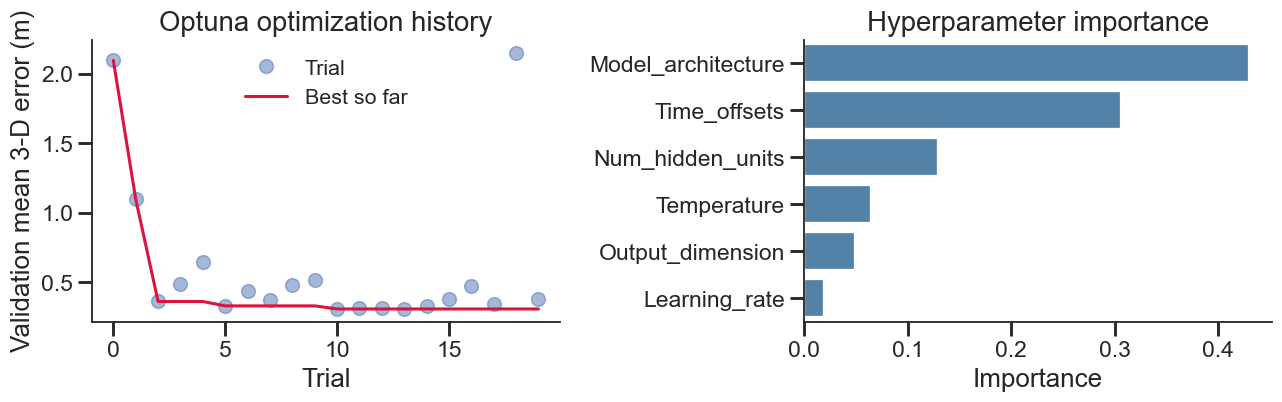

In [10]:
# === CEBRA hyperparameter search (Optuna) over the high-impact set ===
# TPE search minimising mean 3-D KNN-decoding error of position on the VALIDATION
# split (same KNN_N / cosine readout as Fig 1c; the test split is held out for the
# final Fig 1c report). Axes: num_hidden_units & output_dimension (same
# options as the coarse grid) plus temperature, time_offsets, learning_rate and
# the encoder receptive-field (offset) architecture. Each trial trains one
# unified CEBRA model, cached by _hp_tag(); the study is pickled (run-once).
# NOTE: cold cost ~= N_TRIALS CEBRA trainings (minus _hp_tag cache hits).

OUT_DIR, CEBRA_MAX_ITER, KNN_N, UNI_VARIANT = './out/cebra', 6000, 36, 'cebra_pos'
UNIFIED_MASKS = {'RandomNeuronMask': (0.3, 0.9, 0.05), 'RandomTimestepMask': (0.3, 0.9, 0.05)}
N_TRIALS = 20                                            # Optuna trials (encoded in the study/model paths)
_sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
# Hyperparameters are the Optuna sweep's best trial (no hardcoded default); the
# study pickle is produced by the CEBRA hyperparameter-search cell below.
CEBRA_STUDY_PATH = (f'{OUT_DIR}/cebra_hparam_optuna__it{CEBRA_MAX_ITER}_t{N_TRIALS}'
                    f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pkl')
CEBRA_HP = {}                                            # locked to the study's best trial below


def _hp_tag():
    a = CEBRA_HP['model_architecture'].replace('-model', '')
    return (f"{a}_lr{CEBRA_HP['learning_rate']:.0e}_t{CEBRA_HP['temperature']:.2g}"
            f"_to{CEBRA_HP['time_offsets']}_d{CEBRA_HP['output_dimension']}_h{CEBRA_HP['num_hidden_units']}")

def session_flights(session, split):
    bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
    bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
    out = []
    for batch in dataloaders[split][session]:
        m = batch.mask.numpy().astype(bool)
        spike = batch.spike.numpy(); pos_z = batch.behavior[:, :, :3].numpy()
        fpi = batch.flight_path_index.numpy()
        for b in range(m.shape[0]):
            sel = m[b]
            if sel.sum() == 0:
                continue
            out.append(dict(spike=spike[b, sel].astype(np.float32),
                            pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                            flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
    return out

def build_unified_solver(neuron_counts):
    model = cebra.models.init(CEBRA_HP['model_architecture'], num_neurons=int(sum(neuron_counts)),
                                num_units=CEBRA_HP['num_hidden_units'],
                                num_output=CEBRA_HP['output_dimension']).to(device)
    crit = cebra.models.FixedCosineInfoNCE(temperature=CEBRA_HP['temperature']).to(device)
    opt = torch.optim.Adam(list(model.parameters()), lr=CEBRA_HP['learning_rate'])
    return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)

def fit_unified(Xs, Ys, path):
    solver = build_unified_solver([X.shape[1] for X in Xs])
    if os.path.exists(path):
        solver.load_state_dict(torch.load(path, map_location=device, weights_only=False), strict=True)
        return solver
    dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                        continuous=Ys[i].astype(np.float32), device=device)
                for i in range(len(Xs))]
    dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
    dataset.set_masks(UNIFIED_MASKS); dataset.to(device)
    loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta', num_steps=CEBRA_MAX_ITER,
                                        batch_size=512, time_offset=CEBRA_HP['time_offsets'])
    dataset.configure_for(solver.model)
    set_random_state(seed); solver.fit(loader)
    solver.save(logdir=os.path.dirname(path), filename=os.path.basename(path))
    return solver

def unified_embed_split(solver, split):
    fb = {s: session_flights(s, split) for s in session_names}
    Xs_all = [np.vstack([f['spike'] for f in fb[s]]).astype(np.float32) for s in session_names]
    Ys_all = [np.vstack([f['pos'] for f in fb[s]]).astype(np.float32) for s in session_names]
    Xt, Yt = [torch.from_numpy(X) for X in Xs_all], [torch.from_numpy(Y) for Y in Ys_all]
    solver = solver.to('cpu'); out = {}
    for i, s in enumerate(session_names):
        bs_ = min(512, max(2, len(Xs_all[i]) // 3))
        emb = solver.transform(Xt, Yt, session_id=i, batch_size=bs_).cpu().numpy()
        pieces, c = [], 0
        for f in fb[s]:
            L = len(f['spike']); pieces.append((emb[c:c + L], f)); c += L
        out[s] = pieces
    solver.to(device)
    return out

# Unified-model training data: every session's train-split flights (shared by the Optuna
# search below and the Fig 1c decoder cell).
_train_by = {s: session_flights(s, 'train') for s in session_names}
Xs = [np.vstack([f['spike'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
Ys = [np.vstack([f['pos'] for f in _train_by[s]]).astype(np.float32) for s in session_names]

if optuna is not None:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HU_GRID = [32, 64, 128]                 # num_hidden_units (encoder width)
    OD_GRID = [3, 8, 32, 64]                # output_dimension (embedding dim)
    TO_GRID = [1, 5, 10, 20]                # time_offsets (positive-pair lag)
    ARCH_GRID = ['offset5-model', 'offset10-model', 'offset36-model']  # receptive field

    def _decode_score(model, split='valid'):
        """KNN(train)-decode 3-D position on the given split; per-point df. HP selection
        uses validation; the held-out test split is scored only for the final Fig 1c report."""
        tr, ev = unified_embed_split(model, 'train'), unified_embed_split(model, split)
        recs = []
        for s in session_names:
            Etr = np.vstack([e for e, _ in tr[s]]); Ytr = np.vstack([f['pos'] for _, f in tr[s]])
            knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
            for emb, f in ev[s]:
                pred, true = np.asarray(knn.predict(emb)), f['pos']
                e3 = np.sqrt(((true - pred) ** 2).sum(1))
                for i in range(len(true)):
                    recs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                        t_idx=int(f['t_idx'][i]),
                                        x_true=true[i, 0], y_true=true[i, 1], z_true=true[i, 2],
                                        x_pred=pred[i, 0], y_pred=pred[i, 1], z_pred=pred[i, 2],
                                        err_3d=float(e3[i])))
        return pd.DataFrame(recs)

    def objective(trial):
        CEBRA_HP['num_hidden_units'] = trial.suggest_categorical('num_hidden_units', HU_GRID)
        CEBRA_HP['output_dimension'] = trial.suggest_categorical('output_dimension', OD_GRID)
        CEBRA_HP['time_offsets'] = trial.suggest_categorical('time_offsets', TO_GRID)
        CEBRA_HP['model_architecture'] = trial.suggest_categorical('model_architecture', ARCH_GRID)
        CEBRA_HP['temperature'] = trial.suggest_float('temperature', 0.1, 1.0, log=True)
        CEBRA_HP['learning_rate'] = trial.suggest_float('learning_rate', 1e-4, 1e-3, log=True)
        path = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}'
                f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')
        try:
            model = fit_unified(Xs, Ys, path)
            dfc = _decode_score(model, 'valid')
        except Exception as exc:
            print(f'  [prune] hu={CEBRA_HP["num_hidden_units"]} od={CEBRA_HP["output_dimension"]} '
                    f'arch={CEBRA_HP["model_architecture"]}: {type(exc).__name__}: {exc}')
            raise optuna.TrialPruned()
        trial.set_user_attr('median_frechet', float(frechet_per_flight(dfc)['frechet_3d'].median()))
        trial.set_user_attr('median_err_3d', float(dfc['err_3d'].median()))
        return float(dfc['err_3d'].mean())

    study_path = CEBRA_STUDY_PATH
    if os.path.exists(study_path):
        with open(study_path, 'rb') as fh:
            study = pickle.load(fh)
        print(f'loaded cached CEBRA study ({len(study.trials)} trials)')
    else:
        def _progress(study, trial):
            try:
                best = f'{study.best_value:.3f} m'
            except ValueError:
                best = 'n/a'
            err = f'{trial.value:.3f} m' if trial.value is not None else trial.state.name
            ps = ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                            for k, v in trial.params.items())
            print(f'[trial {trial.number + 1}/{N_TRIALS}] err={err} | best={best} | {ps}', flush=True)

        set_random_state(seed)
        study = optuna.create_study(direction='minimize',
                                    sampler=optuna.samplers.TPESampler(seed=seed))
        print(f'CEBRA hyperparameter search: {N_TRIALS} trials...', flush=True)
        study.optimize(objective, n_trials=N_TRIALS, callbacks=[_progress])
        with open(study_path, 'wb') as fh:
            pickle.dump(study, fh)
    CEBRA_HP.clear(); CEBRA_HP.update(study.best_params)  # lock CEBRA_HP to the best trial

    res = study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs', 'state'))
    print(res.to_string(index=False))
    print('\nBest validation mean 3-D error: %.3f m' % study.best_value)
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    _done = sorted((t for t in study.trials if t.value is not None), key=lambda t: t.number)
    _vals = [t.value for t in _done]
    fig_o, axo = plt.subplots(1, 2, figsize=(12, 4))
    axo[0].plot(range(len(_vals)), _vals, 'o', alpha=0.5, label='trial')
    axo[0].plot(range(len(_vals)), np.minimum.accumulate(_vals), '-', color='crimson', label='best so far')
    axo[0].set_xlabel('trial'); axo[0].set_ylabel('validation mean 3-D error (m)')
    axo[0].set_title('Optuna optimization history'); axo[0].legend(frameon=False)
    try:
        imp = optuna.importance.get_param_importances(study)
        sns.barplot(x=list(imp.values()), y=list(imp.keys()), color='steelblue', ax=axo[1])
        axo[1].set_xlabel('importance'); axo[1].set_title('Hyperparameter importance')
    except Exception as exc:
        axo[1].text(0.5, 0.5, f'importance n/a\n{exc}', ha='center', va='center', transform=axo[1].transAxes)
    fig_o.tight_layout(); ph.save_fig(fig_o, 'cebra_hparam_optuna'); plt.show()

In [11]:
# === Fig 1c baseline: unified CEBRA decoder ===
# Load the frozen unified-CEBRA model at the Optuna-best HP -- the checkpoint selected by the
# search cell above (trained once there). A single forward pass yields BOTH the per-flight
# embeddings (uni_te, cached for the Fig 2 RSA) and the kNN 3-D position decode
# (cebra_decode_test, Fig 1c accuracy), so decode and RSA use the identical CEBRA model.
_CEBRA_CACHE = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}'
                f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')
unified_model = fit_unified(Xs, Ys, _CEBRA_CACHE)        # loads the selected checkpoint (trains once if absent)
print(f'[CEBRA] unified model: {os.path.basename(_CEBRA_CACHE)}')

uni_tr, uni_te = unified_embed_split(unified_model, 'train'), unified_embed_split(unified_model, 'test')
crecs = []
for s in session_names:
    Etr = np.vstack([e for e, _ in uni_tr[s]]); Ytr = np.vstack([f['pos'] for _, f in uni_tr[s]])
    knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
    for emb, f in uni_te[s]:
        pred, true = np.asarray(knn.predict(emb)), f['pos']
        e3 = np.sqrt(((true - pred) ** 2).sum(1))
        for i in range(len(true)):
            crecs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                              t_idx=int(f['t_idx'][i]), x_true=true[i, 0], y_true=true[i, 1],
                              z_true=true[i, 2], x_pred=pred[i, 0], y_pred=pred[i, 1],
                              z_pred=pred[i, 2], err_3d=float(e3[i])))
cebra_decode_test = pd.DataFrame(crecs)
cebra_frechet = frechet_per_flight(cebra_decode_test)
print('unified CEBRA decode: %d points, %d flights' % (len(cebra_decode_test), len(cebra_frechet)))


[CEBRA] unified model: unified_cebra_pos__offset5_lr2e-04_t0.21_to1_d64_h32__it6000__seed1__s17_1f02daca.pt
unified CEBRA decode: 8072 points, 278 flights


In [12]:
# === Fig 1c: decoding accuracy for NB (place), unified CEBRA, joint ===
DECODE_LABELS = {'naive_bayes': 'Naive Bayes', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
DECODE_ORDER = ['naive_bayes', 'cebra', 'joint']

# Assemble per-flight Fréchet (1g) across decoders.
_fr = [joint_frechet.assign(decoder='joint'), nb_frechet.assign(decoder='naive_bayes')]
if cebra_frechet is not None:
    _fr.append(cebra_frechet.assign(decoder='cebra'))

decode_frechet_df = pd.concat(_fr, ignore_index=True)
present = [d for d in DECODE_ORDER if d in set(decode_frechet_df['decoder'])]
decode_frechet_df['decoder'] = pd.Categorical(decode_frechet_df['decoder'], present, ordered=True)

# decode_frechet_df drawn in the merged Fig 1 cell below (panel c).


In [13]:
# === Fig 1d: dual-field example units (spikes / empirical rate / predicted rate) ===
# The paper's reference "Dataset_3_26659_240404 unit 148" was a typo for bat 29959;
# we plot ONLY this one unit (Dataset_3_29959_240404 unit 148, peak sep ~6.6 m), and
# ONLY its 3-D maps. Edit FIG1C_PICKS to override.
FIG1C_PICKS = [('Dataset_3_29959_240404', 148)]   # the only unit plotted

from notebook_helpers import (build_flight_records, select_dual_field_cells,
                              plot_dual_field_cell, loc_bin_width_rm)

dt = bin_width
dual_candidates = []
for sn, sd in dataloaders['test'].items():
    Xl, yl, pl, ml, fl = [], [], [], [], []
    with torch.no_grad():
        for batch in sd:
            X = batch.behavior.to(device); m = batch.mask.to(device)
            rate = bat_former(sn, X, m)
            Xl.append(X.cpu().numpy()); yl.append(batch.spike.numpy())
            pl.append(rate.cpu().numpy()); ml.append(m.cpu().numpy())
            fl.append(batch.flight_type_index.numpy())
    Xa, ya, pa = np.vstack(Xl), np.vstack(yl), np.vstack(pl)
    ma, fa = np.vstack(ml), np.hstack(fl)
    yflat, pflat = ya[ma == 1.0], pa[ma == 1.0]
    ncorr = corr(yflat, pflat, axis=0)
    nfde = poisson_fde_population(yflat, pflat)
    r_lim = meta_info_dict['r_lim'][sn]
    flights = build_flight_records(Xa, ya, pa, ma, fa,
                                   meta_info_dict['behavior_mean'][sn],
                                   meta_info_dict['behavior_std'][sn])
    # n_top large so a specifically-requested unit is captured, not just the top 2.
    for c in select_dual_field_cells(flights, ya.shape[2], dt, r_lim,
                                     loc_bin_width=loc_bin_width_rm, n_top=100):
        dual_candidates.append(dict(session=sn, bat=parse_bat(sn), flights=flights,
                                    r_lim=r_lim, corr=float(ncorr[c['neuron']]),
                                    fde=float(nfde[c['neuron']]), **c))

by_key = {(d['session'], d['neuron']): d for d in dual_candidates}
cand_df = pd.DataFrame([{k: d[k] for k in ('session', 'bat', 'neuron', 'sep', 'corr', 'fde')}
                        for d in dual_candidates]).sort_values('sep', ascending=False)
print('Top dual-field candidates:'); print(cand_df.head(12).to_string(index=False))

dual_candidates.sort(key=lambda d: d['sep'], reverse=True)
picks = []
for p in (FIG1C_PICKS or []):
    if tuple(p) in by_key:
        picks.append(by_key[tuple(p)])
    else:
        print(f'WARNING: {p} not a dual-field candidate (thresholds); skipping pin.')
if not picks:                                   # fall back: best-separated cell
    picks = [dual_candidates[0]]

pk = picks[0]   # dual-field example unit; drawn in the merged Fig 1 cell below


Top dual-field candidates:
               session   bat  neuron       sep     corr       fde
Dataset_2_14611_231209 14611      78 11.148543 0.176415  0.071404
Dataset_2_14611_231209 14611      52 10.568349 0.122482 -0.060501
Dataset_2_14611_231209 14611     101 10.504285 0.190466  0.059115
Dataset_2_14611_231209 14611      46 10.120277 0.472971  0.225906
Dataset_2_14611_231209 14611      39 10.062306 0.693367  0.472762
Dataset_2_14611_231209 14611     117 10.057833 0.455561  0.232107
Dataset_2_14611_231209 14611     141  9.918165 0.198467  0.132640
Dataset_2_14445_231209 14445     128  9.600000 0.494947  0.042341
Dataset_2_14611_231209 14611      50  9.319335 0.500841  0.210504
Dataset_2_14611_231209 14611     133  9.266067 0.526483  0.291148
Dataset_2_14611_231209 14611      38  9.044888 0.410632  0.143588
Dataset_2_14611_231209 14611      49  9.019978 0.460736  0.191572


In [14]:
# === Fig 1e/f (+ ED Fig 1e–h): per-neuron encoding fit for GLM place, GLM
# trajectory-specific place, and the joint transformer ===
# Train-only Fréchet single-linkage flight clustering (alpha=0.8) supplies the
# trajectory-cluster place fields for the "joint"-conditioned GLM (matches
# model_comparison.ipynb / decode-position-comparison.ipynb).
from collections import Counter
from scipy.interpolate import interp1d
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from digitalbat.utility.utils import frechet_distance
from digitalbat.models.glm import (GLM_3DCosineBasis, GLM_Coupled,
                                   make_log_raised_cosine_basis)

CLUSTER_ALPHA, CLUSTER_DS, MIN_CLUSTER_FLIGHTS = 0.8, 7, 3
CLUSTER_MAX_ALPHA, UNCLUSTERED, N_LAGS = 1.5, -1, 10


def _downsample_traj(pos_xyz, mask, ds=CLUSTER_DS):
    out = np.full((pos_xyz.shape[0], ds, 3), np.nan)
    for i in range(pos_xyz.shape[0]):
        L = int(mask[i].sum())
        if L < 2:
            continue
        traj = pos_xyz[i, mask[i]]
        new_idx = np.linspace(0, L - 1, ds)
        for d in range(3):
            out[i, :, d] = interp1d(np.arange(L), traj[:, d])(new_idx)
    return out


def compute_flight_clusters(loaders, meta, alpha=CLUSTER_ALPHA):
    flight_cluster, cluster_keys = {}, {}
    for sn in loaders['train']:
        # meta is 13-dim (kinematic) under make_joint_dataloaders; take position (first 3).
        bm = np.asarray(meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(meta['behavior_std'][sn]).reshape(-1)[:3]
        trajs, fpis = {}, {}
        for split in ('train', 'valid', 'test'):
            ds = loaders[split][sn].dataset
            pos = (ds.behavior.numpy() * bs + bm)[..., :3]
            trajs[split] = _downsample_traj(pos, ds.mask.numpy().astype(bool))
            fpis[split] = ds.flight_path_index.numpy().astype(int)
        Xtr = trajs['train']
        keep = np.where(~np.isnan(Xtr[:, 0, 0]))[0]
        X, n = Xtr[keep], len(keep)
        mapping = {}
        if n < 2:
            for split in ('train', 'valid', 'test'):
                for f in fpis[split]:
                    mapping[int(f)] = UNCLUSTERED
            flight_cluster[sn], cluster_keys[sn] = mapping, []
            continue
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = frechet_distance(X[i], X[j])
        used_alpha = alpha
        while True:
            Z = linkage(squareform(D, checks=False), method='single')
            labels = fcluster(Z, t=used_alpha, criterion='distance').astype(int)
            if len(np.unique(labels)) > 1 or used_alpha >= CLUSTER_MAX_ALPHA:
                break
            used_alpha += 0.1
        counts = Counter(labels)
        major = sorted(int(c) for c, k in counts.items() if k >= MIN_CLUSTER_FLIGHTS)
        majset = set(major)
        for p, gi in enumerate(keep):
            lab = int(labels[p])
            mapping[int(fpis['train'][gi])] = lab if lab in majset else UNCLUSTERED
        for gi in range(Xtr.shape[0]):
            mapping.setdefault(int(fpis['train'][gi]), UNCLUSTERED)
        for split in ('valid', 'test'):
            t = trajs[split]
            for i in range(t.shape[0]):
                f = int(fpis[split][i])
                if np.isnan(t[i, 0, 0]):
                    mapping[f] = UNCLUSTERED
                    continue
                dists = np.array([frechet_distance(t[i], X[j]) for j in range(n)])
                jm = int(np.argmin(dists))
                lab = int(labels[jm])
                mapping[f] = lab if (dists[jm] <= used_alpha and lab in majset) else UNCLUSTERED
        flight_cluster[sn], cluster_keys[sn] = mapping, major
    return flight_cluster, cluster_keys


def cluster_idx_from_fpi(fpi_array, session, flight_cluster):
    fmap = flight_cluster.get(session, {})
    return torch.tensor([fmap.get(int(f), UNCLUSTERED) for f in fpi_array], dtype=torch.long)


flight_cluster, cluster_keys_by_session = compute_flight_clusters(dataloaders, meta_info_dict)

# --- Build + load the two GLMs and evaluate per-neuron FDE/corr on test.
# Searched anisotropic per-axis place-basis resolutions (fewer z; selected by the
# sparse->dense grid search in tmp/train_glm_flight_ladder.py, val-FDE-maximising).
# Coarse bases generalise better than the old fixed 16^3 (which was ~0 val FDE).
PLACE_RES, TRAJ_RES = (6, 6, 3), (4, 4, 2)
_glm_base = dict(pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
                 activation='exp', bin_width=bin_width)


@torch.no_grad()
def eval_glm_metrics(model, joint_cond=False):
    model = model.to(device).eval()
    rows = []
    is_coupled = isinstance(model, GLM_Coupled)
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), sn, flight_cluster).to(device)
                  if (is_coupled and joint_cond) else None)
            if is_coupled:
                out = model(sn, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
            else:
                out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u,
                             corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


glm_place = ensure_glm('./out/bat_glm/bat_glm_position_seed_1_optuna_acc50_zbasis17.pth',
                       lambda: GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=PLACE_RES,
                                                 output_dim_dict=unit_num_dict),
                       cond='position')
glm_traj = ensure_glm('./out/bat_glm/bat_glm_joint_seed_1_optuna_acc50_zbasis17.pth',
                      lambda: GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base,
                                          n_bases_per_axis=TRAJ_RES, hist_basis=None,
                                          coup_basis=None, acausal_basis=None, n_lags=N_LAGS,
                                          cluster_keys=cluster_keys_by_session),
                      cond='joint', search_alpha=False)

ENC_LABELS = {'glm_place': 'GLM (place)', 'glm_traj': 'GLM (trajectory)', 'joint': OUR_MODEL}
ENC_ORDER = ['glm_place', 'glm_traj', 'joint']
encode_metrics_df = pd.concat([
    eval_glm_metrics(glm_place, joint_cond=False).assign(model='glm_place'),
    eval_glm_metrics(glm_traj, joint_cond=True).assign(model='glm_traj'),
    encode_eval_records(bat_former, dataloaders, device).assign(model='joint'),
], ignore_index=True)
encode_metrics_df['model'] = pd.Categorical(encode_metrics_df['model'], ENC_ORDER, ordered=True)
print('encode metrics rows:', len(encode_metrics_df))

encode metrics rows: 9240


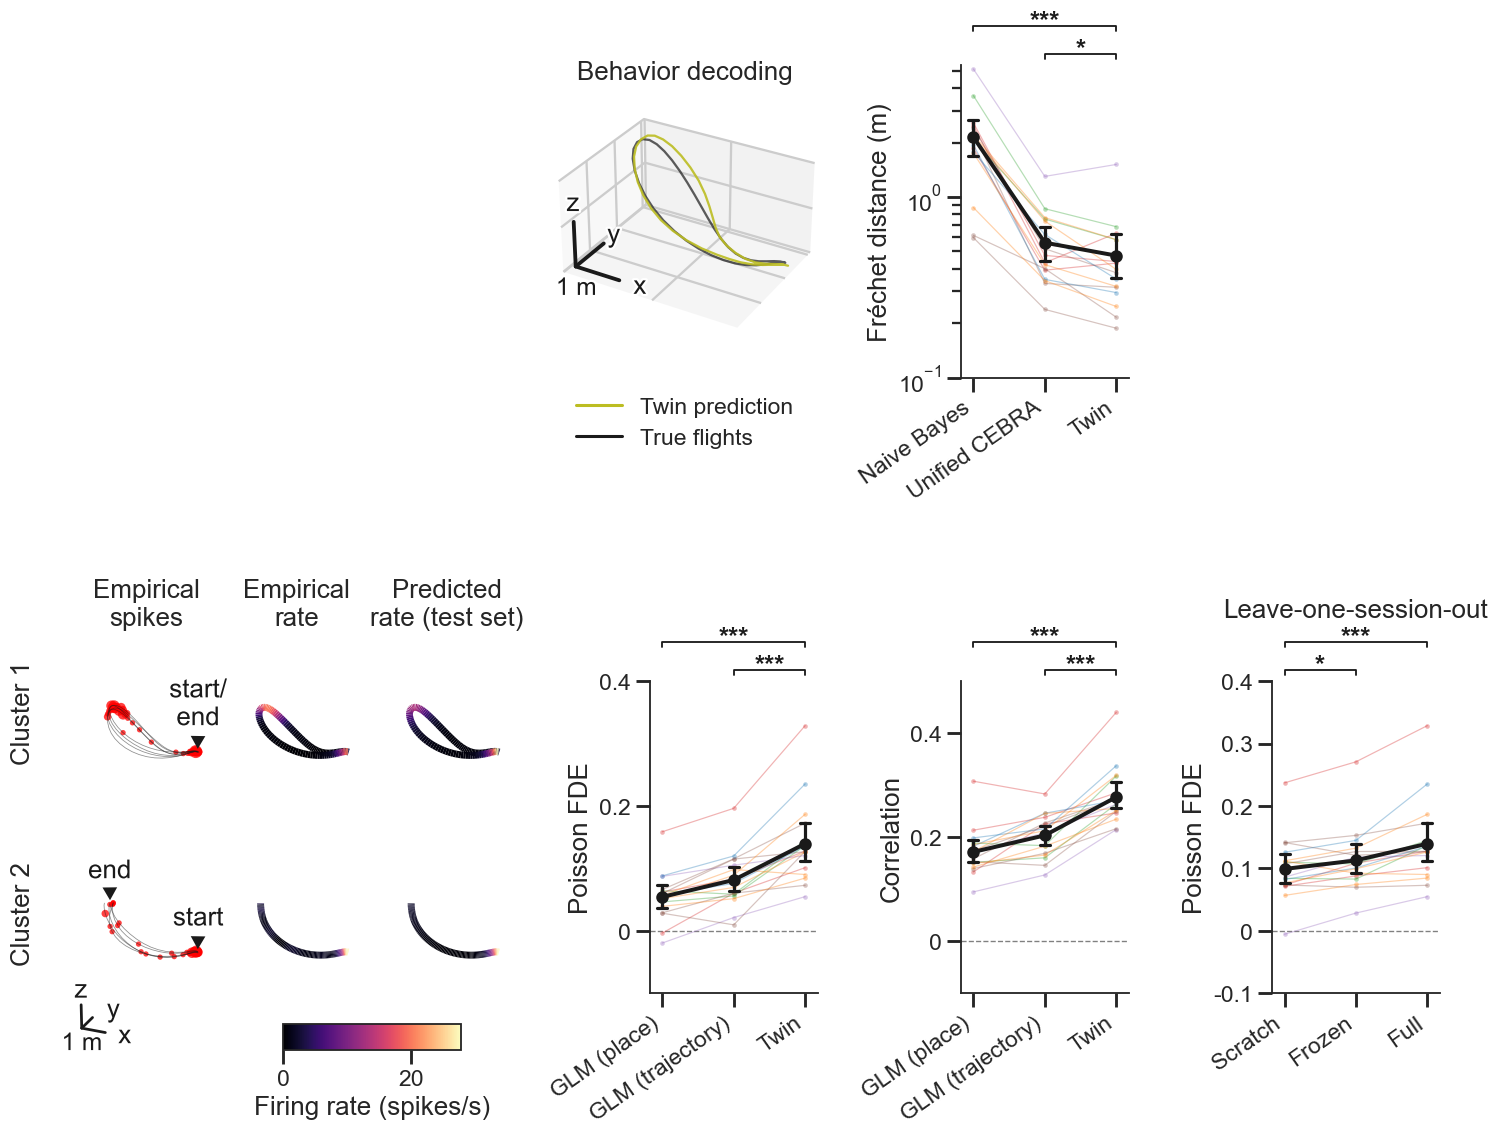


Fig 1e FDE - session-level Wilcoxon vs Twin (session medians):
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.0782 1.526e-05   *** P < 0.001
 glm_traj joint 17      0.05691 3.052e-05   *** P < 0.001

Fig 1f Pearson r - session-level Wilcoxon vs Twin (session medians):
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.1019 1.526e-05   *** P < 0.001
 glm_traj joint 17      0.05515 1.526e-05   *** P < 0.001

Fig 1c Frechet - session-level Wilcoxon vs Twin (session medians):
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17        1.642 1.526e-05   *** P < 0.001
      cebra joint 17      0.09667   0.03479     * P = 0.035

Fig 1c Frechet (per-flight) - pooled unit-level Wilcoxon vs Twin (per-unit stats, no panel):
      model    vs   n  median_diff         p stars         P
naive_bayes joint 278        1.306 4.971e-44   *** P < 0.001
      cebra joint 278       0.0396  0.004758    ** P =

In [15]:
# === Figure 1 (b-i) on a single canvas ===
# a is an external schematic (provided separately). Layout (wide canvas; the
# 3-D maps packed left, decode + encode metrics on the right):
#   top-left gap (schematic a)      | b (decoded 3D) | c(sess) c(flight)
#   d (left | center | right)  (cluster 1, then cluster 2 below) -- dual-field triptych
#   FDE(sess) FDE(neuron)  r(sess) r(neuron) -- one row, centred on the two map rows
# Panels: b = decoding example; c = Fréchet distance; d = dual-field example
#   (left spikes | center empirical rate | right predicted rate); e = Poisson FDE; f = Pearson r.
#   i = leave-one-session-out transfer FDE (appended to the right of f).
# Font sizes are applied per-panel at the end (see _apply_panel_fonts) so every
# individual title / axis label / tick label / legend is the same size, whether
# or not ph.set_pub_style() was re-run this session.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 17, 17, 15, 15

fig1 = plt.figure(figsize=(26, 18))
gs1 = fig1.add_gridspec(3, 8, hspace=0.6, wspace=0.55, width_ratios=[1, 1, 1, 0.3, 1, 1, 1, 1])

# b: example decoded 3-D trajectory (row 1, col 2; cols 0-1 are left as a gap)
ax_b = fig1.add_subplot(gs1[0, 4], projection='3d')
# draw the single example flight chosen above (a cleanly decoded rew→rew loop;
# see the Fig 1b selection cell) so the panel stays legible
_zoom_dec = joint_decode_test[joint_decode_test['session'] == zoom_session]
gfl = _zoom_dec[_zoom_dec['flight_id'] == example_flight].sort_values('t_idx')
ax_b.plot(gfl['x_true'], gfl['y_true'], gfl['z_true'], color='k', lw=1.5, alpha=0.7)
ax_b.plot(gfl['x_pred'], gfl['y_pred'], gfl['z_pred'], color='tab:olive', lw=1.5, alpha=0.9)
# crop x/y to the plotted flight (true + predicted); show only used data
_bxy = np.array([[gfl[f'{_c}_true'].min(), gfl[f'{_c}_true'].max(),
                  gfl[f'{_c}_pred'].min(), gfl[f'{_c}_pred'].max()] for _c in ('x', 'y')])
ax_b.set_xlim(_bxy[0].min(), _bxy[0].min() + 0.8 * (_bxy[0].max() - _bxy[0].min()))   # shorten x at the positive end only
ax_b.set_ylim(_bxy[1].min(), _bxy[1].max())
ax_b.set_zlim(0, 2)
ax_b.set_box_aspect([max(np.ptp(_l), 1e-3) for _l in (ax_b.get_xlim(), ax_b.get_ylim(), ax_b.get_zlim())])  # 1 m equal on x/y/z
nh.add_3d_scalebar(ax_b, corner=(0, 0, 0), fontsize=FS_LABEL, z_nudge=(0.0, 0.0, 0.075), hide_frame=False, label_weight='normal')  # scale bar; keep gridlines, drop tick/axis labels
ax_b.set_title('Behavior decoding')
# legend below the axes
ax_b.legend(handles=[plt.Line2D([], [], color='tab:olive', label=f'{OUR_MODEL} prediction'),
                     plt.Line2D([], [], color='k', label='true flights')],
            loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=1, fontsize=FS_LEG)

# c: decoding accuracy as per-flight 3-D Fréchet distance (row 1, cols 3-4)
ax_c = fig1.add_subplot(gs1[0, 5])   # decoding accuracy: session medians only
_, ptab_c = ph.compare_models_fig(
    decode_frechet_df, 'frechet_3d', present, ref='joint', labels=DECODE_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False,
    star_style='bracket', star_kw={'star_gap': -0.025, 'dagger': True, 'dagger_drop': 0.045}, title_y=1.21, show_titles=False, axes=(ax_c, None))
# log y-axis for the Frechet (decoding-accuracy) panel
_flo, _fhi = ax_c.get_ylim()
ax_c.set_yscale('log')
ax_c.set_ylim(max(_flo, 0.1), _fhi)

# d: dual-field example unit, 3-D maps (rows 2-3, cols 1-3); the three columns are the
# left (spikes), center (empirical rate), right (predicted rate) sub-panels. Assumes 2 clusters.
ax_ex = np.array([[fig1.add_subplot(gs1[r + 1, cc], projection='3d') for cc in range(3)]
                 for r in range(len(pk['clusters']))], dtype=object)
# zoom the maps to the plotted flights (bigger trajectories than the full-arena r_lim)
_fl_plot = [f for f in pk['flights'] if f['cluster'] in pk['clusters']]
_fl_xyz = np.vstack([f['xyz'][:, :3] for f in _fl_plot])
_fl_lo, _fl_hi = _fl_xyz.min(0), _fl_xyz.max(0)
_fl_pad = 0.16 * (_fl_hi - _fl_lo) + 0.05       # small margin so start/end labels fit in-frame
_tight_rlim = [(float(_fl_lo[i] - _fl_pad[i]), float(_fl_hi[i] + _fl_pad[i])) for i in range(3)]
sm_ex = plot_dual_field_cell(pk['flights'], pk['neuron'], pk['clusters'], dt, _tight_rlim,
                            peaks=pk['peaks'], axes3d=ax_ex, col_title_fs=FS_TITLE, row_label_fs=FS_LABEL,
                            row_labels=[f'Cluster {i + 1}' for i in range(len(pk['clusters']))],
                            rate_cmap='magma', startend='none')  # start/end drawn below
for _axm in ax_ex.flat:
    _axm.set_axis_off()        # drop per-panel axes; one shared scale bar below
    _axm.patch.set_alpha(0.0)  # transparent canvas so neighbours do not cover overflow
nh.add_3d_scalebar(ax_ex[-1, 0], corner=(0, 0, 0), fontsize=FS_LABEL, lw=1.8, y_nudge=(0.1, 0.0, 0.15), z_nudge=(0.0, 0.0, 0.3), origin_shift=(0.15, 0.0, -2), alpha=1.0, label_weight='normal')  # single triad for all panel-d maps
ax_ex[0, 0].set_title('Empirical\nspikes', fontsize=FS_TITLE)
ax_ex[0, 1].set_title('Empirical\nrate', fontsize=FS_TITLE)
ax_ex[0, 2].set_title('Predicted\nrate (test set)', fontsize=FS_TITLE)  # wrap the long column title
# thicken the rate-coloured trajectory lines so the colour scale reads (empirical +
# predicted columns only; the spike-panel path/arrows are left untouched)
from mpl_toolkits.mplot3d.art3d import Line3DCollection as _L3DC
for _rr in range(ax_ex.shape[0]):
    for _cc in (1, 2):
        for _col in ax_ex[_rr, _cc].collections:
            if isinstance(_col, _L3DC):
                _col.set_linewidth(3.5); _col.set_alpha(0.9)
# enlarge the 3-D content inside each map panel (zoom>1 counteracts the default 3-D margin)
for _axm in ax_ex.flat:
    _axm.set_box_aspect([_h - _l for _l, _h in _tight_rlim], zoom=1.0)
# --- E/F: replace the many overlapping flights with ONE average trajectory coloured
# by the mean empirical / predicted rate (alpha declutter failed) ---
from mpl_toolkits.mplot3d.art3d import Line3DCollection as _L3DCavg
def _resamp(_a, _n):
    _a = np.asarray(_a, float); _t = np.linspace(0, 1, len(_a)); _tn = np.linspace(0, 1, _n)
    if _a.ndim == 1:
        return np.interp(_tn, _t, _a)
    return np.stack([np.interp(_tn, _t, _a[:, _d]) for _d in range(_a.shape[1])], 1)
_NAVG, _neu, _SM_SIG = 120, pk['neuron'], 4.0
from scipy.ndimage import gaussian_filter1d as _gf1d
def _smooth(_r):
    return _gf1d(_r, _SM_SIG, mode='nearest')
_avg, _allr = {}, []
for _ci, _c in enumerate(pk['clusters']):
    _fls = [f for f in pk['flights'] if f['cluster'] == _c]
    _axyz = np.mean([_resamp(f['xyz'][:, :3], _NAVG) for f in _fls], axis=0)
    _emp = np.mean([_smooth(_resamp(f['obs'][:, _neu] / dt, _NAVG)) for f in _fls], axis=0)
    _prd = np.mean([_smooth(_resamp(f['pred'][:, _neu] / dt, _NAVG)) for f in _fls], axis=0)
    _avg[_ci] = (_axyz, _emp, _prd); _allr += [_emp, _prd]
_norm = plt.Normalize(0.0, max(float(np.nanpercentile(np.concatenate(_allr), 99)), 1e-6))
sm_ex.set_norm(_norm)          # colourbar matches the averaged-rate scale
for _ci, (_axyz, _emp, _prd) in _avg.items():
    for _colc, _rate in ((1, _emp), (2, _prd)):
        _axm2 = ax_ex[_ci, _colc]
        for _oldc in list(_axm2.collections):
            _oldc.remove()
        # draw late->early so the early part of the flight is painted last within
        # the collection (on top), not occluded by the returning trajectory
        _axyz_r, _rate_r = _axyz[::-1], _rate[::-1]
        _pp = _axyz_r.reshape(-1, 1, 3); _sg = np.concatenate([_pp[:-1], _pp[1:]], axis=1)
        _lc = _L3DCavg(_sg, cmap=sm_ex.cmap, norm=_norm)
        _lc.set_array(0.5 * (_rate_r[:-1] + _rate_r[1:])); _lc.set_linewidth(4.5)
        _axm2.add_collection(_lc)
# --- start/end labels: raised, arrow straight down; 'start/end' wrapped for the loop ---
import matplotlib.patheffects as _peSE
from matplotlib.patches import FancyArrowPatch as _FAP
from mpl_toolkits.mplot3d import proj3d as _proj3d
class _Arrow3D(_FAP):
    def __init__(self, _xs, _ys, _zs, *a, **k):
        super().__init__((0, 0), (0, 0), *a, **k); self._v3d = (_xs, _ys, _zs)
    def do_3d_projection(self, renderer=None):
        _x, _y, _z = self._v3d
        _xp, _yp, _zp = _proj3d.proj_transform(_x, _y, _z, self.axes.M)
        self.set_positions((_xp[0], _yp[0]), (_xp[1], _yp[1]))
        return float(np.min(_zp))
def _draw_se(_ax, _starts, _ends):
    _stk = [_peSE.withStroke(linewidth=2.5, foreground='white')]
    _dz = 0.6 * (_tight_rlim[2][1] - _tight_rlim[2][0])
    _cs = np.asarray(_starts, float).mean(0); _ce = np.asarray(_ends, float).mean(0)
    _items = [((_cs + _ce) / 2, 'start/\nend')] if np.linalg.norm(_cs - _ce) < 0.6 \
        else [(_cs, 'start'), (_ce, 'end')]
    for _pt, _lab in _items:
        _top = _pt + np.array([0.0, 0.0, _dz])
        _ar = _Arrow3D([_top[0], _pt[0]], [_top[1], _pt[1]], [_top[2], _pt[2]], color='k',
                       arrowstyle='-|>,head_width=0.4,head_length=0.7', mutation_scale=12,
                       lw=0, zorder=6, clip_on=False)   # stem hidden, just the head
        _ax.add_artist(_ar)
        _ax.text(_top[0], _top[1], _top[2], _lab, color='k', fontsize=FS_LABEL,
                 ha='center', va='bottom', zorder=7,
                 path_effects=_stk, clip_on=False)
for _ci, _c in enumerate(pk['clusters']):
    _fls = [f for f in pk['flights'] if f['cluster'] == _c]
    _draw_se(ax_ex[_ci, 0], [f['xyz'][0, :3] for f in _fls], [f['xyz'][-1, :3] for f in _fls])
# let the start/end labels + arrows overflow their panels instead of clipping
for _rr in range(ax_ex.shape[0]):
    for _ch in ax_ex[_rr, 0].get_children():
        if hasattr(_ch, 'get_text') and _ch.get_text() in ('start', 'end', 'start/end'):
            _ch.set_clip_on(False)
    for _col in ax_ex[_rr, 0].collections:
        _col.set_clip_on(False)
# nudge the "Cluster N" row labels up a bit
for _r in range(ax_ex.shape[0]):
    for _ch in ax_ex[_r, 0].get_children():
        if hasattr(_ch, 'get_text') and _ch.get_text().startswith('Cluster'):
            _lx, _ly = _ch.get_position()
            _ch.set_position((_lx, _ly + 0.12))
# shrink horizontal gaps between the 3 map columns to match the comparison-pair pull:
# pull the outer columns (c spikes, e predicted) toward the fixed centre (d empirical)
_MAP_PULL = 0.055
for _r in range(ax_ex.shape[0]):
    for _cc, _sh in ((0, _MAP_PULL), (2, -_MAP_PULL)):
        _pm = ax_ex[_r, _cc].get_position()
        ax_ex[_r, _cc].set_position([_pm.x0 + _sh, _pm.y0, _pm.width, _pm.height])
# raise the bottom map row (flight cluster 2) to tighten the inter-cluster gap and
# free space for the shared rate colourbar beneath it
_ROW3_UP = 0.18
for _axm2 in ax_ex[1, :]:
    _pm2 = _axm2.get_position()
    _axm2.set_position([_pm2.x0, _pm2.y0 + _ROW3_UP, _pm2.width, _pm2.height])
# horizontal rate colourbar below the second map row, under the right two
# (empirical, predicted) map columns
_p1, _p1b = ax_ex[1, 1].get_position(), ax_ex[1, 2].get_position()
_cbw = (_p1b.x1 - _p1.x0) / 2
_cax = fig1.add_axes([_p1.x0 + _cbw / 2, _p1.y0 - 0.005, _cbw, 0.013])
fig1.colorbar(sm_ex, cax=_cax, orientation='horizontal', label='firing rate (spikes/s)')

# e, f: encoding fit (rows 2-3, cols 4-5) -- e = Poisson FDE, f = Pearson r
ax_e = fig1.add_subplot(gs1[1, 4])
_, ptab_e = ph.compare_models_fig(
    encode_metrics_df, 'fde', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Poisson FDE', unit_name='neuron', clip=(-0.6, 1.0), zero_line=True, sess_ylim=(-0.1, 0.4),
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_e, None))
ax_f = fig1.add_subplot(gs1[1, 6])
_, ptab_f = ph.compare_models_fig(
    encode_metrics_df, 'corr', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Correlation', unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.1, 0.5),
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_f, None))

# shrink the 2-D comparison panels so they match the (margin-padded) 3-D panels and
# their tick labels don't collide with neighbours
def _shrink(ax, fx=0.82, fy=0.86):
    p = ax.get_position()
    ax.set_position([p.x0 + p.width * (1 - fx) / 2, p.y0 + p.height * (1 - fy) / 2,
                     p.width * fx, p.height * fy])
for _ax in (ax_e, ax_f, ax_c):
    _shrink(_ax)

# fine layout nudges: panel b (decode example) a touch right; the first map row
# (flight cluster 1 maps) a touch down
_A_DX, _ROW2_DY = 0.015, 0.012
_pf = ax_b.get_position()
ax_b.set_position([_pf.x0 + _A_DX, _pf.y0, _pf.width, _pf.height])
for _ax in list(ax_ex[0, :]):
    _p = _ax.get_position()
    _ax.set_position([_p.x0, _p.y0 - _ROW2_DY, _p.width, _p.height])
# centre the FDE + Correlation strip vertically across the two map rows
_map_y1 = ax_ex[0, 0].get_position().y1   # top of cluster-1 maps (after its down-nudge)
_map_y0 = ax_ex[1, 0].get_position().y0   # bottom of cluster-2 maps (after its raise)
_strip_cy = (_map_y0 + _map_y1) / 2
for _mx in (ax_e, ax_f):
    _pm = _mx.get_position()
    _mx.set_position([_pm.x0, _strip_cy - _pm.height / 2, _pm.width, _pm.height])
# session-median columns keep the ORIGINAL x-positions so the maps, decode example and
# schematic-a space all stay put; the removed per-neuron / per-flight columns just vanish.
# FDE stays leftmost, Correlation slides in next to it, Frechet-session keeps its row-1 slot.
_R, _MGAP = 0.965, 0.05
_MW = ax_e.get_position().width
_PITCH = _MW + _MGAP
_X0 = _R - _MW - 3 * _PITCH                    # FDE-session column (maps abut here)
for _ax, _xx in ((ax_e, _X0), (ax_f, _X0 + _PITCH), (ax_c, _X0 + _PITCH)):
    _p = _ax.get_position()
    _ax.set_position([_xx, _p.y0, _MW, _p.height])
# pack each example against its quant panels (close the mid-canvas gap), leaving
# only enough room for the quant y-axis labels / panel-b z-axis; empty space is
# pushed to the top-left for the external schematic a
_MAP_GAP, _B_GAP = 0.035, 0.05
_fde_left = _X0                            # maps abut the FDE column (original position)
_fr_left = _X0 + _PITCH                    # panel b abuts the (left-shifted) Frechet column (aligned under Correlation)
# encoding: slide the whole 3-D map block right so it abuts the FDE columns
_map_right = max(ax_ex[_r, 2].get_position().x1 for _r in range(ax_ex.shape[0]))
_dmap = _fde_left - _MAP_GAP - _map_right
for _axm in ax_ex.flat:
    _p = _axm.get_position()
    _axm.set_position([_p.x0 + _dmap, _p.y0, _p.width, _p.height])
_pcb = _cax.get_position()
_cax.set_position([_pcb.x0 + _dmap, _pcb.y0, _pcb.width, _pcb.height])   # colourbar follows the maps
# decoding: slide panel b right so it abuts the Frechet columns
_pb = ax_b.get_position()
_bw, _bh = _pb.width * 1.3, _pb.height * 1.3       # enlarge the decode example
ax_b.set_position([_fr_left - _B_GAP - _bw, _pb.y0 + _pb.height / 2 - _bh / 2, _bw, _bh])

# tighten the vertical gap between the top row (decode example + Frechet) and the
# maps/metrics row below by lowering the whole top row a touch
_TOPROW_DOWN = 0.045
for _tr_ax in (ax_b, ax_c):
    _tp = _tr_ax.get_position()
    _tr_ax.set_position([_tp.x0, _tp.y0 - _TOPROW_DOWN, _tp.width, _tp.height])

# E-F (FDE + Correlation) y-ticks: <=1 decimal place, drop trailing '.0' (1.0->1,
# 0.0->0), and avoid quarter steps (0.25 / 0.75)
from matplotlib.ticker import MaxNLocator as _MaxNLoc, FuncFormatter as _FuncFmt
def _ytick_fmt(_v, _p):
    _s = f'{_v:.1f}'.rstrip('0').rstrip('.')
    return '0' if _s in ('-0', '') else _s
for _mx in (ax_e, ax_f):
    _mx.yaxis.set_major_locator(_MaxNLoc(nbins=4, steps=[1, 2, 5, 10]))
    _mx.yaxis.set_major_formatter(_FuncFmt(_ytick_fmt))

# --- Panel I: joint-model transfer, Poisson FDE session medians (absorbs the former
# ED Fig 4). Leave-one-session-out only, placed to the RIGHT of the Correlation panel
# with the row above left empty. Modes scratch / frozen / full (the main joint model
# already drawn above = the skyline); fine-tune is omitted here. Brackets + 3-tier stars
# = session-level Wilcoxon vs scratch. Regenerate the pkls with
# `python training/train_joint_transfer.py`.
_TJ_ROOT, _TJ_MODES = './out/transfer_joint', ['scratch', 'frozen', 'full']
# 'full' = the main joint model (Fig 1b,e,f) appended as a 3rd box
_full_enc_tj = encode_metrics_df.loc[encode_metrics_df['model'] == 'joint',
                                     ['session', 'bat', 'unit', 'fde']].assign(mode='full')
def _load_tj_f1(_g):
    _p = f'{_TJ_ROOT}/{_g}/results_{_g}_encode.pkl'
    return pd.read_pickle(_p) if os.path.exists(_p) else pd.DataFrame()
_TJ_CV = [('session', 'Leave-one-session-out')]
ptab_tj = []
if all(_load_tj_f1(_g).empty for _g, _ in _TJ_CV):
    print('Fig 1 transfer row: no joint-transfer results on disk — '
          'run `python training/train_joint_transfer.py` first.')
else:
    # Panel I sits to the RIGHT of the Correlation panel (ax_f), aligned to it; the
    # row above is left intentionally empty. No canvas compression / bottom row.
    _tj_axes = {}
    for _gi, (_grp, _gtitle) in enumerate(_TJ_CV):
        _df = pd.concat([_load_tj_f1(_grp), _full_enc_tj], ignore_index=True)
        _pf = ax_f.get_position()                        # Correlation panel
        _axs = fig1.add_axes([_pf.x1 + _MGAP, _pf.y0, _pf.width, _pf.height])
        _, _pt = ph.compare_models_fig(
            _df, 'fde', _TJ_MODES, ref='scratch', model_col='mode', ylabel='Poisson FDE',
            unit_name='neuron', clip=(-1, 1), sess_ylim=(-0.1, 0.4), zero_line=True,
            higher_is_better=True, star_style='bracket', star_kw={'star_gap': -0.025},
            show_titles=False, show_xticklabels=True, show_sess_ylabel=True, axes=(_axs, None))
        _tj_axes[_gi] = _axs
        ptab_tj += [dict(cv=_gtitle, level='session median', **_r) for _r in _pt.to_dict('records')]
        _upt = ph.pooled_ptable(_df, 'fde', _TJ_MODES, 'scratch', ['session', 'unit'],
                                model_col='mode', higher_is_better=True)
        ptab_tj += [dict(cv=_gtitle, level='per neuron', **_r) for _r in _upt.to_dict('records')]
    # CV-scheme header (single line) just above the panel
    fig1.canvas.draw()
    _HDR_OFF = 0.03
    for _gi, (_, _gtitle) in enumerate(_TJ_CV):
        _pa = _tj_axes[_gi].get_position()
        fig1.text((_pa.x0 + _pa.x1) / 2, _pa.y1 + _HDR_OFF, _gtitle,
                  ha='center', va='bottom', fontsize=FS_TITLE)

# Enforce a single consistent font size on every panel individually (titles, x/y/z
# axis labels, tick labels, and legend text), so nothing depends on the global
# rcParams having been refreshed by ph.set_pub_style() this session.
def _apply_panel_fonts(ax):
    ax.title.set_fontsize(FS_TITLE)
    ax.xaxis.label.set_fontsize(FS_LABEL)
    ax.yaxis.label.set_fontsize(FS_LABEL)
    if hasattr(ax, 'zaxis'):
        ax.zaxis.label.set_fontsize(FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    _lg = ax.get_legend()
    if _lg is not None:
        for _t in _lg.get_texts():
            _t.set_fontsize(FS_LEG)
        if _lg.get_title() is not None:
            _lg.get_title().set_fontsize(FS_LEG)
for _ax in fig1.get_axes():
    _apply_panel_fonts(_ax)

# let edge swarm dots overflow their axes instead of being cropped (2-D panels only), and
# nudge the y-axis a hair left so the leftmost swarm doesn't touch it
from matplotlib.collections import PathCollection as _PathColl
for _ua in fig1.get_axes():
    if hasattr(_ua, 'zaxis'):          # skip 3-D map / decode panels
        continue
    _has_swarm = False
    for _uc in _ua.collections:
        if isinstance(_uc, _PathColl):
            _uc.set_clip_on(False)
            _has_swarm = True
    if _has_swarm:
        _xl = _ua.get_xlim()
        _ua.set_xlim(_xl[0] - 0.15, _xl[1])
ph.save_fig(fig1, 'fig1_full'); plt.show()
for _n, _pt in [('1e FDE', ptab_e), ('1f Pearson r', ptab_f), ('1c Frechet', ptab_c)]:
    print(f'\nFig {_n} - session-level Wilcoxon vs {OUR_MODEL} (session medians):'); ph.p_table(_pt.to_dict('records'))
for _n, _df, _v, _o, _mc, _id, _hib in [
        ('1c Frechet (per-flight)', decode_frechet_df, 'frechet_3d', present, 'decoder', ['session', 'flight_id'], False),
        ('1e FDE (per-neuron)', encode_metrics_df, 'fde', ENC_ORDER, 'model', ['session', 'unit'], True),
        ('1f Pearson r (per-neuron)', encode_metrics_df, 'corr', ENC_ORDER, 'model', ['session', 'unit'], True)]:
    print(f'\nFig {_n} - pooled unit-level Wilcoxon vs {OUR_MODEL} (per-unit stats, no panel):')
    ph.p_table(ph.pooled_ptable(_df, _v, _o, 'joint', _id, model_col=_mc, higher_is_better=_hib).to_dict('records'))
if ptab_tj:
    print('\nFig 1 transfer row (Poisson FDE) - Wilcoxon vs scratch:'); ph.p_table(ptab_tj)


**Figure 1 | A transformer-based functional digital Twin outperforms standard approaches on hippocampal data.** (A) Twin model architecture. \textit{B} = batch size = number of flights, \textit{T} = sequence length = number of time bins, \textit{N} = number of neurons per session, \textit{E} = number of environments, \textit{L} = number of transformer layers, \textit{D} = transformer latent dimension, \textit{ELU} = Exponential Linear Unit nonlinearity, \textit{NLL} = negative log likelihood, \textit{$\lambda$} = decoding weight, \textit{MSE} = mean squared error. (B) Representative decoded (olive) versus true (black) 3-D flight trajectory from the Twin decoder. (C) Decoding accuracy as per-flight 3-D discrete Fréchet distance (lower is better) for a `Naïve Bayes' place decoder, `Unified CEBRA' decoder, and the digital Twin model. Here and for all similar plots throughout the paper, thin lines show individual sessions (per-session medians) colored by bat, connected across conditions, and the thick black point-range gives the across-session mean $\pm$ 95\% CI; n = 17 sessions. Wilcoxon vs the Twin: `Naïve Bayes' ($P = 1.53 \times 10^{-5}$), `Unified CEBRA' ($P = 0.0448$). (D) An example unit with spatially separated place fields on two different flight clusters (\textit{rows}), with flight start and end indicated. \textit{Left}, observed spikes (red dots, area $\propto$ binned spike count) on the black flight paths; \textit{center}, mean empirical firing rate map; \textit{right}, the Twin's mean predicted rate map. (E-F) Encoding fit quantified as per-neuron Poisson fraction deviance explained (FDE, E) and Pearson correlation (F) between predicted and observed spike trains; the GLMs fail to capture the structure the Twin recovers. Wilcoxon vs the Twin: (E) `place GLM' ($P = 1.53 \times 10^{-5}$), `trajectory-specific place GLM' ($P = 3.05 \times 10^{-5}$); (F) `place GLM' ($P = 1.53 \times 10^{-5}$), `trajectory-specific place GLM' ($P = 1.53 \times 10^{-5}$). (G) Schematic of transfer analysis. Model architecture is identical to (A). All model weights were frozen (snowflake icons) except for the session-specific neural readout weights, which were trained (fire icons). (H) For each held-out session, a new base model was trained and then frozen as in (G) before fine-tuning the readouts on the held-out session. (I) Poisson FDE for the Twin, either retrained from scratch on a single session, transferred to the held-out session with readout fine-tuning only (G-H), or evaluated on the full 17-session model (E). Wilcoxon vs from-scratch: `frozen' $P = 0.0174$ and `full' $P = 2.90 \times 10^{-4}$. Here and for all figures, $^{*}P < 0.05$, $^{**}P < 0.01$, $^{***}P < 0.001$; n.s. comparisons are generally unmarked, although $^\dagger P < 0.10$ is sometimes indicated. N = 17 sessions from 6 bats; decoding and encoding performance is measured on a held-out test set not used for fitting or hyperparameter selection. Unless otherwise indicated, data is colored by bat consistently across figures. See also Figures \ref{fig:S1}-\ref{fig:S3}.

---
## Extended Data Figure 1 — full model ladders

**a–c** External schematics (flight room; masked-transformer input tensors; encode/decode/infill masking strategies), drawn separately. **d** Per-flight decoding accuracy (3-D Fréchet distance) for the full decoder ladder from `decode-position-comparison.ipynb`. **e–h** Per-neuron encoding fit for every model in `model_comparison.ipynb`: Poisson FDE and Pearson r for the behaviour-only encoders (**e**, **f**) and for the neural-data GLMs that additionally condition on spike history / coupling / future spiking (**g**, **h**). Stars: session-level Wilcoxon vs the joint (Twin) model. (`GLM + lags + kin' is omitted — it requires the kinematics-augmented behavior, incompatible with the position-only single load; re-enable with a separate kinematics loader if needed.)

In [16]:
# === ED Fig 1d/e: all encoding models (per-neuron FDE + corr) ===
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (make_model_config, make_model_name,
                                              DEFAULT_LR, DEFAULT_WEIGHT_DECAY)
from digitalbat.models.glm import make_symmetric_raised_cosine_basis

# Temporal-filter bases (match model_comparison.ipynb).
HIST_N_BASIS, COUP_N_BASIS, ACAUSAL_N_BASIS = 6, 4, 6
hist_basis, _, _ = make_log_raised_cosine_basis(HIST_N_BASIS, N_LAGS, bin_width)
coup_basis, _, _ = make_log_raised_cosine_basis(COUP_N_BASIS, N_LAGS, bin_width, include_zero_lag=True)
acausal_basis, _, _ = make_symmetric_raised_cosine_basis(ACAUSAL_N_BASIS, N_LAGS, bin_width)
glm_lags = np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()
DATA_TAG, GLM_TAG = '_acc50_preln_17_sess', '_acc50_zbasis17'


def build_glm(name, cond):
    ck = cluster_keys_by_session if cond == 'joint' else None
    res = PLACE_RES if cond == 'position' else TRAJ_RES  # searched per-axis (fewer z)
    if name == 'GLM' and cond == 'position':
        return GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=res, output_dim_dict=unit_num_dict)
    if name == 'GLM + lags' and cond == 'position':
        return GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=res, output_dim_dict=unit_num_dict, lag_seconds=glm_lags)
    if name == 'GLM + lags':   # cond == 'joint' -> per-cluster lagged place GLM (trajectory)
        return GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base, n_bases_per_axis=res,
                           lag_seconds=glm_lags, cluster_keys=ck)
    return GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base, n_bases_per_axis=res,
                       hist_basis=hist_basis if 'hist' in name else None,
                       coup_basis=coup_basis if 'coup' in name else None,
                       acausal_basis=acausal_basis if 'acausal' in name else None,
                       n_lags=N_LAGS, cluster_keys=ck)


def glm_ckpt(name, cond):
    tag = name.lower().replace(' + ', '_').replace(' ', '_')
    return f'./out/bat_glm/bat_{tag}_{cond}_seed_{seed}_optuna{GLM_TAG}.pth'


# Full-arch transformer config from the pre-LN Optuna search.
import json as _json
_ep = f'./out/bat_former/former_best_params{DATA_TAG}_seed_{seed}.json'
_arch = ({k: _json.load(open(_ep))[k] for k in ('latent_dim', 'ff_dim', 'num_layers', 'dropout_prob')
          if k in _json.load(open(_ep))} if os.path.exists(_ep) else {})
base_cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict, **_arch)


def build_former(kind):
    if kind == 'transformer':
        return Bat_Transformer(**base_cfg)
    if kind == 'mlp':
        return Bat_Transformer(**{**base_cfg, 'use_attention': False})
    return Bat_Transformer(**{**base_cfg, 'latent_dim': 32, 'ff_dim': 32, 'num_layers': 1})


@torch.no_grad()
def eval_former_metrics(model):
    model = model.to(device).eval()
    rows = []
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


# Registry: (display label, kind, spec). Joint GLMs get a '(joint)' suffix.
# GLMs are grouped by INPUT: the behaviour-alone GLMs (place / trajectory-cluster
# place fields, +/- lags -- no neural input) come first, then the neural-data GLMs
# (Pillow-style spike history / coupling / acausal self-filters). A blank spacer
# (injected below) separates the two groups in ED Fig 1d/e.
ED1_MODELS = [
    # --- behaviour-alone GLMs (position / trajectory-cluster place fields, +/- lags) ---
    ('GLM (place)',                    'glm',    ('GLM', 'position')),
    ('GLM + lags (place)',             'glm',    ('GLM + lags', 'position')),
    ('GLM (trajectory)',               'glm',    ('GLM', 'joint')),
    ('GLM + lags (trajectory)',        'glm',    ('GLM + lags', 'joint')),
    # --- neural-data GLMs (spike history / coupling / acausal self-filter) ---
    ('GLM + hist (place)',             'glm',    ('GLM + hist', 'position')),
    ('GLM + coup (place)',             'glm',    ('GLM + coup', 'position')),
    ('GLM + hist + coup (place)',      'glm',    ('GLM + hist + coup', 'position')),
    ('GLM + acausal (place)',          'glm',    ('GLM + acausal', 'position')),
    ('GLM + hist (trajectory)',        'glm',    ('GLM + hist', 'joint')),
    ('GLM + coup (trajectory)',        'glm',    ('GLM + coup', 'joint')),
    ('GLM + hist + coup (trajectory)', 'glm',    ('GLM + hist + coup', 'joint')),
    ('GLM + acausal (trajectory)',     'glm',    ('GLM + acausal', 'joint')),
    ('MLP only',                       'former', 'mlp'),
    (OUR_MODEL,                       'joint',  None),
]
ED1_ORDER = [m[0] for m in ED1_MODELS]
BEHAV_ONLY_GLMS = ['GLM (place)', 'GLM + lags (place)',
                   'GLM (trajectory)', 'GLM + lags (trajectory)']

_pieces = []
for label, kind, spec in ED1_MODELS:
    try:
        if kind == 'glm':
            name, cond = spec
            gm = ensure_glm(glm_ckpt(name, cond), lambda: build_glm(name, cond),
                            cond=cond, search_alpha=('coup' in name))
            df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
        elif kind == 'former':
            ck = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                                 out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                                          'small': './out/bat_former_small'}[spec], suffix=DATA_TAG)
            fm = ensure_former(ck, lambda: build_former(spec))
            df = eval_former_metrics(fm)
        else:
            df = encode_eval_records(bat_former, dataloaders, device)
        _pieces.append(df.assign(model=label))
        print(f'  ok: {label}')
    except Exception as exc:
        print(f'  [skip {label}] {type(exc).__name__}: {exc}')

ed1_encode_df = pd.concat(_pieces, ignore_index=True)
ed1_present = [m for m in ED1_ORDER if m in set(ed1_encode_df['model'])]
ed1_encode_df['model'] = pd.Categorical(ed1_encode_df['model'], ed1_present, ordered=True)
print('ED1 encode models:', ed1_present)

  ok: GLM (place)
GLM: 11 lags x 108 spatial = 1188 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok: GLM + lags (place)
  ok: GLM (trajectory)
  ok: GLM + lags (trajectory)
  ok: GLM + hist (place)
  ok: GLM + coup (place)
  ok: GLM + hist + coup (place)
  ok: GLM + acausal (place)
  ok: GLM + hist (trajectory)
  ok: GLM + coup (trajectory)
  ok: GLM + hist + coup (trajectory)
  ok: GLM + acausal (trajectory)
  ok: MLP only
  ok: Twin
ED1 encode models: ['GLM (place)', 'GLM + lags (place)', 'GLM (trajectory)', 'GLM + lags (trajectory)', 'GLM + hist (place)', 'GLM + coup (place)', 'GLM + hist + coup (place)', 'GLM + acausal (place)', 'GLM + hist (trajectory)', 'GLM + coup (trajectory)', 'GLM + hist + coup (trajectory)', 'GLM + acausal (trajectory)', 'MLP only', 'Twin']


In [17]:
# === Tampuu et al. (2019) LSTM-RNN decoder: Optuna search + train (ED Fig 1) ===
# Reference implementation: github.com/NeuroCSUT/RatGPS (ratlstm.py / ratdata.py).
# Their decoder is a many-to-one LSTM (2x512 units, dropout 0.5, linear head,
# MSE loss, RMSprop) fed a sequence of spike-count vectors and asked to predict
# the position at the last timestep. We port it to the multi-session bat setting
# as the ED Fig 1 'LSTM-RNN' rung: a per-session linear readin (neurons ->
# hidden -- the minimal change needed to share one recurrent core across
# sessions with different neuron counts) feeds a UNIDIRECTIONAL LSTM (causal, as
# in Tampuu, who explicitly reject bidirectional), and a shared linear head maps
# each timestep's hidden state to z-scored 3D position. Because the loss/eval are
# masked over every valid timestep of a flight (rather than one per sequence),
# the causal LSTM is effectively "many-to-one at every timestep". Training reuses
# the package `bat_decoder_trainer` (round-robin across sessions, masked loss).
# Hyperparameters are Optuna-tuned (TPE, N_TRIALS=20) to minimise mean 3-D error
# in metres on the validation flights. Run-once & non-destructive: an existing
# study/checkpoint is loaded; raise LSTM_N_TRIALS to add trials.
from digitalbat.models.decoder import bat_decoder_trainer

LSTM_OUT_DIR = './out/lstm_rnn'
os.makedirs(LSTM_OUT_DIR, exist_ok=True)
LSTM_STUDY_PATH = f'{LSTM_OUT_DIR}/lstm_rnn_optuna_seed{seed}.pkl'
LSTM_CKPT = f'{LSTM_OUT_DIR}/lstm_rnn_decoder_seed{seed}.pth'
LSTM_N_TRIALS, LSTM_MAX_EPOCHS, LSTM_PATIENCE = 20, 1000, 30
# Tampuu et al.'s published config, mapped into our search space (their weight
# decay 0 -> the log-range floor; readin_dropout is our multi-session addition).
# Enqueued as the FIRST trial so the paper's exact architecture is always
# evaluated -- a faithful baseline alongside the tuned best.
LSTM_TAMPUU_DEFAULT = dict(hidden_size=512, num_layers=2, dropout_prob=0.5,
                          readin_dropout=0.1, input_transform='identity',
                          loss_name='mse', lr=1e-3, weight_decay=1e-5)


class LSTMDecoder(nn.Module):
    """Tampuu et al. (2019) style RNN decoder: spikes -> z-scored 3D position.

    Per-session ``nn.Linear(K_session, hidden_size)`` readin (analogue of the
    transformer decoder's readins) feeds a unidirectional multi-layer LSTM; a
    shared linear head maps every timestep's hidden state to position. The
    ``forward`` signature mirrors ``Bat_Transformer_Decoder`` (extra attention
    kwargs are accepted and ignored) so it is a drop-in for ``bat_decoder_trainer``.
    """

    def __init__(self, input_dim_dict, output_dim=3, hidden_size=256, num_layers=2,
                 dropout_prob=0.5, readin_dropout=0.1, input_transform='identity'):
        super().__init__()
        if input_transform not in ('identity', 'sqrt'):
            raise ValueError(f"input_transform must be 'identity' or 'sqrt', got {input_transform!r}")
        self.input_transform = input_transform
        self.readins = nn.ModuleDict({
            s: nn.Linear(k, hidden_size) for s, k in input_dim_dict.items()})
        self.readin_dropout = nn.Dropout(readin_dropout)
        self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers=num_layers,
                            dropout=(dropout_prob if num_layers > 1 else 0.0),
                            batch_first=True)
        self.head = nn.Linear(hidden_size, output_dim)

    def forward(self, session_name, spikes, mask, **kwargs):
        """spikes: (B, T, K_session). mask: (B, T) float, 1.0 valid. -> (B, T, 3)."""
        if self.input_transform == 'sqrt':
            spikes = torch.sqrt(torch.clamp(spikes, min=0.0))
        x = self.readin_dropout(self.readins[session_name](spikes))
        x = x * mask.to(x.dtype).unsqueeze(-1)   # zero padded (tail) steps
        x, _ = self.lstm(x)
        return self.head(x)


_LSTM_ARCH_KEYS = ('hidden_size', 'num_layers', 'dropout_prob', 'readin_dropout', 'input_transform')


def _build_lstm(hp):
    return LSTMDecoder(unit_num_dict, output_dim=3,
                       **{k: hp[k] for k in _LSTM_ARCH_KEYS if k in hp})


def _lstm_loss(hp):
    return nn.MSELoss() if hp.get('loss_name', 'huber') == 'mse' else nn.SmoothL1Loss()


def _lstm_val_err_m(model):
    """Mean 3-D decoding error (metres) over the validation flights, un-z-scored
    per session (comparable across sessions, unlike the pooled z-scored error the
    trainer uses for early stopping). Difference in dim d scales by that dim's std."""
    model.eval(); errs = []
    with torch.no_grad():
        for sn, sd in dataloaders['valid'].items():
            bs = np.asarray(meta_info_dict['behavior_std'][sn]).squeeze()[:3]
            for batch in sd:
                m = batch.mask.to(device)
                yp = model(sn, batch.spike.to(device), m)[m == 1.0].cpu().numpy()
                yt = batch.behavior[:, :, :3].to(device)[m == 1.0].cpu().numpy()
                errs.append(np.sqrt((((yt - yp) * bs[None]) ** 2).sum(1)))
    return float(np.concatenate(errs).mean())


def _lstm_train(hp, save_path=None):
    set_random_state(seed)
    model = _build_lstm(hp).to(device)
    bat_decoder_trainer(
        model=model, dataloaders=dataloaders, device=device, pos_dims=3,
        n_epochs=LSTM_MAX_EPOCHS, lr=hp['lr'], weight_decay=hp['weight_decay'],
        loss_fn=_lstm_loss(hp), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
        valid_stat='median', early_stopping_patience=LSTM_PATIENCE,
        save_model=save_path is not None, model_name=save_path or 'best_lstm_weights.pth')
    return model


def _lstm_objective(trial):
    hp = dict(
        hidden_size=trial.suggest_categorical('hidden_size', [128, 256, 512]),
        num_layers=trial.suggest_categorical('num_layers', [1, 2, 3]),
        dropout_prob=trial.suggest_float('dropout_prob', 0.0, 0.5),
        readin_dropout=trial.suggest_float('readin_dropout', 0.0, 0.3),
        input_transform=trial.suggest_categorical('input_transform', ['identity', 'sqrt']),
        loss_name=trial.suggest_categorical('loss_name', ['mse', 'huber']),
        lr=trial.suggest_float('lr', 1e-4, 3e-3, log=True),
        weight_decay=trial.suggest_float('weight_decay', 1e-5, 1e-1, log=True))
    return _lstm_val_err_m(_lstm_train(hp))


optuna.logging.set_verbosity(optuna.logging.WARNING)
if os.path.exists(LSTM_STUDY_PATH):
    lstm_study = pickle.load(open(LSTM_STUDY_PATH, 'rb'))
    print(f'loaded cached LSTM-RNN study ({len(lstm_study.trials)} trials)')
else:
    lstm_study = optuna.create_study(direction='minimize',
                                     sampler=optuna.samplers.TPESampler(seed=seed))
    lstm_study.enqueue_trial(LSTM_TAMPUU_DEFAULT)  # paper's config runs first

_lstm_done = sum(t.value is not None for t in lstm_study.trials)
if _lstm_done < LSTM_N_TRIALS:
    print(f'running {LSTM_N_TRIALS - _lstm_done} more LSTM-RNN trials '
          f'@ up to {LSTM_MAX_EPOCHS} epochs (patience {LSTM_PATIENCE})...', flush=True)
    lstm_study.optimize(_lstm_objective, n_trials=LSTM_N_TRIALS - _lstm_done,
                        callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(LSTM_STUDY_PATH), exist_ok=True)
    pickle.dump(lstm_study, open(LSTM_STUDY_PATH, 'wb'))
    print('saved', LSTM_STUDY_PATH)
else:
    print(f'already >= {LSTM_N_TRIALS} completed trials; not retuning '
          f'(raise LSTM_N_TRIALS to extend).')

LSTM_BEST_HP = dict(lstm_study.best_params)
print('\nBest LSTM-RNN mean 3-D error: %.3f m' % lstm_study.best_value)
for _k, _v in LSTM_BEST_HP.items():
    print(f'  {_k}: {_v}')

# Train (once) the final multi-session model at the best hyperparameters and cache
# its weights; the ED Fig 1 ladder's _compute_lstm_rnn() loads these for inference.
if not os.path.exists(LSTM_CKPT):
    print(f'[train LSTM-RNN] {os.path.basename(LSTM_CKPT)}', flush=True)
    _lstm_train(LSTM_BEST_HP, save_path=LSTM_CKPT)
    print('saved', LSTM_CKPT)
else:
    print(f'loaded cached LSTM-RNN checkpoint {os.path.basename(LSTM_CKPT)} '
          f'(delete to retrain after changing best params).')


loaded cached LSTM-RNN study (20 trials)
already >= 20 completed trials; not retuning (raise LSTM_N_TRIALS to extend).

Best LSTM-RNN mean 3-D error: 0.520 m
  hidden_size: 256
  num_layers: 2
  dropout_prob: 0.2486802489214906
  readin_dropout: 0.2040839264573858
  input_transform: sqrt
  loss_name: mse
  lr: 0.0026196864929531713
  weight_decay: 0.010759383459438353
loaded cached LSTM-RNN checkpoint lstm_rnn_decoder_seed1.pth (delete to retrain after changing best params).


In [18]:
# === Multi-session CEBRA hyperparameter search (Optuna; ED Fig 1 only) ===
# Documents/regenerates the tuning of the multi-session CEBRA decoder (the ED Fig 1
# 'CEBRA (multi)' rung), which is SEPARATE from the unified CEBRA above. 6-param TPE
# search at reduced iterations, minimising mean 3-D kNN-decoding error; the best
# trial is pickled to the exact path that the ladder's _compute_cebra_multi()
# auto-loads. Run-once & non-destructive: an existing study is loaded (never
# overwritten); raise MS_N_TRIALS above the completed-trial count to add more.
try:
    import optuna
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    from sklearn.neighbors import KNeighborsRegressor
    _MS_OK = True
except Exception as _exc:
    _MS_OK = False
    print(f'[skip multi-session CEBRA search] {type(_exc).__name__}: {_exc}')

if _MS_OK:
    MS_TUNE_ITER, MS_KNN_N, MS_N_TRIALS = 2000, 36, 20  # raise MS_N_TRIALS to extend
    MS_STUDY_PATH = f'./out/cebra/cebra_optuna_cebra_pos_seed{seed}_it{MS_TUNE_ITER}_6p.pkl'

    def _ms_flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append((spike[b, sel].astype(np.float32),
                            (pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32)))
        return out

    def _ms_embed(model, fl, sid):
        req = len(model.offset_); out = []
        for X, y in fl:
            Z = X if len(X) >= req else np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(Z, session_id=sid)[:len(X)], y))
        return out

    def _ms_score(hp):
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MS_TUNE_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **hp)
        model.fit(_MS_XS, _MS_YS)
        errs = []
        for sid, s in enumerate(session_names):
            etr, eev = _ms_embed(model, _MS_TR[s], sid), _ms_embed(model, _MS_VA[s], sid)
            Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([y for _, y in etr])
            knn = KNeighborsRegressor(n_neighbors=MS_KNN_N, metric='cosine').fit(Etr, Ytr)
            for emb, y in eev:
                errs.append(np.sqrt(((y - np.asarray(knn.predict(emb))) ** 2).sum(1)))
        return float(np.concatenate(errs).mean())

    def _ms_objective(trial):
        hp = dict(
            num_hidden_units=trial.suggest_categorical('num_hidden_units', [32, 64, 128]),
            output_dimension=trial.suggest_categorical('output_dimension', [3, 8, 32, 64]),
            time_offsets=trial.suggest_categorical('time_offsets', [1, 5, 10, 20]),
            model_architecture=trial.suggest_categorical('model_architecture',
                                                         ['offset5-model', 'offset10-model', 'offset36-model']),
            temperature=trial.suggest_float('temperature', 0.1, 1.0, log=True),
            learning_rate=trial.suggest_float('learning_rate', 1e-4, 1e-3, log=True))
        try:
            return _ms_score(hp)
        except Exception as exc:
            print(f'  [prune] {type(exc).__name__}: {exc}')
            raise optuna.TrialPruned()

    def _ms_progress(study, trial):
        try:
            best = f'{study.best_value:.3f} m'
        except ValueError:
            best = 'n/a'
        err = f'{trial.value:.3f} m' if trial.value is not None else trial.state.name
        print(f'[ms-trial {trial.number + 1}] err={err} | best={best} | '
              + ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                          for k, v in trial.params.items()), flush=True)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    if os.path.exists(MS_STUDY_PATH):
        ms_study = pickle.load(open(MS_STUDY_PATH, 'rb'))
        print(f'loaded cached multi-session CEBRA study ({len(ms_study.trials)} trials)')
    else:
        ms_study = optuna.create_study(direction='minimize',
                                       sampler=optuna.samplers.TPESampler(seed=seed))

    _ms_done = sum(t.value is not None for t in ms_study.trials)
    if _ms_done < MS_N_TRIALS:
        # Only touch the data / GPU when trials actually need to run.
        _MS_TR = {s: _ms_flights(s, 'train') for s in session_names}
        _MS_VA = {s: _ms_flights(s, 'valid') for s in session_names}   # HP selection on validation
        _MS_XS = [np.vstack([X for X, _ in _MS_TR[s]]) for s in session_names]
        _MS_YS = [np.vstack([y for _, y in _MS_TR[s]]) for s in session_names]
        set_random_state(seed)
        print(f'running {MS_N_TRIALS - _ms_done} more multi-session CEBRA trials '
              f'@ {MS_TUNE_ITER} iters...', flush=True)
        ms_study.optimize(_ms_objective, n_trials=MS_N_TRIALS - _ms_done, callbacks=[_ms_progress])
        os.makedirs(os.path.dirname(MS_STUDY_PATH), exist_ok=True)
        pickle.dump(ms_study, open(MS_STUDY_PATH, 'wb'))
        print('saved', MS_STUDY_PATH)
    else:
        print(f'already >= {MS_N_TRIALS} completed trials; not retuning '
              f'(raise MS_N_TRIALS to extend).')

    print('\nBest multi-session CEBRA validation mean 3-D error: %.3f m' % ms_study.best_value)
    for _k, _v in ms_study.best_params.items():
        print(f'  {_k}: {_v}')
    print(f'ED Fig 1 loads these via _compute_cebra_multi(); if the best params change, '
          f'clear ./out/ed1_decoders/cebra_multi_seed_{seed}.pkl to rebuild that rung.')

loaded cached multi-session CEBRA study (20 trials)
already >= 20 completed trials; not retuning (raise MS_N_TRIALS to extend).

Best multi-session CEBRA validation mean 3-D error: 0.536 m
  num_hidden_units: 128
  output_dimension: 8
  time_offsets: 1
  model_architecture: offset10-model
  temperature: 0.19429344881452762
  learning_rate: 0.0009707382377948659
ED Fig 1 loads these via _compute_cebra_multi(); if the best params change, clear ./out/ed1_decoders/cebra_multi_seed_1.pkl to rebuild that rung.


In [19]:
# === ED Fig 1c: decoder ladder (9 decoders) ===
# Ladder vs Twin, in the order requested for ED Fig 1c:
#   NB (place), NB (place)+continuity, NB (trajectory), NB (trajectory)+continuity,
#   GLM + coup (place), GLM + hist + coup (place), CEBRA (multi), Unified CEBRA,
#   Twin.
# The bespoke decoders (trajectory-cluster NB, GLM-inversion MAP, multi-session
# CEBRA) are ported from decode-position-comparison.ipynb (real-data path, 3D
# only). Each heavy fit runs ONCE, is pickled under ./out/ed1_decoders/, and is
# loaded on re-run (same run-once/save/load pattern as the GLM / NB / CEBRA
# checkpoints elsewhere in this notebook).
import copy as _copy
from digitalbat.models.decoder import (NaiveBayes_Continuity_Decoder, GLM_MAP_Decoder)
from digitalbat.models.glm import GLM_Coupled
from digitalbat.decoding import cost_pipeline as _cp

ED1_DEC_DIR = './out/ed1_decoders'
os.makedirs(ED1_DEC_DIR, exist_ok=True)


def _cache_records(path, compute):
    """Run ``compute() -> DataFrame`` once, pickle it, and load on later runs."""
    if os.path.exists(path):
        return pd.read_pickle(path)
    df = compute()
    df.to_pickle(path)
    return df


def make_nb_continuity(ndim, r_lim, c_speed, nb_hp):
    n_bins = ((nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z']) if ndim == 3
              else (nb_hp['n_bins_x'], nb_hp['n_bins_y']))
    return NaiveBayes_Continuity_Decoder(
        c_speed=c_speed, sigma_min=0.02, sigma_max=5.0, n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)], sigma=nb_hp['sigma'],
        dt=bin_width, min_occupancy=nb_hp['min_occupancy'],
        use_uniform_prior=nb_hp['use_uniform_prior'])


# Continuity speed factor (shared by NB+continuity and the GLM-inversion warm start).
with open(f'./out/nb_decoder/nb_cont_decoder_3d_seed_{seed}_optuna.pkl', 'rb') as _fh:
    C_SPEED_3D = pickle.load(_fh).best_params['c_speed']


def _records_3d(arr, pred3, session, bat):
    """Per-timestep decode-schema records (x/y/z true+pred, err_3d)."""
    te3 = np.column_stack([arr['pos_x'], arr['pos_y'], arr['pos_z']])
    out = []
    for i in np.flatnonzero(~np.isnan(pred3[:, 0])):
        out.append(dict(bat=bat, session=session, flight_id=int(arr['flight_id'][i]),
                        t_idx=int(arr['t_idx'][i]),
                        x_true=float(te3[i, 0]), y_true=float(te3[i, 1]), z_true=float(te3[i, 2]),
                        x_pred=float(pred3[i, 0]), y_pred=float(pred3[i, 1]), z_pred=float(pred3[i, 2]),
                        err_3d=float(np.sqrt(((te3[i] - pred3[i]) ** 2).sum()))))
    return out


def _compute_nb_cont():
    """NB (place) + continuity, 3D — same c_speed / nb_best as elsewhere."""
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        nbc = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
            tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
        pred3, _ = nbc.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


def _gather_with_cluster(loader, bm, bs):
    """gather_session_arrays + per-timestep train-only ``flight_type_index``."""
    spk, beh, msk, fpi, fti = [], [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool))
        fpi.append(batch.flight_path_index.numpy()); fti.append(batch.flight_type_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi); fti = np.concatenate(fti)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T = msk.shape
    fpi_t = np.broadcast_to(fpi[:, None], (B, T)); fti_t = np.broadcast_to(fti[:, None], (B, T))
    tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpi_t[msk].astype(int),
                flight_type=fti_t[msk].astype(int), t_idx=tix[msk].astype(int))


# ---------------------------------------------------------------------------
# (1) trajectory-cluster NB (naive_bayes_cluster) + continuity variant, 3D.
#     Per flight-cluster rate maps, routed by flight_type at decode time.
# ---------------------------------------------------------------------------
MIN_CLUSTER_FLIGHTS = 3


def _major_clusters(arr):
    seen, counts = set(), {}
    for fid, c in zip(arr['flight_id'], arr['flight_type']):
        if fid in seen:
            continue
        seen.add(fid); counts[int(c)] = counts.get(int(c), 0) + 1
    return {c for c, n in counts.items() if n >= MIN_CLUSTER_FLIGHTS}


def _subset(arr, m):
    return {k: (v[m] if isinstance(v, np.ndarray) else v) for k, v in arr.items()}


def _fit_per_cluster(train, r_lim, continuity):
    major = _major_clusters(train)
    preds = {}
    for c in list(major) + ['other']:
        m = (~np.isin(train['flight_type'], list(major)) if c == 'other'
             else train['flight_type'] == c)
        if m.sum() < 50:
            continue
        sub = _subset(train, m)
        pos3 = np.column_stack([sub['pos_x'], sub['pos_y'], sub['pos_z']])
        try:
            if continuity:
                preds[c] = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                    sub['spikes'], pos3, flight_id=sub['flight_id'], t_idx=sub['t_idx'], dt=bin_width)
            else:
                preds[c] = make_nb(3, r_lim, nb_best[3]).fit(sub['spikes'], pos3)
        except Exception:
            continue
    return preds


def _route_predict(arr, preds, continuity):
    if not preds:
        return None
    pred = np.full((arr['spikes'].shape[0], 3), np.nan)
    for c in np.unique(arr['flight_type']):
        m = arr['flight_type'] == c
        nb_c = preds.get(int(c)) or preds.get('other')
        if nb_c is None:
            continue
        if continuity:
            p, _ = nb_c.predict(arr['spikes'][m], flight_id=arr['flight_id'][m], t_idx=arr['t_idx'][m])
        else:
            p, _ = nb_c.predict(arr['spikes'][m])
        pred[m] = p
    return pred


def _compute_cluster_nb(continuity):
    def _fn():
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = _gather_with_cluster(dataloaders['train'][sn], bm, bs)
            te = _gather_with_cluster(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            preds = _fit_per_cluster(tr, r_lim, continuity)
            pred3 = _route_predict(te, preds, continuity)
            if pred3 is not None:
                recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (2) GLM-inversion MAP decoders (glm_map = GLM+hist+coup, glm_map_coup = coup
#     only), position conditioning, 3D. Invert the fixed real-trained encoders
#     with an NB+continuity warm start (same c_speed as nb_continuity).
# ---------------------------------------------------------------------------
def _load_glm_encoder(ckpt, with_hist):
    kw = dict(output_dim_dict=unit_num_dict, **_glm_base, n_bases_per_axis=PLACE_RES,
              coup_basis=coup_basis, n_lags=N_LAGS)
    if with_hist:
        kw['hist_basis'] = hist_basis
    glm = GLM_Coupled(**kw)
    miss, _ = glm.load_state_dict(torch.load(ckpt, map_location=device), strict=False)
    assert not miss, f'{ckpt} missing required keys: {miss[:5]}'
    return glm.to(device).eval()


def _compute_glm_map(ckpt, with_hist):
    def _fn():
        enc = _load_glm_encoder(ckpt, with_hist)
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
            te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
            warm_nb = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            dec = GLM_MAP_Decoder(enc, sn, bm, bs, device=device).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            warm, _ = warm_nb.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
            pred3, _ = dec.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'],
                                   warm_start=warm)
            recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (3) multi-session CEBRA (position-informed, kNN read-out). Reuses the cached
#     Optuna-tuned multi-session checkpoint (never retrained here).
# ---------------------------------------------------------------------------
def _compute_cebra_multi():
    import hashlib
    from sklearn.neighbors import KNeighborsRegressor
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    OUT_DIR, MAX_ITER, KNN_N = './out/cebra', 6000, 36
    HP = dict(model_architecture='offset10-model', learning_rate=3e-4, temperature=1.0,
              time_offsets=10, output_dimension=3, num_hidden_units=32)
    study_path = f'{OUT_DIR}/cebra_optuna_cebra_pos_seed{seed}_it2000_6p.pkl'
    if os.path.exists(study_path):
        HP.update(pickle.load(open(study_path, 'rb')).best_params)
    a = HP['model_architecture'].replace('-model', '')
    tag = (f"{a}_lr{HP['learning_rate']:.0e}_t{HP['temperature']:.2g}_to{HP['time_offsets']}"
           f"_d{HP['output_dimension']}_h{HP['num_hidden_units']}")
    _st = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
    path = f'{OUT_DIR}/multisession_cebra_pos__{tag}__it{MAX_ITER}__seed{seed}__s{len(session_names)}_{_st}.pt'

    def flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy(); fpi = batch.flight_path_index.numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append(dict(spike=spike[b, sel].astype(np.float32),
                                pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                                flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
        return out

    train_by = {s: flights(s, 'train') for s in session_names}
    Xs = [np.vstack([f['spike'] for f in train_by[s]]) for s in session_names]
    Ys = [np.vstack([f['pos'] for f in train_by[s]]) for s in session_names]
    if os.path.exists(path):
        model = CEBRA.load(path)
    else:
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MAX_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **HP)
        model.fit(Xs, Ys); model.save(path)
    assert model.num_sessions_ == len(session_names), 'CEBRA session-count mismatch; delete + retrain.'

    def embed(fl, sid):
        req = len(model.offset_)
        out = []
        for f in fl:
            X = f['spike']
            if len(X) < req:
                X = np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(X, session_id=sid)[:len(f['spike'])], f))
        return out

    recs = []
    for sid, s in enumerate(session_names):
        etr, ete = embed(train_by[s], sid), embed(flights(s, 'test'), sid)
        Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([f['pos'] for _, f in etr])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for emb, f in ete:
            recs.extend(_records_3d(dict(pos_x=f['pos'][:, 0], pos_y=f['pos'][:, 1],
                                         pos_z=f['pos'][:, 2], flight_id=np.full(len(f['pos']), f['flight_id']),
                                         t_idx=f['t_idx']), np.asarray(knn.predict(emb)), s, parse_bat(s)))
    return pd.DataFrame(recs)


def _compute_lstm_rnn():
    """Tampuu et al. (2019) LSTM-RNN rung: run the Optuna-tuned multi-session
    LSTM (trained/cached in the ``lstm_rnn_search`` cell) per session on test.
    Iterating each test loader in the same order as ``gather_session_arrays``
    keeps predictions row-aligned with the truth records."""
    model = _build_lstm(LSTM_BEST_HP).to(device)
    model.load_state_dict(torch.load(LSTM_CKPT, map_location=device))
    model.eval()
    recs = []
    for sn in dataloaders['test']:
        bm = meta_info_dict['behavior_mean'][sn]
        bs = meta_info_dict['behavior_std'][sn]
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if te['spikes'].shape[0] < 10:
            continue
        bs3 = np.asarray(bs).squeeze()[:3]
        bm3 = np.asarray(bm).squeeze()[:3]
        preds = []
        with torch.no_grad():
            for batch in dataloaders['test'][sn]:
                m = batch.mask.to(device)
                yp = model(sn, batch.spike.to(device), m)
                preds.append(yp[m == 1.0].cpu().numpy())
        pred3 = np.vstack(preds) * bs3[None] + bm3[None]
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


# --- trajectory (per-cluster) GLM-inversion decoders: GLM + coup (trajectory) and
# GLM + hist + coup (trajectory). These invert the per-cluster joint encoders, routed by
# the alpha=0.8 train-only flight clustering, through the SAME package path that produces
# glm_map_joint_hc for ED Fig 2 (cost_pipeline). We run it here on THIS notebook's
# dataloaders (real mode only) so every ED Fig 1d rung -- including the Twin -- shares one
# flight universe and is paired per session (the package's ED2 pkl lives in the
# bat_data_loader universe; recomputing locally keeps the ladder self-consistent).
_GLM_JOINT_ENC = {}


def _glm_joint_encoders():
    """Memoized per-cluster joint GLM encoders (place readouts + temporal filters) plus
    NB/continuity Optuna params, all in the package's expected format."""
    if 'glm' not in _GLM_JOINT_ENC:
        _dt = data_config['bin_width']
        _ghb, _gcb, _gc = _cp.make_glm_bases(_dt)
        _place_common = {**_gc, 'n_bases_per_axis': _cp.GLM_PLACE_RES}
        _joint_common = {**_gc, 'n_bases_per_axis': _cp.GLM_TRAJ_RES}
        _ckpt_map = {
            'glm_map':   f'./out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_coup':  f'./out/bat_glm/bat_glm_coup_position_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_joint': f'./out/bat_glm/bat_glm_joint_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_hist_coup_joint': f'./out/bat_glm/bat_glm_hist_coup_joint_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_coup_joint': f'./out/bat_glm/bat_glm_coup_joint_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
        }
        _nb_b, _nb_cb, _ = _cp._load_optuna_best_params('./out', seed)
        _GLM_JOINT_ENC.update(
            glm=_cp.make_glm_encoders(
                unit_num_dict, _place_common, _ghb, _gcb, coup_only_basis=_gcb,
                N_LAGS=_cp.N_LAGS, ckpt_map=_ckpt_map, device=device,
                dataloaders=dataloaders, meta_info_dict=meta_info_dict,
                joint_common=_joint_common),
            joint_common=_joint_common, dt=_dt, nb_best=_nb_b, nb_cont_best=_nb_cb)
    return _GLM_JOINT_ENC


def _compute_glm_map_joint(which):
    """Real-mode per-cluster MAP inversion of the joint coup / hist+coup encoder.
    ``which`` in {'coup', 'hc'}; returns per-timestep decode records (frechet-ready)."""
    def _fn():
        st = _glm_joint_encoders()
        glm = st['glm']
        key = 'glm_coup_joint' if which == 'coup' else 'glm_hist_coup_joint'
        if glm.get(key) is None:
            raise FileNotFoundError(f'{key} checkpoint missing; cannot invert.')
        fit_eval = _cp.make_glm_map_joint_hc_fit_eval(
            glm_hc_joint=glm[key], enc_by_mode=glm[f'{key}_encoders_by_mode'],
            glm_common=st['joint_common'], device=device, dt=st['dt'],
            nb_best=st['nb_best'], nb_cont_best=st['nb_cont_best'],
            flight_cluster_joint=glm['flight_cluster_joint'],
            loader_to_mode={}, synth_dir='./out/bat_glm/synth_place',
            synth_sampling='empirical')          # loader_to_mode={} -> every loader treated as 'real'
        dfs, _, _, _ = _cp.run_per_mode_per_session(
            fit_eval, key, modes=['real'], dataloaders=dataloaders,
            mode_dataloaders={'real': dataloaders}, meta_info_dict=meta_info_dict)
        df = dfs.get('real', pd.DataFrame())
        # package records use *_pred_3d; the notebook's frechet_per_flight wants
        # PRED_3D (x_pred/y_pred/z_pred), so rename before the ladder's frechet step.
        return df.rename(columns={'x_pred_3d': 'x_pred', 'y_pred_3d': 'y_pred',
                                  'z_pred_3d': 'z_pred'})
    return _fn


# --- assemble the ladder (each guarded: a missing decoder is simply skipped) ---
_GLM_HIST_COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_zbasis17.pth'
_GLM_COUP_CKPT = './out/bat_glm/bat_glm_coup_position_seed_1_optuna_acc50_zbasis17.pth'

# Unified CEBRA ('cebra') is the only ladder rung not cached above -- it reuses the live
# cebra_decode_test from the "Fig 1c baseline: unified CEBRA decoder" cell (one forward
# pass of the frozen unified model).
ed1_dec_sources = [
    ('naive_bayes',           lambda: nb_decode_test),
    ('nb_continuity',         lambda: _cache_records(f'{ED1_DEC_DIR}/nb_continuity_seed_{seed}.pkl',
                                                     _compute_nb_cont)),
    ('naive_bayes_cluster',   lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(False))),
    ('nb_continuity_cluster', lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cont_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(True))),
    ('glm_map_coup',          lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_coup_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_COUP_CKPT, with_hist=False))),
    ('glm_map',               lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_HIST_COUP_CKPT, with_hist=True))),
    ('glm_map_joint_coup',    lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_joint_coup_seed_{seed}.pkl',
                                                     _compute_glm_map_joint('coup'))),
    ('glm_map_joint_hc',      lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_joint_hc_seed_{seed}.pkl',
                                                     _compute_glm_map_joint('hc'))),
    ('lstm_rnn',              lambda: _cache_records(f'{ED1_DEC_DIR}/lstm_rnn_seed_{seed}.pkl',
                                                     _compute_lstm_rnn)),
    ('cebra_multi',           lambda: _cache_records(f'{ED1_DEC_DIR}/cebra_multi_seed_{seed}.pkl',
                                                     _compute_cebra_multi)),
    ('cebra',                 lambda: cebra_decode_test),
    ('joint',                 lambda: joint_decode_test),
]

ed1_fr = []
for _key, _src in ed1_dec_sources:
    try:
        _df = _src()
        if _df is None or len(_df) == 0:
            print(f'  [skip {_key}] no records'); continue
        ed1_fr.append(frechet_per_flight(_df).assign(decoder=_key))
        print(f'  ok: {_key} ({len(_df)} points)')
    except Exception as _exc:
        print(f'  [skip {_key}] {type(_exc).__name__}: {_exc}')

ED1_DEC_LABELS = {
    'naive_bayes': 'NB (place)', 'nb_continuity': 'NB (place) + continuity',
    'naive_bayes_cluster': 'NB (trajectory)', 'nb_continuity_cluster': 'NB (trajectory) + continuity',
    'glm_map_coup': 'GLM + coup (place)', 'glm_map': 'GLM + hist + coup (place)',
    'glm_map_joint_coup': 'GLM + coup (trajectory)',
    'glm_map_joint_hc': 'GLM + hist + coup (trajectory)',
    'lstm_rnn': 'LSTM-RNN',
    'cebra_multi': 'CEBRA (multi)', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
ED1_DEC_ORDER = ['naive_bayes', 'nb_continuity', 'naive_bayes_cluster', 'nb_continuity_cluster',
                 'glm_map_coup', 'glm_map', 'glm_map_joint_coup', 'glm_map_joint_hc',
                 'lstm_rnn', 'cebra_multi', 'cebra', 'joint']
ed1_frechet = pd.concat(ed1_fr, ignore_index=True)
ed1_dec_present = [d for d in ED1_DEC_ORDER if d in set(ed1_frechet['decoder'])]
ed1_frechet['decoder'] = pd.Categorical(ed1_frechet['decoder'], ed1_dec_present, ordered=True)

# (plotting for ED Fig 1c-e assembled on one canvas in the next cell)


  ok: naive_bayes (8072 points)
  ok: nb_continuity (8072 points)
  ok: naive_bayes_cluster (8072 points)
  ok: nb_continuity_cluster (8072 points)
  ok: glm_map_coup (8072 points)
  ok: glm_map (8072 points)
  ok: glm_map_joint_coup (8072 points)
  ok: glm_map_joint_hc (8072 points)
  ok: lstm_rnn (8072 points)
  ok: cebra_multi (8072 points)
  ok: cebra (8072 points)
  ok: joint (8072 points)


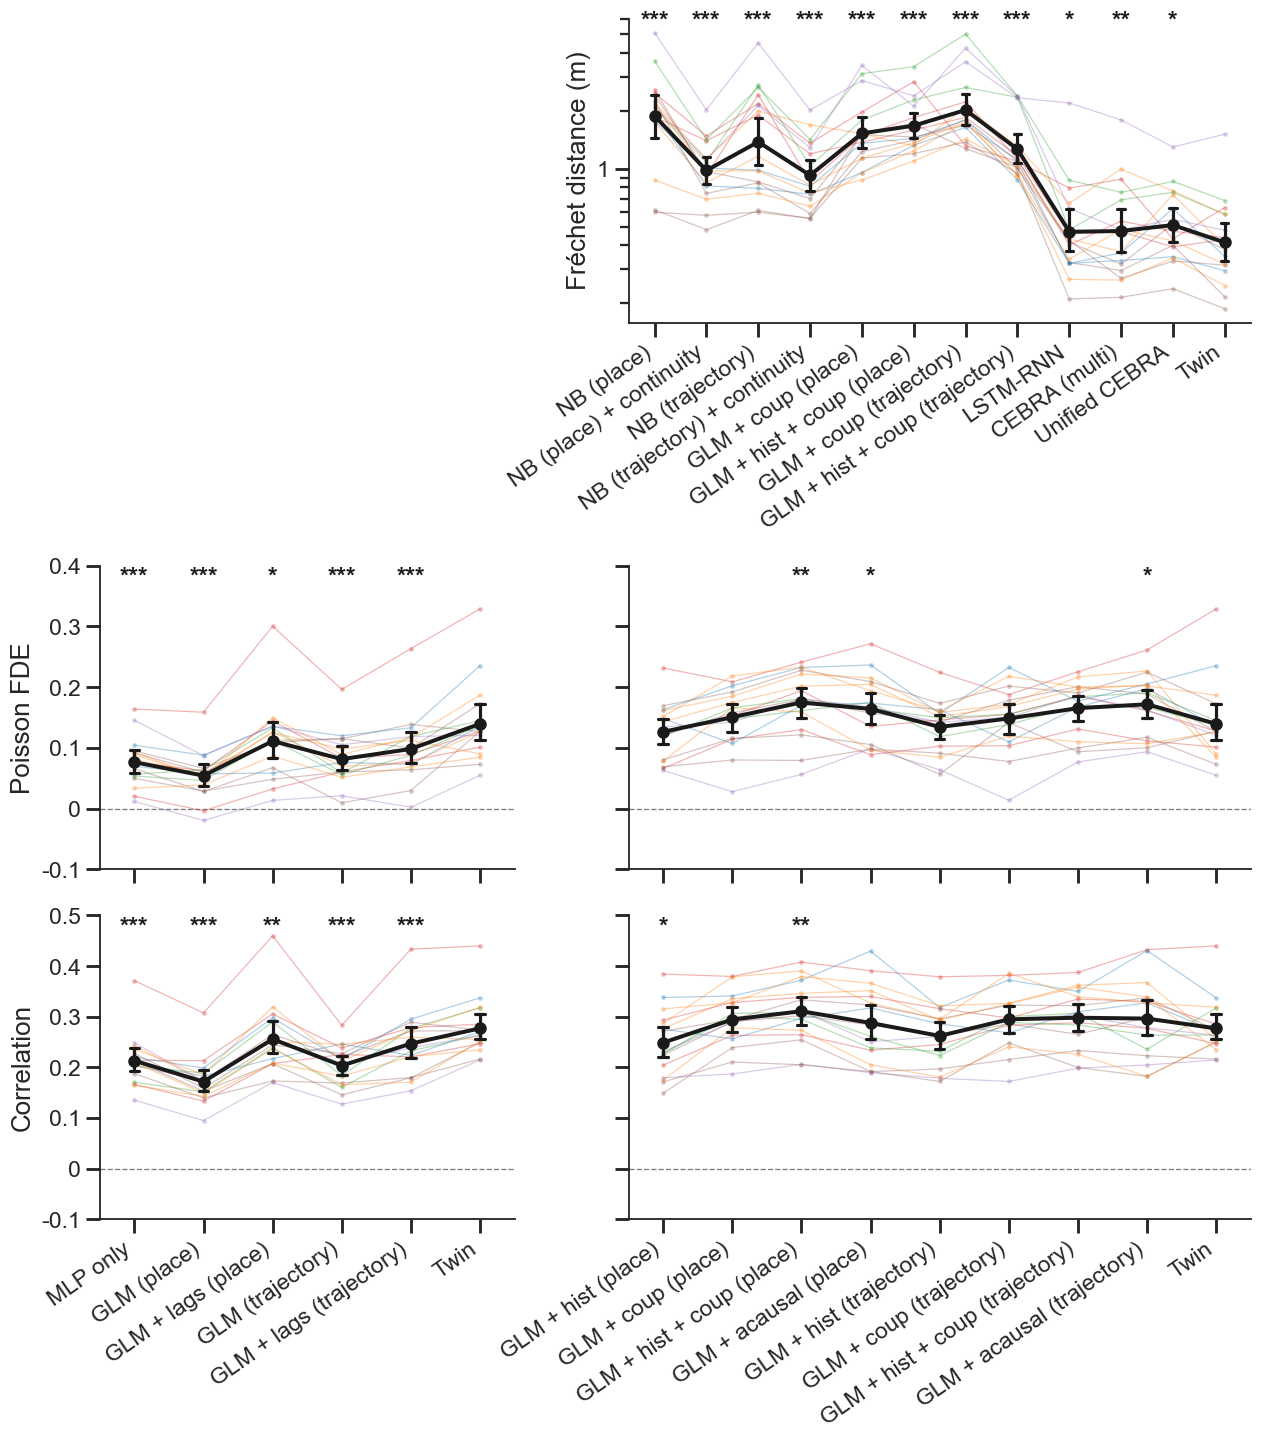


ED Fig 1d Fréchet — session-level Wilcoxon vs Twin (session medians):
                model    vs  n  median_diff         p stars         P
          naive_bayes joint 17        1.642 1.526e-05   *** P < 0.001
        nb_continuity joint 17        0.528 1.526e-05   *** P < 0.001
  naive_bayes_cluster joint 17       0.8419 1.526e-05   *** P < 0.001
nb_continuity_cluster joint 17       0.4571 1.526e-05   *** P < 0.001
         glm_map_coup joint 17        1.007 1.526e-05   *** P < 0.001
              glm_map joint 17        1.089 1.526e-05   *** P < 0.001
   glm_map_joint_coup joint 17         1.45 1.526e-05   *** P < 0.001
     glm_map_joint_hc joint 17       0.7357 1.526e-05   *** P < 0.001
             lstm_rnn joint 17      0.03518   0.01286     * P = 0.013
          cebra_multi joint 17      0.04157  0.006653    ** P = 0.007
                cebra joint 17      0.09667   0.03479     * P = 0.035

ED Fig 1e,g FDE — session-level Wilcoxon vs Twin (session medians):
                    

In [20]:
# === Extended Data Figure 1 (d-h) on a single canvas: 3 x 2 grid ===
# a-b are external schematics; they occupy the empty top-left space.
#   row 0:  [   (a-c space)   ] [ d: decoder session medians ]  (right-aligned)
#   row 1:  [ e behaviour: session ] [ g neural: session ]  (Poisson FDE)
#   row 2:  [ f behaviour: session ] [ h neural: session ]  (Correlation)
# The encoding models split into two groups, each anchored by the Twin on its right:
# LEFT = behaviour-alone models (MLP far-left, then behaviour-only GLMs place/traj
# +/- lags) + Twin; RIGHT = neural-data GLMs (history / coupling / acausal) + Twin. The
# Twin bar is REPEATED in both groups so each is a self-contained comparison vs it.
# Per-neuron / per-flight panels have been removed (session medians only); the pooled
# per-unit Wilcoxon vs the Twin is still reported below the figure.
LEFT_GROUP = ['MLP only'] + BEHAV_ONLY_GLMS          # MLP far-left, then behaviour-only GLMs
LEFT_ORDER = [m for m in LEFT_GROUP if m in ed1_present] + [OUR_MODEL]
RIGHT_ORDER = ([m for m in ed1_present if m not in LEFT_GROUP and m != OUR_MODEL] + [OUR_MODEL])
_nL, _nR = len(LEFT_ORDER), len(RIGHT_ORDER)

fig_ed1 = plt.figure(figsize=(13.5, 16.5))
# 2 columns: behaviour session | neural session; widths ~ #models so every bar keeps
# the same width across panels.
gs_ed1 = fig_ed1.add_gridspec(3, 2, hspace=0.8, wspace=0.22, width_ratios=[_nL, _nR])

# --- pooled unit-level (per-flight / per-neuron) paired Wilcoxon vs the Twin: reported
#     below the figure (the per-unit panels themselves were removed). ---
ptab_ed1d_pooled = ph.pooled_ptable(ed1_frechet, 'frechet_3d', ed1_dec_present, 'joint',
                                  ['session', 'flight_id'], model_col='decoder', higher_is_better=False)
ptab_ed1_fde_pooled = ph.pooled_ptable(ed1_encode_df, 'fde', ed1_present, OUR_MODEL,
                                  ['session', 'unit'], model_col='model', higher_is_better=True)
ptab_ed1_corr_pooled = ph.pooled_ptable(ed1_encode_df, 'corr', ed1_present, OUR_MODEL,
                                  ['session', 'unit'], model_col='model', higher_is_better=True)

# row 0 (d): decoder ladder, right-aligned into the right column (a-c space at left)
ax_d = fig_ed1.add_subplot(gs_ed1[0, 1])
ax_d.set_yscale('log')              # Fréchet distance is strictly positive -> log y
_, ptab_ed1d = ph.compare_models_fig(
    ed1_frechet, 'frechet_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight',
    higher_is_better=False, show_titles=False, axes=(ax_d, None))


def _encode_row(row, value_col, ylabel, clip, sess_ylim, show_xticklabels):
    """Behaviour group (col 0) then neural group (col 1); Twin repeated. The neural group
    drops its y-axis label (same scale as the behaviour group). Returns (combined
    session-level p-table, the two row axes)."""
    bS = fig_ed1.add_subplot(gs_ed1[row, 0])
    nS = fig_ed1.add_subplot(gs_ed1[row, 1])
    common = dict(unit_name='neuron', clip=clip, zero_line=True, sess_ylim=sess_ylim,
                  show_xticklabels=show_xticklabels, show_titles=False)
    _, ptL = ph.compare_models_fig(ed1_encode_df, value_col, LEFT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, axes=(bS, None), **common)
    _, ptR = ph.compare_models_fig(ed1_encode_df, value_col, RIGHT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, show_sess_ylabel=False,
                                   axes=(nS, None), **common)
    nS.tick_params(labelleft=False)   # neural group shares the behaviour group's y-axis
    return pd.concat([ptL, ptR], ignore_index=True), (bS, nS)


ptab_ed1_fde, _ = _encode_row(1, 'fde', 'Poisson FDE', (-1, 1), (-0.1, 0.4),
                           show_xticklabels=False)
ptab_ed1_corr, ax_corr = _encode_row(2, 'corr', 'Correlation', (-0.2, 1), (-0.1, 0.5),
                              show_xticklabels=True)

# row 1 dropped its xticklabels (shared with row 2), so lift row 2 up into the vacated
# space (measured from row 2's own identical xticklabels via the tight bbox).
fig_ed1.canvas.draw()
try:
    _rend = fig_ed1.canvas.get_renderer()
    _lift = min((_ax.get_position().y0
                 - _ax.get_tightbbox(_rend).transformed(fig_ed1.transFigure.inverted()).y0)
                for _ax in ax_corr)
except Exception:
    _lift = 0.06
_lift += 0.015   # shrink the row 1 (FDE) -> row 2 (Corr) gap ever so slightly
for _ax in ax_corr:
    _box = _ax.get_position()
    _ax.set_position([_box.x0, _box.y0 + _lift, _box.width, _box.height])

ph.save_fig(fig_ed1, 'edfig1_full'); plt.show()
for _n, _pt in [('1d Fréchet', ptab_ed1d), ('1e,g FDE', ptab_ed1_fde),
                ('1f,h corr', ptab_ed1_corr)]:
    print(f'\nED Fig {_n} — session-level Wilcoxon vs {OUR_MODEL} (session medians):')
    ph.p_table(_pt.to_dict('records'))
for _n, _pt in [('1d Fréchet (per-flight)', ptab_ed1d_pooled),
                ('1e,g FDE (per-neuron)', ptab_ed1_fde_pooled),
                ('1f,h corr (per-neuron)', ptab_ed1_corr_pooled)]:
    print(f'\nED Fig {_n} — pooled unit-level Wilcoxon vs {OUR_MODEL} (per-unit stats, no panel):')
    ph.p_table(_pt.to_dict('records'))


**Extended Data Figure 1 | Full model ladders.**
(A) Schematic layout of indoor flight room with freely-moving recording. (B) Schematic input data for the Twin model. Single-unit spike counts and 3-D position were chunked into individual flights, binned at 100 ms, padded to the length of the longest flight, and input to the model with shape (B, N, T) and (B, 3, T), where the batch dimension B = number of flights, N = number of neurons, T = number of time bins, and 3 = number of spatial dimensions. (C). Each batch was assigned one of three masking strategies: ``Encoding'' (in which neural data was fully masked and used as the prediction target), ``Decoding'' (in which behavioral data was fully masked and used as the prediction target), and ``Infill'' (in which the same random time steps from both neurons and behavior were masked and used as the prediction target). (D) Per-flight 3-D Fréchet distance (lower is better) for the decoder ladder. GLMs were inverted by gradient descent over position to maximize Poisson likelihood + a smoothness prior, producing correlation-aware decoders (see \ref{sec:methods}). Left to right, each versus the Twin (paired two-sided Wilcoxon signed-rank on session medians, n = 17 sessions): `NB (place)' ($P = 1.53 \times 10^{-5}$), `NB (place) + continuity' ($P = 1.53 \times 10^{-5}$), `NB (trajectory)' ($P = 1.53 \times 10^{-5}$), `NB (trajectory) + continuity' ($P = 1.53 \times 10^{-5}$), `GLM + coup (place)' ($P = 1.53 \times 10^{-5}$), `GLM + hist + coup (place)' ($P = 1.53 \times 10^{-5}$), `GLM + coup (trajectory)' ($P = 1.53 \times 10^{-5}$), `GLM + hist + coup (trajectory)' ($P = 1.53 \times 10^{-5}$), `LSTM-RNN' ($P = 0.0129$), `multi-session CEBRA' ($P = 0.00168$), `Unified CEBRA' ($P = 0.0448$), and our Twin. (E) Poisson FDE for models that use only behavior data for neural prediction. Each model versus the Twin (paired two-sided Wilcoxon signed-rank on session medians, n = 17 sessions): `MLP only' ($P = 7.63 \times 10^{-5}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.0110$), `GLM (trajectory)' ($P = 3.05 \times 10^{-5}$), `GLM + lags (trajectory)' ($P = 5.04 \times 10^{-4}$). (F) Same as (E), but for Pearson correlation: `MLP only' ($P = 1.53 \times 10^{-5}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.00168$), `GLM (trajectory)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (trajectory)' ($P = 3.81 \times 10^{-4}$). (G-H), same as (E-F), but for GLMs which additionally condition on spike history, cross-neuron coupling, and/or future spiking. (G) Poisson FDE: `GLM + hist (place)' ($P = 0.207$), `GLM + coup (place)' ($P = 0.263$), `GLM + hist + coup (place)' ($P = 0.00557$), `GLM + acausal (place)' ($P = 0.0395$), `GLM + hist (trajectory)' ($P = 1.00$), `GLM + coup (trajectory)' ($P = 0.159$), `GLM + hist + coup (trajectory)' ($P = 0.0714$), `GLM + acausal (trajectory)' ($P = 0.0202$). (H) Pearson correlation: `GLM + hist (place)' ($P = 0.0305$), `GLM + coup (place)' ($P = 0.0984$), `GLM + hist + coup (place)' ($P = 0.00557$), `GLM + acausal (place)' ($P = 0.712$), `GLM + hist (trajectory)' ($P = 0.159$), `GLM + coup (trajectory)' ($P = 0.120$), `GLM + hist + coup (trajectory)' ($P = 0.132$), `GLM + acausal (trajectory)' ($P = 0.174$). See also Figure \ref{fig:fig1} and Figures \ref{fig:S2}-\ref{fig:S3}.

## ED Fig 2

In [21]:
# === ED Fig 2a-c data: decoding cost (mode - real) from decode-position-comparison ===
# Per-flight surrogate-mode decode tables exported by decode-position-comparison.ipynb
# (§5 export cell) -> paired per-flight costs metric(mode) - metric(real). The decoder
# subset shown in ED Fig 2 matches the ED Fig 1d nomenclature (GLM-inversion place
# variants) and is anchored on the Twin joint decoder (NOT Bat_Transformer_Decoder).
ED2_COST_PATH = f'./out/decode_costs/ed2_decode_costs_seed_{seed}.pkl'

# Surrogate modes shown as cost panels (one row each).
ED2_COST_MODES = [('trial_shuffled', 'Trial-shuffle'),
                  ('synthetic', 'Synthetic (place)'),
                  ('synthetic_traj', 'Synthetic (trajectory)')]
# Decoders compared in each cost panel, in ED Fig 1c order; last = Twin (the
# joint masked encoder/decoder used as a decoder), the anchor for the Wilcoxon test.
# Three decoders at matched complexity: GLM + hist + coup for place vs trajectory
# (place x traj-cluster) conditioning, plus Twin (the joint masked encoder/decoder
# used as a decoder) — the last is the Wilcoxon anchor. All three appear in every mode,
# so the cost panels share one x-axis. Note the temporal filters HURT a GLM-inversion
# decoder (they explain firing that would otherwise pin down position), so glm_map_joint_hc
# has a poorer real baseline and small, sometimes negative synthetic costs; its trial-shuffle
# cost stays strongly positive (it relies on the coupling that trial-shuffle destroys).
ED2_COST_MODELS = ['glm_map', 'glm_map_joint_hc', 'joint']
ED2_COST_REF = 'joint'
ED2_COST_LABELS = {'glm_map': 'GLM + hist + coup (place)',
                   'glm_map_joint_hc': 'GLM + hist + coup (trajectory)', 'joint': OUR_MODEL}


def _mode_cost(flightdf, value_col, mode):
    """Per-flight paired cost = value(mode) - value(real), matched on flight+model.
    Test flights are the real held-out flights (by reference) in every asymmetric
    mode, so the join is 1:1."""
    keys = ['bat', 'session', 'flight_id', 'model']
    real = flightdf[flightdf['data'] == 'real'][keys + [value_col]]
    surr = flightdf[flightdf['data'] == mode][keys + [value_col]]
    m = surr.merge(real, on=keys, suffixes=('_surr', '_real'))
    m['value'] = m[f'{value_col}_surr'] - m[f'{value_col}_real']
    m = m[m['model'].isin(ED2_COST_MODELS)].copy()
    present = [c for c in ED2_COST_MODELS if c in set(m['model'])]
    m['model'] = pd.Categorical(m['model'], present, ordered=True)
    return m


def _pkl_has_joint(path):
    """True iff the cached export carries the models ED Fig 2 needs (Twin +
    the GLM + hist + coup trajectory inversion)."""
    try:
        have = set(pd.read_pickle(path)['frechet_by_mode']['model'])
        return {'joint', 'glm_map_joint_hc'} <= have
    except Exception:
        return False


# Regenerate the per-flight surrogate-mode decode tables in-place if missing OR if the
# cached pkl predates the Twin column (run-once cache; heavy — trains one joint
# decoder per mode plus the GLM-inversion / transformer decoders). The generation logic
# is the single-sourced package pipeline decode-position-comparison.ipynb also uses.
if not os.path.exists(ED2_COST_PATH) or not _pkl_has_joint(ED2_COST_PATH):
    try:
        from digitalbat.decoding.cost_pipeline import generate_ed2_decode_costs
        from digitalbat.datasets.defaults import (
            DEFAULT_SESSION_NAMES as _ED2_DSN, make_data_config as _ed2_mdc)
        # DEFAULT_SESSION_NAMES already omits Dataset_3_14543_240419 (commented out at
        # source), so this is the full canonical 17-session list -- pass it verbatim.
        _ed2_decode_cfg = _ed2_mdc(session_names=list(_ED2_DSN))
        _why = 'missing' if not os.path.exists(ED2_COST_PATH) else 'lacks Twin'
        print(f'[ED2 c-h] {ED2_COST_PATH} {_why} — regenerating via '
              'cost_pipeline.generate_ed2_decode_costs (cached ckpts under ./out) …')
        generate_ed2_decode_costs(_ed2_decode_cfg, device=device, seed=seed,
                                  out_path=ED2_COST_PATH, joint_params=JOINT_PARAMS,
                                  joint_input_transform=INPUT_TRANSFORM)
    except Exception as _ed2_exc:
        print(f'[ED2 c-h] regeneration failed ({type(_ed2_exc).__name__}: {_ed2_exc}); '
              'cost panels will show placeholders.')


ed2_cost = None
if os.path.exists(ED2_COST_PATH):
    _exp = pd.read_pickle(ED2_COST_PATH)
    _fr = _exp['frechet_by_mode']
    ed2_cost = {}
    for mode, _lab in ED2_COST_MODES:
        ed2_cost[('frechet_3d', mode)] = _mode_cost(_fr, 'frechet_3d', mode)
    print('ED2 cost tables (rows):', {f'{k[0]}|{k[1]}': len(v) for k, v in ed2_cost.items()})
    if not _pkl_has_joint(ED2_COST_PATH):
        print('[ED2 a-c] WARNING: cached pkl still lacks Twin — last column will be empty.')
else:
    print(f'[ED2 a-c] could not produce {ED2_COST_PATH}; cost panels show placeholders.')


ED2 cost tables (rows): {'frechet_3d|trial_shuffled': 834, 'frechet_3d|synthetic': 834, 'frechet_3d|synthetic_traj': 834}


In [22]:
# === ED Fig 2d/e: encode ladder RETRAINED on synthetic place-cell spikes, eval on real ===
# Replace each session's TRAIN spikes with samples from its smoothed 3-D rate map
# (valid/test stay real by reference), retrain the full ED Fig 1 encode ladder with the
# SAME architecture/hyperparameters (train-if-missing, `_synth` checkpoints), then
# score per-neuron FDE/corr on the REAL held-out test set. Mirrors internals.ipynb /
# preprocess-data-v0j-share.ipynb, extended from the transformer to the whole ladder.
from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders
from digitalbat.training.joint_trainer import train_joint, scheme_weights
import re as _re

SYNTH_MODE = 'empirical'   # matches decode-position-comparison SYNTH_SAMPLING ('empirical' resample)
SYNTH_TAG = f'_synth_{SYNTH_MODE}'

# The joint universe's meta stats are 13-D (kinematic); the position-only view is
# 3-D. Slice behaviour mean/std to xyz for the synthetic rate-map fit (matches how
# gather_session_arrays / joint_decode un-z-score position elsewhere).
_meta_pos3 = dict(meta_info_dict)
_meta_pos3['behavior_mean'] = {s: np.asarray(v).reshape(-1)[:3]
                               for s, v in meta_info_dict['behavior_mean'].items()}
_meta_pos3['behavior_std'] = {s: np.asarray(v).reshape(-1)[:3]
                              for s, v in meta_info_dict['behavior_std'].items()}
syn_loaders, syn_simulators = make_synthetic_train_dataloaders(
    dataloaders, _meta_pos3, dt=bin_width, mode=SYNTH_MODE, seed=seed)
assert syn_loaders['valid'] is dataloaders['valid'] and syn_loaders['test'] is dataloaders['test']


def _synth_ckpt(path):
    root, ext = os.path.splitext(path)
    return f'{root}{SYNTH_TAG}{ext}'


def _joint_synth_params():
    """Consensus joint hyperparameters (parsed from JOINT_CKPT + cached study)."""
    p = dict(num_layers=JOINT_PARAMS['num_layers'], latent_dim=JOINT_PARAMS['latent_dim'],
             ff_dim=JOINT_PARAMS['ff_dim'], dropout=JOINT_PARAMS['dropout'],
             lr=3e-3, weight_decay=1e-2, w_encode=1.0, w_decode=1.0, w_aux=1.0,
             lam=1.0, pos_weight=1.0)
    base = os.path.basename(JOINT_CKPT)
    for k, rgx in dict(lam=r'_lam([0-9.]+)', pos_weight=r'_pw([0-9.]+)', w_encode=r'_we([0-9.]+)',
                       w_decode=r'_wd([0-9.]+)', w_aux=r'_wa([0-9.]+)').items():
        mm = _re.search(rgx, base)
        if mm:
            p[k] = float(mm.group(1))
    study_path = './out/joint/joint_optuna_v2_kin0.pkl'
    if os.path.exists(study_path):
        try:
            p.update(pickle.load(open(study_path, 'rb')).best_params)
        except Exception as _e:
            print(f'  [joint-synth] could not read study ({_e}); using parsed/default params')
    return p


def _ensure_joint_synth(loaders):
    """Retrain the joint transformer on synthetic train spikes (same params)."""
    p = _joint_synth_params()
    ckpt = _synth_ckpt(JOINT_CKPT.replace('_infillft', ''))
    set_random_state(seed)
    jm = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, latent_dim=p['latent_dim'], num_heads=4,
        ff_dim=p['ff_dim'], num_layers=p['num_layers'], dropout=p['dropout'],
        input_transform=INPUT_TRANSFORM, session_to_room=session_to_room).to(device)
    if os.path.exists(ckpt):
        jm.load_state_dict(torch.load(ckpt, map_location=device))
    else:
        print(f'  [train joint-synth] {os.path.basename(ckpt)}')
        jm, _b, _ = train_joint(jm, loaders, device, meta_info_dict, seed=seed, n_epochs=1000,
                                lr=p['lr'], weight_decay=p['weight_decay'], lam=p['lam'],
                                pos_weight=p['pos_weight'], scheme_p=scheme_weights(p),
                                select='joint', fde_weight=0.5, err_ref=0.3, fde_ref=0.1)
        torch.save(jm.state_dict(), ckpt)
    return jm.eval()


# Retrain the ladder on synthetic train (rebind the notebook's global `dataloaders`
# so the ED Fig 1 ensure_*/train_glm helpers train on synthetic + validate on real),
# then evaluate on the REAL test set. syn_loaders['test'] is the real test by reference.
# ED Fig 2 mirrors the ED Fig 1 encode ladder (same models incl. GLM + lags
# (trajectory), same order); the delta(synthetic - real) is computed per model below.
_real_loaders = dataloaders
_syn_pieces = []
try:
    dataloaders = syn_loaders
    for label, kind, spec in ED1_MODELS:
        try:
            if kind == 'glm':
                name, cond = spec
                gm = ensure_glm(_synth_ckpt(glm_ckpt(name, cond)),
                                lambda: build_glm(name, cond), cond=cond,
                                search_alpha=('coup' in name))
                df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
            elif kind == 'former':
                ck = _synth_ckpt(make_model_name(
                    seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                    out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                             'small': './out/bat_former_small'}[spec], suffix=DATA_TAG))
                fm = ensure_former(ck, lambda: build_former(spec), loaders=syn_loaders)
                df = eval_former_metrics(fm)
            else:  # joint / Twin
                jm = _ensure_joint_synth(syn_loaders)
                df = encode_eval_records(JointEncoderAdapter(jm, unit_num_dict).to(device).eval(),
                                         _real_loaders, device)
            _syn_pieces.append(df.assign(model=label))
            print(f'  ok (synthetic): {label}')
        except Exception as exc:
            print(f'  [skip synthetic {label}] {type(exc).__name__}: {exc}')
finally:
    dataloaders = _real_loaders

ed2_encode_df = pd.concat(_syn_pieces, ignore_index=True)
ed2_enc_present = [m for m in ED1_ORDER if m in set(ed2_encode_df['model'])]
ed2_encode_df['model'] = pd.Categorical(ed2_encode_df['model'], ed2_enc_present, ordered=True)
print('ED2 synthetic-encode models:', ed2_enc_present)

  ok (synthetic): GLM (place)
GLM: 11 lags x 108 spatial = 1188 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok (synthetic): GLM + lags (place)
  ok (synthetic): GLM (trajectory)
  ok (synthetic): GLM + lags (trajectory)
  ok (synthetic): GLM + hist (place)
  ok (synthetic): GLM + coup (place)
  ok (synthetic): GLM + hist + coup (place)
  ok (synthetic): GLM + acausal (place)
  ok (synthetic): GLM + hist (trajectory)
  ok (synthetic): GLM + coup (trajectory)
  ok (synthetic): GLM + hist + coup (trajectory)
  ok (synthetic): GLM + acausal (trajectory)
  ok (synthetic): MLP only
  ok (synthetic): Twin
ED2 synthetic-encode models: ['GLM (place)', 'GLM + lags (place)', 'GLM (trajectory)', 'GLM + lags (trajectory)', 'GLM + hist (place)', 'GLM + coup (place)', 'GLM + hist + coup (place)', 'GLM + acausal (place)', 'GLM + hist (trajectory)', 'GLM + coup (trajectory)', 'GLM + hist + coup (trajectory)', 'GLM + acausal (trajectory)', 'MLP only', 'Twin']


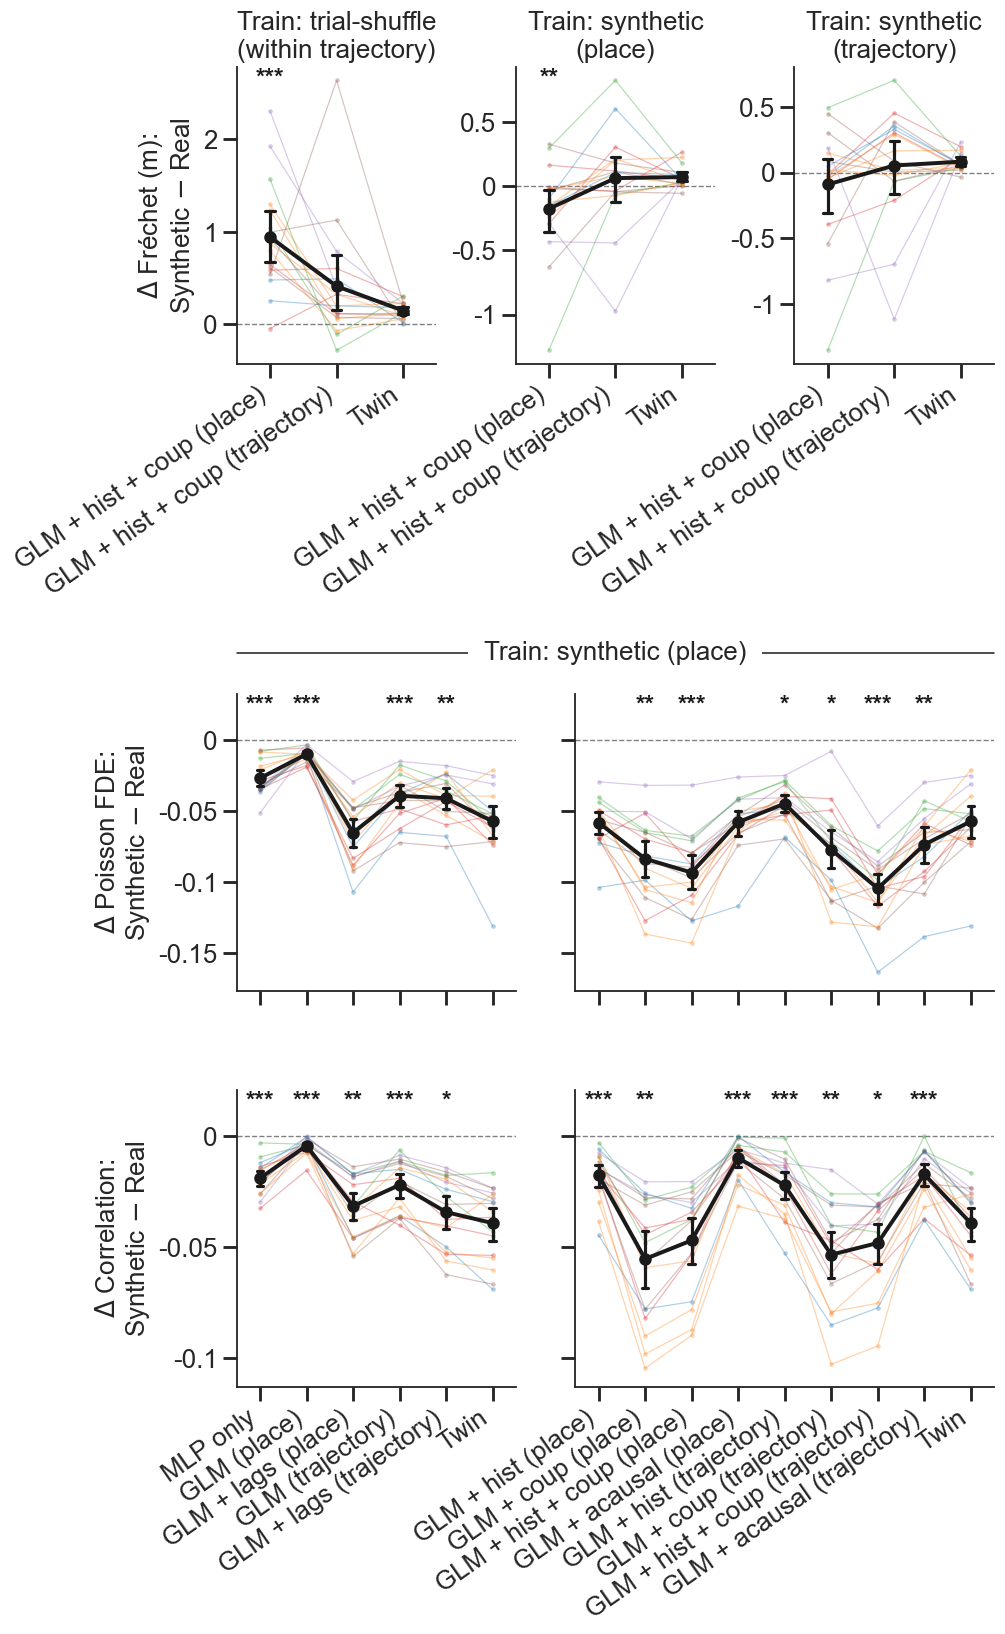


ED Fig 2a Trial-shuffle frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff         p stars         P
         glm_map joint 17       0.7377 4.578e-05   *** P < 0.001
glm_map_joint_hc joint 17      0.02225    0.1454       P = 0.145

ED Fig 2b Synthetic (place) frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff        p stars         P
         glm_map joint 17      -0.1911 0.006653    ** P = 0.007
glm_map_joint_hc joint 17      0.01679   0.7119       P = 0.712

ED Fig 2c Synthetic (trajectory) frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff      p stars         P
         glm_map joint 17     -0.06701 0.2247       P = 0.225
glm_map_joint_hc joint 17    -0.004435 0.6777       P = 0.678

ED Fig 2d ΔFDE — session-level Wilcoxon:
                         model   vs  n  median_diff         p stars         P
                      MLP only Twin 17     -0.03137 0.0003815   *** P < 0.001
               

In [23]:
# === Extended Data Figure 2 on a single canvas — decode-cost (top row) + encode-cost ===
# Everything is a "surrogate minus real-trained" delta, matched per unit/flight.
#   Rows A–C (top) DECODE cost: Δ Fréchet = metric(decoder trained on surrogate) −
#             metric(trained on real). Three panels side by side, one per surrogate train
#             mode (trial-shuffle | synthetic place | synthetic trajectory), each titled by
#             its train condition; session-median panel only (per-flight removed). Wilcoxon
#             anchored on Twin.
#   Rows D,E  ENCODE cost: Δ Poisson FDE / Δ Pearson r =
#             metric(ladder retrained on synthetic place spikes) − metric(real-trained
#             ladder), both scored on the real test set. Session-median panels only
#             (per-neuron removed), behaviour group | neural group, below the decode row.

# ---- Encode delta: synthetic-trained − real-trained, matched per (session, unit, model) ----
_e2 = ed2_encode_df.assign(model=ed2_encode_df['model'].astype(str))
_e1 = ed1_encode_df.assign(model=ed1_encode_df['model'].astype(str))
_enc_delta = _e2.merge(_e1[['session', 'unit', 'model', 'fde', 'corr']],
                       on=['session', 'unit', 'model'], suffixes=('_syn', '_real'))
_enc_delta['fde'] = _enc_delta['fde_syn'] - _enc_delta['fde_real']
_enc_delta['corr'] = _enc_delta['corr_syn'] - _enc_delta['corr_real']
_enc_present = [m for m in ed2_enc_present if m in set(_enc_delta['model'])]
_enc_delta['model'] = pd.Categorical(_enc_delta['model'], _enc_present, ordered=True)

# ---- Manual axis geometry (figure fraction). Panels short, gaps generous (esp. central). ----
fig_ed2 = plt.figure(figsize=(18, 15))
_L, _R, _TOP, _BOT = 0.16, 0.985, 0.88, 0.05
_UW = _R - _L
_g_enc = 0.100                                   # full-width rows: 2 axes, wide central gutter
_w_full = (_UW - _g_enc) / 2
_x_enc = [_L, _L + _w_full + _g_enc]

# Encode rows D/E: behaviour group | neural group (per-neuron removed); bars keep the
# ED Fig 1 encode-row width. Computed first so the decode row can match this block's total width.
_G_IN, _G_GRP = 0.045, 0.03          # within-group (kept for bar-width) and between-group gaps
_u_enc = (_UW - 2 * _G_IN - _G_GRP) / (2 * _nL + 2 * _nR)   # keep the per-bar width as before
_xw_enc, _xx = [], _L                 # session-only: behaviour group then neural group
for _wu, _gap in [(_nL, _G_GRP), (_nR, 0.0)]:
    _xw_enc.append((_xx, _wu * _u_enc)); _xx += _wu * _u_enc + _gap
_enc_block_w = _xx - _L               # _L to the right edge of the neural group

# Top decode row: three session-median panels spanning the SAME total width as the encode
# block (left-aligned), one per surrogate train mode.
_g_dec = 0.04
_w_dec = (_enc_block_w - 2 * _g_dec) / 3
_x_dec = [_L + i * (_w_dec + _g_dec) for i in range(3)]

_h = 0.18                                         # panel height (3 rows, extra row-1->2 gap)
_ROW_GAPS = [0.20, 0.06]                          # decode->encode section break, then encode pair
_NR = 3
_rowy, _y = [], _TOP
for r in range(_NR):
    _y -= _h
    _rowy.append(_y)
    if r < _NR - 1:
        _y -= _ROW_GAPS[r]

# Decode row (row 0): three single session-median panels across the full width.
_axA = [fig_ed2.add_axes([_x_dec[0], _rowy[0], _w_dec, _h])]   # trial-shuffle (decode)
_axB = [fig_ed2.add_axes([_x_dec[1], _rowy[0], _w_dec, _h])]   # synthetic (place) (decode)
_axC = [fig_ed2.add_axes([_x_dec[2], _rowy[0], _w_dec, _h])]   # synthetic (trajectory) (decode)
# Encode rows D/E use the same 2-group split as ED Fig 1 encode rows (behaviour models incl.
# MLP + Twin | neural GLMs + Twin; Twin repeated), reusing LEFT_ORDER / RIGHT_ORDER /
# _nL / _nR from the ED Fig 1 cell. Two subplots per row: behaviour session | neural
# session, widths ~ #models.
# (encode-row geometry _xw_enc / _enc_block_w computed above, before the decode row)


def _grid2(r):
    """2 axes for encode row r: behaviour session | neural session (per-neuron removed)."""
    return [fig_ed2.add_axes([x, _rowy[r], w, _h]) for x, w in _xw_enc]


_axD = _grid2(1)   # Δ FDE (encode)
_axE = _grid2(2)   # Δ r (encode)

ptabs_ed2 = {}

# ---- Rows A–C (top): decode cost, one session-median Fréchet panel per surrogate mode ----
# (row axes, mode label, mode key, panel title = the former left-gutter "Train:" label)
_dec_rows = [(_axA, 'Trial-shuffle', 'trial_shuffled', 'Train: trial-shuffle\n(within trajectory)'),
             (_axB, 'Synthetic (place)', 'synthetic', 'Train: synthetic\n(place)'),
             (_axC, 'Synthetic (trajectory)', 'synthetic_traj', 'Train: synthetic\n(trajectory)')]
_cost_specs = [('frechet_3d', 'flight', '$\\Delta$ Fréchet (m):\nSynthetic $-$ Real')]
_letters = 'abc'
for ri, (axrow, mlabel, mode, title) in enumerate(_dec_rows):
    for mi, (metric, unit, stem) in enumerate(_cost_specs):
        ax_single = axrow[0]
        tab = ed2_cost.get((metric, mode)) if ed2_cost else None
        if tab is not None and len(tab):
            _, pt = ph.compare_models_fig(
                tab, 'value', ED2_COST_MODELS, ref=ED2_COST_REF, labels=ED2_COST_LABELS,
                model_col='model', ylabel=stem, unit_name=unit,
                higher_is_better=False, zero_line=True, axes=(ax_single, None),
                show_titles=False, show_xticklabels=True, show_sess_ylabel=(ri == 0))
            ax_single.set_title(title, fontsize=plt.rcParams['axes.labelsize'])
            ptabs_ed2[f'2{_letters[ri]} {mlabel} {metric} cost'] = pt
        else:
            ax_single.set_axis_off()
            ax_single.set_title(title, fontsize=plt.rcParams['axes.labelsize'])
            ax_single.text(0.5, 0.5, f'{mlabel}\n{metric} cost:\nrun decode export cell',
                           ha='center', va='center', transform=ax_single.transAxes)

# ---- Rows D/E: encode delta (2-group split, same as ED Fig 1 encode rows; Twin repeated) ----
def _row_sess_ylim(value_col, pad_lo=0.08, pad_hi=0.20):
    """Shared session-median ylim across the behaviour + neural groups of one encode row
    (so its two panels share y-limits), with head-room for the significance stars."""
    _models = set(LEFT_ORDER) | set(RIGHT_ORDER)
    _s = (_enc_delta[_enc_delta['model'].isin(_models)]
          .groupby(['session', 'bat', 'model'], observed=True)[value_col].median())
    _lo, _hi = min(float(_s.min()), 0.0), max(float(_s.max()), 0.0)   # keep the zero line in view
    _r = (_hi - _lo) or 1.0
    return (_lo - pad_lo * _r, _hi + pad_hi * _r)


def _enc_delta_row(axq, value_col, ylabel, show_xticklabels):
    bS, nS = axq
    common = dict(unit_name='neuron', zero_line=True, higher_is_better=True,
                  sess_ylim=_row_sess_ylim(value_col), show_titles=False,
                  show_xticklabels=show_xticklabels)
    _, ptL = ph.compare_models_fig(_enc_delta, value_col, LEFT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, axes=(bS, None), **common)
    _, ptR = ph.compare_models_fig(_enc_delta, value_col, RIGHT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, show_sess_ylabel=False, axes=(nS, None), **common)
    nS.tick_params(labelleft=False)   # neural group shares the behaviour group's y-axis
    return pd.concat([ptL, ptR], ignore_index=True)


ptabs_ed2['2d ΔFDE'] = _enc_delta_row(
    _axD, 'fde', '$\\Delta$ Poisson FDE:\nSynthetic $-$ Real',
    show_xticklabels=False)
ptabs_ed2['2e Δr'] = _enc_delta_row(
    _axE, 'corr', '$\\Delta$ Correlation:\nSynthetic $-$ Real',
    show_xticklabels=True)

# ---- "Train: synthetic (place)" header over the encode block (row 2): a title inset
#      into a horizontal rule spanning the block width ----
_hy = _rowy[1] + _h + 0.025                        # just above the encode (ΔFDE) row
_hx0, _hx1 = _L, _L + _enc_block_w
fig_ed2.add_artist(plt.Line2D([_hx0, _hx1], [_hy, _hy], color='k', lw=1.0,
                                    transform=fig_ed2.transFigure, zorder=1))
fig_ed2.text((_hx0 + _hx1) / 2, _hy, '  Train: synthetic (place)  ', ha='center', va='center',
             fontsize=plt.rcParams['axes.labelsize'], zorder=2,
             bbox=dict(facecolor='white', edgecolor='none', pad=1))

_base_fs = plt.rcParams['axes.labelsize']   # match tick labels to the axis-label / title size
for _ax in fig_ed2.axes:
    _ax.tick_params(labelsize=_base_fs)
ph.save_fig(fig_ed2, 'edfig2_full')
plt.show()
for _n, _pt in ptabs_ed2.items():
    if _pt is None or not len(_pt):
        continue
    print(f'\nED Fig {_n} — session-level Wilcoxon:')
    ph.p_table(_pt.to_dict('records'))

# pooled per-unit (per-flight decode / per-neuron encode) Wilcoxon (per-unit stats, no panel)
for _mode, _mlab in [('trial_shuffled', 'Trial-shuffle'), ('synthetic', 'Synthetic (place)'),
                     ('synthetic_traj', 'Synthetic (trajectory)')]:
    _t = ed2_cost.get(('frechet_3d', _mode)) if ed2_cost else None
    if _t is not None and len(_t):
        print(f'\nED Fig 2 decode {_mlab} (per-flight) — pooled Wilcoxon vs {ED2_COST_REF}:')
        ph.p_table(ph.pooled_ptable(_t, 'value', ED2_COST_MODELS, ED2_COST_REF,
                   ['session', 'flight_id'], model_col='model', higher_is_better=False).to_dict('records'))
for _met, _lab in [('fde', '2d ΔFDE (per-neuron)'), ('corr', '2e Δr (per-neuron)')]:
    print(f'\nED Fig {_lab} — pooled Wilcoxon vs {OUR_MODEL}:')
    ph.p_table(ph.pooled_ptable(_enc_delta, _met, _enc_present, OUR_MODEL,
               ['session', 'unit'], model_col='model', higher_is_better=True).to_dict('records'))


---
**Extended Data Figure 2 | Surrogate-trained controls isolate the structure exploited by the Twin.** All panels were trained on surrogate data as indicated and then evaluated on real, held-out test data. (A–C) Per-flight difference in 3-D Fréchet distance (m) on surrogate versus real data. Three correlation-aware decoders of similar complexity and encoding performance (see Figure~\ref{fig:S1}) are compared: `GLM + hist + coup (place)', `GLM + hist + coup (trajectory)', and Twin, with the Wilcoxon test anchored on Twin. (A)  Flights of the same trajectory cluster were randomly shuffled, breaking the ``noise correlations'' on which the `GLM + hist + coup (place)' ($P = 4.58 \times 10^{-5}$) but not `(trajectory)' ($P = 0.145$) model depend relative to the Twin. (B) Synthetic spikes were generated based on each recorded neuron's binned and smoothed empirical rate map on training data, thereby eliminating not only noise correlations but also trajectory specificity. Now the `place GLM', which matches the generative structure of the synthetic data and performs comparatively better than the Twin ($P = 0.00665$), while the `trajectory GLM' does not ($P = 0.712$). (C) Same as (B), but synthetic spikes were generated in a trajectory-specific manner: `place GLM' ($P = 0.225$) and `trajectory GLM' ($P = 0.678$) vs the Twin. (D) Per-neuron difference in Poisson fraction deviance explained between synthetic place-cell spikes, generated as in (B), and real data.  The Twin is compared to the full model ladders from Figure \ref{fig:S1}E,G: `MLP only' ($P = 3.81 \times 10^{-4}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.0569$), `GLM (trajectory)' ($P = 8.39 \times 10^{-4}$), `GLM + lags (trajectory)' ($P = 0.00464$), `GLM + hist (place)' ($P = 0.890$), `GLM + coup (place)' ($P = 0.00316$), `GLM + hist + coup (place)' ($P = 3.05 \times 10^{-5}$), `GLM + acausal (place)' ($P = 1.00$), `GLM + hist (trajectory)' ($P = 0.0232$), `GLM + coup (trajectory)' ($P = 0.0202$), `GLM + hist + coup (trajectory)' ($P = 1.53 \times 10^{-5}$), `GLM + acausal (trajectory)' ($P = 0.00934$). The synthetic place cell spikes are least detrimental for models like `GLM (place)' which are best matched to the data generation mechanism, and most detrimental for those that explicitly rely on cross-neuron coupling. (E) Same as (D) but for the difference in Pearson correlation: `MLP only' ($P = 1.07 \times 10^{-4}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.00790$), `GLM (trajectory)' ($P = 7.63 \times 10^{-5}$), `GLM + lags (trajectory)' ($P = 0.0110$), `GLM + hist (place)' ($P = 1.07 \times 10^{-4}$), `GLM + coup (place)' ($P = 0.00557$), `GLM + hist + coup (place)' ($P = 0.120$), `GLM + acausal (place)' ($P = 3.05 \times 10^{-5}$), `GLM + hist (trajectory)' ($P = 1.07 \times 10^{-4}$), `GLM + coup (trajectory)' ($P = 0.00316$), `GLM + hist + coup (trajectory)' ($P = 0.0232$), `GLM + acausal (trajectory)' ($P = 4.58 \times 10^{-5}$). See also Figure \ref{fig:S1}.

## ED Fig 3

In [24]:
# === ED Fig 3: generate results if missing (train-if-missing, heavy) ===
# Each column's per-neuron / per-flight tables come from a standalone driver .py
# (train-if-missing: reruns skip existing checkpoints). We invoke a driver only when its
# target pkl is absent, mirroring the run-once caches in ED Figs 1-2. ED Figs 1-2 already
# self-generate (ED1 via `_cache_records`; ED2 via `cost_pipeline.generate_ed2_decode_costs`
# and the `_synth` retrain checkpoints), so no extra wiring is needed there.
import sys as _sys, subprocess as _subp
_REPO = os.path.abspath('..')                      # notebooks/ -> repo root

def _ensure_results(paths, argv, tag):
    """Run `argv` (from the repo root) iff any of `paths` is missing."""
    if all(os.path.exists(p) for p in paths):
        return
    print(f'[ED3:{tag}] results missing — generating via `{" ".join(argv)}` (heavy) …', flush=True)
    _subp.run(argv, cwd=_REPO, check=True)

_PY = _sys.executable
_ensure_results(['./out/transfer_joint/context/ctx_encode.pkl',
                 './out/transfer_joint/context/ctx_decode_fr.pkl'],
                [_PY, 'training/train_joint_context.py'], 'context')
_ensure_results(['./out/transfer/scaling_joint_session/results_scaling_joint_session.pkl'],
                [_PY, 'training/train_joint_scaling.py'], 'scaling')
_ensure_results(['./out/transfer/scaling_joint_session/results_scaling_joint_session_decode_fr.pkl'],
                [_PY, 'training/scaling_decode_fr.py'], 'scaling-frechet')
_ensure_results(['./out/transfer_joint/env/results_env_encode.pkl',
                 './out/transfer_joint/env/results_env_decode.pkl'],
                [_PY, 'training/train_joint_transfer.py', '--mode', 'env'], 'env')

In [25]:
# === ED Fig 3a/b: encoding fit vs context window — JOINT model ===
# The context sweep now trains one JOINT model per window size (window_size=W tiling),
# not the old Bat_Transformer. Metrics are precomputed by `training/train_joint_context.py`
# (per-neuron FDE/corr); the 'full' context reuses the main joint model's Fig 1g/h fit.
CTX_WINDOWS = [1, 3, 5, 7, 9, 11]
_ctx_enc_p = './out/transfer_joint/context/ctx_encode.pkl'
if not os.path.exists(_ctx_enc_p):
    ctx_df = None
    print('ED Fig 3: no joint context-encode results — run `python training/train_joint_context.py` first.')
else:
    ctx_pieces = [pd.read_pickle(_ctx_enc_p)]                       # windowed joint models
    # 'full' context = the main joint model's per-neuron encode fit (Fig 1g/h).
    ctx_pieces.append(encode_metrics_df[encode_metrics_df['model'] == 'joint']
                      [['session', 'bat', 'unit', 'corr', 'fde']].assign(context='full', context_x=13))
    ctx_df = pd.concat(ctx_pieces, ignore_index=True)
    print(f'ED Fig 3a/b: joint context-encode loaded ({ctx_df["context_x"].nunique()} context sizes)')

# (plotting for ED Fig 3a-d assembled on one canvas below)


ED Fig 3a/b: joint context-encode loaded (7 context sizes)


In [26]:
# === ED Fig 3c/d: decoding vs context window — JOINT model ===
# Same joint windowed models as ED Fig 3a/b, scored on the decode task (behaviour masked,
# spikes seen): per-flight 3-D Fréchet distance. Precomputed by
# `training/train_joint_context.py`; the 'full' context reuses the main joint decoder (Fig 1b).
_ctx_fr_p = './out/transfer_joint/context/ctx_decode_fr.pkl'
if not os.path.exists(_ctx_fr_p):
    fr_all = None
    print('ED Fig 3: no joint context-decode results — run `python training/train_joint_context.py` first.')
else:
    fr_pieces = [pd.read_pickle(_ctx_fr_p)]                         # per-flight Fréchet, windowed joint
    # 'full' context = the main joint decoder (Fig 1b).
    fr_pieces.append(joint_frechet[['bat', 'session', 'flight_id', 'frechet_3d']].assign(context_x=13))
    fr_all = pd.concat(fr_pieces, ignore_index=True)
    print(f'ED Fig 3c: joint context-decode loaded ({fr_all["context_x"].nunique()} context sizes)')

# (plotting for ED Fig 3a-c assembled on one canvas below)


ED Fig 3c: joint context-decode loaded (7 context sizes)


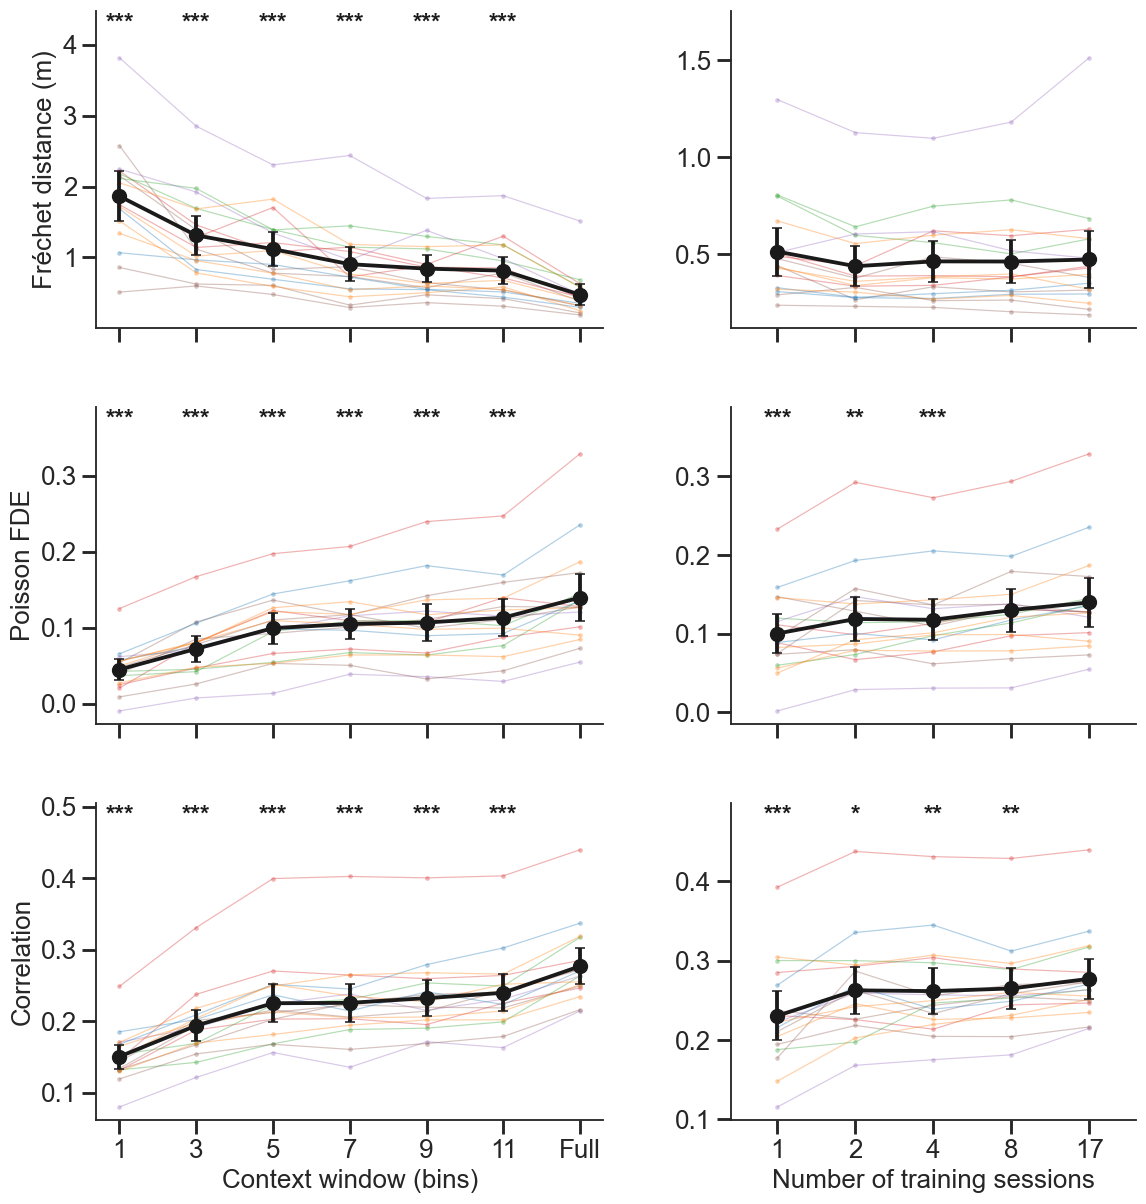

ED Fig 3 — foundation benefit vs (a) context window, (b) # training sessions, across 3-D Fréchet / Poisson FDE / correlation. Cols a-b stars: session-level Wilcoxon vs full.
 sweep  n         p               metric                              column stars         P
     1 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     3 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     5 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     7 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     9 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
    11 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     1 17   0.07141 Fréchet distance (m) Number of training sessions vs full       P = 0.071
     2 17    0.3289 Fréchet distance (m) Number of training sessions vs full      

In [27]:
# === Extended Data Figure 3 — foundation benefit along two axes x three metrics ===
# Rows: 3-D Fréchet (decode), Poisson FDE (encode), Pearson r (encode).
# Cols: (a) accuracy vs training *context window* [joint context sweep];
#       (b) accuracy vs # *training sessions* [session-universe scaling Twins].
#       Faint per-session lines (bat-coloured) + black mean±95% CI; stars =
#       session-level Wilcoxon vs the full model.
_scal_enc_p = './out/transfer/scaling_joint_session/results_scaling_joint_session.pkl'
_scal_fr_p  = './out/transfer/scaling_joint_session/results_scaling_joint_session_decode_fr.pkl'
_have_new = all(os.path.exists(p) for p in (_scal_enc_p, _scal_fr_p))

if ctx_df is None or fr_all is None:
    print('ED Fig 3: context results missing — run `python training/train_joint_context.py` first.')
elif not _have_new:
    print('ED Fig 3: session-scaling results missing — run `training/train_joint_scaling.py` + '
          '`training/scaling_decode_fr.py` first.')
else:
    # -- (b) session-universe scaling: encode fde/corr + decode Fréchet --
    _scal_enc = pd.read_pickle(_scal_enc_p).rename(columns={'target_session': 'session',
                                                            'neuron_idx': 'unit'})
    _scal_enc['bat'] = _scal_enc['session'].map(parse_bat)
    _scal_fr = pd.read_pickle(_scal_fr_p)
    _scal_fr['bat'] = _scal_fr['session'].map(parse_bat)

    # sweep-column tick geometry (context uses its real x; scaling uses even categorical slots)
    _CTX_XMAP = {v: v for v in (CTX_WINDOWS + [13])}
    _CTX_LAB = [str(w) for w in CTX_WINDOWS] + ['full']
    _SCAL_N = [1, 2, 4, 8, 17]
    _SCAL_XMAP = {n: i for i, n in enumerate(_SCAL_N)}
    _SCAL_LAB = ['1', '2', '4', '8', '17']

    def _sweep_pvals(df, xcol, col, sweep_vals, full_val):
        """Session-level Wilcoxon signed-rank of each sweep value vs the full model."""
        pvals, recs = {}, []
        for v in sweep_vals:
            res = ph.paired_session_test(df, col, xcol, v, full_val)
            if np.isfinite(res['p']):
                pvals[v] = res['p']
            recs.append(dict(sweep=v, n=res['n'], p=res['p']))
        return pvals, recs

    def _sweep_panel(ax, df, xcol, col, xmap, ticklabels, ylab, pvals, xlabel,
                     ylim=None, show_xticklabels=True, show_ylabel=True):
        """Session medians vs a sweep var: faint per-session lines (bat-coloured) +
        black mean±95% CI; 3-tier stars vs full near the top. Matches the context style."""
        per = df.groupby([xcol, 'session'])[col].median().reset_index()
        per['xpos'] = per[xcol].map(xmap)
        for sn, g in per.groupby('session'):
            g = g.sort_values('xpos')
            ax.plot(g['xpos'], g[col], '-o', color=BAT_PALETTE.get(parse_bat(sn), '0.6'),
                    lw=0.8, alpha=0.35, ms=3, mew=0, zorder=2)   # small points, match Fig 1/ED 1/2
        agg = per.groupby('xpos')[col].agg(['mean', 'std', 'count'])
        ci = 1.96 * agg['std'] / np.sqrt(agg['count'])
        ax.errorbar(agg.index, agg['mean'], yerr=ci, fmt='o-', color='k', lw=2.5,
                    capsize=3, zorder=5)
        xs = list(xmap.values())
        ax.set(xticks=xs, xlim=(min(xs) - 0.6, max(xs) + 0.6))
        ax.set_xticklabels(ticklabels if show_xticklabels else [])
        ax.set_xlabel(xlabel if show_xticklabels else '')
        if ylim:
            ax.set_ylim(*ylim)
        else:
            lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.12 * (hi - lo))   # headroom for stars
        ax.set_ylabel(ylab if show_ylabel else '')
        lo, hi = ax.get_ylim(); y = lo + 0.96 * (hi - lo)
        for v, p in pvals.items():
            s = ph.stars_for_p(p)
            if s:
                ax.text(xmap[v], y, s, ha='center', va='center', fontsize=16,
                        fontweight='bold', color='k')
        sns.despine(ax=ax)

    # (value, ylabel, ylim, ctx_df, scaling_df)
    _ED3_ROWS = [
        ('frechet_3d', 'Fréchet distance (m)', None, fr_all, _scal_fr),
        ('fde', 'Poisson FDE', None, ctx_df, _scal_enc),
        ('corr', 'Correlation', None, ctx_df, _scal_enc),
    ]

    fig_ed5 = plt.figure(figsize=(10.5, 12))
    gs = fig_ed5.add_gridspec(3, 2, top=0.93, bottom=0.09, left=0.09, right=0.99,
                              hspace=0.25, wspace=0.28, width_ratios=[2.5, 2])
    _AX = [[fig_ed5.add_subplot(gs[r, c]) for c in range(2)] for r in range(3)]

    ed3_p = []
    for ri, (col, ylab, ylim, cdf, sdf) in enumerate(_ED3_ROWS):
        _bottom = (ri == len(_ED3_ROWS) - 1)
        # (a) context window
        cpv, crecs = _sweep_pvals(cdf, 'context_x', col, CTX_WINDOWS, 13)
        _sweep_panel(_AX[ri][0], cdf, 'context_x', col, _CTX_XMAP, _CTX_LAB, ylab, cpv,
                     'context window (bins)', ylim=ylim, show_xticklabels=_bottom, show_ylabel=True)
        # (b) session scaling
        spv, srecs = _sweep_pvals(sdf, 'n_sessions', col, [1, 2, 4, 8], 17)
        _sweep_panel(_AX[ri][1], sdf, 'n_sessions', col, _SCAL_XMAP, _SCAL_LAB, ylab, spv,
                     'Number of training sessions', ylim=ylim, show_xticklabels=_bottom, show_ylabel=False)
        for r in crecs:
            r.update(metric=ylab, column='context window vs full'); ed3_p.append(r)
        for r in srecs:
            r.update(metric=ylab, column='Number of training sessions vs full'); ed3_p.append(r)

    _base_fs = plt.rcParams['axes.labelsize']
    for _ax in fig_ed5.axes:
        _ax.tick_params(labelsize=_base_fs)
    ph.save_fig(fig_ed5, 'edfig3_full'); plt.show()
    print('ED Fig 3 — foundation benefit vs (a) context window, (b) # training sessions, '
          'across 3-D Fréchet / Poisson FDE / correlation. '
          'Cols a-b stars: session-level Wilcoxon vs full.')
    ph.p_table(ed3_p)

---
## Extended Data Figure 3 — Scaling context window and training data improves Twin performance

**Extended Data Figure 3 | Scaling context window and training data improves Twin performance.** (A) The Twin was retrained once per window size, holding the overall amount of data equivalent, and evaluated on the matching windowed test set on 3-D Fréchet distance between decoded and true flight paths (\textit{top}), Poisson fraction deviance explained (\textit{middle}), and Pearson correlation between predicted and observed spike counts (\textit{bottom}). Two-sided Wilcoxon signed-rank of each window vs the full-context model gives $P = 1.53 \times 10^{-5}$ except for several Poisson FDE windows: $P = 1.07 \times 10^{-4}$ (5 bins), $P = 2.14 \times 10^{-4}$ (7 bins), $P = 7.63 \times 10^{-5}$ (9 bins), and $P = 6.56 \times 10^{-4}$ (11 bins). (B) Same as (A), but as a function of the number of training sessions. Encoding improves with more sessions: Poisson FDE $P = 2.90 \times 10^{-4}$ (1), $P = 4.64 \times 10^{-3}$ (2), $P = 5.04 \times 10^{-4}$ (4), $P = 0.064$ (8); correlation $P = 1.53 \times 10^{-5}$ (1), $P = 0.015$ (2), $P = 2.09 \times 10^{-3}$ (4), $P = 1.07 \times 10^{-3}$ (8) — whereas decoding Fréchet distance shows only a trend at the smallest set ($P = 0.071$ at 1; $P = 0.329$, $0.678$, $0.782$ at 2, 4, 8; n.s.). (C) Same as (A), but for training on only one of the two environments at a time (`Scratch') versus retraining across all sessions in both environments (`Full`). The full model improves encoding (Poisson FDE and correlation both $P = 1.53 \times 10^{-5}$) but not decoding Fréchet distance ($P = 0.159$). All models are evaluated on the same per-session test split. See also Figure \ref{fig:fig1}.

---
## Figure 2 — Transformer latents warp physical space to emphasize route identity and align across animals

Four representations compared column-by-column: true 3-D position (Physical XYZ), the unified-CEBRA latent, and the Twin 64-D neural latent in decode and encode modes. **a–b** Held-out flights as 3-D trajectories (CEBRA/Twin projected to 3-D by a shared PCA), colored by x-coordinate (**a**) and by flight route (**b**); trajectory rows restricted to the indoor lab room (Datasets 1 & 3). **c** Representational similarity analysis (RSA): time-averaged flight-by-flight Pearson correlation matrices, sorted by environment then route, across all 17 sessions and both environments. **d** Within-across-route correlation per representation. **e** One-vs-rest route-decoding balanced accuracy per representation (adds a raw-neural baseline). The latent-extraction cell below is reused by Figure 4.

In [255]:
# --- Shared latent extraction: per-timepoint encode-space latents (neural tokens
# x[:, :T]) from BOTH the encode and decode passes, position, route/cluster/spikes.
from notebook_helpers import DIST_THRESH, get_target_locs


@torch.no_grad()
def extract_latents(split='test'):
    """Concatenate encode-pass latents + metadata across all sessions.

    Returns a dict with arrays aligned per valid timepoint: `latent` (N, d),
    `pred` (N, K_session — ragged, so returned per-session too), `xyz` (N, 3),
    `session`, `bat`, `flight_id`, `rel_t`, `cluster`, per-point `route`/`origin`/`dest`,
    and `spike_by_flight` (ragged {(session, flight_id): spikes}).
    """
    lat, lat_dec, xyz, sess, batv, fid, relt, clu = [], [], [], [], [], [], [], []
    spike_by_flight = {}
    per_session_latent = {}
    for sn in session_names:
        bm = meta_info_dict['behavior_mean'][sn][0, 0, :3]
        bs = meta_info_dict['behavior_std'][sn][0, 0, :3]
        sl = []
        for batch in dataloaders[split][sn]:
            X = batch.behavior.to(device)
            m = batch.mask.to(device)
            B, T, _ = X.shape
            spike0 = X.new_zeros(B, T, unit_num_dict[sn])
            _, _, xf = joint_model(sn, spike0, X, m, m, torch.zeros_like(m))
            h_n = xf[:, :T].cpu().numpy()  # encode space: neural tokens x[:, :T]
            # decode pass: real spikes visible, behaviour masked -> decode latent
            _, _, xf_d = joint_model(sn, batch.spike.to(device), X, m, torch.zeros_like(m), m)
            h_d = xf_d[:, :T].cpu().numpy()  # encode space too: neural tokens x[:, :T] (decode pass)
            Xn = batch.behavior.numpy()
            mn = batch.mask.numpy() == 1.0
            fpi = batch.flight_path_index.numpy(); fti = batch.flight_type_index.numpy()
            spn = batch.spike.numpy()
            for b in range(B):
                v = mn[b]
                nv = int(v.sum())
                if nv == 0:
                    continue
                lat.append(h_n[b, v]); sl.append(h_n[b, v])
                lat_dec.append(h_d[b, v])
                pos = Xn[b, :, :3] * bs + bm
                xyz.append(pos[v])
                sess.append(np.full(nv, sn)); batv.append(np.full(nv, parse_bat(sn)))
                fid.append(np.full(nv, int(fpi[b]))); clu.append(np.full(nv, int(fti[b])))
                spike_by_flight[(sn, int(fpi[b]))] = spn[b, v]
                relt.append(np.arange(nv) / max(nv - 1, 1))
        per_session_latent[sn] = np.concatenate(sl) if sl else np.empty((0, joint_model.latent_dim))
    out = dict(latent=np.concatenate(lat), latent_decode=np.concatenate(lat_dec), xyz=np.vstack(xyz),
               session=np.concatenate(sess), bat=np.concatenate(batv),
               flight_id=np.concatenate(fid), rel_t=np.concatenate(relt),
               cluster=np.concatenate(clu), spike_by_flight=spike_by_flight,
               per_session_latent=per_session_latent)

    # Per-(session, flight) origin/destination endpoint classes -> route id.
    origin = np.zeros(len(out['session']), int)
    dest = np.zeros_like(origin)
    key = np.char.add(np.char.add(out['session'], '|'), out['flight_id'].astype(str))
    for k in np.unique(key):
        m = key == k
        sn = out['session'][m][0]
        rew, perch = get_target_locs(sn)
        order = np.argsort(out['rel_t'][m])
        pos = out['xyz'][m][order]
        o = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
        d = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
        origin[m] = o; dest[m] = d
    out['origin'] = origin
    out['dest'] = dest
    out['route'] = np.array([ph.route_id(o, d) for o, d in zip(origin, dest)])
    return out


emb = extract_latents('test')
print('latent points:', len(emb['session']), '| latent dim:', emb['latent'].shape[1])

latent points: 8072 | latent dim: 64


In [256]:
# === Figure 2 RSA data (2c): representational (dis)similarity across the four spaces (indoor only) ===
# Built straight from `emb`, so the Twin encode/decode latents here are the SAME
# per-flight embeddings visualised in Fig 2b (identical data). For every TEST flight we
# form four per-flight reps mirroring the four columns: (1) physical XYZ, (2) unified
# CEBRA (Optuna-best HP), (3) Twin decode latent, (4) Twin encode latent -- both raw
# joint-model embeddings. Every space enters the RSA at its FULL native dimensionality:
# physical XYZ raw 3-D, unified CEBRA and both Twin latents raw 64-D, with NO PCA
# reduction (the PCA-3 of Fig 2a/b is for display only). Physical XYZ is additionally
# per-session z-scored so room offset/scale don't dominate its distances. Each flight is
# kept as its FULL variable-length trajectory (no time-averaging); flights are compared by
# the symmetric Hausdorff distance between their point clouds, z-scored within each space
# so the four spaces share one scale. The matrices hold DISTANCES (not negated): small =
# nearby trajectories, and the zero-distance diagonal is the minimum. One shared ordering.
from scipy.spatial.distance import directed_hausdorff

# Per-(session, flight_id) reps grouped straight from `emb` -> identical to Fig 2b.
rsa_recs = {}
_rkey = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))
for _k in np.unique(_rkey):
    v = np.where(_rkey == _k)[0]
    v = v[np.argsort(emb['rel_t'][v])]
    sn = str(emb['session'][v[0]]); fid = int(emb['flight_id'][v[0]])
    if not ph.is_indoor(sn):        # Fig 2 is indoor-only (Datasets 1 & 3)
        continue
    rsa_recs[(sn, fid)] = dict(
        session=sn, bat=parse_bat(sn), flight_id=fid,
        cluster=int(emb['cluster'][v[0]]), indoor=ph.is_indoor(sn),
        route=int(emb['route'][v[0]]),
        xyz=emb['xyz'][v], h_n=emb['latent'][v], h_d=emb['latent_decode'][v],
        spike=emb['spike_by_flight'][(sn, fid)])

# CEBRA condition: Optuna-best unified per-flight embeddings (guarded on availability).
cebra_by_key = None
if cebra_frechet is not None:
    cebra_by_key = {(s, f['flight_id']): np.asarray(e) for s in session_names for e, f in uni_te[s]}

# Flights present in every available representation.
rsa_keys = [k for k in rsa_recs if cebra_by_key is None or k in cebra_by_key]

# Shared ordering (indoor only): route ('other' last) -> bat -> session -> cluster.
_bat_idx = {b: i for i, b in enumerate(ph.bat_order())}
_sess_idx = {s: i for i, s in enumerate(sorted(session_names))}
rsa_order = sorted(rsa_keys, key=lambda k: (
    rsa_recs[k]['route'] if rsa_recs[k]['route'] != 0 else 99,  # 'other' sorts last
    _bat_idx.get(rsa_recs[k]['bat'], 99), _sess_idx[rsa_recs[k]['session']],
    rsa_recs[k]['cluster']))


def _rsa_matrix(getter, zsession=False):
    """[optional per-session point z-score] -> keep each flight as its full
    variable-length trajectory in its NATIVE space (no PCA: raw 3-D physical, raw 64-D
    latents) -> pairwise symmetric Hausdorff distance -> z-score the off-diagonal
    distances within the space so the spaces are directly comparable. Returned as a
    DISTANCE, NOT negated: smaller = more similar, and the zero self-distance on the
    diagonal is the matrix minimum."""
    arrs = [np.asarray(getter(k), float) for k in rsa_order]
    if zsession:
        # Physical XYZ only: z-score points within each session (pooled over its flights)
        # so room offset/scale don't dominate the distance. CEBRA/Twin latents are model
        # outputs already on a common scale, so are left as-is.
        _spt = np.concatenate([np.full(len(a), rsa_recs[k]['session'])
                               for a, k in zip(arrs, rsa_order)])
        _stk = np.ascontiguousarray(np.vstack(arrs), float)
        for _c in range(_stk.shape[1]):
            _stk[:, _c] = ph.zscore_by_session(_stk[:, _c], _spt)
        arrs = np.split(_stk, np.cumsum([len(a) for a in arrs])[:-1])
    arrs = [np.ascontiguousarray(a, float) for a in arrs]   # directed_hausdorff wants C-order f8
    n = len(arrs)
    D = np.zeros((n, n))
    for _i in range(n):
        _a = arrs[_i]
        for _j in range(_i + 1, n):
            _b = arrs[_j]
            D[_i, _j] = D[_j, _i] = max(directed_hausdorff(_a, _b)[0],
                                        directed_hausdorff(_b, _a)[0])
    _d = D[~np.eye(n, dtype=bool)]                          # off-diagonal distances
    return (D - _d.mean()) / _d.std() if _d.std() > 0 else np.zeros((n, n))  # z-scored distance


# Order MATCHES the Fig 2 columns: Physical XYZ, Unified CEBRA, decode, encode.
rsa_conditions = [('Physical XYZ', lambda k: rsa_recs[k]['xyz'])]
if cebra_by_key is not None:
    rsa_conditions.append(('Unified CEBRA', lambda k: cebra_by_key[k]))
rsa_conditions += [('Twin neural latent: decode', lambda k: rsa_recs[k]['h_d']),
                   ('Twin neural latent: encode', lambda k: rsa_recs[k]['h_n'])]
# Full native dimensionality everywhere (3-D physical, 64-D CEBRA/Twin latents); only
# Physical XYZ is per-session z-scored first.
rsa_mats = {name: _rsa_matrix(fn, zsession=(name == 'Physical XYZ'))
            for name, fn in rsa_conditions}

# Per-flight metadata (row-aligned to rsa_order) for the barber-pole strips.
rsa_meta = dict(
    route=np.array([rsa_recs[k]['route'] for k in rsa_order]),
    bat=np.array([rsa_recs[k]['bat'] for k in rsa_order]),
    session=np.array([_sess_idx[rsa_recs[k]['session']] for k in rsa_order]),
    cluster=np.array([rsa_recs[k]['cluster'] for k in rsa_order]))
_rsa_dims = {name: int(np.asarray(fn(rsa_order[0]), float).shape[1]) for name, fn in rsa_conditions}
print(f'RSA (Hausdorff distance, full native spaces, no PCA): {len(rsa_order)} test flights | '
      + ' | '.join(f'{n}: {d}-D' for n, d in _rsa_dims.items()))
for _nm, _M in rsa_mats.items():
    _off = ~np.eye(len(rsa_order), dtype=bool)
    _same = _off & (rsa_meta['route'][:, None] == rsa_meta['route'][None, :])
    print(f'  {_nm:26s} within-route dist={_M[_same].mean():+.3f}  '
          f'between-route dist={_M[_off & ~_same].mean():+.3f}')

RSA (Hausdorff distance, full native spaces, no PCA): 232 test flights | Physical XYZ: 3-D | Unified CEBRA: 64-D | Twin neural latent: decode: 64-D | Twin neural latent: encode: 64-D
  Physical XYZ               within-route dist=-0.436  between-route dist=+0.155
  Unified CEBRA              within-route dist=-0.541  between-route dist=+0.192
  Twin neural latent: decode within-route dist=-0.891  between-route dist=+0.316
  Twin neural latent: encode within-route dist=-1.176  between-route dist=+0.417


In [257]:
# === Figure 2 row 5 data: per-flight DMD of the Twin latent ===
# Dynamic Mode Decomposition per test flight (digitalbat.utility.utils FlightDMD) on the Twin
# ENCODE latent (emb['latent'] -- neural tokens from the encode pass; emb['latent_decode'] is the
# decode-pass counterpart). Two RSAs feed row 5:
#   * SPATIAL RSA  : |cos| between flights' 2nd-strongest OSCILLATORY DMD mode (real part).
#     Modes are ranked by power only after collapsing conjugate pairs and dropping purely real
#     eigenvalues, so the index counts distinct oscillations rather than raw eigen-slots.
#   * TEMPORAL RSA : cos between power-weighted eigenvalue distributions binned on the complex
#     plane -- the whole spectrum of the flight, not a single mode.
# Both are converted to cosine DISTANCE (1 - cos) to match the Fig 2c convention. Indoor only;
# all five routes kept; flights ordered by the Fig 2c key (route ['other' last], bat, session,
# cluster). Plain un-stacked DMD -- the automatic shift-stacking depth collapses to h = 1 for
# ~3/4 of these flights, so the time-delay embedding buys nothing here.
from digitalbat.utility.utils import (FlightDMDAnalyzer, FlightDMDPostAnalysis,
                                      within_across_route_similarity)

DMD_ROUTE_ID = {'R_to_R': 1, 'R_to_P': 2, 'P_to_R': 3, 'P_to_P': 4, 'Other': 0}
DMD_MIN_LEN, DMD_MAX_LEN = 20, 100      # flight length in 0.1 s bins (2-10 s)
DMD_MODE_INDEX = 1                      # 2nd-strongest distinct oscillation
DMD_STACKING = False

# FlightDMDAnalyzer takes concatenated per-timepoint arrays: it finds flight starts at rel_t == 0
# and reads reward/perch flags at each flight's FIRST and LAST sample, which is exactly emb's
# per-flight origin/dest endpoint class -> rebuild those two flags from `emb`.
_dbounds = np.append(np.where(emb['rel_t'] == 0.0)[0], len(emb['rel_t']))
_dreward = np.zeros(len(emb['rel_t']), bool)
_dperch = np.zeros(len(emb['rel_t']), bool)
for _s, _e in zip(_dbounds[:-1], _dbounds[1:]):
    _dreward[_s], _dperch[_s] = emb['origin'][_s] == 1, emb['origin'][_s] == 2
    _dreward[_e - 1], _dperch[_e - 1] = emb['dest'][_s] == 1, emb['dest'][_s] == 2

_dmd_latents = {OUR_MODEL: emb['latent']}

dmd_res = {}
for _nm, _lat in _dmd_latents.items():
    _ds = FlightDMDAnalyzer(min_len=DMD_MIN_LEN, max_len=DMD_MAX_LEN,
                            use_stacking=DMD_STACKING).analyze(
        _lat, emb['rel_t'], _dreward, _dperch, emb['session'])
    _post = FlightDMDPostAnalysis(_ds, env='indoor')
    _Sm, _lab = _post.spatial_subspace_matrix(top_mode_index=DMD_MODE_INDEX, oscillatory_only=True)
    _Se, _ = _post.temporal_subspace_matrix()
    dmd_res[_nm] = dict(post=_post, labels=_lab, D_mode=1.0 - _Sm, D_eig=1.0 - _Se,
                        flights=[f for _t in _post.tasks for f in _post.env_data[_t]])

# The flight set is set by length + endpoint class only, so it is identical for both latents.
_dmd_flights = dmd_res[OUR_MODEL]['flights']
for _nm, _r in dmd_res.items():
    assert len(_r['flights']) == len(_dmd_flights), f'{_nm} flight set differs'

# --- per-flight metadata + the Fig 2c ordering and barber pole ---
_bat_idx_d = {b: i for i, b in enumerate(ph.bat_order())}
_sess_idx_d = {s: i for i, s in enumerate(sorted(session_names))}
_dmd_meta = pd.DataFrame([
    dict(route=int(emb['route'][f['global_indices'][0]]),
         bat=str(emb['bat'][f['global_indices'][0]]),
         session=str(emb['session'][f['global_indices'][0]]),
         cluster=int(emb['cluster'][f['global_indices'][0]])) for f in _dmd_flights])
_dmd_meta['route_label'] = [ph.ROUTE_LABELS[r] for r in _dmd_meta['route']]
_dmd_route = _dmd_meta['route_label'].to_numpy()
dmd_order = np.array(sorted(range(len(_dmd_meta)), key=lambda i: (
    _dmd_meta['route'][i] if _dmd_meta['route'][i] != 0 else 99,      # 'other' sorts last
    _bat_idx_d.get(_dmd_meta['bat'][i], 99), _sess_idx_d[_dmd_meta['session'][i]],
    _dmd_meta['cluster'][i])))
DMD_LABELS = [ph.ROUTE_LABELS[r] for r in
              sorted(_dmd_meta['route'].unique(), key=lambda r: r if r != 0 else 99)]
# Barber pole identical to Fig 2c: route / bat / session / cluster, same four palettes.
from matplotlib.colors import to_rgb as _to_rgb
_dmd_clu_pal = list(ph.flight_cluster_palette(
    range(max(int(_dmd_meta['cluster'].max()) + 1, 3))).values())
_dmd_sess_pal = list(ph.session_palette(sorted(session_names)).values())
_dmd_bars = np.zeros((len(dmd_order), 4, 3))
for _bi, _fi in enumerate(dmd_order):
    _dmd_bars[_bi, 0] = _to_rgb(ph.route_palette()[int(_dmd_meta['route'][_fi])])
    _dmd_bars[_bi, 1] = _to_rgb(BAT_PALETTE.get(_dmd_meta['bat'][_fi], '0.5'))
    _dmd_bars[_bi, 2] = _to_rgb(_dmd_sess_pal[_sess_idx_d[_dmd_meta['session'][_fi]]])
    _dmd_bars[_bi, 3] = _to_rgb(_dmd_clu_pal[int(_dmd_meta['cluster'][_fi]) % len(_dmd_clu_pal)])

# --- Across - Within route distance per flight (Fig 2d convention; > 0 = route-specific) ---
for _nm, _r in dmd_res.items():
    for _kind in ('mode', 'eig'):
        _wa = within_across_route_similarity(_r[f'D_{_kind}'], _dmd_route)
        _wa['aw'] = _wa['across'] - _wa['within']
        _wa['route_label'] = _wa['route']          # already the ph.ROUTE_LABELS string
        _r[f'wa_{_kind}'] = _wa
print('DMD row-5 data: %d indoor flights (%s) x %d latents (%s)' % (
    len(_dmd_meta), ', '.join(f'{l}={int((_dmd_route == l).sum())}' for l in DMD_LABELS),
    len(dmd_res), ', '.join(dmd_res)))


DMD row-5 data: 207 indoor flights (rew→rew=34, rew→perch=73, perch→rew=69, perch→perch=17, other=14) x 1 latents (Twin)



Fig 2 row 5 (DMD) - across minus within route cosine distance, per flight:
  Twin mode median +0.1836  |  Twin eig median +0.0128
  modes vs eigenvalues (paired Wilcoxon over flights): Twin P=5.26e-24 (n=207)


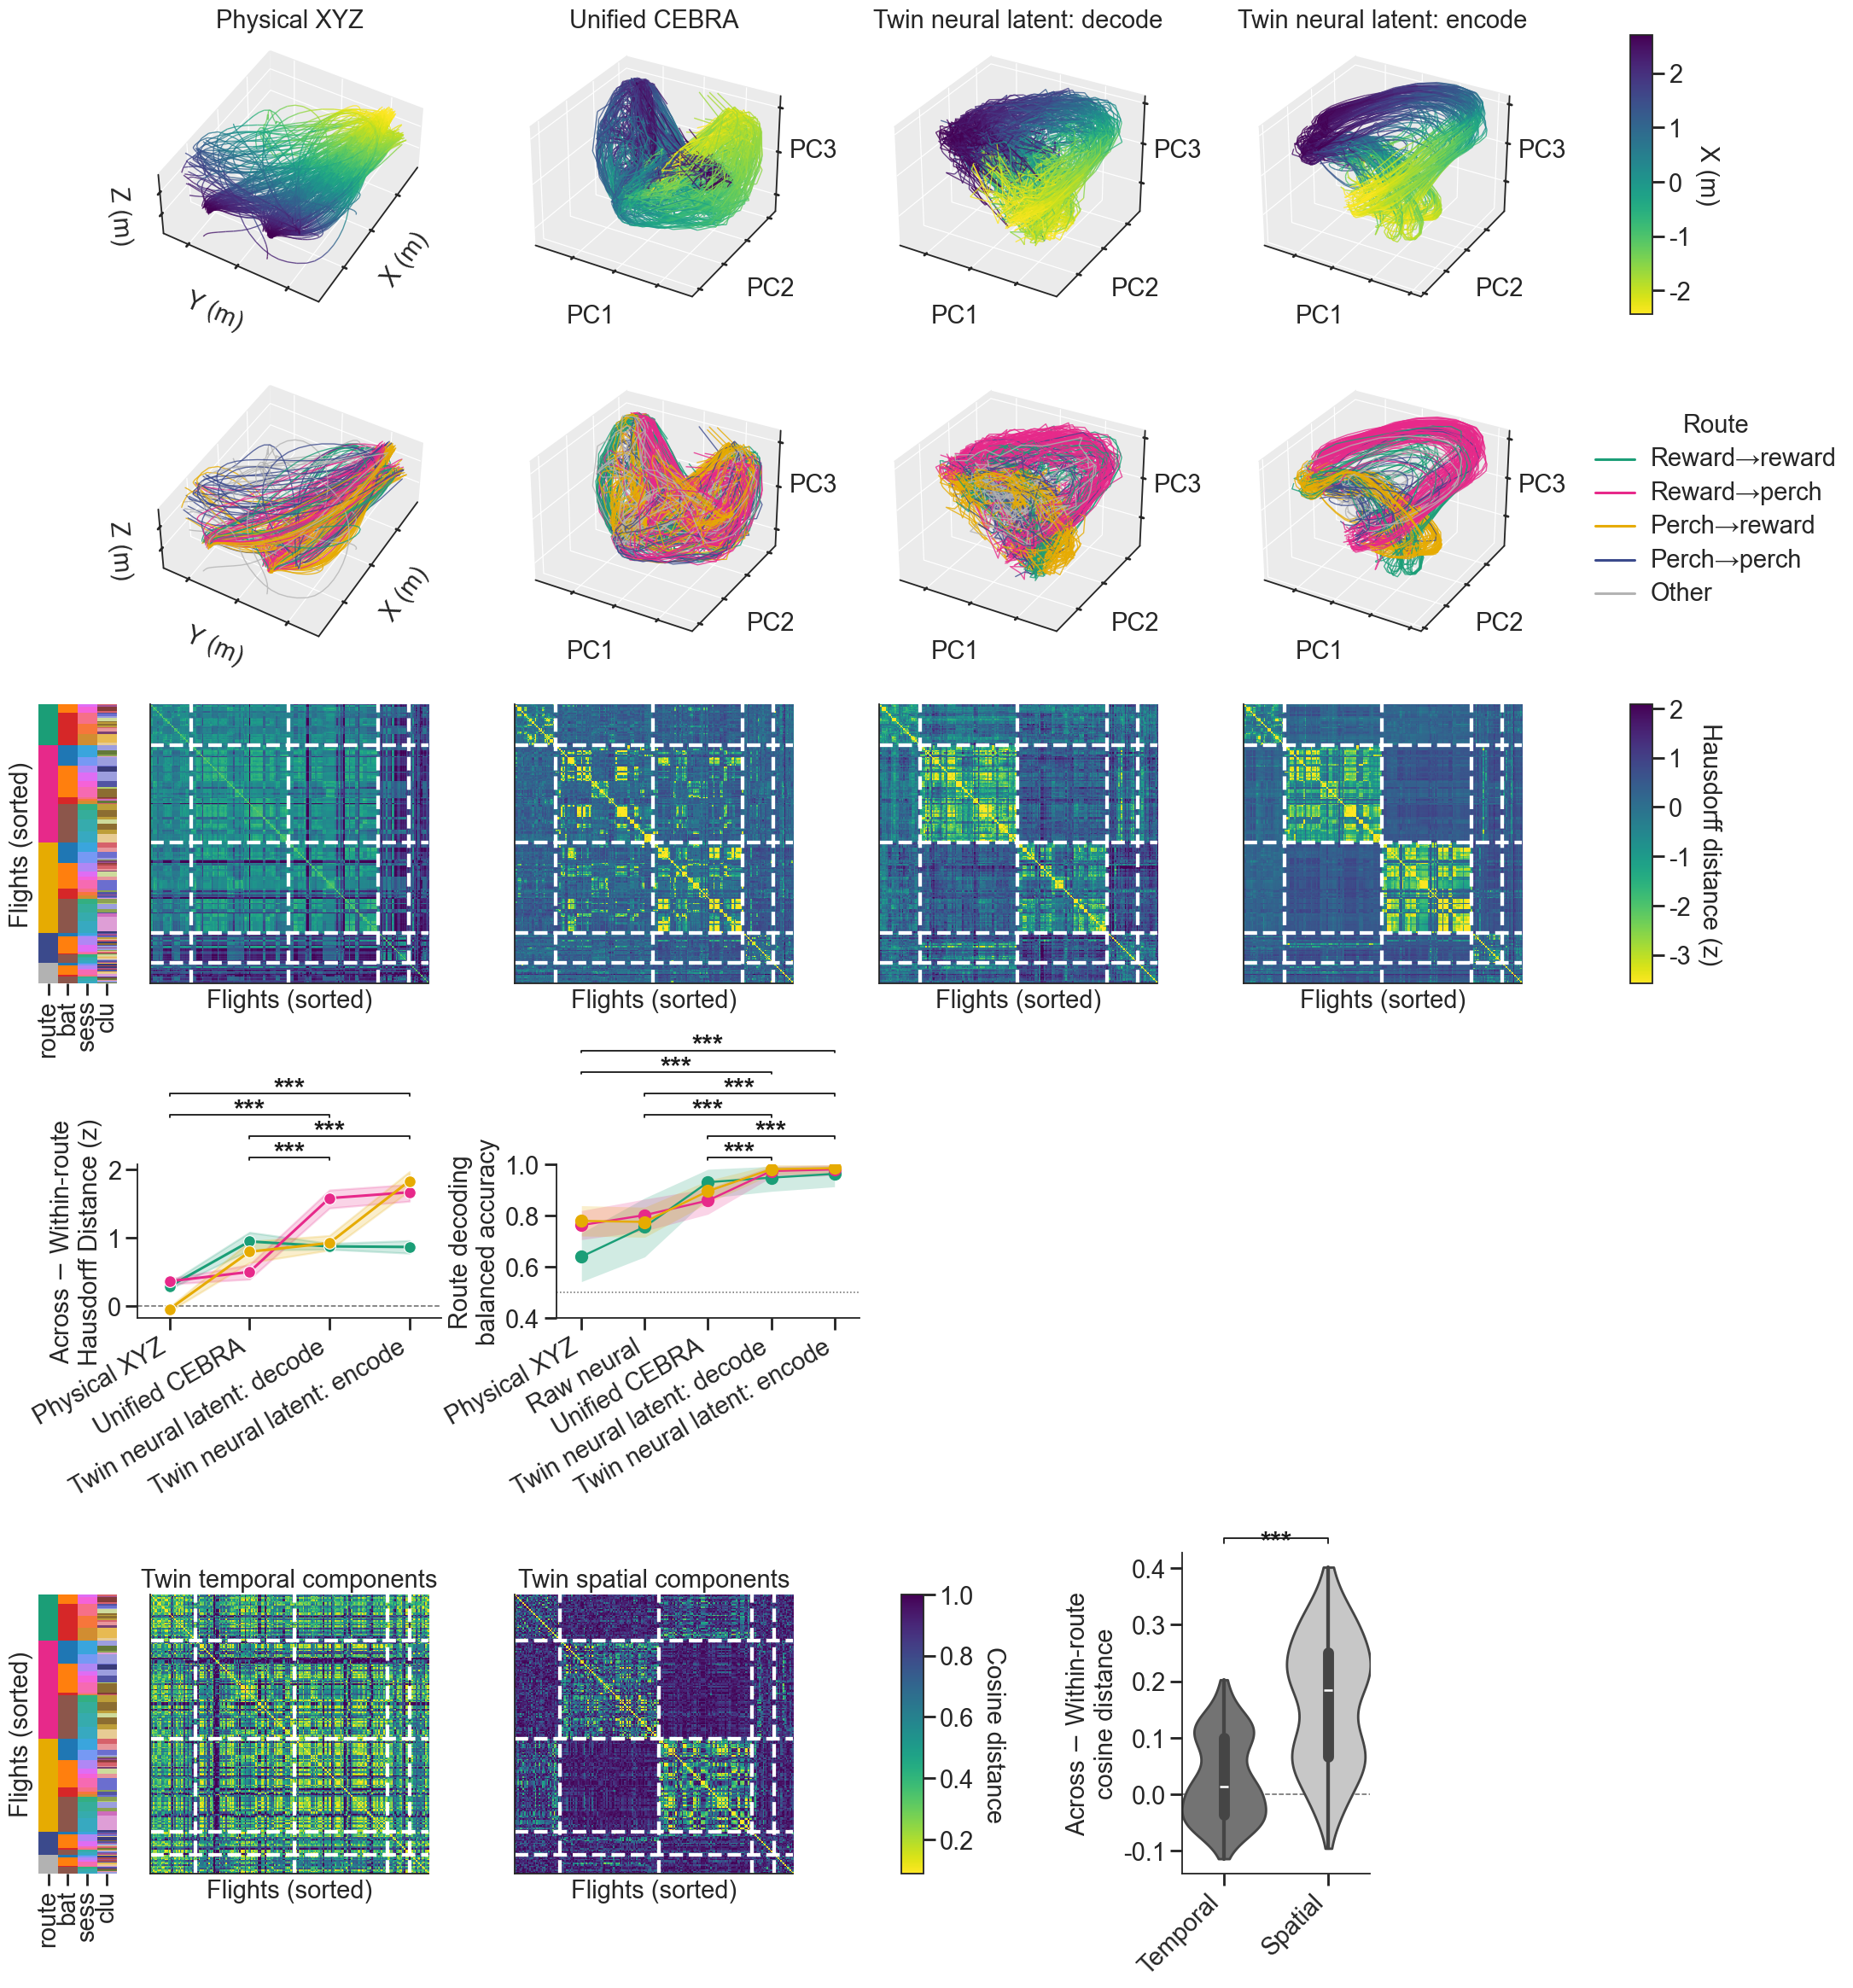

Fig 2 row 4 (indoor, RR/RP/PR) — mean across−within-route Hausdorff distance (z) & one-vs-rest balanced decoding accuracy (chance 0.5):
                            mean_align  mean_bal_acc
space                                               
Physical XYZ                     0.189         0.728
Twin neural latent: decode       1.195         0.969
Twin neural latent: encode       1.589         0.977
Unified CEBRA                    0.696         0.896
Raw neural                         NaN         0.779
Pooled paired comparisons (Twin decode/encode vs Physical XYZ / Unified CEBRA / Raw neural):
  Twin neural latent: decode vs Physical XYZ    align p=1.75e-32   decode p=5.4e-28
  Twin neural latent: decode vs Unified CEBRA   align p=3.45e-14   decode p=1.03e-07
  Twin neural latent: decode vs Raw neural      align p=nan   decode p=2.54e-14
  Twin neural latent: encode vs Physical XYZ    align p=7.57e-33   decode p=1.06e-29
  Twin neural latent: encode vs Unified CEBRA   align p=2.97e-28  

In [259]:
# === Figure 2: physical / CEBRA / Twin embeddings as 3-D trajectories ===
# internals.ipynb style: every flight is one connected 3-D polyline (no bare
# points). Columns: Physical XYZ, Unified CEBRA (3-D), Twin latent (PCA-3
# of the 64-d latent). Top row colours each trajectory by the animal's
# x-coordinate (continuous); row 2 by flight route (categorical); row 3 shows the
# RSA matrices; row 4 quantifies cross-bat route alignment two ways (see below).
from sklearn.decomposition import PCA

MAX_FLIGHTS = 250
_rng = np.random.default_rng(seed)

# --- Physical XYZ + Twin latent: per-flight trajectories from `emb` (indoor) ---
_ind_pt = np.array([ph.is_indoor(s) for s in emb['session']])
# Shared PCA-3: fit ONE basis on encode+decode latents (concatenated) so the two
# Twin branches live in the exact same PC space (PC1/2/3) and are comparable.
# (same fit_shared_latent_pca functionality as ED Fig 4, on a different subset).
_pca3 = nh.fit_shared_latent_pca(emb['latent'][_ind_pt], emb['latent_decode'][_ind_pt], n_components=3, random_state=seed)
_lat3 = _pca3.transform(emb['latent'])
_latd3 = _pca3.transform(emb['latent_decode'])
_colx = emb['xyz'][:, 0]  # raw metres, matching the physical x-axis
_key = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))

phys_trajs, lat_trajs, latd_trajs, xcol, routes = [], [], [], [], []
for k in np.unique(_key[_ind_pt]):
    m = np.where(_key == k)[0]
    o = m[np.argsort(emb['rel_t'][m])]
    phys_trajs.append(emb['xyz'][o]); lat_trajs.append(_lat3[o]); latd_trajs.append(_latd3[o])
    xcol.append(_colx[o]); routes.append(int(emb['route'][o[0]]))

# --- Unified CEBRA: per-flight 3-D embeddings from uni_te (guarded on CEBRA) ---
cebra_trajs, cebra_xcol, cebra_routes = [], [], []
if cebra_frechet is not None:
    _tmp, _cx, _cs = [], [], []
    for s in session_names:
        if not ph.is_indoor(s):
            continue
        rew, perch = get_target_locs(s)
        for embp, f in uni_te[s]:
            pos = f['pos']
            oc = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
            dc = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
            _tmp.append((np.asarray(embp), ph.route_id(oc, dc)))
            _cx.append(pos[:, 0]); _cs.append(np.full(len(pos), s))
    _zx = np.concatenate(_cx)  # raw metres
    _parts = np.split(_zx, np.cumsum([len(x) for x in _cx])[:-1])
    # PCA the CEBRA outputs to 3-D (best model has output_dimension > 3), same as
    # the Twin latent: fit on all indoor CEBRA points, transform per flight.
    if _tmp:
        _cpca = PCA(n_components=3, random_state=seed).fit(np.vstack([e for e, _ in _tmp]))
        _tmp = [(_cpca.transform(e), r) for e, r in _tmp]
    for (embp, r), zxi in zip(_tmp, _parts):
        cebra_trajs.append(embp); cebra_xcol.append(zxi); cebra_routes.append(r)


def _subsample(*lists, n=MAX_FLIGHTS):
    L = len(lists[0])
    if L <= n:
        return lists
    sel = np.sort(_rng.choice(L, n, replace=False))
    return tuple([lst[i] for i in sel] for lst in lists)


phys_trajs, lat_trajs, latd_trajs, xcol, routes = _subsample(phys_trajs, lat_trajs, latd_trajs, xcol, routes)
if cebra_trajs:
    cebra_trajs, cebra_xcol, cebra_routes = _subsample(cebra_trajs, cebra_xcol, cebra_routes)

# --- Columns in the requested order (CEBRA in the middle when available) ---
columns = [('Physical XYZ', phys_trajs, xcol, routes, ('x (m)', 'y (m)', 'z (m)'))]
if cebra_trajs:
    columns.append(('Unified CEBRA', cebra_trajs, cebra_xcol, cebra_routes,
                    ('PC1', 'PC2', 'PC3')))
columns.append(('Twin neural latent: decode', latd_trajs, xcol, routes, ('PC1', 'PC2', 'PC3')))
columns.append(('Twin neural latent: encode', lat_trajs, xcol, routes, ('PC1', 'PC2', 'PC3')))

ncol = len(columns)
NROW = 6          # rows 1-2: 3-D trajectories, 3: RSA matrices, 4: route-alignment,
                  # 5: deliberate spacer (row 4's brackets need the room), 6: DMD
xvlim = tuple(np.nanpercentile(np.concatenate(xcol), [2, 98]))
fig2 = plt.figure(figsize=(4.8 * ncol, 27.0))
top_axes, bot_axes, sm, LBL = [], [], None, 15


# Per-column 3-D view orientation (both rows of a column share one view):
#   Physical XYZ  -> 90 deg about z (y to front, x right) + slight top-down tilt
#   Unified CEBRA -> default view (no rotation)
#   Twin    -> default view for now (previous figure-8 view kept in _set_view to revert)
def _set_view(ax, col):
    if col == 'Physical XYZ':
        ax.view_init(elev=ax.elev + 15, azim=ax.azim + 90)   # y front, x right, more top-down
    elif col.startswith('Twin'):
        pass   # default view for now; previous figure-8 view (to revert): view_init(elev=-25.5, azim=130.6)


def _ref_grid(ax):
    """White reference gridlines on grey panes (applied to every 3-D panel)."""
    from matplotlib.ticker import MaxNLocator
    ax.xaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.zaxis.set_major_locator(MaxNLocator(3))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)
    ax.grid(True)


for j, (title, trajs, xc, rt, axl) in enumerate(columns):
    ax0 = fig2.add_subplot(NROW, ncol, j + 1, projection='3d'); top_axes.append(ax0)
    sm = ph.plot_trajectories_3d(ax0, trajs, xc, cmap='viridis_r', vlim=xvlim, lw=0.9, show_endpoints=False)
    _set_view(ax0, title); _ref_grid(ax0)
    ax0.set_title(title, fontsize=LBL)
    _zpad = -4 if axl[2] == 'PC3' else None   # tuck the PC3 z-label in toward the axes
    ax0.set_xlabel(axl[0], fontsize=LBL); ax0.set_ylabel(axl[1], fontsize=LBL); ax0.set_zlabel(axl[2], fontsize=LBL, labelpad=_zpad)
    ax1 = fig2.add_subplot(NROW, ncol, ncol + j + 1, projection='3d'); bot_axes.append(ax1)
    ph.plot_trajectories_3d(ax1, trajs, rt, categorical=True, cat_colors=ph.ROUTE_COLORS, lw=0.9, show_endpoints=False)
    _set_view(ax1, title); _ref_grid(ax1)
    ax1.set_xlabel(axl[0], fontsize=LBL); ax1.set_ylabel(axl[1], fontsize=LBL); ax1.set_zlabel(axl[2], fontsize=LBL, labelpad=_zpad)
    if title == 'Physical XYZ':
        _box = tuple(np.vstack([np.asarray(t) for t in trajs]).max(0)
                     - np.vstack([np.asarray(t) for t in trajs]).min(0))
        ax0.set_box_aspect(_box); ax1.set_box_aspect(_box)
    if j == 0:
        # tuck the z-axis label inward; the row label sits outside (left of) it
        ax0.set_zlabel('z (m)', fontsize=LBL, labelpad=-4)
        ax1.set_zlabel('z (m)', fontsize=LBL, labelpad=-4)

# Dedicated colorbar axes to the right of the top row: unlike colorbar(ax=top_axes),
# this steals no width from the panels, so the three columns stay aligned on both rows.
_ptr = top_axes[-1].get_position()
_cax = fig2.add_axes([_ptr.x1 + 0.06, _ptr.y0, 0.012, _ptr.height])
cb = fig2.colorbar(sm, cax=_cax)
cb.set_label('x (m)', fontsize=LBL, rotation=270, labelpad=22)
handles = [plt.Line2D([], [], color=ph.ROUTE_COLORS[k], lw=2, label=ph.ROUTE_LABELS[k].replace('rew', 'reward'))
           for k in list(range(1, len(ph.ROUTE_LABELS))) + [0]]
# offset right (past the PC3 z-axis label) so the legend doesn't overlap it
_leg = bot_axes[-1].legend(handles=handles, title='route', loc='center left',
                     bbox_to_anchor=(1.2, 0.5), frameon=False, fontsize=LBL)
_leg.get_title().set_fontsize(LBL)

# --- Row 3: RSA matrices, one directly below each column above ---
from matplotlib.colors import to_rgb
_route_pal = ph.route_palette()
_n_clu = int(rsa_meta['cluster'].max()) + 1
_clu_pal = list(ph.flight_cluster_palette(range(max(_n_clu, 3))).values())
_sess_pal = list(ph.session_palette(sorted(session_names)).values())
_bars = np.zeros((len(rsa_order), 4, 3))                          # route, bat, sess, clu (indoor only)
for _i in range(len(rsa_order)):
    _bars[_i, 0] = to_rgb(_route_pal[int(rsa_meta['route'][_i])])
    _bars[_i, 1] = to_rgb(BAT_PALETTE.get(rsa_meta['bat'][_i], '0.5'))
    _bars[_i, 2] = to_rgb(_sess_pal[int(rsa_meta['session'][_i])])
    _bars[_i, 3] = to_rgb(_clu_pal[int(rsa_meta['cluster'][_i]) % len(_clu_pal)])
# Each space's Hausdorff distance is z-scored within the space, so all four matrices share one
# colour scale. Percentiles over off-diagonal values (the zero-distance diagonal
# saturates at the minimum).
_offmask = ~np.eye(len(rsa_order), dtype=bool)
_off = np.concatenate([M[_offmask] for M in rsa_mats.values()])
_vmin, _vmax = np.percentile(_off, [1, 99])
# route-block boundaries: rows where route changes under the shared ordering (indoor only)
_rt = rsa_meta['route']
_route_bnd = 1 + np.where(_rt[1:] != _rt[:-1])[0]
rsa_axes, _im = [], None
for j, (name, _fn) in enumerate(rsa_conditions):
    axr = fig2.add_subplot(NROW, ncol, 2 * ncol + j + 1); rsa_axes.append(axr)
    _im = axr.imshow(rsa_mats[name], vmin=_vmin, vmax=_vmax, cmap='viridis_r', interpolation='nearest')
    axr.set_xticks([]); axr.set_yticks([])
    axr.set_xlabel('Flights (sorted)', fontsize=LBL)
    for _b in _route_bnd:                       # white dashed dividers between flight types (Fig 4 style)
        axr.axhline(_b - 0.5, color='w', ls='--', lw=2.8)
        axr.axvline(_b - 0.5, color='w', ls='--', lw=2.8)
    if j == 0:
        # barber-pole strips (route, bat, session, cluster) + row label
        bax = axr.inset_axes([-0.40, 0.0, 0.28, 1.0])   # widened to fit the enlarged strip labels
        bax.imshow(_bars, aspect='auto', interpolation='nearest')
        bax.set_xticks(range(4)); bax.set_xticklabels(['route', 'bat', 'sess', 'clu'],
                                                      rotation=90, fontsize=LBL)
        bax.set_yticks([]); bax.set_ylabel('Flights (sorted)', fontsize=LBL)
        for _sp in bax.spines.values():
            _sp.set_visible(False)

# Shared RSA Hausdorff-distance colourbar to the right of the last matrix (mirrors the
# x colourbar above); all four spaces share it (each is z-scored within its own space).
_rp = rsa_axes[-1].get_position()
_rcax = fig2.add_axes([_rp.x1 + 0.06, _rp.y0, 0.012, _rp.height])
_rcb = fig2.colorbar(_im, cax=_rcax); _rcb.set_label('Hausdorff distance (z)', fontsize=LBL, rotation=270, labelpad=24)

# --- Row 4: cross-bat route alignment quantified two ways, INDOOR flights only, over
#     routes RR / RP / PR (drop 'other' and 'perch->perch'). Two panels, each the width
#     of one RSA matrix above (together half a row): x = embedding space, hue = route
#     (shared route palette + the route legend above; no new legend).
#   (A) across-route minus within-route Hausdorff distance (z), so route structure is
#       POSITIVE (same-route flights nearer than different-route ones). Per route = that
#       route's cross-"L" mean (its pairs with the OTHER routes only) minus the RSA
#       block-diagonal mean (within-route flight pairs). Per flight = (L-row mean) -
#       (block-row mean).
#   (B) route decoded from the time-averaged representation with a basic RBF SVC. The
#       shared-latent / physical spaces use one classifier over all indoor flights; the
#       extra "Raw neural" space decodes from time-averaged RAW spike counts (no
#       sqrt transform) fit PER SESSION
#       (neuron spaces differ), then pooled across flights the same way.
#   Brackets (both panels): Twin decode & encode vs Physical XYZ and Unified CEBRA,
#   pooling all pictured RR/RP/PR flights (paired Wilcoxon for r; McNemar for accuracy).
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar

_KEEP_ROUTES = [1, 2, 3]                            # rew->rew, rew->perch, perch->rew
_route_pal = ph.route_palette()                    # {route_id: rgb}, shared with rows above
_route_arr = rsa_meta['route']
_V = np.where(np.isin(_route_arr, _KEEP_ROUTES))[0]   # RR/RP/PR (all indoor)
_rv = _route_arr[_V]
_align_spaces = [n for n, _ in rsa_conditions]     # Physical XYZ, [CEBRA], decode, encode
_getter = dict(rsa_conditions)
_align_pos = {n: i for i, n in enumerate(_align_spaces)}
_HD, _HE = f'{OUR_MODEL} neural latent: decode', f'{OUR_MODEL} neural latent: encode'
_refs = [n for n in ('Physical XYZ', 'Unified CEBRA') if n in _align_spaces]
_MIN_PER_CLASS = 3

# (A) across - within-route Hausdorff distance (z), per flight (indoor, RR/RP/PR)
_arows = []
for _name in _align_spaces:
    _S = rsa_mats[_name][np.ix_(_V, _V)]
    for _p in range(len(_V)):
        _R = _rv[_p]
        _wi = (_rv == _R).copy(); _wi[_p] = False          # block row: same-route pairs
        _ac = _rv != _R                                     # L row: pairs with other routes
        if _wi.sum() < 1 or _ac.sum() < 1:
            continue
        _arows.append(dict(space=_name, route=int(_R), flight=int(_V[_p]),
                           pos=_align_pos[_name], metric=float(_S[_p, _ac].mean() - _S[_p, _wi].mean())))
align_df = pd.DataFrame(_arows)


def _binary_oof(X, ybin):
    """Out-of-fold predictions from a basic fixed-C RBF SVC for a one-vs-rest (yes/no)
    route label. Needs >= _MIN_PER_CLASS of each class; returns predictions or None."""
    cnt = np.bincount(ybin, minlength=2)
    if cnt.min() < _MIN_PER_CLASS:
        return None
    ns = int(min(5, cnt.min()))                          # <= members in the smaller class
    cv = StratifiedKFold(n_splits=ns, shuffle=True, random_state=seed)
    clf = Pipeline([('scaler', StandardScaler()),
                    ('svc', SVC(kernel='rbf', class_weight='balanced', C=1.0))])
    return cross_val_predict(clf, X, ybin, cv=cv)


# (B) route decoding: one binary (yes/no) one-vs-rest classifier PER route (RR, RP, PR),
# so chance is 50% (balanced accuracy) and a session missing one of the three routes can
# still contribute to the other two. Shared/physical spaces pool all indoor flights; Raw
# neural is fit per session (per route) then its predictions pooled across flights.
_drows = []
for _name in _align_spaces:
    _g = _getter[_name]
    _X = np.vstack([np.asarray(_g(rsa_order[i]), float).mean(0) for i in _V])
    for _R in _KEEP_ROUTES:
        _yb = (_rv == _R).astype(int)
        _pred = _binary_oof(_X, _yb)
        if _pred is None:
            continue
        for _j in range(len(_V)):
            _drows.append(dict(space=_name, route=_R, flight=int(_V[_j]),
                               y_true=int(_yb[_j]), y_pred=int(_pred[_j])))
_keys = [rsa_order[i] for i in _V]
_sess = np.array([rsa_recs[k]['session'] for k in _keys])
for _sn in sorted(set(_sess.tolist())):
    _sel = np.where(_sess == _sn)[0]
    _Xs = np.vstack([np.asarray(rsa_recs[_keys[i]]['spike'], float).mean(0) for i in _sel])
    _rsel = _rv[_sel]
    for _R in _KEEP_ROUTES:
        _yb = (_rsel == _R).astype(int)
        _pred = _binary_oof(_Xs, _yb)
        if _pred is None:
            continue
        for _j in range(len(_sel)):
            _drows.append(dict(space='Raw neural', route=_R, flight=int(_V[_sel[_j]]),
                               y_true=int(_yb[_j]), y_pred=int(_pred[_j])))
decode_df = pd.DataFrame(_drows)
decode_df['correct'] = (decode_df['y_true'] == decode_df['y_pred']).astype(float)
_decode_spaces = list(_align_spaces)                       # Raw neural sits between Physical & CEBRA
_decode_spaces.insert(_decode_spaces.index('Physical XYZ') + 1, 'Raw neural')
_decode_pos = {n: i for i, n in enumerate(_decode_spaces)}


def _bacc_ci(yt, yp, n_boot=1000):
    """Balanced accuracy + class-stratified bootstrap 95% CI (chance = 0.5)."""
    yt, yp = np.asarray(yt), np.asarray(yp)
    ba = balanced_accuracy_score(yt, yp)
    _i0, _i1 = np.where(yt == 0)[0], np.where(yt == 1)[0]
    _rng = np.random.default_rng(seed)
    _bs = np.array([balanced_accuracy_score(
        yt[_s], yp[_s]) for _s in (np.concatenate([_rng.choice(_i0, len(_i0)),
                                                    _rng.choice(_i1, len(_i1))]) for _ in range(n_boot))])
    return ba, float(np.percentile(_bs, 2.5)), float(np.percentile(_bs, 97.5))


_bacc_rows = []
for (_sp, _R), _sub in decode_df.groupby(['space', 'route']):
    if _sub['y_true'].nunique() < 2:
        continue
    _ba, _lo, _hi = _bacc_ci(_sub['y_true'].values, _sub['y_pred'].values)
    _bacc_rows.append(dict(space=_sp, route=int(_R), pos=_decode_pos[_sp], bal=_ba, lo=_lo, hi=_hi))
bacc_df = pd.DataFrame(_bacc_rows)


def _pool_wilcoxon(a, b):                          # paired over pooled flights (alignment)
    w = align_df.pivot_table(index='flight', columns='space', values='metric')
    if a not in w or b not in w:
        return np.nan
    d = w[[a, b]].dropna()
    if len(d) < 2 or np.all(d[a].values == d[b].values):
        return np.nan
    return float(wilcoxon(d[a].values, d[b].values).pvalue)


def _pool_mcnemar(a, b):                           # paired binary over pooled (flight, route) tasks
    w = decode_df.pivot_table(index=['flight', 'route'], columns='space', values='correct')
    if a not in w or b not in w:
        return np.nan
    d = w[[a, b]].dropna()
    n01 = int(((d[a] == 0) & (d[b] == 1)).sum()); n10 = int(((d[a] == 1) & (d[b] == 0)).sum())
    if n01 + n10 == 0:
        return np.nan
    return float(mcnemar([[0, n01], [n10, 0]], exact=(n01 + n10) < 25).pvalue)


def _style_brackets(ax, spaces, posmap, pfun, *, chance=None, zeroline=False, fix_ylim=None):
    """Shared styling + Twin decode/encode-vs-reference brackets for a half-matrix
    panel (references: Physical XYZ, Unified CEBRA, and -- decoding only -- Raw neural).
    Brackets float in the margin ABOVE the axes (the panels are shortened to leave room);
    returns the axes-fraction y at which the title should sit, clear of the brackets."""
    if zeroline:
        ax.axhline(0, color='0.4', lw=1, ls='--', zorder=0)
    if chance is not None:
        ax.axhline(chance, color='0.4', lw=1, ls=':', zorder=0)
    ax.set_xticks(range(len(spaces)))
    ax.set_xticklabels(spaces, rotation=30, ha='right', fontsize=LBL)   # match the axis label
    ax.set_xlim(-0.4, len(spaces) - 0.6)
    if fix_ylim is not None:
        ax.set_ylim(*fix_ylim)
    _brefs = [n for n in ('Physical XYZ', 'Unified CEBRA', 'Raw neural') if n in posmap]
    _comps = sorted([(r, t) for t in (_HD, _HE) if t in posmap for r in _brefs],
                    key=lambda c: -abs(posmap[c[1]] - posmap[c[0]]))   # longest span first (top)
    _step = 0.14                                           # bracket spacing (further apart)
    _base = 1.03 + (len(_comps) - 1) * _step               # brackets stack in the margin above
    for _lvl, (_r, _t) in enumerate(_comps):
        ph.sig_bracket(ax, posmap[_r], posmap[_t], pfun(_r, _t), level=_lvl,
                       base=_base, step=_step, star_gap=-0.05)   # stars close to their bracket (match Fig 4)
    return _base + 0.12


# Both row-4 panels are shortened (anchored at their bottom) so the brackets/asterisks
# have room above them, in the gap below the RSA matrices.
_PANEL_FRAC = 0.55


def _shrink(ax):
    _p = ax.get_position()
    ax.set_position([_p.x0, _p.y0, _p.width, _p.height * _PANEL_FRAC])


# Panel A: alignment -- per-flight mean +/- 95% CI, x=embedding space, hue=route.
_axA = fig2.add_subplot(NROW, ncol, 3 * ncol + 1)      # row 4, col 1 (width of one matrix)
_shrink(_axA)
_a_rts = sorted(align_df['route'].unique())
sns.lineplot(data=align_df, x='pos', y='metric', hue='route', hue_order=_a_rts,
             palette={r: _route_pal[r] for r in _a_rts}, marker='o', err_style='band',
             legend=False, ax=_axA)
_style_brackets(_axA, _align_spaces, _align_pos, _pool_wilcoxon, zeroline=True)
_axA.set_ylabel('Across $-$ Within-route\nHausdorff Distance (z)', fontsize=LBL)
_axA.set_xlabel('')

# Panel B: decoding -- one-vs-rest balanced accuracy per route (chance 0.5), line +
# bootstrap 95% CI per route across embedding spaces. Nudged right for a wider gap.
_axB = fig2.add_subplot(NROW, ncol, 3 * ncol + 2)      # row 4, col 2 (next matrix width)
_shrink(_axB)
_pB = _axB.get_position(); _axB.set_position([_pB.x0 + 0.03, _pB.y0, _pB.width, _pB.height])
for _R in sorted(bacc_df['route'].unique()):
    _sub = bacc_df[bacc_df['route'] == _R].sort_values('pos')
    _axB.plot(_sub['pos'], _sub['bal'], marker='o', lw=1.6, color=_route_pal[_R], zorder=3)
    _axB.fill_between(_sub['pos'], _sub['lo'], _sub['hi'], color=_route_pal[_R], alpha=0.2, lw=0)
_style_brackets(_axB, _decode_spaces, _decode_pos, _pool_mcnemar, chance=0.5, fix_ylim=(0.4, 1.0))
_axB.set_ylabel('Route decoding\nbalanced accuracy', fontsize=LBL)
_axB.set_xlabel('')

# --- Row 5: per-flight DMD of the latent -- RSA over the eigenvalue spectrum (col 1, with the
# Fig 2c barber pole) and over the 2nd oscillatory spatial mode (col 2), then the route effect
# size for both (col 3). Data: fig2_dmd_data cell.
_d_off = ~np.eye(len(dmd_order), dtype=bool)
_d_all = np.concatenate([dmd_res[_n][_k][_d_off] for _n in dmd_res for _k in ('D_mode', 'D_eig')])
_dvmin, _dvmax = np.percentile(_d_all, [1, 99])         # one scale for every DMD matrix
_d_sorted = _dmd_route[dmd_order]
_d_bnd = 1 + np.where(_d_sorted[1:] != _d_sorted[:-1])[0]


def _dmd_row_matrix(ax, D, barber=False):
    """DMD RSA in the Fig 2c order: viridis_r, no ticks, white dashed route dividers."""
    _imd = ax.imshow(D[dmd_order][:, dmd_order], vmin=_dvmin, vmax=_dvmax,
                     cmap='viridis_r', interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel('Flights (sorted)', fontsize=LBL)
    for _b in _d_bnd:
        ax.axhline(_b - 0.5, color='w', ls='--', lw=2.8)
        ax.axvline(_b - 0.5, color='w', ls='--', lw=2.8)
    if barber:                                  # identical strip/geometry to row 3
        _bx = ax.inset_axes([-0.40, 0.0, 0.28, 1.0])
        _bx.imshow(_dmd_bars, aspect='auto', interpolation='nearest')
        _bx.set_xticks(range(4))
        _bx.set_xticklabels(['route', 'bat', 'sess', 'clu'], rotation=90, fontsize=LBL)
        _bx.set_yticks([]); _bx.set_ylabel('Flights (sorted)', fontsize=LBL)
        for _sp in _bx.spines.values():
            _sp.set_visible(False)
    return _imd


_axD1 = fig2.add_subplot(NROW, ncol, 5 * ncol + 1)     # eigenvalue RSA (+ barber pole)
_axD2 = fig2.add_subplot(NROW, ncol, 5 * ncol + 2)     # spatial-mode RSA
_axD3 = fig2.add_subplot(NROW, ncol, 5 * ncol + 3)     # route effect size
_imD = _dmd_row_matrix(_axD1, dmd_res[OUR_MODEL]['D_eig'], barber=True)
_dmd_row_matrix(_axD2, dmd_res[OUR_MODEL]['D_mode'])
_axD1.set_title(f'{OUR_MODEL} temporal components', fontsize=LBL)
_axD2.set_title(f'{OUR_MODEL} spatial components', fontsize=LBL)
fig2.canvas.draw()
# Half-row spacer rather than a whole one: lift row 6, and let save_fig's tight bbox crop the
# whitespace this frees at the bottom.
_DMD_LIFT = 0.045
for _a in (_axD1, _axD2, _axD3):
    _p = _a.get_position()
    _a.set_position([_p.x0, _p.y0 + _DMD_LIFT, _p.width, _p.height])
# Align the two DMD matrices (and hence the barber pole, an inset of the first) exactly with
# panel C's matrices: same x0/width/height, own y.
for _ax, _ref in ((_axD1, rsa_axes[0]), (_axD2, rsa_axes[1])):
    _pr, _pa = _ref.get_position(), _ax.get_position()
    _ax.set_position([_pr.x0, _pa.y0, _pr.width, _pr.height])
_pD2 = _axD2.get_position()

# violin: Across - Within route distance per flight, both RSAs x both latents
_pD3 = _axD3.get_position()            # taller than the matrices, same baseline; pushed
_axD3.set_position([_pD3.x0 + 0.175, _pD2.y0,          # clear of the widened colourbar
                    _pD3.width * 0.62, _pD2.height * 1.15])
_d_names = [OUR_MODEL]
_d_cats, _d_vals, _d_pal = [], {}, {}
for _n in _d_names:
    for _kind, _klab in (('eig', 'eigen'), ('mode', 'modes')):   # temporal first, as in the matrices
        _c = f'{_n} {_klab}'
        _d_cats.append(_c)
        _d_vals[_c] = np.asarray(dmd_res[_n][f'wa_{_kind}']['aw'], float)
        _d_pal[_c] = '0.78' if _kind == 'mode' else '0.45'
_d_long = pd.DataFrame([dict(group=_c, value=_v) for _c in _d_cats
                        for _v in _d_vals[_c][np.isfinite(_d_vals[_c])]])
ph.cat_violin(_axD3, _d_long, 'group', 'value', _d_cats, _d_pal)
_axD3.axhline(0, color='0.4', lw=1, ls='--', zorder=0)
_axD3.set_xlabel('')
_axD3.set_ylabel('Across $-$ Within-route\ncosine distance', fontsize=LBL)
_axD3.set_xticks(range(len(_d_cats)))
_axD3.set_xticklabels(['Spatial' if _c.endswith('modes') else 'Temporal' for _c in _d_cats],
                      rotation=45, ha='right', fontsize=LBL)
_axD3.set_xlim(-0.4, len(_d_cats) - 0.6)
# brackets: modes vs eigenvalues within each latent (paired over flights), Fig 2 style
_d_step = 0.14
_d_pairs = [(f'{_n} eigen', f'{_n} modes') for _n in _d_names]
_d_base = 1.03 + (len(_d_pairs) - 1) * _d_step
# Shared DMD colourbar immediately to the right of the mode RSA, anchored to the matrices'
# vertical extent (not the shortened violin, which is offset further right to clear it).
_dcax = fig2.add_axes([_pD2.x1 + 0.06, _pD2.y0, 0.012, _pD2.height])   # matches row 3's bar
_dcb = fig2.colorbar(_imD, cax=_dcax)
_dcb.set_label('Cosine distance', fontsize=LBL, rotation=270, labelpad=24)

_dmd_row_p = {}
for _lvl, (_ca, _cb) in enumerate(_d_pairs):
    _m = np.isfinite(_d_vals[_ca]) & np.isfinite(_d_vals[_cb])
    _pv = _wil(_d_vals[_ca][_m], _d_vals[_cb][_m], alternative='two-sided').pvalue
    _dmd_row_p[_ca.rsplit(' ', 1)[0]] = (_pv, int(_m.sum()))
    # star_gap is a fraction of the axes height, and this panel is ~2.1x taller than D/E,
    # so -0.05 there == -0.024 here; matches their absolute star-to-bracket spacing.
    ph.sig_bracket(_axD3, _d_cats.index(_ca), _d_cats.index(_cb), _pv, level=_lvl,
                   base=_d_base, step=_d_step, star_gap=-0.024)
print('\nFig 2 row 5 (DMD) - across minus within route cosine distance, per flight:')
print('  ' + '  |  '.join('%s %s median %+.4f' % (_n, _k, float(np.nanmedian(dmd_res[_n][f'wa_{_k}']['aw'])))
                          for _n in dmd_res for _k in ('mode', 'eig')))
print('  modes vs eigenvalues (paired Wilcoxon over flights): '
      + ', '.join('%s P=%.3g (n=%d)' % (_n, *_dmd_row_p[_n]) for _n in _d_names))

# Enlarge every text element by 2 pt (titles, axis + colourbar labels, tick labels,
# legend, barber-pole and significance text). Run capitalize_labels first (it re-issues
# some categorical tick labels) so the bump is the last word, then save uncapitalized.
from matplotlib.text import Text as _Text
_FS_BUMP = 4   # +2 pt (base) then another +2 pt
ph.capitalize_labels(fig2)
fig2.canvas.draw()
_bumped = set()
for _t in fig2.findobj(_Text):
    if id(_t) in _bumped:
        continue
    _bumped.add(id(_t))
    _s = _t.get_fontsize()
    if _s:
        _t.set_fontsize(_s + _FS_BUMP)
ph.save_fig(fig2, 'fig2_embeddings', capitalize=False); plt.show()

# summary: mean across-within alignment / one-vs-rest balanced accuracy per space + p-values
print('Fig 2 row 4 (indoor, RR/RP/PR) — mean across−within-route Hausdorff distance (z) '
      '& one-vs-rest '
      'balanced decoding accuracy (chance 0.5):')
_al = align_df.groupby('space')['metric'].mean().rename('mean_align')
_de = bacc_df.groupby('space')['bal'].mean().rename('mean_bal_acc')
print(pd.concat([_al, _de], axis=1).round(3).to_string())
print(f'Pooled paired comparisons ({OUR_MODEL} decode/encode vs Physical XYZ / Unified '
      'CEBRA / Raw neural):')
_cmp_refs = _refs + (['Raw neural'] if 'Raw neural' in _decode_pos else [])
for _t in (_HD, _HE):
    for _r in _cmp_refs:
        print(f'  {_t:18s} vs {_r:14s}  align p={_pool_wilcoxon(_r, _t):.3g}   '
              f'decode p={_pool_mcnemar(_r, _t):.3g}')

**Figure 2 | The Twin latent embedding warps physical space to emphasize flight-route identity and aligns hippocampal representation geometry across animals.**
Four representations are compared column-by-column throughout: true 3-D position (Physical XYZ), the `Unified CEBRA' latent, and the digital Twin 64-D neural latent read out in decode mode and in encode mode. (A–B) Held-out flights rendered as connected 3-D trajectories. CEBRA and Twin latents are the raw 64-D embeddings projected to three dimensions by PCA (a single shared PCA basis fit jointly on the Twin encode and decode latents; CEBRA fit separately). Trajectories are colored by the bat's instantaneous x-coordinate (A, meters) and by flight route (B; route = origin$\to$destination endpoint class). Unlike physical space and the CEBRA embedding, the Twin latent segregates flights primarily by route identity and not simply instantaneous position. (C) Representational similarity analysis (RSA): every pair of n = 232 test flights is compared by the symmetric Hausdorff distance between their point clouds in physical or latent space and converted to a per-space z-score, then sorted by route, bat, session and cluster (barber pole plot, \textit{left}). White dashed lines mark boundaries between flight routes. (D) Across $-$ Within-route distance for the three routes (n = 190 test flights) with sufficient coverage (mean $\pm$ 95\% CI band, same route palette as B); dashed line at zero. Two-sided Wilcoxon signed-rank test compare the Twin decode and encode latents against Physical XYZ ($P = 1.75 \times 10^{-32}$ decode, $P=7.57 \times 10^{-33}$ encode) and `Unified CEBRA' ($P = 3.45 \times 10^{-14}$ decode, $P=2.97 \times 10^{-28}$ encode). (E) One-vs-rest balanced accuracy per route (mean $\pm$ bootstrap 95\% CI, 1000 resamples; chance = 0.5, dotted line) from the \textit{time-averaged} representation using a support vector classifier with radial basis function kernel, plus a ``Raw neural'' space that decodes from spike counts fit per session. McNemar tests compare the Twin decode and encode latents against Physical XYZ ($P = 5.4 \times 10^{-28}$ decode, $P=1.06 \times 10^{-29}$ encode), `Unified CEBRA' ($P = 1.03 \times 10^{-7}$ decode, $P=3.26 \times 10^{-9}$ encode) and ``Raw neural'' ($P = 2.54 \times 10^{-14}$ decode, $P=1.24 \times 10^{-15}$ encode). (F) \hl{Cartoon for DMD}. (G) RSA on the eigenvalue (temporal) profile of each flight trajectory in the Twin encode latent space, sorted and arranged as in (C). (H) Same as (G), but RSA on the real parts of the  (spatial) DMD mode with the second largest power. (I) Violin plot of the Across vs. Within-route cosine distances in (G, H). Flight route is carried far more strongly by the spatial modes than by the eigenvalue spectra ($P = 5.26 \times 10^{-24}$, n = 207 test flights with at least 20 bins). See also Figure \ref{fig:S4}.

---
## Extended Data Figure 4 — encode/decode latent and readout subspace geometry


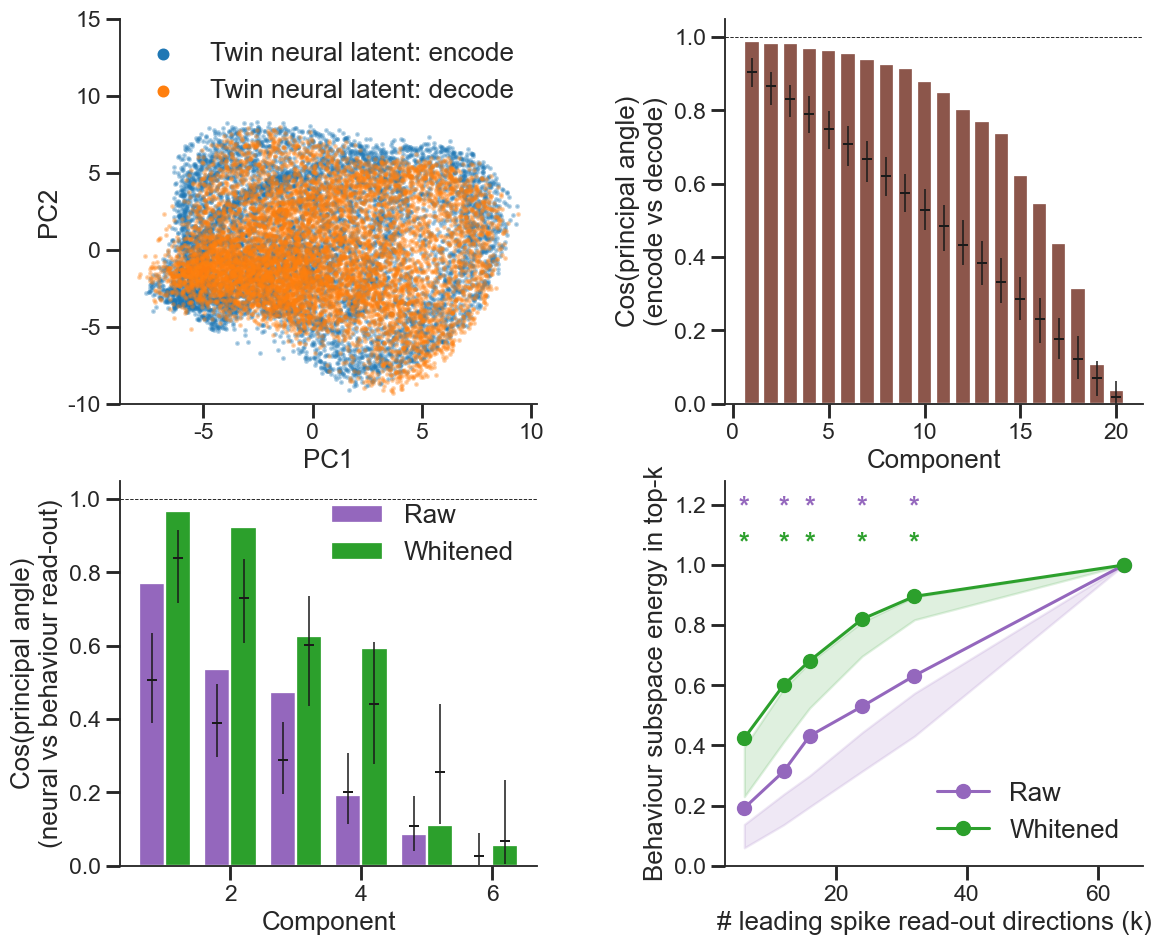

participation ratio: encode=20.4 decode=21.1 (d_sub=20); behaviour read-out rank d_ro=6
encode/decode mean cos²=0.628 (chance 0.312)
read-out mean cos²: raw=0.192  whitened=0.425


In [31]:
# === ED Fig 4: Twin neural latent (encode vs decode) + readout subspace geometry ===
# Both latents are the neural-token half x[:, :T] (Fig 2 convention): encode = neural
# predicted from behavior, decode = neural extracted from observed spikes.
# a) PC1 vs PC2 of the pre-readout latent (encode vs decode, both x[:, :T]);
# b) cos(principal angle) between encode/decode activation subspaces vs component;
# c) cos(principal angle) between the dominant neural vs behavior readout
#    directions, with dimension-permutation null CIs;
# d) behavior readout energy captured by the top-k neural readout directions,
#    with null CIs. (Ports joint-encode-decode.ipynb §9.)
# (c) and (d) work on the readout weights as they are. An earlier version also showed
# covariance-whitened ("functional") variants; those were dropped -- the two readouts
# consume disjoint halves of x (joint.py forward: rate <- spike_readout(x[:, :T]),
# beh <- beh_readout(x[:, T:])), so there is no single activation covariance that is the
# right metric for both, and whitening each by its own made the bases incomparable.
from sklearn.decomposition import PCA


@torch.no_grad()
def _collect_enc_dec_latents(model, loaders, device):
    """Row-aligned pre-readout encode and decode neural latents over a split.
    encode: spikes masked, behavior seen -> xfull[:, :T]; decode: behavior masked,
    spikes seen -> ALSO xfull[:, :T] here (Fig-2 convention), not xfull[:, T:].
    Both are therefore the neural half h_n, the input the neural readout acts on."""
    model.eval(); Le, Ld = [], []
    for s, sd in loaders.items():
        for b in sd:
            m = b.mask.to(device); T = b.spike.shape[1]
            sp, bh = b.spike.to(device), b.behavior.to(device)
            nt = b.mask.clone().to(device)
            _, _, xe = model(s, sp, bh, m, nt, torch.zeros_like(nt))
            bt = b.mask.clone().to(device)
            _, _, xd = model(s, sp, bh, m, torch.zeros_like(bt), bt)
            mk = b.mask.numpy().astype(bool)
            Le.append(nh.masked_latent(xe, T, 'encode').cpu().numpy()[mk])  # neural tokens x[:, :T]
            Ld.append(xd[:, :T].cpu().numpy()[mk])  # decode in the SAME encode space x[:, :T] (Fig 2)
    return np.vstack(Le), np.vstack(Ld)


L_enc, L_dec = _collect_enc_dec_latents(joint_model, joint_loaders['test'], device)
_D = L_enc.shape[1]


def _pca_basis(L, d):
    _, _, Vt = np.linalg.svd(L - L.mean(0), full_matrices=False); return Vt[:d].T


def participation_ratio(L):
    s = np.linalg.svd(L - L.mean(0), compute_uv=False) ** 2
    return float(s.sum() ** 2 / (s ** 2).sum())


def principal_angles_cos(A, B):
    return np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0)


def _svd_basis(W, d):
    _, _, Vt = np.linalg.svd(W, full_matrices=False); return Vt[:d].T


def _energy_in(Q, V):
    return float(np.trace(Q.T @ V @ V.T @ Q) / Q.shape[1])


def _null_pa_cos(d1, d2, D, n=300, seed_=1):
    rng = np.random.default_rng(seed_); out = []
    for _ in range(n):
        A = np.linalg.qr(rng.standard_normal((D, d1)))[0]
        B = np.linalg.qr(rng.standard_normal((D, d2)))[0]
        out.append(np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0))
    return np.array(out)


# encode/decode activation subspaces, matched to the participation ratio
pr_enc, pr_dec = participation_ratio(L_enc), participation_ratio(L_dec)
d_sub = max(2, int(round(min(pr_enc, pr_dec))))
Venc, Vdec = _pca_basis(L_enc, d_sub), _pca_basis(L_dec, d_sub)
ang_ed = principal_angles_cos(Venc, Vdec)


def _readout_rows(mod):
    mods = mod.values() if isinstance(mod, nn.ModuleDict) else [mod]
    return np.vstack([m.weight.detach().cpu().numpy() for m in mods])


W_neu = _readout_rows(joint_model.spike_readout)     # (sum_K, D); package attr keeps its name
W_beh = _readout_rows(joint_model.beh_readout)       # (3*n_rooms, D)
d_ro = int(np.linalg.matrix_rank(W_beh))             # behavior readout rank (<= 3*n_rooms)
Q_beh, Q_neu = _svd_basis(W_beh, d_ro), _svd_basis(W_neu, d_ro)
ang_ro = principal_angles_cos(Q_neu, Q_beh)

ks = sorted({min(k, _D) for k in [d_ro, 2 * d_ro, 4 * d_ro, 16, 32, 64, _D]})
neu_top = {k: _svd_basis(W_neu, k) for k in ks}
curve = [_energy_in(Q_beh, neu_top[k]) for k in ks]

# empirical null: relabel the latent dimensions, i.e. permute the COLUMNS of W_beh with
# one permutation shared by every row. Because a column permutation is orthogonal, this
# leaves W_beh @ W_beh.T -- and hence every row norm, the cross-row structure and the whole
# singular-value spectrum -- exactly intact, and varies only which latent dimension each
# weight attaches to. The null therefore asks the narrow question the panels are about:
# is the CORRESPONDENCE between behavior- and neural-readout dimensions special, given the
# behavior readout's own geometry? (Much stricter than shuffling entries or drawing
# Gaussians, both of which also randomise that geometry.)
_rng4 = np.random.default_rng(seed); N_NULL = 300
null_pa, null_curve = [], []
for _ in range(N_NULL):
    Wb = W_beh[:, _rng4.permutation(W_beh.shape[1])]
    Q_beh_x = _svd_basis(Wb, d_ro)
    null_pa.append(principal_angles_cos(Q_neu, Q_beh_x))
    null_curve.append([_energy_in(Q_beh_x, neu_top[k]) for k in ks])
null_pa, null_curve = np.array(null_pa), np.array(null_curve)


# --- figure ---
def _sig_stars(ax, xs, obs, lo, hi, y, color):
    """'*' where obs falls outside the null [lo, hi]. `y` is either a scalar row
    height or a per-point sequence of heights (one per x)."""
    ys = np.broadcast_to(np.asarray(y, dtype=float), np.shape(xs))
    for _x, _o, _l, _h, _y in zip(xs, obs, lo, hi, ys):
        if _o > _h or _o < _l:
            ax.text(_x, _y, '*', color=color, ha='center', va='center', fontsize=18, fontweight='bold', clip_on=False)


Z = np.vstack([L_enc, L_dec]); task = np.array([0] * len(L_enc) + [1] * len(L_dec))
_sub = np.sort(_rng4.choice(len(Z), min(len(Z), 40000), replace=False))
Z2 = nh.fit_shared_latent_pca(L_enc, L_dec, n_components=3, random_state=seed).transform(Z)[_sub]
tsub = task[_sub]

fig_ed4, axes = plt.subplots(2, 2, figsize=(12, 10))
_lgnd_fs = axes[0, 0].xaxis.label.get_fontsize()  # match legend text to axis-label size
# a) PC1 vs PC2, encode vs decode
for tk, col, lab in [(0, 'tab:blue', 'Twin neural latent: encode'), (1, 'tab:orange', 'Twin neural latent: decode')]:
    mk = tsub == tk
    axes[0, 0].scatter(Z2[mk, 0], Z2[mk, 1], s=3, alpha=0.3, color=col, label=lab, rasterized=True)
axes[0, 0].set(xlabel='PC1', ylabel='PC2', ylim=(-10, 15))
_leg_a = axes[0, 0].legend(fontsize=_lgnd_fs, loc='upper right')
for _lh in _leg_a.legend_handles:
    _lh.set_alpha(1.0); _lh.set_sizes([40])
# b) encode vs decode subspace principal angles
null_ed = _null_pa_cos(d_sub, d_sub, _D, seed_=seed)
_lo, _med, _hi = np.percentile(null_ed, [2.5, 50, 97.5], axis=0); xr = np.arange(1, d_sub + 1)
axes[0, 1].bar(xr, ang_ed, color='tab:brown')
axes[0, 1].vlines(xr, _lo, _hi, color='k', lw=1)
axes[0, 1].plot(xr, _med, '_', color='k', ms=7, mew=1.3)
axes[0, 1].axhline(1, ls='--', color='k', lw=0.6)
axes[0, 1].set(xlabel='component', ylabel='cos(principal angle)\n(encode vs decode)', ylim=(0, 1.05))
# c) neural vs behavior readout angles, with null CIs; stars where outside the null
xp = np.arange(1, d_ro + 1)
_pa_lo, _pa_med, _pa_hi = np.percentile(null_pa, [2.5, 50, 97.5], axis=0)
axes[1, 0].bar(xp, ang_ro, width=0.6, color='tab:purple')
axes[1, 0].vlines(xp, _pa_lo, _pa_hi, color='k', lw=1)
axes[1, 0].plot(xp, _pa_med, '_', color='k', ms=7, mew=1.3)
axes[1, 0].axhline(1, ls='--', color='k', lw=0.6)
axes[1, 0].set(xlabel='component', ylabel='cos(principal angle)\n(neural vs behavior readout)',
               ylim=(0, 1.05), xticks=xp)  # same cosine scale as (b); tick every component
# star sits just above whichever is taller, the bar or the null whisker
_sig_stars(axes[1, 0], xp, ang_ro, _pa_lo, _pa_hi, np.maximum(ang_ro, _pa_hi) + 0.06, 'tab:purple')
# d) behavior readout energy in top-k neural readout dirs, with null CI
_cv_lo, _cv_hi = np.percentile(null_curve, [2.5, 97.5], axis=0)
axes[1, 1].plot(ks, curve, 'o-', color='tab:purple')
axes[1, 1].fill_between(ks, _cv_lo, _cv_hi, color='tab:purple', alpha=0.15)
axes[1, 1].set(xlabel='# leading neural readout directions (k)',
               ylabel='behavior readout energy in top-k', ylim=(0, 1.15))
_sig_stars(axes[1, 1], ks, curve, _cv_lo, _cv_hi, 1.07, 'tab:purple')
fig_ed4.subplots_adjust(wspace=0.45)  # more horizontal room between columns
ph.save_fig(fig_ed4, 'edfig4_subspaces'); plt.show()
print(f'participation ratio: encode={pr_enc:.1f} decode={pr_dec:.1f} (d_sub={d_sub}); '
      f'behavior readout rank d_ro={d_ro}')
print(f'encode/decode mean cos²={np.mean(ang_ed ** 2):.3f} (chance {d_sub / _D:.3f})')
print(f'neural vs behavior readout mean cos²={np.mean(ang_ro ** 2):.3f}')
print(f'components outside null (c): {[int(i) for i in xp[(ang_ro > _pa_hi) | (ang_ro < _pa_lo)]]}; '
      f'k outside null (d): {[k for k, o, l, h in zip(ks, curve, _cv_lo, _cv_hi) if o > h or o < l]}')

**Extended Data Figure 4 | Digital Twin aligns encode and decode latents and readouts.** (A) First two components of a single PCA fit to the row-concatenation of the encode and decode latents, so both share one basis. Latents are the pre-readout neural tokens on the encode and decode passes (n = 8,072 held-out timepoints per pass, pooled across 17 sessions). (B) Cosine of the top 20 principal angles between the encode and decode activation subspaces, 20 being the participation ratio of the latents (20.4 encode, 21.1 decode); bars = observed cosine, whiskers = 2.5–97.5\% and tick = median of a null of principal angles between two independent random 20-dimensional subspaces of the 64-dimensional latent (n = 300). Dashed line at 1 = perfect alignment. (C) Cosine of the principal angles between the dominant neural and behavior readout directions, taking as many directions as the behavior readout rank (6); bars, whiskers, tick and dashed line as in (B), but against a dimension-permutation null: n = 300 relabelings of the 64 latent dimensions, permuting the columns of the behavior readout weight matrix by one permutation shared across rows while the neural readout is held as observed. Stars mark components falling outside the 2.5–97.5\% interval of that null (two-sided permutation P < 0.05): components 1–3, P = 0.007, 0.033 and 0.007. (D) Fraction of the behavior readout subspace (its 6 leading right-singular directions) captured by the top-k neural readout directions, the latter taken over 3,080 neurons pooled across sessions; shaded band and stars as in (C), at k = 6, 12, 16, 24 and 32 (all P = 0.007). At k = 64 the fraction is 1 by construction. See also Figure \ref{fig:fig2}.

---
## Figure 3 — Same route, different paths: route-progress vs absolute-space sequences

Two flight clusters that share **origin and destination** but take geometrically
different 3-D paths between them (large Fréchet distance, small endpoint gaps).
The common coordinate is each path's own cumulative arc length ("route progress").
If place cells fire at the same *fraction* of the route on both detours, the
population sequence is preserved (schematic/topological coding); if they fire at
absolute 3-D positions, the alternate-path sequence is scrambled. Example index 0.

Data are loaded from raw spike times (native `Fs`) via `Data_Prep_for_Raw`, a
separate pipeline from the binned dataloaders (ported from
`investigate_similar_trajectories.ipynb`).

In [32]:
# === Figure 3 data: raw-spike cache + same-route different-path pairs ===
from scipy.interpolate import interp1d as _interp1d
from scipy.io import loadmat as _loadmat
from itertools import combinations as _combinations
import glob as _glob
from digitalbat.utility.utils import frechet_distance as _frechet_d
from digitalbat.datasets.data import Data_Prep_for_Raw as _DPR
from notebook_helpers import get_target_locs as _get_target_locs

AP_PARENT = data_config['parent_folder']
N_DS_AP, MIN_DUR_AP, MIN_CLU_AP, MAX_ACC_AP = 100, 1.0, 3, 50.0


def _ap_load_session(sn):
    """Raw behaviour + spike times (native Fs) for one session, via Data_Prep_for_Raw."""
    folder = AP_PARENT + sn
    su = AP_PARENT + 'To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    prep = _DPR(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
                use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
                use_ripple_flag=False, only_flight_flag=True, spike_count_flag=True,
                bin_width=0.10, max_acceleration=MAX_ACC_AP)
    prep.get_all_behavior(); prep.get_all_spike(); prep.get_flight_cluster()
    fc = prep.flight_cluster_results
    bhv = _loadmat(_glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    t_bhv = bhv['t'][:, 0] if 'Dataset_2' in sn else bhv['t'][0, :]
    Fs = float(bhv['Fs'][0, 0])
    # raw spike times + merge (mirrors Data_Prep_for_Raw.get_all_spike)
    su_paths = sorted(_glob.glob(su))
    times, cids, ptypes = [], [], []
    for p in su_paths:
        gu = _loadmat(p)['out_Gunits']
        cids.append(np.array([x[0][0, 0] for x in gu['cluster_id']]))
        times.append([x[0][:, 0] / 1e6 for x in gu['spikeTimes_usec']])
        ptypes.append(list(np.array([np.squeeze(x[0]).item() if np.squeeze(x[0]).ndim == 0
                       else np.squeeze(x[0]) for x in gu['pType']], dtype=object)))
    mg = _loadmat(_glob.glob(folder + '/merges_Dataset_*.mat')[0])['merges']
    refractory = 0.001
    for ii in range(len(su_paths)):
        if len(mg[ii][0]):
            to_merge = mg[ii][0][0][0][0]
            cl, tl = cids[ii], times[ii]
            midx = [np.where(cl == cid)[0][0] for cid in to_merge]
            merged = np.sort(np.concatenate([tl[k] for k in midx]))
            clean = [merged[0]]
            for s_ in merged[1:]:
                if s_ - clean[-1] > refractory:
                    clean.append(s_)
            tl[midx[0]] = np.array(clean)
            for k in midx[1:]:
                tl[k] = np.array([])
            valid = [i for i, st in enumerate(tl) if len(st) > 0]
            times[ii] = [tl[i] for i in valid]; cids[ii] = cl[valid]
            ptypes[ii] = [ptypes[ii][i] for i in valid]
    spike_times = [st for probe in times for st in probe]
    pType = np.array([pt for probe in ptypes for pt in probe], dtype=object)
    return dict(r=bhv['r'], t=t_bhv, Fs=Fs, v=bhv['v'], spike_times=spike_times,
                pType=pType, fc_results=fc)


def _ds_traj(r, fs, fe, n=N_DS_AP):
    fs, fe = int(fs), int(fe); traj = r[fs:fe + 1]
    to = np.linspace(0, 1, traj.shape[0]); td = np.linspace(0, 1, n)
    return np.column_stack([_interp1d(to, traj[:, d])(td) for d in range(3)])


session_data_cache = {}
for sn in session_names:
    try:
        d = _ap_load_session(sn)
    except Exception as exc:
        print(f'  [Fig3 skip {sn}] {type(exc).__name__}: {exc}'); continue
    fc, Fs = d['fc_results'], d['Fs']
    recs = []
    for i in range(fc['N']):
        dur = (fc['stop_frame'][i] - fc['start_frame'][i]) / Fs
        if dur < MIN_DUR_AP:
            continue
        pos = d['r'][fc['start_frame'][i]:fc['stop_frame'][i] + 1]
        acc = np.gradient(np.gradient(pos, 1.0 / Fs, axis=0), 1.0 / Fs, axis=0)
        if np.linalg.norm(acc, axis=1).max() > MAX_ACC_AP:
            continue
        recs.append(dict(cluster_id=int(fc['id'][i]), f_start=int(fc['start_frame'][i]),
                         f_stop=int(fc['stop_frame'][i]), duration=dur))
    dff = pd.DataFrame(recs)
    ci = {}
    for cid, grp in dff.groupby('cluster_id'):
        if len(grp) < MIN_CLU_AP:
            continue
        trajs = np.stack([_ds_traj(d['r'], row.f_start, row.f_stop) for _, row in grp.iterrows()])
        ci[int(cid)] = dict(n_flights=len(grp), mean_traj=np.nanmean(trajs, 0))
    session_data_cache[sn] = dict(data=d, df_flights=dff, cluster_info=ci)
    print(f'  {sn}: {len(dff)} flights, {len(ci)} clusters')

# --- same-route, different-path candidate pairs (shared endpoints, high Fréchet) ---
AP_ENDPOINT_THRESH, AP_MIN_FRECHET, AP_MIN_FLIGHTS, AP_LABEL_THRESH = 0.25, 1.0, 5, 1.0  # shared endpoints within 0.25 m (drops the loose reward->perch pair)


def _endpoint_label(sess, xyz):
    rew, perch = _get_target_locs(sess)
    dr = float(np.min(np.linalg.norm(rew - xyz, axis=1)))
    dp = float(np.min(np.linalg.norm(perch - xyz, axis=1)))
    if min(dr, dp) > AP_LABEL_THRESH:
        return 'other'
    return 'reward' if dr <= dp else 'perch'


_apc = []
for sess, cached in session_data_cache.items():
    big = {c: i for c, i in cached['cluster_info'].items() if i['n_flights'] >= AP_MIN_FLIGHTS}
    for a, b in _combinations(big, 2):
        ta, tb = big[a]['mean_traj'], big[b]['mean_traj']
        sg, eg = float(np.linalg.norm(ta[0] - tb[0])), float(np.linalg.norm(ta[-1] - tb[-1]))
        if max(sg, eg) > AP_ENDPOINT_THRESH:
            continue
        fr = float(_frechet_d(ta, tb))
        if fr < AP_MIN_FRECHET:
            continue
        _apc.append(dict(session=sess, bat=parse_bat(sess), cluster_a=a, cluster_b=b,
                         n_flights_a=big[a]['n_flights'], n_flights_b=big[b]['n_flights'],
                         start_gap=sg, end_gap=eg, frechet=fr,
                         score=min(big[a]['n_flights'], big[b]['n_flights']) * fr))
df_altpath = pd.DataFrame(_apc)
if len(df_altpath):
    df_altpath['route_type'] = [
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][0]) + '→' +
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][-1])
        for s, a in zip(df_altpath.session, df_altpath.cluster_a)]
    df_altpath = df_altpath.sort_values('score', ascending=False).reset_index(drop=True)
print(f'\n{len(df_altpath)} same-route different-path pairs')
df_altpath.head(8)


  Acceleration filter: removed 1/136 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_14543_240420: 130 flights, 4 clusters
  Dataset_3_14543_240421: 113 flights, 5 clusters
  Acceleration filter: removed 9/154 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240402: 137 flights, 6 clusters
  Acceleration filter: removed 4/131 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240403: 124 flights, 5 clusters
  Acceleration filter: removed 1/79 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240404: 77 flights, 3 clusters
  Acceleration filter: removed 1/78 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231208: 76 flights, 4 clusters
  Acceleration filter: removed 1/77 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231209: 75 flights, 4 clusters
  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Dataset_1_32622_231009: 78 flights, 7 clusters
  Dataset_1_32622_231010: 94 flights, 5 clusters
  Acceleration filter: removed 1/98 flights (peak |acc| > 50.0 m/s²)


,session,bat,cluster_a,cluster_b,n_flights_a,n_flights_b,start_gap,end_gap,frechet,score,route_type
0,Dataset_1_32622_231010,32622,10,11,43,13,0.126042,0.103677,1.974863,25.673225,reward→reward
1,Dataset_1_32622_231009,32622,15,16,10,19,0.025309,0.042311,1.740129,17.401289,reward→reward
2,Dataset_2_14445_231209,14445,2,3,6,28,0.210797,0.056653,2.357523,14.145136,reward→perch
3,Dataset_2_14445_231209,14445,1,3,5,28,0.208222,0.175107,2.334816,11.674081,reward→perch


In [33]:
# === Figure 3 analysis + composite plot for one route pair (reused by ED Fig 5) ===
from scipy.stats import wilcoxon as _wilcoxon, spearmanr as _spearmanr

AP_N_PROG, AP_N_TIME, AP_ACTIVE_HZ = 40, 40, 1.0
AP_N_TIME_HI = 160  # display-only resolution for the smoothed paired heatmaps
AP_N_SHUF_PC, AP_N_SHUF_SEQ = 100, 2000
AP_SMOOTH_SD, AP_SMOOTH_PAD = 0.10, 4.0  # normalized-time rate = spike train * Gaussian: SD (s) + overflow (in SDs)
# Axis of the whole figure: 'time' (normalized flight time) or 'space' (normalized
# route progress = cumulative path distance / total). Set AP_PHASE='time' to revert.
AP_PHASE = 'time'
AP_SMOOTH_SD_PROG = 0.04  # Gaussian SD for the space (progress) rate, in normalized-progress units
_pe = np.linspace(0, 1, AP_N_PROG + 1); _pc = (_pe[:-1] + _pe[1:]) / 2
_te = np.linspace(0, 1, AP_N_TIME + 1); _tc = (_te[:-1] + _te[1:]) / 2


def _prog(pos):
    s = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(pos, axis=0), axis=1))])
    return s / max(s[-1], 1e-9)


def _route_example(idx, seed_=1, merge_alt=None, pairs_df=None, n_candidates=1, browse=False, force_neuron=None):
    """Compute maps, cross-validated place cells, PV correlation + lag, and the three
    sequence-preservation tests for df_altpath row `idx`. Returns a results dict."""
    rng = np.random.default_rng(seed_)
    row = (df_altpath if pairs_df is None else pairs_df).iloc[idx]
    sess, a, b = row.session, int(row.cluster_a), int(row.cluster_b)
    d = session_data_cache[sess]['data']; dff = session_data_cache[sess]['df_flights']
    ci = session_data_cache[sess]['cluster_info']
    REF, ALT = (a, b) if ci[a]['n_flights'] >= ci[b]['n_flights'] else (b, a)
    ALT_IDS = [ALT] + [int(c) for c in (merge_alt or [])]  # extra alternate clusters merged into Path 2
    _alt_df = dff[dff.cluster_id.isin(ALT_IDS)]
    _alt_mean_traj = np.nanmean(np.stack([_ds_traj(d['r'], r.f_start, r.f_stop)
                                          for _, r in _alt_df.iterrows()]), 0)
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    ref_len = float(np.sum(np.linalg.norm(np.diff(ci[REF]['mean_traj'], axis=0), axis=1)))

    _gnorm = 1.0 / (AP_SMOOTH_SD * np.sqrt(2 * np.pi))

    def maps(fldf, offsets=None, space_only=False):
        # `rate_time` is the phase-tuning matrix (nu x AP_N_TIME): normalized-TIME rate
        # (spike train * Gaussian, AP_SMOOTH_SD s) if AP_PHASE=='time', else the normalized-
        # SPACE rate = occupancy-normalized progress rate (Gaussian KDE on spike progress /
        # Gaussian-smoothed occupancy), both in spikes/s. `rate_prog` (route-progress map for
        # place-cell selection) is unchanged in either mode.
        occ = np.zeros(AP_N_PROG); sp = np.zeros((nu, AP_N_PROG)); rt = np.zeros((nu, AP_N_TIME))
        den_s = np.zeros(AP_N_TIME); nfl = 0
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            prog = _prog(d['r'][fs:fe + 1]); rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]
            occ += np.histogram(prog, bins=_pe)[0] * dt; nfl += 1
            t_eval = ft[0] + _tc * dur  # real-time points at the normalized-time bin centers
            if AP_PHASE == 'space' and not space_only:  # smoothed occupancy over progress
                _zc = (_tc[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
                den_s += np.exp(-0.5 * _zc * _zc).sum(1) * dt
            for u in range(nu):
                st = d['spike_times'][u]
                stf = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(stf):
                    rel = (stf - ft[0] + off) % dur
                    sp[u] += np.histogram(np.interp(rel, rel_t, prog), bins=_pe)[0]
                if not space_only:
                    if AP_PHASE == 'time':
                        # rate = raw spike train * Gaussian (SD = AP_SMOOTH_SD s), a rate not a
                        # density (no 1/N), sampled at the normalized-time bin centres; overflow
                        # spikes included so edge bins aren't truncated; averaged over flights.
                        stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD) &
                                 (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                        if len(stw):
                            z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                            rt[u] += _gnorm * np.exp(-0.5 * z * z).sum(1)
                    elif len(stf):  # space: Gaussian KDE of spike progress (occ-normalized below)
                        _sprog = np.interp(stf, ft, prog)
                        _zs = (_tc[:, None] - _sprog[None, :]) / AP_SMOOTH_SD_PROG
                        rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
        rate_time = rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den_s, 1e-9)
        return dict(rate_prog=sp / np.maximum(occ, 1e-9), occ=occ, rate_time=rate_time, n=nfl)

    def _time_rate(fldf, centers):
        """Phase-tuning rate (all neurons) sampled at `centers`, matching AP_PHASE: normalized-
        time spike-train*Gaussian (with edge overflow) for 'time', or occupancy-normalized
        progress rate for 'space'. Finer grid than the 40-bin analysis maps, for a smooth
        heatmap display."""
        rt = np.zeros((nu, len(centers))); den = np.zeros(len(centers)); nfl = 0
        for _, fr in fldf.iterrows():
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]; dur = ft[-1] - ft[0]
            nfl += 1
            if AP_PHASE == 'space':
                prog = _prog(d['r'][fs:fe + 1])
                _zc = (centers[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
                den += np.exp(-0.5 * _zc * _zc).sum(1) * dt
            else:
                t_eval = ft[0] + centers * dur
            for u in range(nu):
                st = d['spike_times'][u]
                if AP_PHASE == 'time':
                    stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD) &
                             (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                    if len(stw):
                        z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                        rt[u] += _gnorm * np.exp(-0.5 * z * z).sum(1)
                else:
                    stf = st[(st >= ft[0]) & (st <= ft[-1])]
                    if len(stf):
                        _sprog = np.interp(stf, ft, prog)
                        _zs = (centers[:, None] - _sprog[None, :]) / AP_SMOOTH_SD_PROG
                        rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
        return rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den, 1e-9)

    def _si(rate, occ):
        p = occ / occ.sum(); lam = (p * rate).sum()
        if lam <= 0:
            return 0.0
        nz = rate > 0
        return float((p[nz] * rate[nz] * np.log2(rate[nz] / lam)).sum() / lam)

    def _rowcorr(M1, M2):
        A = M1 - M1.mean(1, keepdims=True); B = M2 - M2.mean(1, keepdims=True)
        den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
        return np.where(den > 0, (A * B).sum(1) / np.maximum(den, 1e-12), np.nan)

    # cross-validated place cells on the reference route-progress map
    ref_all = dff[dff.cluster_id == REF].sample(frac=1.0, random_state=seed_).reset_index(drop=True)
    nR = len(ref_all); j1, j2 = int(round(0.5 * nR)), int(round(0.75 * nR))
    tr, va, te = ref_all.iloc[:j1], ref_all.iloc[j1:j2], ref_all.iloc[j2:]
    tr_m = maps(tr); held = maps(pd.concat([va, te]), space_only=True)
    si = np.array([_si(tr_m['rate_prog'][u], tr_m['occ']) for u in range(nu)])
    r_obs = _rowcorr(tr_m['rate_prog'], held['rate_prog'])
    hd = [d['t'][int(fr.f_stop)] - d['t'][int(fr.f_start)] for _, fr in pd.concat([va, te]).iterrows()]
    r_null = np.empty((AP_N_SHUF_PC, nu))
    for s_ in range(AP_N_SHUF_PC):
        hm = maps(pd.concat([va, te]), offsets=[rng.uniform(0, x) for x in hd], space_only=True)
        r_null[s_] = _rowcorr(tr_m['rate_prog'], hm['rate_prog'])
    pcv = np.nanmean(r_null >= r_obs[None, :], axis=0)
    peak_tr = tr_m['rate_prog'].max(1)
    place = (pcv < 0.025) & (peak_tr >= AP_ACTIVE_HZ) & (si > 0) & np.isfinite(r_obs)
    pc = np.where(place)[0]

    ref_vt = maps(pd.concat([va, te])); alt = maps(_alt_df)
    order = pc[np.argsort(tr_m['rate_time'][pc].argmax(1))] if len(pc) else pc

    # high-resolution smoothed rate for the paired heatmaps only (display), so the KDE
    # reads as continuous rather than 40 discrete columns; analysis stays at AP_N_TIME.
    _ceh = np.linspace(0, 1, AP_N_TIME_HI + 1); _tch = (_ceh[:-1] + _ceh[1:]) / 2
    ref_time_hi = _time_rate(pd.concat([va, te]), _tch)
    alt_time_hi = _time_rate(_alt_df, _tch)
    train_time_hi = _time_rate(tr, _tch)  # Path 1 TRAIN display map (the sort source)

    # PV corr (ref x alt, normalized time) + mean PV corr vs lag
    def _norm(M):
        return M / np.maximum(M.max(1, keepdims=True), 1e-9)
    Rr, Ra = _norm(ref_vt['rate_time']), _norm(alt['rate_time'])
    A = Rr[pc] - Rr[pc].mean(0); B = Ra[pc] - Ra[pc].mean(0)
    PV = (A.T @ B) / (np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(B, axis=0)) + 1e-9)
    nlag = PV.shape[0]; lags = np.arange(-nlag + 1, nlag)
    pv_lag = np.array([np.nanmean(np.diagonal(PV, offset=k)) for k in lags])
    peak_lag = lags[np.nanargmax(pv_lag)] / nlag

    # 95% band on mean PV corr vs lag by bootstrapping over PLACE CELLS (the ~independent
    # replicates). A SEM across the diagonal elements would be anti-conservative because
    # adjacent time bins are strongly autocorrelated (not independent).
    def _lag_curve(Xc, Yc):  # mean PV corr at each lag from centred place-cell tunings
        pvm = (Xc.T @ Yc) / (np.outer(np.linalg.norm(Xc, axis=0), np.linalg.norm(Yc, axis=0)) + 1e-9)
        return np.array([np.nanmean(np.diagonal(pvm, offset=k)) for k in lags])
    def _lag_boot(Xr, Yr, nboot=500):
        nc = Xr.shape[0]; out = np.empty((nboot, len(lags)))
        for bi in range(nboot):
            sel = rng.integers(0, nc, nc)
            out[bi] = _lag_curve(Xr[sel] - Xr[sel].mean(0), Yr[sel] - Yr[sel].mean(0))
        return np.nanpercentile(out, 2.5, axis=0), np.nanpercentile(out, 97.5, axis=0)
    pv_lag_lo, pv_lag_hi = _lag_boot(Rr[pc], Ra[pc]) if (len(pc) > 1 and not browse) else (None, None)

    # Path 3: a DIFFERENT-route cluster with sufficient repeats -- a contrast whose
    # sequence should NOT be preserved (same place cells / sort). Prefer a cluster whose
    # BOTH endpoints differ from Path 1's (e.g. perch->perch when Path 1 is reward->reward),
    # so origin AND destination are genuinely different; else fall back to one whose
    # endpoints merely differ. Among candidates, take the one with the most flights.
    _rs0, _re0 = ci[REF]['mean_traj'][0], ci[REF]['mean_traj'][-1]
    def _far_from_ref(pt):  # far from BOTH Path-1 endpoints (a genuinely different location)
        return min(np.linalg.norm(pt - _rs0), np.linalg.norm(pt - _re0)) > AP_ENDPOINT_THRESH
    _pool3 = [(ci[c]['n_flights'], c) for c in ci
              if c not in ([REF] + ALT_IDS) and ci[c]['n_flights'] >= AP_MIN_FLIGHTS]
    _both3 = [(n, c) for n, c in _pool3
              if _far_from_ref(ci[c]['mean_traj'][0]) and _far_from_ref(ci[c]['mean_traj'][-1])]
    _one3 = [(n, c) for n, c in _pool3
             if max(np.linalg.norm(ci[c]['mean_traj'][0] - _rs0),
                    np.linalg.norm(ci[c]['mean_traj'][-1] - _re0)) > AP_ENDPOINT_THRESH]
    _cand3 = _both3 if _both3 else _one3
    THIRD = int(max(_cand3)[1]) if (_cand3 and not browse) else None
    third_time_hi, pv_lag3, n_third, PV3, third_route = None, None, 0, None, None
    pv_lag3_lo = pv_lag3_hi = third_time = None
    if THIRD is not None:
        third = maps(dff[dff.cluster_id == THIRD]); n_third = third['n']; third_time = third['rate_time']
        third_time_hi = _time_rate(dff[dff.cluster_id == THIRD], _tch)
        Rt = _norm(third['rate_time']); Bt = Rt[pc] - Rt[pc].mean(0)
        PV3 = (A.T @ Bt) / (np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(Bt, axis=0)) + 1e-9)
        pv_lag3 = np.array([np.nanmean(np.diagonal(PV3, offset=k)) for k in lags])
        pv_lag3_lo, pv_lag3_hi = _lag_boot(Rr[pc], Rt[pc]) if len(pc) > 1 else (None, None)
        third_route = (_endpoint_label(sess, ci[THIRD]['mean_traj'][0]) + '→' +
                       _endpoint_label(sess, ci[THIRD]['mean_traj'][-1]))

    # 3-D Euclidean distance between mean flight paths at matched normalized-time bins
    # (Path 1 bin i vs Path 2/3 bin j); z-axis of the separation heatmaps.
    def _resample_traj(traj, n):
        # resample by index (~time) or by cumulative arc length (progress), matching AP_PHASE,
        # so the n points align with the phase (time / progress) bins used for the rate
        src = _prog(traj) if AP_PHASE == 'space' else np.linspace(0.0, 1.0, len(traj))
        dst = np.linspace(0.0, 1.0, n)
        return np.column_stack([np.interp(dst, src, traj[:, k]) for k in range(traj.shape[1])])
    _p1 = _resample_traj(ci[REF]['mean_traj'], nlag)
    _p2 = _resample_traj(_alt_mean_traj, nlag)
    pv_dist = np.linalg.norm(_p1[:, None, :] - _p2[None, :, :], axis=-1)
    dist_diag = np.diagonal(pv_dist).copy()  # path separation at matched normalized time

    # resampled Path-3 mean path for the single-cell overlay (if a Path 3 exists)
    traj_third_rs = _resample_traj(ci[THIRD]['mean_traj'], nlag) if THIRD is not None else None

    # --- pick one example unit for the single-neuron row. Among place cells with a
    # PROMINENT, well-matched normalized-time field on BOTH paths, take the one whose
    # field peak is closest to t*, the time of maximal 3-D separation on the 0-lag
    # diagonal. Such a unit codes route-progress/time rather than absolute 3-D position.
    # Closeness to t* is the PRIMARY criterion; the rest are gates that exclude weak,
    # mismatched, or non-sparse fields (not overriding closeness):
    #   - peak rate >= FIELD_MIN_HZ on each path (a real field, not a few stray spikes)
    #   - min/max peak rate >= FIELD_RATIO (comparably strong on both paths)
    #   - peaks within FIELD_MAX_SHIFT bins of each other (same normalized time)
    #   - field width (fraction of normalized time above half-max) <= FIELD_MAX_ACTIVE on
    #     each path, i.e. a SPARSE, localized field rather than one active the whole flight
    FIELD_MIN_HZ, FIELD_RATIO, FIELD_MAX_SHIFT = 1.5, 0.35, 4
    t_star = int(np.argmax(dist_diag))  # time of maximal 3-D separation (0-lag diagonal)

    def _active_frac(c):  # fraction of normalized time the field spends above half its peak
        pk = c.max()
        return float(np.mean(c >= 0.5 * pk)) if pk > 0 else 1.0

    def _pick(max_active):
        best = (np.inf, None, t_star)
        for u in pc:
            cr, ca = ref_vt['rate_time'][u], alt['rate_time'][u]
            pr, pa = float(cr.max()), float(ca.max())
            if min(pr, pa) < FIELD_MIN_HZ:
                continue
            if min(pr, pa) / max(pr, pa) < FIELD_RATIO:
                continue
            ir, ia = int(np.argmax(cr)), int(np.argmax(ca))
            if abs(ir - ia) > FIELD_MAX_SHIFT:
                continue
            if _active_frac(cr) > max_active or _active_frac(ca) > max_active:
                continue
            pk = (ir + ia) // 2  # shared field peak time
            if abs(pk - t_star) < best[0]:
                best = (abs(pk - t_star), int(u), pk)
        return best

    # tighten toward a sparse field; relax the sparsity bar only if nothing qualifies
    neuron, t_peak = None, t_star
    for _ma in (0.35, 0.5, 1.0):
        _d, _un, _pk = _pick(_ma)
        if _un is not None:
            neuron, t_peak = _un, _pk
            break

    # top-N candidate units for browsing: SAME field gates as the single pick, ranked by
    # closeness of the shared field peak to t_star (= time of maximal 3-D path separation)
    def _pick_ranked(max_active):
        out = []
        for u in pc:
            cr, ca = ref_vt['rate_time'][u], alt['rate_time'][u]
            pr, pa = float(cr.max()), float(ca.max())
            if min(pr, pa) < FIELD_MIN_HZ or min(pr, pa) / max(pr, pa) < FIELD_RATIO:
                continue
            ir, ia = int(np.argmax(cr)), int(np.argmax(ca))
            if abs(ir - ia) > FIELD_MAX_SHIFT:
                continue
            if _active_frac(cr) > max_active or _active_frac(ca) > max_active:
                continue
            out.append((abs((ir + ia) // 2 - t_star), int(u), (ir + ia) // 2))
        return sorted(out)
    _ranked = []
    for _ma in (0.35, 0.5, 1.0):
        _ranked = _pick_ranked(_ma)
        if _ranked:
            break
    candidates = [(int(u), int(pk)) for _, u, pk in _ranked[:n_candidates]]
    if force_neuron is not None:  # published figures pin a hand-picked example unit
        neuron = int(force_neuron)
        t_peak = (int(np.argmax(ref_vt['rate_time'][neuron]))
                  + int(np.argmax(alt['rate_time'][neuron]))) // 2

    def _neuron_records(fldf, nrn):
        """Per-flight 3-D paths, spike positions, and per-flight normalized spike times
        (for the raster) for `neuron` on a set of flights."""
        paths, sp, raster = [], [], []
        for _, fr in fldf.iterrows():
            fs, fe = int(fr.f_start), int(fr.f_stop)
            ft = d['t'][fs:fe + 1]; xyz = d['r'][fs:fe + 1]; dur = ft[-1] - ft[0]
            paths.append(xyz)
            stu = d['spike_times'][nrn]; stu = stu[(stu >= ft[0]) & (stu <= ft[-1])]
            if not len(stu):
                _phase = np.empty(0)
            elif AP_PHASE == 'time':
                _phase = (stu - ft[0]) / dur
            else:  # space: spike route-progress
                _phase = np.interp(stu, ft, _prog(xyz))
            raster.append(_phase)
            if len(stu):
                sp.append(np.column_stack([np.interp(stu, ft, xyz[:, k]) for k in range(3)]))
        return dict(paths=paths, spikes=np.vstack(sp) if sp else np.empty((0, 3)), raster=raster)
    # single-cell rate map + raster show ALL Path-1 flights (not just held-out val+test,
    # which the heatmap/PV analyses use); Path 2/3 already use all their flights
    neu_ref = _neuron_records(dff[dff.cluster_id == REF], neuron) if neuron is not None else None
    neu_alt = _neuron_records(_alt_df, neuron) if neuron is not None else None
    neu_third = (_neuron_records(dff[dff.cluster_id == THIRD], neuron)
                 if (neuron is not None and THIRD is not None) else None)
    ref_time_disp = maps(dff[dff.cluster_id == REF])['rate_time'] if (neuron is not None or candidates) else None
    ref_time_hi_disp = _time_rate(dff[dff.cluster_id == REF], _tch) if (neuron is not None or candidates) else None
    # per-candidate display records for browsing: each unit's 3-D spike paths + normalized-time
    # tuning on Path 1 (REF) and the merged Path 2 (ALT), from the same display rate matrices
    cand_records = []
    for _cn, _cpk in candidates:
        cand_records.append(dict(
            neuron=_cn, t_peak=_cpk,
            neu_ref=_neuron_records(dff[dff.cluster_id == REF], _cn),
            neu_alt=_neuron_records(_alt_df, _cn),
            ref_rate=ref_time_disp[_cn], alt_rate=alt['rate_time'][_cn],
            ref_rate_hi=ref_time_hi_disp[_cn], alt_rate_hi=alt_time_hi[_cn]))

    # three preservation tests (normalized time, place cells), one-sided shuffle p
    def _pv(A_, B_):
        Az, Bz = A_ - A_.mean(0), B_ - B_.mean(0)
        den = np.sqrt((Az ** 2).sum(0) * (Bz ** 2).sum(0))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(0) / den, np.nan)))

    def _mc(A_, B_):
        Az, Bz = A_ - A_.mean(1, keepdims=True), B_ - B_.mean(1, keepdims=True)
        den = np.sqrt((Az ** 2).sum(1) * (Bz ** 2).sum(1))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))

    def _roll(M):
        return np.array([np.roll(M[i], rng.integers(M.shape[1])) for i in range(len(M))])

    def _p(obs, null):
        return float((1 + np.sum(np.asarray(null) >= obs)) / (len(null) + 1))

    rr, ra = ref_vt['rate_time'][pc], alt['rate_time'][pc]
    tests, tests3, p_peak, p_peak3 = None, None, None, None
    if len(pc) >= 4 and not browse:
        po, pa = rr.argmax(1), ra.argmax(1)
        rho = float(_spearmanr(po, pa)[0])
        p1 = _p(rho, [float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)])
        Rrn, Ran = _norm(rr), _norm(ra)
        pv = _pv(Rrn, Ran); p2 = _p(pv, [_pv(Rrn, _roll(Ran)) for _ in range(AP_N_SHUF_SEQ)])
        mc = _mc(rr, ra); p3 = _p(mc, [_mc(rr, _roll(ra)) for _ in range(AP_N_SHUF_SEQ)])
        tests = dict(rho=rho, p_order=p1, pv=pv, p_pv=p2, mc=mc, p_mapcorr=p3,
                     null1=[float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)],
                     null2=[_pv(Rrn, _roll(Ran)) for _ in range(500)],
                     null3=[_mc(rr, _roll(ra)) for _ in range(500)])
        # within-Path-1 consistency: Path 1 TRAIN peak-time order vs Path 1 held-out
        # VAL+TEST peak-time order (same place cells + same shuffle machinery as the
        # Path-1-vs-Path-2 order test above; po = val+test order, po_tr = train order).
        po_tr = tr_m['rate_time'][pc].argmax(1)
        rho_tt = float(_spearmanr(po_tr, po)[0])
        tests['rho_traintest'] = rho_tt
        tests['p_traintest'] = _p(rho_tt, [float(_spearmanr(po_tr, rng.permutation(po))[0])
                                           for _ in range(AP_N_SHUF_SEQ)])
        # peak-at-zero test: is lag-0 a genuine PEAK above the far-lag baseline? Circularly
        # roll each cell's Path-2 tuning (preserves its own temporal autocorrelation, so the
        # non-independence of time bins is respected) and compare the peak-minus-baseline
        # statistic. Baseline subtraction makes a flat-but-elevated curve come out n.s.
        _far = np.abs(lags) >= (nlag // 2); _mid0 = nlag - 1
        def _peakstat(Yn):
            pl = _lag_curve(A, Yn - Yn.mean(0))
            return pl[_mid0] - np.nanmean(pl[_far])
        p_peak = _p(_peakstat(Ran), [_peakstat(_roll(Ran)) for _ in range(AP_N_SHUF_SEQ)])
        if THIRD is not None:  # same two preservation tests + peak test, Path 1 vs Path 3
            r3 = third['rate_time'][pc]; po3 = r3.argmax(1); R3n = _norm(r3)
            rho3 = float(_spearmanr(po, po3)[0])
            pq3 = _p(rho3, [float(_spearmanr(po, rng.permutation(po3))[0]) for _ in range(AP_N_SHUF_SEQ)])
            pv3s = _pv(Rrn, R3n); pp3 = _p(pv3s, [_pv(Rrn, _roll(R3n)) for _ in range(AP_N_SHUF_SEQ)])
            tests3 = dict(rho=rho3, p_order=pq3, pv=pv3s, p_pv=pp3)
            p_peak3 = _p(_peakstat(R3n), [_peakstat(_roll(R3n)) for _ in range(AP_N_SHUF_SEQ)])
    return dict(idx=idx, session=sess, bat=parse_bat(sess), REF=REF, ALT=ALT,
                route=row.get('route_type', '?'), frechet=row.frechet,
                traj_ref=ci[REF]['mean_traj'], traj_alt=_alt_mean_traj,
                traj_third=ci[THIRD]['mean_traj'] if THIRD is not None else None,
                ref_time=ref_vt['rate_time'], alt_time=alt['rate_time'],
                ref_time_hi=ref_time_hi, alt_time_hi=alt_time_hi, train_time_hi=train_time_hi, order=order,
                third_time_hi=third_time_hi, third_time=third_time, THIRD=THIRD, n_third=n_third,
                third_route=third_route, traj_third_rs=traj_third_rs, neu_third=neu_third,
                n_place=len(pc), PV=PV, pv_dist=pv_dist, dist_diag=dist_diag,
                traj_ref_rs=_p1, traj_alt_rs=_p2, neuron=neuron, t_peak=t_peak,
                t_star=t_star, candidates=candidates, cand_records=cand_records,
                neu_ref=neu_ref, neu_alt=neu_alt, dt=dt,
                ref_time_disp=ref_time_disp, ref_time_hi_disp=ref_time_hi_disp,
                lags=lags / nlag, pv_lag=pv_lag, pv_lag3=pv_lag3, peak_lag=peak_lag,
                pv_lag_lo=pv_lag_lo, pv_lag_hi=pv_lag_hi, pv_lag3_lo=pv_lag3_lo, pv_lag3_hi=pv_lag3_hi,
                p_peak=p_peak, p_peak3=p_peak3,
                ref_len=ref_len, tests=tests, tests3=tests3)


def plot_route_example(res, save_name, show_path3=True):
    """Three-row composite, panels A-H (the leftmost column is the example single unit):
      row 1: A top-down view              | B Path 1/2/3 sequence heatmaps (span 2 cols)
      row 2: C single-unit rate map (3-D) | E PV-corr matrix       | F path-separation matrix
      row 3: D single-unit raster/tuning  | G mean PV corr vs lag  | H Spearman-order test
    With show_path3 (default), the different-route Path 3 is added to A, B, C, D and to the
    same-vs-different contrasts in G/H; ED Fig 5 calls plot_route_example(show_path3=False)."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    from matplotlib.ticker import LinearLocator, FormatStrFormatter
    pal = sns.color_palette()  # deep: [2]=green, [5]=brown
    c_p1, c_p2, c_p3 = pal[2], plt.cm.Oranges(0.75), pal[0]  # Path 1 green, Path 2 orange, Path 3 blue
    _axl = 'normalized position' if AP_PHASE == 'space' else 'normalized time'
    _axl_s = 'norm pos' if AP_PHASE == 'space' else 'norm time'
    _show3 = show_path3 and res.get('THIRD') is not None  # include the Path-3 (different-route) contrast
    ta, tb = res['traj_ref'], res['traj_alt']
    t = res['tests']
    _title_fs = plt.rcParams['axes.titlesize']; _title_fw = plt.rcParams['axes.titleweight']
    _stars = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    fig = plt.figure(figsize=(16, 14))
    gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1], width_ratios=[0.78, 1, 1], hspace=0.42, wspace=0.45)
    # --- (A) top-down trajectories (Path 1/2/3) ---
    ax_a = fig.add_subplot(gs[0, 0])
    _paths_A = [(ta, c_p1, 'Path 1'), (tb, c_p2, 'Path 2')]
    if _show3:
        _paths_A.append((res['traj_third'], c_p3, 'Path 3'))
    for _zi, (tt, c, lab) in enumerate(_paths_A):
        _z = 6 - _zi          # Path 1 (green) drawn over Path 2 (orange)
        ax_a.plot(tt[:, 0], tt[:, 1], '-', color=c, lw=2.5, label=lab, zorder=_z)
        m = len(tt) // 2
        ax_a.annotate('', xy=tt[m + 4, :2], xytext=tt[m - 4, :2], zorder=_z + 0.5,
                      arrowprops=dict(arrowstyle='-|>', color=c, lw=3, mutation_scale=32))
    # (A) hide the x/y axes; show two equal 1-m scale bars (x and y) at the lower-left
    ax_a.set_aspect('equal'); ax_a.axis('off')
    _ap = np.vstack([tt[:, :2] for tt, _, _ in _paths_A])
    _ex = max(np.ptp(_ap[:, 0]), np.ptp(_ap[:, 1]))
    _cx = _ap[:, 0].min() - 0.10 * _ex; _cy = _ap[:, 1].min() - 0.10 * _ex  # scale-bar corner
    _sbfs = plt.rcParams['xtick.labelsize']
    ax_a.plot([_cx, _cx + 1.0], [_cy, _cy], color='k', lw=3, solid_capstyle='butt', clip_on=False)  # 1 m (x)
    ax_a.plot([_cx, _cx], [_cy, _cy + 1.0], color='k', lw=3, solid_capstyle='butt', clip_on=False)  # 1 m (y)
    ax_a.text(_cx + 0.5, _cy - 0.06 * _ex, '1 m', ha='center', va='top', fontsize=_sbfs)
    ax_a.text(_cx - 0.06 * _ex, _cy + 0.5, '1 m', ha='right', va='center', rotation=90, fontsize=_sbfs)
    ax_a.text(0.5, 1.07, 'Top-down view', transform=ax_a.transAxes, ha='center', va='bottom',
              fontsize=_title_fs, fontweight=_title_fw)
    ax_a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.26), ncol=3 if _show3 else 2, fontsize=15, frameon=False)
    # --- (B) sequence heatmaps (Path 1/2/3) spanning the right two columns, shared colorbar ---
    order = res['order']  # sort chosen from TRAIN; leftmost heatmap = train, then held-out val+test, then Path 2
    _hm_panels = [(res['train_time_hi'], 'Path 1 (train)'),
                  (res['ref_time_hi'], 'Path 1 (val + test)'),
                  (res['alt_time_hi'], 'Path 2 (same route)' if _show3 else 'Path 2')]
    if _show3:
        _hm_panels.append((res['third_time_hi'], 'Path 3 (different route)'))
    _nh = len(_hm_panels)
    hm_gs = gs[0, 1:].subgridspec(1, _nh + 2, width_ratios=[1] * _nh + [0.05, 0.2], wspace=0.1)
    hm_axes = [fig.add_subplot(hm_gs[0, i]) for i in range(_nh)]
    cax = fig.add_subplot(hm_gs[0, _nh])
    for k, (M, name) in enumerate(_hm_panels):
        ax = hm_axes[k]
        H = M[order] / np.maximum(M[order].max(1, keepdims=True), 1e-9) if len(order) else M[:0]
        sns.heatmap(H, ax=ax, cmap='magma', vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=False)
        ax.set(xlabel=_axl, title=name)
        nt = H.shape[1]
        ax.set_xticks([0, nt / 2, nt]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        if k == 0 and len(order):
            ax.set_ylabel('Place cells,\nsorted by Path 1 (train)')
            ax.set_yticks([0.5, len(order) - 0.5]); ax.set_yticklabels(['1', str(len(order))], rotation=0)
        else:
            ax.set_ylabel('')
    # arrowhead marking the example unit's row (same sort in both heatmaps)
    if res['neuron'] is not None and len(order):
        _sr = np.where(np.asarray(order) == res['neuron'])[0]
        if len(_sr):
            _yr = _sr[0] + 0.5
            hm_axes[0].annotate('', xy=(0, _yr), xytext=(-16, 0), textcoords='offset points',
                                xycoords='data', va='center', annotation_clip=False, zorder=6,
                                arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2))
    if len(order):
        cb = fig.colorbar(hm_axes[-1].collections[0], cax=cax)
        cb.set_label('normalized firing', rotation=270, labelpad=12, va='bottom')
    else:
        cax.axis('off')
    _npv = res['PV'].shape[0]
    _tk = [0, _npv / 2, _npv]; _tl = ['0', '0.5', '1']
    # --- (E) PV-corr matrix (2-D heatmap), right of the single-cell rate map (C) ---
    ax_pv = fig.add_subplot(gs[1, 1])
    sns.heatmap(res['PV'], ax=ax_pv, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False,
                cbar_kws=dict(label='PV correlation'))
    ax_pv.collections[0].colorbar.set_label('PV correlation', rotation=270, labelpad=4, va='bottom')
    ax_pv.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax_pv.set_xticks(_tk); ax_pv.set_xticklabels(_tl, rotation=0)
    ax_pv.set_yticks(_tk); ax_pv.set_yticklabels(_tl, rotation=0)
    ax_pv.set_box_aspect(1)
    # --- (F) 3-D path-separation matrix (Euclidean distance, 2-D heatmap) ---
    ax_dist = fig.add_subplot(gs[1, 2])
    sns.heatmap(res['pv_dist'], ax=ax_dist, cmap='viridis_r', xticklabels=False, yticklabels=False,
                cbar_kws=dict(label='3-D distance (m)'))
    ax_dist.collections[0].colorbar.set_label('3-D distance (m)', rotation=270, labelpad=14, va='bottom')
    ax_dist.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax_dist.set_xticks(_tk); ax_dist.set_xticklabels(_tl, rotation=0)
    ax_dist.set_yticks(_tk); ax_dist.set_yticklabels(_tl, rotation=0)
    ax_dist.set_box_aspect(1)
    # --- row 3: shuffle-test panels ---
    recs = []
    _sig = lambda p: _stars(p) or 'n.s.'  # show 'n.s.' so the different-route control reads clearly
    _t3 = res.get('tests3') if _show3 else None; _has3 = _show3
    _sfs = plt.rcParams['xtick.labelsize']  # star font size
    # (G) mean PV corr vs lag, cell-bootstrap 95% bands; per-route peak-test stars above,
    # colour-coded (black = same route, blue = different route; shared G/H legend below)
    ax_e = fig.add_subplot(gs[2, 1])
    _pk, _pk3 = res.get('p_peak'), res.get('p_peak3')
    _mid = len(res['lags']) // 2
    # far-lag baseline mask (|tau| >= nlag//2), matching the peak-at-zero test's _peakstat
    _nlag_pk = res['PV'].shape[0]; _lags_int = np.arange(-_nlag_pk + 1, _nlag_pk)
    _far_pk = np.abs(_lags_int) >= (_nlag_pk // 2)
    def _peak_far(curve):  # (PV corr at tau=0, mean PV corr at far lags, peakstat = 0 - far)
        _c = np.asarray(curve); _pk0 = float(_c[_mid]); _fr = float(np.nanmean(_c[_far_pk]))
        return round(_pk0, 3), round(_fr, 3), round(_pk0 - _fr, 3)
    ax_e.plot(res['lags'], res['pv_lag'], color='k')
    if res.get('pv_lag_lo') is not None:
        ax_e.fill_between(res['lags'], res['pv_lag_lo'], res['pv_lag_hi'], color='k', alpha=0.15, lw=0)
    if _has3:
        ax_e.plot(res['lags'], res['pv_lag3'], color=c_p3, ls='--')
        if res.get('pv_lag3_lo') is not None:
            ax_e.fill_between(res['lags'], res['pv_lag3_lo'], res['pv_lag3_hi'], color=c_p3, alpha=0.15, lw=0)
    ax_e.axvline(0, color='0.6', ls=':', zorder=4)  # tau=0 reference
    ax_e.set(xlabel='lag (τ)', ylabel='mean PV corr')
    if _pk is not None:
        ax_e.text(0.40 if _has3 else 0.5, 1.02, _sig(_pk), transform=ax_e.transAxes,
                  ha='center', va='bottom', color='k', fontsize=_sfs)
        _pk_o, _pk_far, _pk_ps = _peak_far(res['pv_lag'])
        recs.append(dict(session=res['session'], test='PV lag-0 peak (circular-shift)',
                         obs=_pk_o, obs_far=_pk_far, peakstat=_pk_ps, p=_pk, n_place=res['n_place']))
    if _has3 and _pk3 is not None:
        ax_e.text(0.60, 1.02, _sig(_pk3), transform=ax_e.transAxes, ha='center', va='bottom',
                  color=c_p3, fontsize=_sfs)
        _pk3_o, _pk3_far, _pk3_ps = _peak_far(res['pv_lag3'])
        recs.append(dict(session=res['session'], test='PV lag-0 peak, diff route (circular-shift)',
                         obs=_pk3_o, obs_far=_pk3_far, peakstat=_pk3_ps, p=_pk3, n_place=res['n_place']))
    # (H) Spearman order shuffle test; observed values as lines (black = same, blue dashed =
    # different), per-route stars above each line
    ax_f = fig.add_subplot(gs[2, 2])
    if t is not None:
        sns.histplot(t['null1'], bins=30, ax=ax_f, color='lightgray', stat='density')
        ax_f.axvline(t['rho'], color='k', lw=2)
        ax_f.text(t['rho'], 1.02, _sig(t['p_order']), transform=ax_f.get_xaxis_transform(),
                  ha='center', va='bottom', color='k', fontsize=_sfs)
        if _t3:
            ax_f.axvline(_t3['rho'], color=c_p3, lw=2, ls='--')
            ax_f.text(_t3['rho'], 1.02, _sig(_t3['p_order']), transform=ax_f.get_xaxis_transform(),
                      ha='center', va='bottom', color=c_p3, fontsize=_sfs)
        ax_f.set(xlabel='Spearman ρ (order)')
        recs.append(dict(session=res['session'], test='Spearman ρ (order)', obs=round(t['rho'], 3), p=t['p_order'], n_place=res['n_place']))
        if t.get('p_traintest') is not None:  # within-Path-1: TRAIN vs held-out val+test peak order
            recs.append(dict(session=res['session'], test='Spearman ρ (order, Path 1 train vs val+test)',
                             obs=round(t['rho_traintest'], 3), p=t['p_traintest'], n_place=res['n_place']))
        if _t3:
            recs.append(dict(session=res['session'], test='Spearman ρ (order, diff route)', obs=round(_t3['rho'], 3), p=_t3['p_order'], n_place=res['n_place']))
    else:
        ax_f.axis('off')
    # shared legend for G & H (line styles only), centred above the two panels
    if _has3:
        from matplotlib.lines import Line2D
        _lh = [Line2D([], [], color='k', lw=1.8, label='same route'),
               Line2D([], [], color=c_p3, lw=1.8, ls='--', label='different route')]
        _pe_, _pf_ = ax_e.get_position(), ax_f.get_position()
        fig.legend(handles=_lh, loc='lower center', ncol=2, frameon=False, fontsize=15,
                   bbox_to_anchor=((_pe_.x0 + _pf_.x1) / 2, max(_pe_.y1, _pf_.y1) + 0.03))
    # --- (C) single-cell rate map (overlay 3-D view, gs[1,0]) + (D) normalized-time raster &
    #     overlaid tuning curves (gs[2,0]); leftmost column, Path 3 included ---
    neuron = res['neuron']
    ax_both = fig.add_subplot(gs[1, 0], projection='3d')
    if neuron is None:
        ax_both.axis('off'); fig.add_subplot(gs[2, 0]).axis('off')
        ax_both.text2D(0.5, 0.5, 'no example unit', transform=ax_both.transAxes, ha='center', va='center')
    else:
        # per-path spec: (resampled mean path, 40-bin rate, records, rate cmap, spike/line colour)
        _paths_U = [(res['traj_ref_rs'], res['ref_time_disp'][neuron], res['neu_ref'], 'Greens', c_p1),
                    (res['traj_alt_rs'], res['alt_time'][neuron], res['neu_alt'], 'Oranges', c_p2)]
        if _show3 and res.get('neu_third') is not None:
            _paths_U.append((res['traj_third_rs'], res['third_time'][neuron], res['neu_third'], 'Blues', c_p3))
        rmax = max([float(r.max()) for _, r, _, _, _ in _paths_U] + [1e-6])
        rnorm = plt.Normalize(0.0, rmax)
        _pts = []
        for _rs, _, _rec, _, _ in _paths_U:
            _pts.append(_rs); _pts.extend(_rec['paths'])
            if len(_rec['spikes']):
                _pts.append(_rec['spikes'])
        _allp = np.vstack(_pts)
        _lims = [(_allp[:, k].min(), _allp[:, k].max()) for k in range(3)]

        def _draw_unit(ax, rs, rate, rec, cmap, spike_c, spikes=True, zbase=0):
            for xyz in rec['paths']:  # faint individual flight paths
                ax.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], color='0.6', lw=0.4, alpha=0.3, zorder=1 + zbase)
            pts = rs.reshape(-1, 1, 3); segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
            lc = Line3DCollection(segs, cmap=cmap, norm=rnorm)
            lc.set_array(0.5 * (rate[:-1] + rate[1:])); lc.set_linewidth(5.0); lc.set_zorder(4 + zbase)
            ax.add_collection(lc)
            if spikes and len(rec['spikes']):
                ax.scatter(rec['spikes'][:, 0], rec['spikes'][:, 1], rec['spikes'][:, 2], s=7,
                           color=spike_c, alpha=0.55, edgecolors='none', depthshade=False, zorder=3 + zbase)
            ax.set_xlim(_lims[0]); ax.set_ylim(_lims[1]); ax.set_zlim(_lims[2])
            ax.set_box_aspect([max(_lims[k][1] - _lims[k][0], 1e-3) for k in range(3)])  # 1 m equal on x/y/z
            ax.view_init(elev=35, azim=-68)  # slightly more top-down

        ax_both.computed_zorder = False   # honor manual zorder so green (Path 1) sits over orange
        for _pi, (_rs, _rate, _rec, _cm, _sc) in enumerate(_paths_U):   # Path 1 gets the highest zorder
            _draw_unit(ax_both, _rs, _rate, _rec, _cm, _sc, spikes=True, zbase=(len(_paths_U) - 1 - _pi) * 2)
        nh.add_3d_scalebar(ax_both, corner=(0, 0, 0), fontsize=plt.rcParams['xtick.labelsize'],
                           hide_frame=False, z_nudge=(0.0, 0.0, 0.12), x_nudge=(-0.07, 0.0, 0.0))  # scale bar; keep the 3-D grid
        ax_both.zaxis.set_major_locator(LinearLocator(3))   # 3 z grid lines (was 4)
        # shift the 3-D map up, then place horizontal firing-rate colorbars (one per path
        # colormap) centered beneath it; ticks on the bottom bar serve all; one shared label
        _cmaps = [spec[3] for spec in _paths_U]
        _pn0 = ax_both.get_position()
        ax_both.set_position([_pn0.x0, _pn0.y0 + 0.04, _pn0.width, _pn0.height])
        _pn = ax_both.get_position()
        _cbw = _pn.width * 0.6; _cbx = _pn.x0 + (_pn.width - _cbw) / 2  # centered under the map
        _cbh = 0.010; _gap = 0.006; _cb_top = _pn.y0 + 0.01
        for _i, _cm in enumerate(_cmaps):
            _cax = fig.add_axes([_cbx, _cb_top - _i * (_cbh + _gap), _cbw, _cbh])
            _smn = plt.cm.ScalarMappable(cmap=_cm, norm=rnorm); _smn.set_array([])
            _cbn = fig.colorbar(_smn, cax=_cax, orientation='horizontal')
            _cbn.ax.xaxis.set_ticks_position('bottom')
            if _i != len(_cmaps) - 1:
                _cbn.set_ticks([])
        _cb_bot = _cb_top - (len(_cmaps) - 1) * (_cbh + _gap)
        fig.text(_cbx + _cbw / 2, _cb_bot - 0.030, 'Firing rate (spks/s)', ha='center', va='top',
                 fontsize=plt.rcParams['axes.labelsize'])

        # gs[2,0]: per-flight normalized-time raster + overlaid mean tuning curves (no title)
        _rg = gs[2, 0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.15)
        ax_ras = fig.add_subplot(_rg[0]); ax_tun = fig.add_subplot(_rg[1], sharex=ax_ras)
        _yb = 1  # 1-indexed flight number
        for _rs, _rate, _rec, _cm, _sc in _paths_U:
            for _r in _rec['raster']:
                if len(_r):
                    ax_ras.plot(_r, np.full(len(_r), _yb), '|', color=_sc, markersize=5, mew=0.8)
                _yb += 1
        _nfl = _yb - 1  # total flights
        _rt = np.unique(np.linspace(1, _nfl, 4 if _nfl >= 13 else 3).round().astype(int))
        ax_ras.set_xlim(0, 1); ax_ras.set_ylim(_nfl + 1, 0)  # [0, N+1] so last flight isn't clipped
        ax_ras.set_yticks(_rt[(_rt >= 1) & (_rt <= _nfl)])
        ax_ras.set_ylabel('flight'); ax_ras.tick_params(labelbottom=False)
        _xt = np.linspace(0, 1, res['ref_time_hi'].shape[1])
        ax_tun.plot(_xt, res['ref_time_hi_disp'][neuron], color=c_p1, lw=1.8)
        ax_tun.plot(_xt, res['alt_time_hi'][neuron], color=c_p2, lw=1.8)
        if _show3 and res.get('third_time_hi') is not None:
            ax_tun.plot(_xt, res['third_time_hi'][neuron], color=c_p3, lw=1.8)
        ax_tun.set(xlabel=_axl, ylabel='rate (spk/s)', xlim=(0, 1))
    ph.save_fig(fig, save_name); plt.show()
    return recs

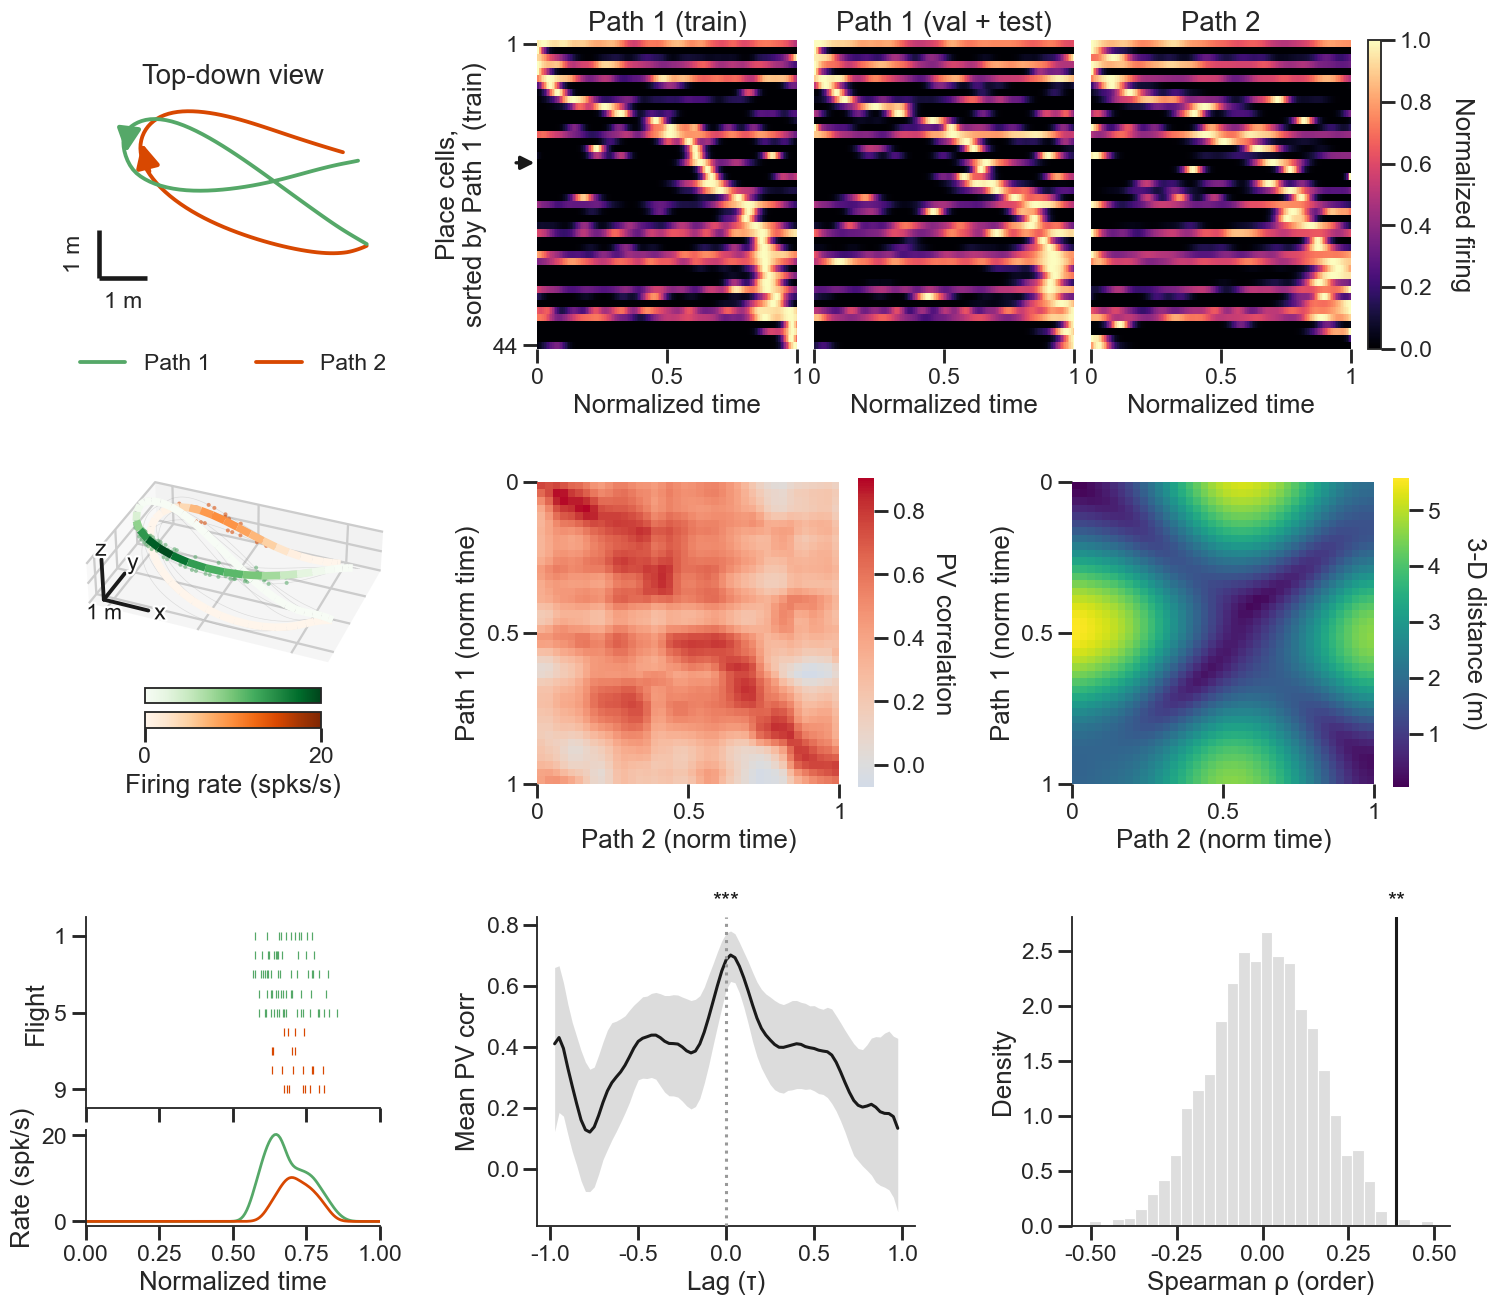

Figure 3 — Dataset_1_32622_231007 (bat 32622): Path 1 = cl 1 vs Path 2 = cl 3 [reward→reward], Fréchet 1.7 m, 44 place cells; example unit 75. Bottom row: observed statistic (red) vs shuffle null (grey).
Sequence-preservation tests (one-sided shuffle p):
               session                                         test   obs  obs_far  peakstat         p  n_place stars         P
Dataset_1_32622_231007               PV lag-0 peak (circular-shift) 0.686    0.273     0.413 0.0004998       44   *** P < 0.001
Dataset_1_32622_231007                           Spearman ρ (order)  0.39      NaN       NaN  0.004498       44    ** P = 0.004
Dataset_1_32622_231007 Spearman ρ (order, Path 1 train vs val+test) 0.916      NaN       NaN 0.0004998       44   *** P < 0.001


,session,test,obs,obs_far,peakstat,p,n_place,stars,P
0,Dataset_1_32622_231007,PV lag-0 peak (circular-shift),0.686,0.273,0.413,0.000500,44,***,P < 0.001
1,Dataset_1_32622_231007,Spearman ρ (order),0.390,NaN,NaN,0.004498,44,**,P = 0.004
2,Dataset_1_32622_231007,"Spearman ρ (order, Path 1 train vs val+test)",0.916,NaN,NaN,0.000500,44,***,P < 0.001


In [34]:
# === Figure 3 + ED Fig 5 curated same-route examples (hand-picked from the loosened
# search). Path 1 = REF (more flights), Path 2 = ALT (+ any merged alt clusters).
# Dataset_3_00000_240405 is excluded from the ED Fig 5 set. ===
def _pair_row(session, cluster_a, cluster_b):
    ci = session_data_cache[session]['cluster_info']
    _route = (_endpoint_label(session, ci[cluster_a]['mean_traj'][0]) + '\u2192' +
              _endpoint_label(session, ci[cluster_a]['mean_traj'][-1]))
    return dict(session=session, bat=parse_bat(session), cluster_a=cluster_a, cluster_b=cluster_b,
                n_flights_a=ci[cluster_a]['n_flights'], n_flights_b=ci[cluster_b]['n_flights'],
                frechet=float(_frechet_d(ci[cluster_a]['mean_traj'], ci[cluster_b]['mean_traj'])),
                route_type=_route)

# Main figure: one same-route pair, Path 1 vs Path 2 only (no different-route Path 3).
FIG3_PAIR = dict(session='Dataset_1_32622_231007', cluster_a=1, cluster_b=3, merge_alt=None, unit=75)
# ED Fig 5: three sessions, one pair each; Dataset_2 merges alt clusters 1 & 2 vs cluster 3.
ED6_PAIRS = [
    dict(session='Dataset_1_32622_231010', cluster_a=10, cluster_b=11, merge_alt=None, unit=5),
    dict(session='Dataset_1_32622_231009', cluster_a=15, cluster_b=16, merge_alt=None, unit=33),
    dict(session='Dataset_2_14445_231209', cluster_a=1,  cluster_b=3,  merge_alt=[2],  unit=30),
]

res0 = _route_example(
    0, pairs_df=pd.DataFrame([_pair_row(FIG3_PAIR['session'], FIG3_PAIR['cluster_a'], FIG3_PAIR['cluster_b'])]),
    merge_alt=FIG3_PAIR['merge_alt'], force_neuron=FIG3_PAIR['unit'])
p3 = plot_route_example(res0, 'fig3_route_example0', show_path3=False)
print(f'Figure 3 \u2014 {res0["session"]} (bat {res0["bat"]}): Path 1 = cl {res0["REF"]} vs '
      f'Path 2 = cl {res0["ALT"]} [{res0["route"]}], Fr\u00e9chet {res0["frechet"]:.1f} m, '
      f'{res0["n_place"]} place cells; example unit {FIG3_PAIR["unit"]}. '
      f'Bottom row: observed statistic (red) vs shuffle null (grey).')
print('Sequence-preservation tests (one-sided shuffle p):')
ph.p_table(p3)


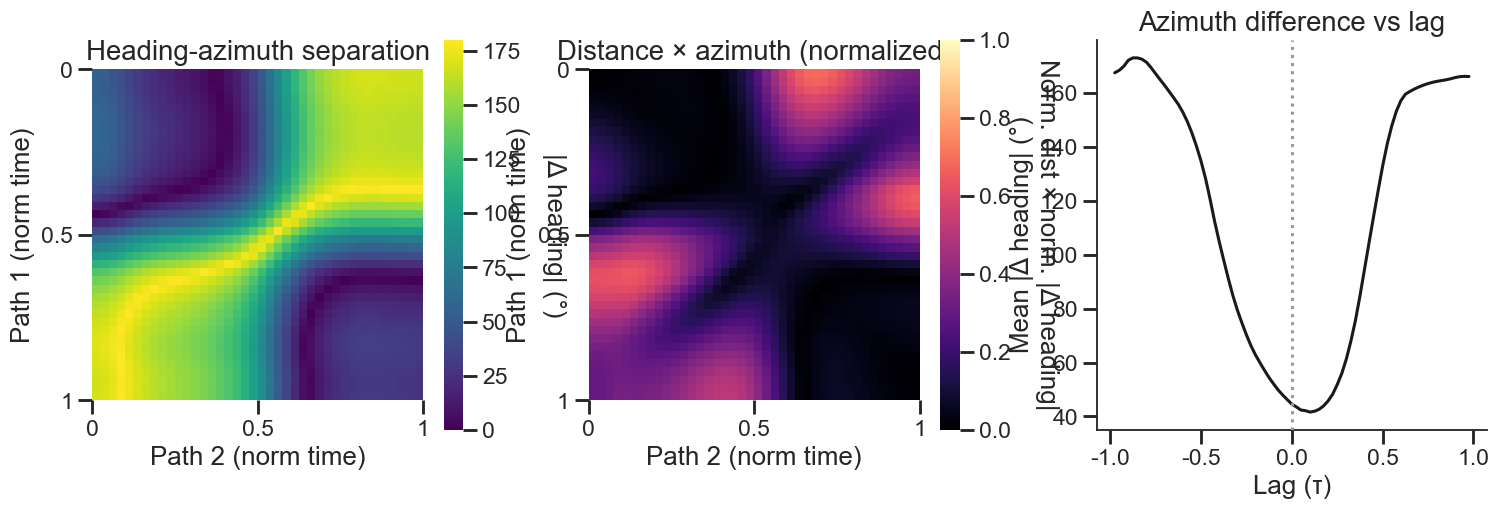

Azimuth control — Dataset_1_32622_231007 (bat 32622): Path 1 cl 1 vs Path 2 cl 3. Matched-time |Δ heading|: mean 45°, max 170° (at t*=0.33); min mean-|Δ heading|-vs-lag = 42° at τ=+0.10. Matched-time norm. dist × norm. |Δ heading|: mean 0.04, max 0.12.


In [35]:
# === Figure 3 — lagged AZIMUTH comparison (behavioral geometric control) ===
# Companion to the PV-corr matrix / mean-PV-corr-vs-lag (panels E, G) and the 3-D
# Euclidean path-separation matrix (panel F). Azimuth = horizontal flight heading,
# atan2(v_y, v_x) of the resampled mean path. We build the (Path-1 bin i x Path-2
# bin j) matrix of absolute angular heading DIFFERENCE (analogous to pv_dist), and
# the mean heading difference vs lag (analogous to mean PV corr vs lag). Place-cell
# sequences realign at tau=0 (PV corr peaks) even though the paths' heading geometry
# differs, so |Delta heading| at tau=0 stays large -> the neural sequence is not just
# inherited from matched heading, the same point the 3-D distance makes.
SHOW_P3_AZ = False  # match published Fig 3 (Path 1 vs Path 2 only); True adds the different-route contrast


def _azimuth(traj_rs):
    """Horizontal heading (radians) at each resampled bin of an (n, 3) mean path."""
    v = np.gradient(traj_rs[:, :2], axis=0)
    return np.arctan2(v[:, 1], v[:, 0])


def _azim_diff_matrix(traj_a, traj_b):
    """|angular heading difference| (degrees, 0..180): path a headings (rows) vs b (cols)."""
    d = _azimuth(traj_a)[:, None] - _azimuth(traj_b)[None, :]
    return np.degrees(np.abs((d + np.pi) % (2 * np.pi) - np.pi))  # wrap to [0, pi]


res = res0  # Fig 3 main same-route pair (Path 1 = REF, Path 2 = ALT)
azim_mat = _azim_diff_matrix(res['traj_ref_rs'], res['traj_alt_rs'])
_nlag_az = azim_mat.shape[0]; _lags_int_az = np.arange(-_nlag_az + 1, _nlag_az)
azim_lag = np.array([np.nanmean(np.diagonal(azim_mat, offset=k)) for k in _lags_int_az])
azim_diag = np.diagonal(azim_mat).copy()  # matched-time heading difference (0-lag diagonal)
lags_frac_az = _lags_int_az / _nlag_az

_has3_az = SHOW_P3_AZ and res.get('traj_third_rs') is not None
if _has3_az:
    azim_mat3 = _azim_diff_matrix(res['traj_ref_rs'], res['traj_third_rs'])
    azim_lag3 = np.array([np.nanmean(np.diagonal(azim_mat3, offset=k)) for k in _lags_int_az])

# distance x azimuth product matrix: rescale each factor to [0, 1] (1 = its own max
# over the matrix) so 3-D separation and heading divergence share one absolute scale,
# then multiply -> dimensionless "geometric dissimilarity" in [0, 1], high only where
# the paths differ in BOTH position and heading at that (Path-1 i, Path-2 j) bin pair.
_dist_n = res['pv_dist'] / max(res['pv_dist'].max(), 1e-9)
_azim_n = azim_mat / max(azim_mat.max(), 1e-9)
prod_mat = _dist_n * _azim_n  # same (Path-1 i x Path-2 j) indexing as both factors
prod_diag = np.diagonal(prod_mat).copy()

pal = sns.color_palette(); c_p1, c_p3 = pal[2], pal[0]  # match plot_route_example
_axl_s = 'norm pos' if AP_PHASE == 'space' else 'norm time'
_tk_az = [0, _nlag_az / 2, _nlag_az]; _tl_az = ['0', '0.5', '1']


def _sep_axes(ax):  # shared normalized-time tick styling for the two separation matrices
    ax.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax.set_xticks(_tk_az); ax.set_xticklabels(_tl_az, rotation=0)
    ax.set_yticks(_tk_az); ax.set_yticklabels(_tl_az, rotation=0)
    ax.set_box_aspect(1)


fig, (ax_m, ax_p, ax_l) = plt.subplots(1, 3, figsize=(16.5, 4.6))
# (left) heading-azimuth separation matrix (Path 1 rows x Path 2 cols) -- parallels panel F
sns.heatmap(azim_mat, ax=ax_m, cmap='viridis', vmin=0, vmax=180, xticklabels=False, yticklabels=False,
            cbar_kws=dict(label='|Δ heading| (°)'))
ax_m.collections[0].colorbar.set_label('|Δ heading| (°)', rotation=270, labelpad=14, va='bottom')
ax_m.set_title('Heading-azimuth separation'); _sep_axes(ax_m)
# (middle) distance x azimuth product matrix (each factor normalized to [0, 1])
sns.heatmap(prod_mat, ax=ax_p, cmap='magma', vmin=0, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws=dict(label='norm. dist × norm. |Δ heading|'))
ax_p.collections[0].colorbar.set_label('norm. dist × norm. |Δ heading|', rotation=270, labelpad=16, va='bottom')
ax_p.set_title('Distance × azimuth (normalized)'); _sep_axes(ax_p)
# (right) mean |Delta heading| vs lag -- parallels panel G (mean PV corr vs lag)
ax_l.plot(lags_frac_az, azim_lag, color='k', label='same route')
if _has3_az:
    ax_l.plot(lags_frac_az, azim_lag3, color=c_p3, ls='--', label='different route')
ax_l.axvline(0, color='0.6', ls=':', zorder=4)  # tau=0 reference
ax_l.set(xlabel='lag (τ)', ylabel='mean |Δ heading| (°)', title='Azimuth difference vs lag')
ax_l.set_box_aspect(1)
if _has3_az:
    ax_l.legend(frameon=False, fontsize=plt.rcParams['xtick.labelsize'])
ph.save_fig(fig, 'fig3_azimuth_lag'); plt.show()
print(f'Azimuth control — {res["session"]} (bat {res["bat"]}): Path 1 cl {res["REF"]} vs '
      f'Path 2 cl {res["ALT"]}. Matched-time |Δ heading|: mean {azim_diag.mean():.0f}°, '
      f'max {azim_diag.max():.0f}° (at t*={res["t_star"] / _nlag_az:.2f}); '
      f'min mean-|Δ heading|-vs-lag = {azim_lag.min():.0f}° at τ={lags_frac_az[np.argmin(azim_lag)]:+.2f}. '
      f'Matched-time norm. dist × norm. |Δ heading|: mean {prod_diag.mean():.2f}, max {prod_diag.max():.2f}.')


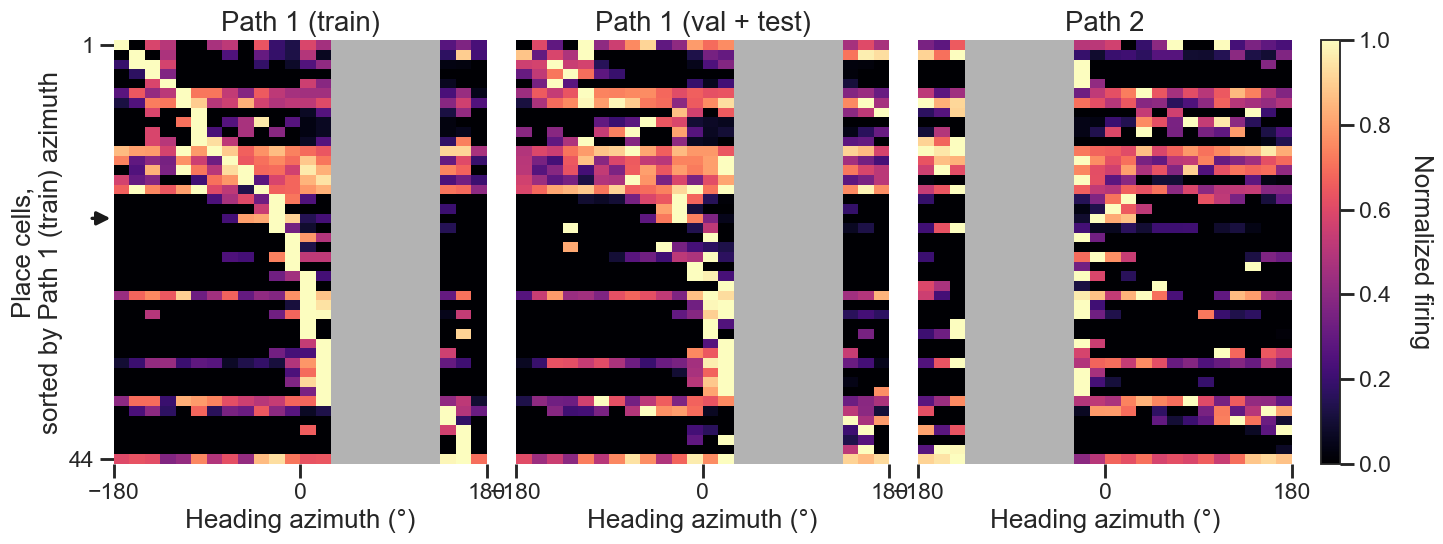

Azimuth-axis sequence heatmaps — Dataset_1_32622_231007 (bat 32622): Path 1 cl 1 (train n=2, val+test n=3) vs Path 2 cl 3 (n=4); 44 place cells sorted by Path-1-train heading-azimuth peak; 24 azimuth bins.


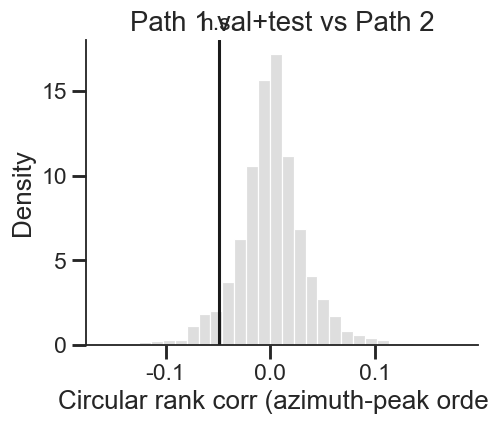

Azimuth-peak order — Fisher-Lee circular rank corr (label-permutation p, 44 place cells):
  Path 1 train vs Path 2       r=-0.007  p=0.6207  n.s.
  Path 1 val+test vs Path 2    r=-0.049  p=0.9400  n.s.
  Path 1 train vs val+test     r=+0.417  p=0.0005  ***


In [36]:
# === Figure 3 — panel B recomputed on a HEADING-AZIMUTH axis (standalone) ===
# Same three-way sequence-heatmap comparison as Fig 3B (Path 1 train / Path 1 val+test /
# Path 2), but the normalized-TIME tuning axis is replaced by binned heading azimuth
# (atan2 of horizontal velocity). Place cells are sorted by their Path-1-TRAIN azimuth
# peak and that single order is reused across all panels, exactly as panel B sorts by
# the Path-1-train time peak. Rebuilt standalone from session_data_cache + res0.
N_AZ = 24  # heading-azimuth bins over [-180, 180)
_az_edges = np.linspace(-np.pi, np.pi, N_AZ + 1); _az_ctr = (_az_edges[:-1] + _az_edges[1:]) / 2

_sess = res0['session']; _REF, _ALT = res0['REF'], res0['ALT']
_d = session_data_cache[_sess]['data']; _dff = session_data_cache[_sess]['df_flights']
_nu = len(_d['spike_times']); _dt_az = 1.0 / _d['Fs']
_alt_ids = [_ALT] + [int(c) for c in (FIG3_PAIR.get('merge_alt') or [])]  # match the figure's Path 2 merge


def _flight_heading(fs, fe):
    """Per-sample horizontal heading azimuth (radians) over a flight's frames."""
    v = np.gradient(_d['r'][fs:fe + 1, :2], axis=0)
    return np.arctan2(v[:, 1], v[:, 0])


def _azimuth_map(fldf):
    """Per-neuron firing rate (spikes/s) over heading-azimuth bins, occupancy-normalized.
    Spike headings are interpolated from the unwrapped per-sample heading, then re-wrapped.
    Bins the bat never occupied on these flights are returned as NaN (not 0), so they are
    excluded from row-normalization, peak selection, and shown blank in the heatmap."""
    occ = np.zeros(N_AZ); sp = np.zeros((_nu, N_AZ))
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop); ft = _d['t'][fs:fe + 1]
        az = _flight_heading(fs, fe); az_u = np.unwrap(az)
        occ += np.histogram(az, bins=_az_edges)[0] * _dt_az
        for u in range(_nu):
            st = _d['spike_times'][u]; stf = st[(st >= ft[0]) & (st <= ft[-1])]
            if len(stf):
                saz = (np.interp(stf, ft, az_u) + np.pi) % (2 * np.pi) - np.pi
                sp[u] += np.histogram(saz, bins=_az_edges)[0]
    rate = np.full((_nu, N_AZ), np.nan)
    _occd = occ > 0
    rate[:, _occd] = sp[:, _occd] / occ[_occd]
    return rate


# reconstruct the exact Path-1 train / val+test split used by _route_example (seed_=1)
_seed = 1
_ref_all = _dff[_dff.cluster_id == _REF].sample(frac=1.0, random_state=_seed).reset_index(drop=True)
_nR = len(_ref_all); _j1 = int(round(0.5 * _nR))
_tr = _ref_all.iloc[:_j1]; _vt = _ref_all.iloc[_j1:]          # train vs held-out val+test
_alt_df = _dff[_dff.cluster_id.isin(_alt_ids)]                 # Path 2 (same route)

_az_train, _az_valtest, _az_alt = _azimuth_map(_tr), _azimuth_map(_vt), _azimuth_map(_alt_df)

# place cells = the figure's set (res0['order']); re-sort by Path-1-TRAIN azimuth peak
# (nanargmax over occupied bins only)
_pc = np.asarray(res0['order'], dtype=int)
_az_order = _pc[np.argsort(np.nanargmax(_az_train[_pc], axis=1))] if len(_pc) else _pc

_az_panels = [(_az_train, 'Path 1 (train)'), (_az_valtest, 'Path 1 (val + test)'), (_az_alt, 'Path 2')]
_nh = len(_az_panels)

fig = plt.figure(figsize=(5.2 * _nh, 5))
gs = fig.add_gridspec(1, _nh + 2, width_ratios=[1] * _nh + [0.05, 0.2], wspace=0.12)
_axes = [fig.add_subplot(gs[0, i]) for i in range(_nh)]
_cax = fig.add_subplot(gs[0, _nh])
_az_cmap = plt.get_cmap('magma').copy(); _az_cmap.set_bad('0.7')  # unoccupied (NaN) azimuth bins -> grey
for k, (M, name) in enumerate(_az_panels):
    ax = _axes[k]
    ax.set_facecolor('0.7')  # backstop so masked NaN cells read as grey, not white
    H = M[_az_order] / np.maximum(np.nanmax(M[_az_order], axis=1, keepdims=True), 1e-9) if len(_az_order) else M[:0]
    sns.heatmap(H, ax=ax, cmap=_az_cmap, vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=False)
    ax.set(xlabel='heading azimuth (°)', title=name)
    ax.set_xticks([0, N_AZ / 2, N_AZ]); ax.set_xticklabels(['−180', '0', '180'], rotation=0)
    if k == 0 and len(_az_order):
        ax.set_ylabel('Place cells,\nsorted by Path 1 (train) azimuth')
        ax.set_yticks([0.5, len(_az_order) - 0.5]); ax.set_yticklabels(['1', str(len(_az_order))], rotation=0)
    else:
        ax.set_ylabel('')
# example-unit arrow (same neuron as Fig 3), if it is a place cell in the sorted order
if res0['neuron'] is not None and len(_az_order):
    _sr = np.where(_az_order == res0['neuron'])[0]
    if len(_sr):
        _axes[0].annotate('', xy=(0, _sr[0] + 0.5), xytext=(-16, 0), textcoords='offset points',
                          xycoords='data', va='center', annotation_clip=False, zorder=6,
                          arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2))
if len(_az_order):
    cb = fig.colorbar(_axes[-1].collections[0], cax=_cax)
    cb.set_label('normalized firing', rotation=270, labelpad=12, va='bottom')
else:
    _cax.axis('off')
ph.save_fig(fig, 'fig3_azimuth_seq_heatmaps'); plt.show()
print(f'Azimuth-axis sequence heatmaps — {_sess} (bat {res0["bat"]}): Path 1 cl {_REF} '
      f'(train n={len(_tr)}, val+test n={len(_vt)}) vs Path 2 cl {_ALT} (n={len(_alt_df)}); '
      f'{len(_az_order)} place cells sorted by Path-1-train heading-azimuth peak; {N_AZ} azimuth bins.')

# --- circular rank-correlation test on the azimuth-peak ORDERING (circular analog of
#     Fig 3 panel H's Spearman order test) ---
# Heading azimuth is circular, so a linear Spearman on peak-bin index is not rotation
# invariant (a route straddling the ±180° seam would be distorted). Instead we use the
# Fisher-Lee (1982) circular rank correlation: replace each place cell's peak heading by
# its circular rank (uniform score C_i = 2π·rank_i/n), then correlate the two paths with
# the pairwise-sine statistic  r = Σ_ij sin(C_i−C_j) sin(D_i−D_j) /
# sqrt(Σ sin²(C_i−C_j) · Σ sin²(D_i−D_j)).  This is rank-based AND invariant to rotation of
# either variable (a common shift of the circular ranks cancels in the sine differences).
# Significance by the same label-permutation null + one-sided _p as panel H.
from scipy.stats import rankdata as _rankdata_az
_rng_az = np.random.default_rng(_seed)
def _pval_az(obs, nul):
    return float((1 + np.sum(np.asarray(nul) >= obs)) / (len(nul) + 1))

def _circ_rank_corr(a, b):
    """Fisher-Lee circular rank correlation between two sets of angles (radians)."""
    n = len(a)
    Ca = 2 * np.pi * _rankdata_az(a, method='average') / n  # circular ranks (uniform scores)
    Cb = 2 * np.pi * _rankdata_az(b, method='average') / n
    sA = np.sin(Ca[:, None] - Ca[None, :]); sB = np.sin(Cb[:, None] - Cb[None, :])
    den = np.sqrt((sA ** 2).sum() * (sB ** 2).sum())
    return float((sA * sB).sum() / den) if den > 0 else np.nan

# peak heading (bin-center angle, radians) per place cell on each path (occupied bins only)
_th_tr = _az_ctr[np.nanargmax(_az_train[_pc], axis=1)]; _th_vt = _az_ctr[np.nanargmax(_az_valtest[_pc], axis=1)]
_th_alt = _az_ctr[np.nanargmax(_az_alt[_pc], axis=1)]
_stars_az = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
if len(_pc) >= 4:
    _az_tests = []
    for _lab, _x, _y in [('Path 1 train vs Path 2', _th_tr, _th_alt),
                         ('Path 1 val+test vs Path 2', _th_vt, _th_alt),
                         ('Path 1 train vs val+test', _th_tr, _th_vt)]:
        _r = _circ_rank_corr(_x, _y)
        _nul = [_circ_rank_corr(_x, _rng_az.permutation(_y)) for _ in range(AP_N_SHUF_SEQ)]
        _az_tests.append(dict(test=_lab, r=round(_r, 3), p=_pval_az(_r, _nul), null=_nul))
    # headline panel: held-out Path 1 (val+test) vs Path 2 — the cross-route order-preservation
    # test that avoids the selection/sort bias of the train split (matches panel H's choice)
    _hl = _az_tests[1]
    figt, axt = plt.subplots(figsize=(4.6, 3.6))
    sns.histplot(_hl['null'], bins=30, ax=axt, color='lightgray', stat='density')
    axt.axvline(_hl['r'], color='k', lw=2)
    axt.text(_hl['r'], 1.02, _stars_az(_hl['p']), transform=axt.get_xaxis_transform(),
             ha='center', va='bottom', fontsize=plt.rcParams['xtick.labelsize'])
    axt.set(xlabel='circular rank corr (azimuth-peak order)', title=_hl['test'])
    ph.save_fig(figt, 'fig3_azimuth_order_circcorr'); plt.show()
    print(f'Azimuth-peak order — Fisher-Lee circular rank corr (label-permutation p, {len(_pc)} place cells):')
    for _t in _az_tests:
        print(f'  {_t["test"]:<28s} r={_t["r"]:+.3f}  p={_t["p"]:.4f}  {_stars_az(_t["p"])}')
else:
    print(f'Only {len(_pc)} place cells (<4); skipping azimuth-order circular rank corr test.')


**Figure 3 | Latent dynamics expose novel features of single-neuron tuning.** (A) Top-down (x–y) view of the two example mean flight paths — Path 1 (green) and Path 2 (orange), which share a start and end but take different paths between them — with arrows indicating travel direction. (B) Rate map of an example unit: its firing rate (color) drawn along Path 1 and 2 mean flight paths in 3-D (Greens/Oranges), with individual spikes as dots. The unit fires differently on the two paths as a function of spatial position. (C) Per-flight normalized-time spike raster (\textit{top}) and mean firing-rate tuning curves (\textit{bottom}) for the same unit on Path 1 (green) and Path 2 (orange) reveal that it fires at a similar normalized time on both paths despite their spatial divergence. (D) Firing-rate sequences of all place cells ($n$ = 44 place cells) in normalized flight time on the Path 1 training flights (\textit{left}), the held-out Path 1 validation + test flights (\textit{middle}), and all Path 2 flights (\textit{right}); each cell's rate is normalized to its own peak and cells are sorted by their peak time on the Path 1 training flights, so the leftmost panel is diagonal by construction. The peak-time order is highly preserved between the Path 1 training and held-out flights (Spearman $\rho$ = 0.916, $P = 5.00 \times 10^{-4}$), as well as between Path 1 and Path 2 flights (Spearman $\rho$ = 0.390, $P = 4.50 \times 10^{-3}$). The arrowhead marks the example unit in (B, C). (E) Population-vector (PV) correlation between Path 1 (rows) and Path 2 (columns) across normalized-time bins shows strong correlations along the main diagonal. (F) 3-D Euclidean distance between the Path 1 and Path 2 mean positions at each pair of normalized-time bins. Note the strong anti-diagonal band, which is not present in the PV correlation matrix, showing a dissociation between spatial position and population coding. (G) Mean PV correlation along each lag diagonal versus lag $\tau$ (normalized time), with 95\% bands from bootstrapping over place cells. Significance is a circular-shift permutation test that the $\tau$ = 0 value is a genuine peak above the lag $\geq$ 0.5 baseline (observed peak PV correlation $r$ = 0.686, $P = 5.00 \times 10^{-4}$). (H) Distribution of the Spearman rank correlation of place-cell peak-time order under a peak-order shuffle null (gray), with the observed value from (D), \textit{right}. Place cells are those with significant cross-validated route-progress spatial information on the Path 1 reference (per-cell one-sided $P < 0.025$ against 100 circular-shift shuffles of held-out flights, peak rate $\geq$ 1 Hz, positive spatial information). Permutation tests use 2,000 iterations; the PV-vs-lag bands use 500 place-cell bootstraps. See also Figure \ref{fig:S5} for additional examples.

---
## Extended Data Figure 5 — same route, different paths (other examples)

The other four same-route different-path pairs, each arranged identically to
Figure 3 and labeled by bat.

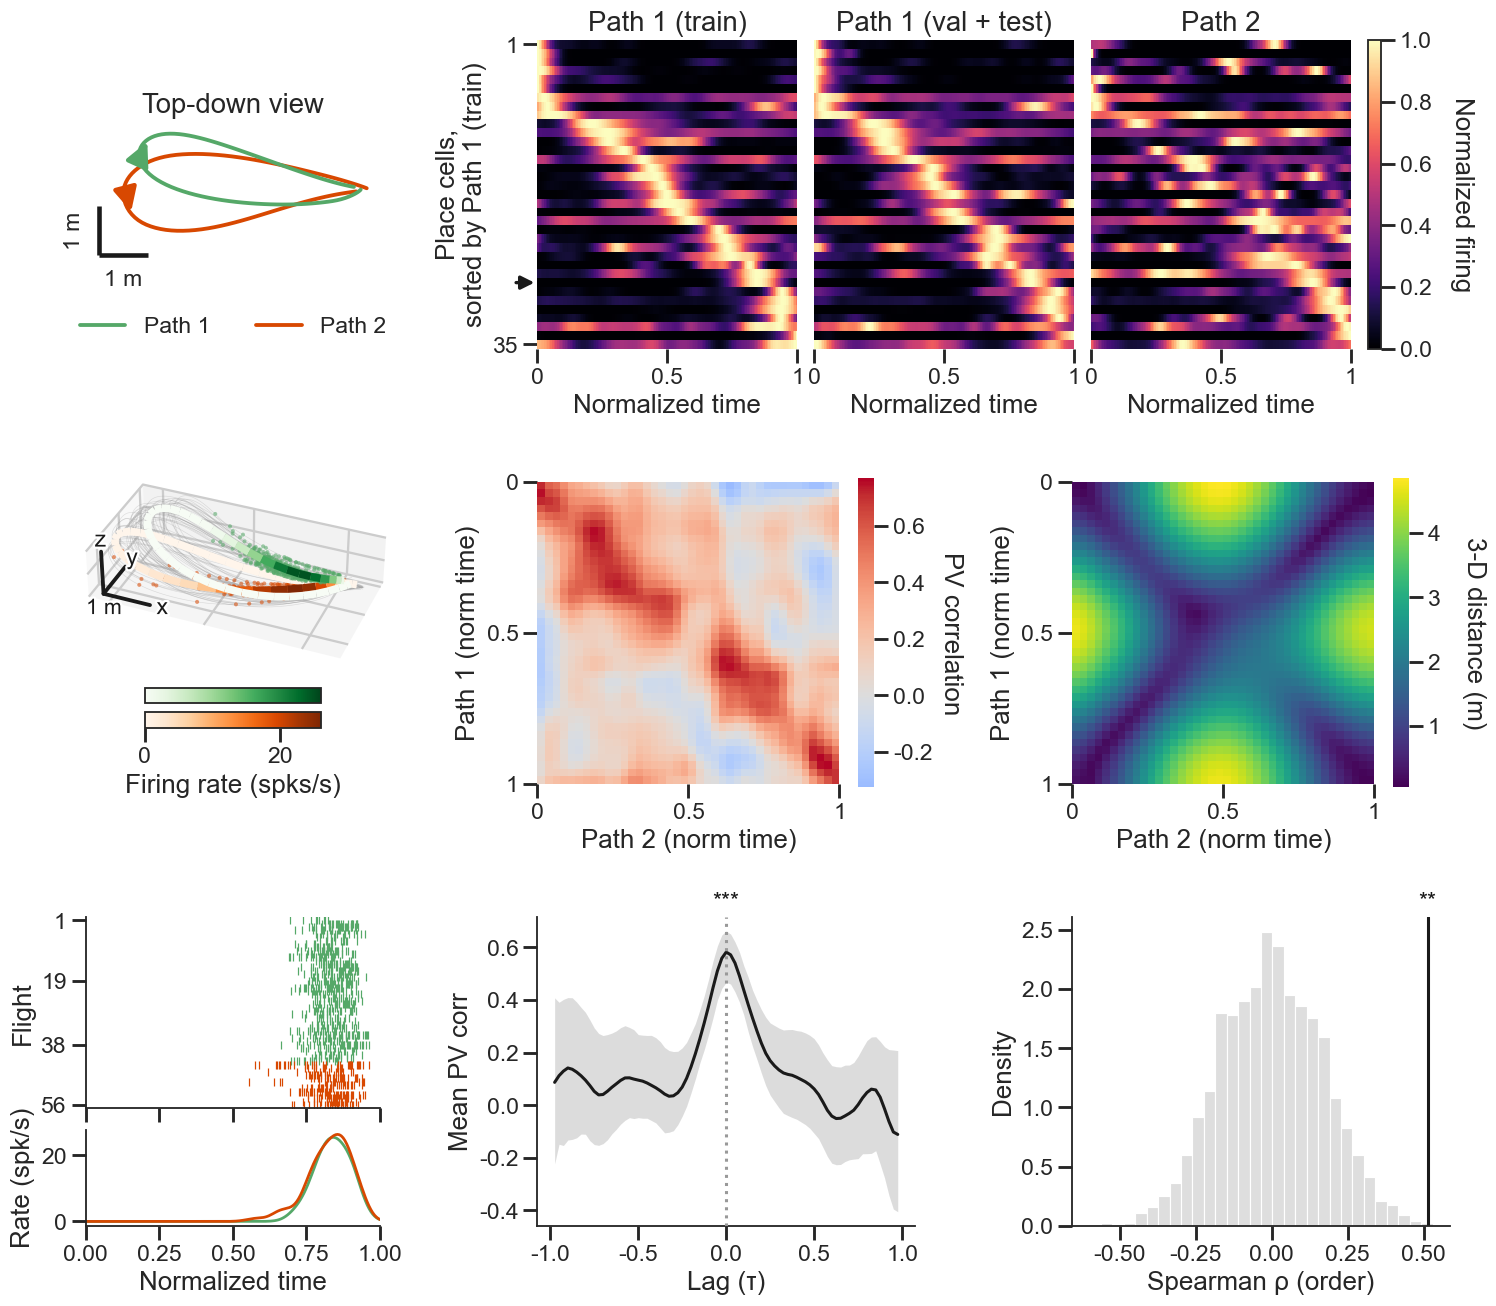

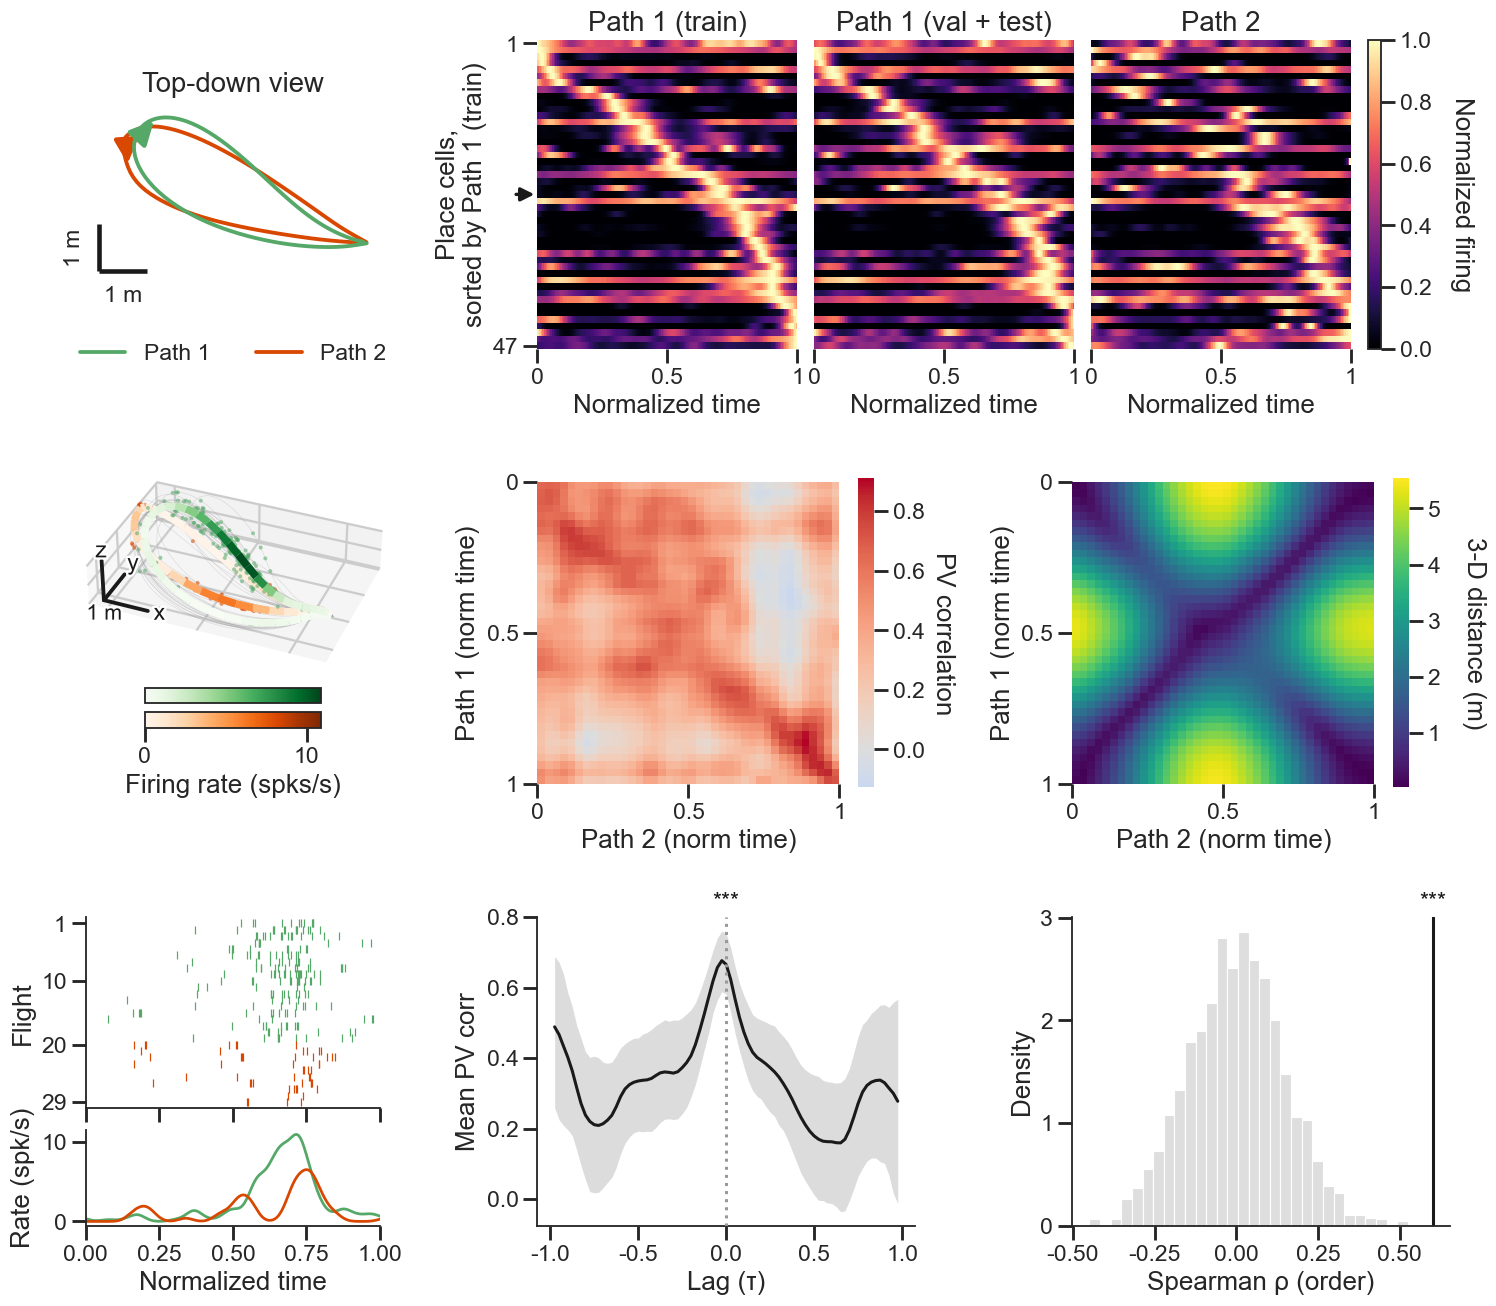

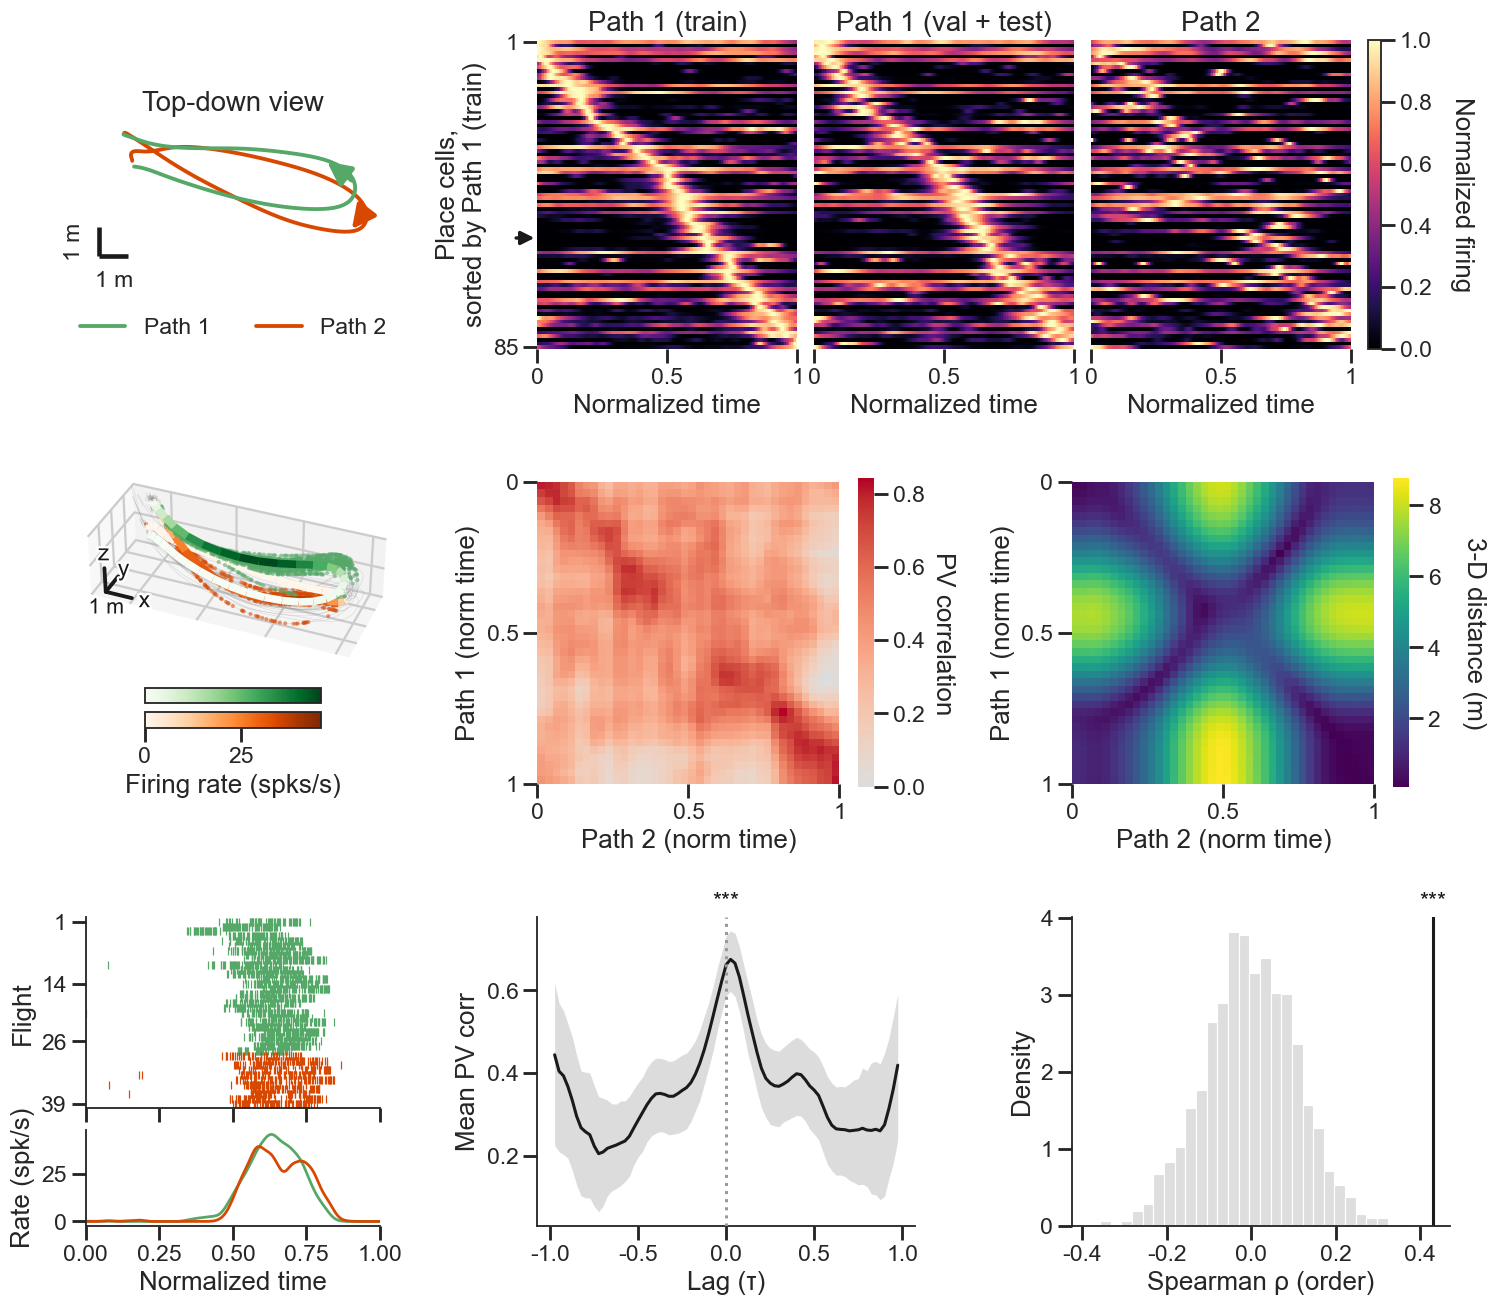

ED Fig 5 — sequence-preservation tests (one-sided shuffle p):
               session                                         test   obs  obs_far  peakstat         p  n_place stars         P
Dataset_1_32622_231010               PV lag-0 peak (circular-shift) 0.582    0.041     0.541 0.0004998       35   *** P < 0.001
Dataset_1_32622_231010                           Spearman ρ (order) 0.513      NaN       NaN  0.001999       35    ** P = 0.002
Dataset_1_32622_231010 Spearman ρ (order, Path 1 train vs val+test) 0.765      NaN       NaN 0.0004998       35   *** P < 0.001
Dataset_1_32622_231009               PV lag-0 peak (circular-shift) 0.666    0.276      0.39 0.0004998       47   *** P < 0.001
Dataset_1_32622_231009                           Spearman ρ (order) 0.601      NaN       NaN 0.0004998       47   *** P < 0.001
Dataset_1_32622_231009 Spearman ρ (order, Path 1 train vs val+test) 0.909      NaN       NaN 0.0004998       47   *** P < 0.001
Dataset_2_14445_231209               PV la

In [37]:
# ED Fig 5: three curated same-route examples (Path 1 vs Path 2 only, no Path-3 contrast),
# one pair per session, from the loosened search with Dataset_3_00000_240405 excluded and
# Dataset_2_14445_231209 alt clusters 1 & 2 merged vs cluster 3 (see FIG3/ED6_PAIRS above).
ed6_records = []
for spec in ED6_PAIRS:
    _df = pd.DataFrame([_pair_row(spec['session'], spec['cluster_a'], spec['cluster_b'])])
    _res = _route_example(0, pairs_df=_df, merge_alt=spec['merge_alt'], force_neuron=spec['unit'])
    ed6_records.extend(plot_route_example(_res, f"edfig5_route_example_{spec['session']}", show_path3=False))
if ed6_records:
    print('ED Fig 5 \u2014 sequence-preservation tests (one-sided shuffle p):')
    ph.p_table(ed6_records)


**Extended Data Figure 5 | Additional examples of similar single-neuron tuning along geometrically different paths that share an origin and destination.** Each subpanel as in Figure \ref{fig:fig3}. Per example, the zero-lag PV correlation (G), the Spearman order correlation (H), and the within-route Path 1 train vs. held-out order correlation: (i) bat 32622 — zero-lag PV correlation = 0.582 ($P = 5.00 \times 10^{-4}$), Spearman $\rho$ = 0.513 ($P = 2.00 \times 10^{-3}$), within-route Spearman $\rho$ 0.765 ($P = 5.00 \times 10^{-4}$), n = 35 place cells; (ii) bat 14445 — zero-lag PV correlation = 0.622 ($P = 5.00 \times 10^{-4}$), Spearman $\rho$ = 0.430 ($P = 5.00 \times 10^{-4}$), within-route Spearman $\rho$ 0.747 ($P = 5.00 \times 10^{-4}$), n = 85 place cells. See also Figure \ref{fig:fig3}.

---
## Figure 4 — Readout weights surface correlations in spatial and non-spatial activity

**a** PC1 of the readout-weight matrix vs mean firing rate, per session (vs random-direction null). **b** Residual-readout hierarchical clustering as a vertical stack (dendrogram over the cosine-similarity matrix over the residual readout-weight matrix, 64-d latent vertical). **c** Spatial information per readout cluster. **d** Example neural$\to$position attribution (Jacobian) matrix over time (upper = future/prospective, lower = past/retrospective). **e** Future-past attribution index by cluster. **f** Residual readouts predict CA1 vs CA3 membership (per-session SVM swarm vs shuffle null). **g** Example sleep-matched session: Non-flight FR, Sleep FR (near-identical), residual readout, rate-map and coupling similarity matrices. **h** MRM marginal $R^{2}$ of each predictor against non-flight rest. **i** MRM unique (semipartial) $R^{2}$ of each predictor. **j–l** MRM unique $R^{2}$ within CA1 vs CA3 for residual readout (**j**), rate map (**k**) and coupling (**l**).

> Panels **g–l** build the rate-map, non-flight-rest and coupling similarity streams directly (rate maps from flight spikes; non-flight from a per-session `Data_Prep` load; coupling from the GLM+history+coupling checkpoint). The **sleep** matrix (2nd panel of **g**) matches flight units to Dataset_0 sleep units via UnitMatch `MatchTable.csv` files (guarded — skipped if those / the Dataset_0 spike files are absent); panel **g** is restricted to those matched neurons so Non-flight FR and Sleep FR are directly comparable.

In [38]:
# === Figure 4 foundation: per-neuron readout weights + metadata + subregion ===
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# Per-neuron table: unit-normed readout rows, pType, probe, position, mean FR.
_rows, _W = [], []
for sn in dataloaders['test']:
    W = bat_former.readouts[sn][0].weight.detach().cpu().numpy()   # (K, D)
    pos = np.asarray(meta_info_dict['neuron_position'][sn])
    ptype = np.asarray(meta_info_dict['pType'][sn])
    probe = np.asarray(meta_info_dict['probe_id'][sn])
    # mean FR from test spikes
    yl, ml = [], []
    for b in dataloaders['test'][sn]:
        yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    ya, ma = np.vstack(yl), np.vstack(ml)
    mfr = ya[ma == 1.0].mean(0) / bin_width
    for u in range(W.shape[0]):
        pt = ptype[u] if not isinstance(ptype[u], np.ndarray) else 'filtered'
        _rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, pType=str(pt),
                          probe_id=int(probe[u]), lateral=float(pos[u, 0]),
                          depth=float(pos[u, 1]), mean_fr=float(mfr[u])))
    _W.append(W)
readout_df = pd.DataFrame(_rows)
W_all = np.vstack(_W)
readout_df['readout_weight'] = list(W_all / np.linalg.norm(W_all, axis=1, keepdims=True))

# Attach joint per-neuron corr/FDE (computed for Fig 1g/h).
_jm = encode_metrics_df[encode_metrics_df['model'] == 'joint'][['session', 'unit', 'corr', 'fde']]
readout_df = readout_df.merge(_jm.rename(columns={'corr': 'corr_all', 'fde': 'fde_all'}),
                              on=['session', 'unit'], how='left')


# --- Subregion (CA1/CA3) from per-(bat,probe) depth clumps (internals recipe) ---
CLUMP_HW, PEAK_DIST, HBIN, SM_SIGMA, PROM = 300, 450, 25, 200, 0.04


def detect_clumps(depths):
    if len(depths) < 5:
        return np.array([])
    lo = np.floor(depths.min() / HBIN) * HBIN
    hi = np.ceil(depths.max() / HBIN) * HBIN + HBIN
    counts, edges = np.histogram(depths, bins=np.arange(lo, hi, HBIN))
    centers = 0.5 * (edges[:-1] + edges[1:])
    sm = gaussian_filter1d(counts.astype(float), sigma=SM_SIGMA / HBIN)
    if sm.max() == 0:
        return np.array([])
    padded = np.concatenate([[0.0], sm, [0.0]])
    pk, _ = find_peaks(padded, distance=max(1, PEAK_DIST // HBIN), prominence=PROM * sm.max())
    pk = pk - 1
    pk = pk[(pk >= 0) & (pk < len(sm))]
    if len(pk) == 0:
        pk = np.array([int(np.argmax(sm))])
    if len(pk) > 2:
        pk = pk[np.argsort(sm[pk])[::-1][:2]]
    return np.sort(centers[pk])


def _window(peak, lo, hi):
    a, b = peak - CLUMP_HW, peak + CLUMP_HW
    if b > hi:
        b, a = hi, hi - 2 * CLUMP_HW
    elif a < lo:
        a, b = lo, lo + 2 * CLUMP_HW
    return a, b


readout_df['subregion'] = None
for (bat, probe), grp in readout_df.groupby(['bat', 'probe_id']):
    d = grp['depth'].values
    peaks = detect_clumps(d)
    if len(d) == 0 or len(peaks) == 0:
        continue
    dlo, dhi = float(np.nanmin(d)), float(np.nanmax(d))
    labels = np.array([None] * len(d), dtype=object)
    if len(peaks) == 1:
        a, b = _window(peaks[0], dlo, dhi)
        labels[(d >= a) & (d <= b)] = 'CA1'
    else:
        ventral, dorsal = peaks[0], peaks[-1]
        la, lb = _window(dorsal, dlo, dhi)
        va, vb = _window(ventral, dlo, dhi)
        if vb > la:
            vb, va = la, la - 2 * CLUMP_HW
        labels[(d >= la) & (d <= lb)] = 'CA1'
        labels[(d >= va) & (d <= vb)] = 'CA3'
    readout_df.loc[grp.index, 'subregion'] = labels


def residual_readout(W, fr):
    """Orthogonalize unit-normed readout rows W against the population mean-FR axis (rank-1 deflation), renormalise."""
    ax = W.T @ (fr - fr.mean())
    n = np.linalg.norm(ax)
    Wr = W - np.outer(W @ (ax / n), ax / n) if n > 0 else W.copy()
    rn = np.linalg.norm(Wr, axis=1, keepdims=True); rn[rn == 0] = 1.0
    return Wr / rn


# Well-fit cells (fde_all > 0: encoding model beats the mean-rate baseline), residual readout per session.
clu_df = readout_df[readout_df['fde_all'] > 0.0].copy().reset_index(drop=True)
clu_df['readout_weight_residual'] = clu_df['readout_weight']
for _, grp in clu_df.groupby('session'):
    Wr = residual_readout(np.stack(grp['readout_weight'].values), grp['mean_fr'].values)
    for j, ix in zip(range(len(grp)), grp.index):
        clu_df.at[ix, 'readout_weight_residual'] = Wr[j]
print('readout_df:', len(readout_df), 'neurons |', readout_df['subregion'].notna().sum(),
      'with subregion | clu_df well-fit:', len(clu_df))

readout_df: 3080 neurons | 2938 with subregion | clu_df well-fit: 2147


In [39]:
# === Figure 4b clustering step (compute once; the plotting cell only draws) ===
# Hierarchical clustering of the firing-rate-residual read-out weights across well-fit
# neurons. Produces the leaf order, per-neuron cluster labels, ordered similarity /
# weight matrices, and the dendrogram link-colour map consumed by the Fig 4 plotting
# cell (and by ED Fig 6, which reuses CLUSTER_ORDER / CLUSTER_PALETTE / clu_df['cluster']).
from scipy.cluster.hierarchy import fcluster
from scipy.spatial.distance import pdist
import matplotlib.colors as mcolors

Wr = np.stack(clu_df['readout_weight_residual'].values)       # (N, D), unit-normed
dist = pdist(Wr, metric='cosine')
Z = linkage(dist, method='average')
# Cut the tree fine, then keep only well-populated clusters (matches internals.ipynb:
# the residual read-outs over-split into many singletons, so a low fixed N_CLUSTERS
# lumps distinct groups together). CLUSTER_ORDER is the `included` subset (clusters with
# >= MIN_NEURONS members); every other cluster is greyed out in the dendrogram/strip and
# dropped from the per-cluster panels (here + ED Fig 6, which reuse CLUSTER_ORDER).
N_CLUSTERS = 12
MIN_NEURONS = 200
clu_df['cluster'] = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
_clu_sizes = clu_df['cluster'].value_counts()
CLUSTER_ORDER = sorted(_clu_sizes[_clu_sizes >= MIN_NEURONS].index.astype(int).tolist())
CLUSTER_PALETTE = ph.cluster_palette(CLUSTER_ORDER)
CLUSTER_GREY = (0.7, 0.7, 0.7)
order = dendrogram(Z, no_plot=True)['leaves']
sim_ord = (Wr @ Wr.T)[np.ix_(order, order)]
Wr_ord = Wr[order]
clus_ord = clu_df['cluster'].values[order]
N, D = Wr_ord.shape                                            # neurons, latent dims (64)
XSPAN = 10 * N                                                 # scipy leaf spacing (5,15,...)
# Colour each dendrogram link by its cluster, but only for `included` clusters (grey
# otherwise), so the tree matches the strip + boxplots. A merge keeps a cluster colour
# only when both of its children carry that same cluster label.
_labels_clu = clu_df['cluster'].values
_n_leaf = Z.shape[0] + 1
_node_clu = {i: int(_labels_clu[i]) for i in range(_n_leaf)}
for _i in range(Z.shape[0]):
    _ca, _cb = _node_clu.get(int(Z[_i, 0])), _node_clu.get(int(Z[_i, 1]))
    _node_clu[_n_leaf + _i] = _ca if (_ca is not None and _ca == _cb) else None


def _dendro_link_color(k):
    """Cluster colour for dendrogram link `k`; grey for excluded/mixed clusters."""
    c = _node_clu.get(k)
    return mcolors.to_hex(CLUSTER_PALETTE[c]) if c in CLUSTER_PALETTE else '0.6'


print('cluster sizes:', clu_df['cluster'].value_counts().sort_index().to_dict())
print(f'included clusters (>= {MIN_NEURONS} neurons): {CLUSTER_ORDER}')


cluster sizes: {1: 464, 2: 40, 3: 29, 4: 308, 5: 151, 6: 134, 7: 315, 8: 46, 9: 14, 10: 410, 11: 217, 12: 19}
included clusters (>= 200 neurons): [1, 4, 7, 10, 11]


In [40]:
# === Fig 4d/e data: neural->position attribution (input-gradient Jacobian) ===
# Ported from internals.ipynb (prosp_attribution / attr_example_matrix). The encoder is a
# NON-causal transformer, so rate at time i can draw on position at past AND future j. For
# each test flight we take the input-gradient attribution A[i, n, j] = ||d rate(i,n)/d pos(j)||
# (norm over x,y,z), and summarise each neuron by the scale-free future-past contrast
# (UP - LO)/(UP + LO) of the upper (future, j>i) vs lower (past) triangle, excluding
# |i-j| <= EXCL bins around the diagonal. UP/LO sums are POOLED across all test flights.
# >0 = prospective.
#
# CACHED under ./out/fig4_cache/ in TWO parts: the expensive per-neuron future-past sweep
# (fig4_attr_lookup) and the cheap single-flight example matrix (fig4_attr_example). Splitting
# them means changing the example selection does NOT invalidate the costly sweep. Keys capture
# the joint checkpoint (path + size + mtime), the test session set, T_MAX / EXCL, bin width,
# and (for the lookup) the well-fit neuron list. Set FIG4_FORCE = True to force recompute.
import os, pickle, hashlib
import torch
T_MAX, EXCL = 200, 2
attr_excl_s = float(EXCL * bin_width)   # exclusion half-band (s) either side of the diagonal (= 200 ms)

FIG4_CACHE_DIR = './out/fig4_cache'
os.makedirs(FIG4_CACHE_DIR, exist_ok=True)
FIG4_FORCE = globals().get('FIG4_FORCE', False)


def _ckpt_sig(path):
    if path and os.path.exists(path):
        st = os.stat(path)
        return (os.path.basename(path), int(st.st_size), int(st.st_mtime))
    return (path, None, None)


def _fig4_cache(name, key, compute):
    """Load ./out/fig4_cache/<name>.pkl iff its stored key matches `key`; else compute + save."""
    path = os.path.join(FIG4_CACHE_DIR, name + '.pkl')
    if os.path.exists(path) and not FIG4_FORCE:
        blob = pickle.load(open(path, 'rb'))
        if blob.get('key') == key:
            print(f'  [cache hit] {name}')
            return blob['value']
        print(f'  [cache stale] {name} - recomputing')
    value = compute()
    with open(path, 'wb') as fh:
        pickle.dump(dict(key=key, value=value), fh)
    print(f'  [cache saved] {name}')
    return value


def _cuda_clear():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _flight_attr_sums(sn, x0, m0, vi):
    """Per-neuron pooled future(UP)/past(LO) position-attribution sums for one flight."""
    rows_t = torch.as_tensor(vi, device=x0.device)

    def _f(x):
        return bat_former(sn, x.unsqueeze(0), m0)[0].index_select(0, rows_t)   # (Tv, n)

    J = torch.autograd.functional.jacobian(_f, x0, vectorize=True)             # (Tv, n, T, beh)
    A = J[..., :3].norm(dim=-1)[:, :, vi].detach().cpu().numpy()               # (Tv, n, Tv)
    del J, rows_t
    _cuda_clear()
    Tv = len(vi)
    jj = np.arange(Tv)[None, :] - np.arange(Tv)[:, None]      # j - i
    up, lo = jj > EXCL, jj < -EXCL                            # future / past position
    return (A * up[:, None, :]).sum((0, 2)), (A * lo[:, None, :]).sum((0, 2))


def _flight_attr_matrix(sn, x0, m0, vi):
    rows_t = torch.as_tensor(vi, device=x0.device)

    def _f(x):
        return bat_former(sn, x.unsqueeze(0), m0)[0].index_select(0, rows_t)

    J = torch.autograd.functional.jacobian(_f, x0, vectorize=True)
    A = J[..., :3].norm(dim=-1)[:, :, vi].detach().cpu().numpy()
    del J, rows_t
    _cuda_clear()
    return A


# --- Part 1: per-neuron future-past index over every test flight (expensive; cached) ---
_lookup_key = dict(
    kind='fig4_attr_lookup_v1', joint=_ckpt_sig(JOINT_CKPT),
    sessions=sorted(dataloaders['test'].keys()),
    t_max=int(T_MAX), excl=int(EXCL), bin_width=float(bin_width),
    units=tuple((str(s), int(u)) for s, u in zip(clu_df['session'], clu_df['unit'])),
)


def _compute_lookup():
    bat_former.eval()
    attr_lookup = {}
    for sn in dataloaders['test']:
        up_tot = lo_tot = None
        n_done = 0
        for batch in dataloaders['test'][sn]:
            Xb, Mb = batch.behavior.to(device), batch.mask.to(device)
            for b in range(Xb.shape[0]):
                vi = np.where(batch.mask[b].numpy() == 1.0)[0]
                if len(vi) < 2 * EXCL + 3:
                    continue
                vi = vi[:T_MAX]
                try:
                    us, ls = _flight_attr_sums(sn, Xb[b].detach(), Mb[b:b + 1], vi)
                except RuntimeError as e:
                    print(f'    {sn} flight {n_done}: skipped ({str(e)[:40]})')
                    _cuda_clear()
                    continue
                up_tot = us if up_tot is None else up_tot + us
                lo_tot = ls if lo_tot is None else lo_tot + ls
                n_done += 1
            del Xb, Mb
            _cuda_clear()
        if up_tot is not None:
            with np.errstate(divide='ignore', invalid='ignore'):
                attr_lookup[sn] = np.where(up_tot + lo_tot > 0,
                                           (up_tot - lo_tot) / (up_tot + lo_tot), np.nan)
        print(f'  {sn}: attribution over {n_done} flights')
    return attr_lookup


attr_lookup = _fig4_cache('fig4_attr_lookup', _lookup_key, _compute_lookup)
clu_df['future_idx'] = [attr_lookup[s][int(u)] if (s in attr_lookup and int(u) < len(attr_lookup[s]))
                        else np.nan for s, u in zip(clu_df['session'], clu_df['unit'])]

# --- Part 2: example matrix — illustrative neuron FIXED BY HAND, longest valid test flight
#     in that session (cheap; cached per selected neuron). Chosen: Dataset_3_00000_240404
#     neuron 5 (cluster 5, future_idx ~ +0.11) as a clear prospective example. ---
attr_ex_sn, attr_ex_unit = 'Dataset_3_00000_240404', 5
_exq = clu_df[(clu_df['session'] == attr_ex_sn) & (clu_df['unit'] == attr_ex_unit)]
_ex = _exq.iloc[0] if len(_exq) else dict(future_idx=np.nan)
_ex_key = dict(kind='fig4_attr_example_v1', joint=_ckpt_sig(JOINT_CKPT),
               sn=attr_ex_sn, unit=attr_ex_unit, t_max=int(T_MAX), bin_width=float(bin_width))


def _compute_example():
    bat_former.eval()
    _best = None
    for batch in dataloaders['test'][attr_ex_sn]:
        for b in range(batch.behavior.shape[0]):
            vi = np.where(batch.mask[b].numpy() == 1.0)[0]
            if _best is None or len(vi) > _best[0]:
                _best = (len(vi), batch.behavior[b].detach().to(device),
                         batch.mask[b:b + 1].to(device), vi[:T_MAX])
    A = _flight_attr_matrix(attr_ex_sn, _best[1], _best[2], _best[3])
    return A[:, attr_ex_unit, :]


attr_ex_matrix = np.asarray(_fig4_cache('fig4_attr_example', _ex_key, _compute_example))
attr_ex_ext = float(attr_ex_matrix.shape[0] * bin_width)   # seconds (scalar for imshow extent)
print(f'attribution example: {attr_ex_sn} neuron {attr_ex_unit} '
      f'(future_idx={float(_ex["future_idx"]):+.3f}, fixed example); '
      f'{int(clu_df["future_idx"].notna().sum())} neurons with attribution')

  [cache hit] fig4_attr_lookup
  [cache hit] fig4_attr_example
attribution example: Dataset_3_00000_240404 neuron 5 (future_idx=+0.130, fixed example); 2147 neurons with attribution


In [41]:
# === Fig 4 data streams (panels c, g–l): rate maps, non-flight rest corr, coupling ===
# Ported from internals.ipynb (rate maps, non-flight Data_Prep load, coupling GLM).
from digitalbat.datasets.data import Data_Prep_for_Raw
from notebook_helpers import loc_bin_width_rm

# (1) Per-neuron 2D rate maps (observed spikes / occupancy) per session.
session_rate_maps, session_occ = {}, {}
for sn, sd in dataloaders['test'].items():
    Xl, yl, ml = [], [], []
    for b in sd:
        Xl.append(b.behavior.numpy()); yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    Xa, ya, ma = np.vstack(Xl), np.vstack(yl), np.vstack(ml)
    bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
    xlim, ylim = meta_info_dict['r_lim'][sn][0], meta_info_dict['r_lim'][sn][1]
    xe = np.arange(xlim[0], xlim[1] + loc_bin_width_rm, loc_bin_width_rm)
    ye = np.arange(ylim[0], ylim[1] + loc_bin_width_rm, loc_bin_width_rm)
    v = ma == 1.0
    lx = Xa[:, :, 0][v] * bs[0, 0, 0] + bm[0, 0, 0]
    ly = Xa[:, :, 1][v] * bs[0, 0, 1] + bm[0, 0, 1]
    spk = ya[v]
    occ, _, _ = np.histogram2d(lx, ly, bins=[xe, ye])
    under = occ < 3
    maps = np.full((spk.shape[1], (len(xe) - 1) * (len(ye) - 1)), np.nan)
    for u in range(spk.shape[1]):
        wsum, _, _ = np.histogram2d(lx, ly, bins=[xe, ye], weights=spk[:, u])
        with np.errstate(divide='ignore', invalid='ignore'):
            rm = wsum / (occ * bin_width)
        rm[under] = np.nan
        maps[u] = rm.ravel()
    session_rate_maps[sn] = maps
    session_occ[sn] = occ.ravel()

# (2) Non-flight rest correlation matrices (raw counts) per session.
nonflight_corr = {}
for sn in session_names:
    folder = data_config['parent_folder'] + sn
    su = data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    kw = dict(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
              use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
              use_ripple_flag=False, spike_count_flag=True, bin_width=bin_width)
    try:
        dpf = Data_Prep_for_Raw(only_flight_flag=True, **kw)
        dpf.get_all_behavior(); dpf.get_all_spike()
        dpa = Data_Prep_for_Raw(only_flight_flag=False, **kw)
        dpa.get_all_behavior(); allspk = dpa.get_all_spike()
        nf = np.setdiff1d(np.arange(allspk.shape[1]), dpf.flight_ind)
        nonflight_corr[sn] = np.corrcoef(allspk[:, nf])
    except Exception as exc:
        print(f'  [nonflight skip {sn}] {type(exc).__name__}: {exc}')

# (3) Pairwise coupling similarity from the GLM+hist+coupling checkpoint.
session_coupling_sim = {}
COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_zbasis17.pth'
if os.path.exists(COUP_CKPT):
    cs = torch.load(COUP_CKPT, map_location='cpu', weights_only=False)
    kint = cs['coup_basis'].numpy().sum(0) * bin_width
    for k, v in cs.items():
        if k.startswith('coup_weights.'):
            _csn = k.split('coup_weights.', 1)[1]
            if _csn not in session_names:   # ckpt spans 24 trained sessions; keep only the 17 used here
                continue
            K = v.numpy() @ kint
            np.fill_diagonal(K, 0.0)
            Csym = 0.5 * (K + K.T); np.fill_diagonal(Csym, 0.0)
            session_coupling_sim[_csn] = Csym
print(f'streams: {len(session_rate_maps)} rate-map, {len(nonflight_corr)} non-flight, '
      f'{len(session_coupling_sim)} coupling sessions')


def ratemap_corr_matrix(maps):
    """Pairwise Pearson r between neurons' rate maps over jointly-valid bins."""
    n = maps.shape[0]
    C = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i, n):
            m = np.isfinite(maps[i]) & np.isfinite(maps[j])
            if m.sum() >= 5 and maps[i, m].std() > 0 and maps[j, m].std() > 0:
                C[i, j] = C[j, i] = np.corrcoef(maps[i, m], maps[j, m])[0, 1]
    return C


session_sleep_corr = {}   # populated by the sleep-matching cell below


def session_matrices(sn):
    """Well-fit-neuron submatrices (nonflight, residual readout, rate map, coupling)
    for one session, all ordered by the session's clu_df units. Missing streams -> None."""
    grp = clu_df[clu_df['session'] == sn]
    units = grp['unit'].to_numpy()
    if len(units) < 6 or sn not in nonflight_corr:
        return None
    Wr = np.stack(grp['readout_weight_residual'].values)
    out = dict(units=units, grp=grp,
               nonflight=nonflight_corr[sn][np.ix_(units, units)],
               residual=Wr @ Wr.T,
               ratemap=ratemap_corr_matrix(session_rate_maps[sn][units]),
               coupling=(session_coupling_sim[sn][np.ix_(units, units)]
                         if sn in session_coupling_sim else None),
               sleep=session_sleep_corr.get(sn))
    return out


streams: 17 rate-map, 17 non-flight, 17 coupling sessions


In [42]:
# === Fig 4g sleep matrix: match flight units to Dataset_0 sleep units (UnitMatch) ===
# Ported from internals.ipynb. For each flight session with a sleep pair, map its
# Kilosort cluster ids to the sleep-session (Dataset_0) cluster ids via UnitMatch
# MatchTables, bin the sleep spikes, and build a per-session sleep FR-correlation
# matrix over the well-fit (clu_df) neurons (NaN where unmatched / silent). Guarded:
# sessions without MatchTable / Dataset_0 SU files are skipped.
from pathlib import Path
from scipy.io import loadmat

UM_ROOT = Path('/mnt/s5adam/Angelo/NP_datasets/UnitMatch')
SLEEP_PAIRS = {
    'Dataset_3_00000_240403': 'Dataset_0_00000_240403',
    'Dataset_3_00000_240404': 'Dataset_0_00000_240404',
    'Dataset_3_14543_240420': 'Dataset_0_14543_240420',
    'Dataset_3_29959_240403': 'Dataset_0_29959_240403',
    'Dataset_3_29959_240404': 'Dataset_0_29959_240404',
}


def _load_match_table(animal, date, probe):
    p = UM_ROOT / 'matches' / f'{animal}_{date}' / f'probe{probe}' / 'MatchTable.csv'
    return pd.read_csv(p) if p.is_file() else None


def _build_flight_to_sleep_map(animal, date):
    mapping = {}
    for probe in (1, 2, 3):
        df = _load_match_table(animal, date, probe)
        if df is None:
            continue
        cross = df[(df['RecSes 1'] != df['RecSes 2']) & (df['Matches'] == 1) & (df['RecSes 1'] == 1)]
        best = cross.sort_values('UM Probabilities', ascending=False).drop_duplicates('ID2', keep='first')
        for _, r in best.iterrows():
            mapping[(probe, int(r['ID2']))] = int(r['ID1'])
    return mapping


def _flight_cluster_ids(sn):
    dp = Data_Prep_for_Raw(
        parent_folder=data_config['parent_folder'] + '/' + sn,
        su_file_path=data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat',
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=bin_width, only_flight_flag=True)
    dp.get_all_behavior(); dp.get_all_spike()
    return dp.cluster_id, dp.probe_id + 1   # data.py 0-indexed; UnitMatch uses probe 1..3


def _bin_ds0_spikes(ds0_session, sleep_clu_per_probe):
    binned = {}
    for probe in (1, 2, 3):
        wanted = sleep_clu_per_probe.get(probe)
        if not wanted:
            continue
        path = f"{data_config['parent_folder']}/To_transfer/out_Gunits_probe{probe}_{ds0_session}.mat"
        if not Path(path).is_file():
            continue
        ou = loadmat(path)['out_Gunits']
        all_cids = np.array([int(x[0][0, 0]) for x in ou['cluster_id']])
        all_times_s = [x[0][:, 0] / 1e6 for x in ou['spikeTimes_usec']]
        t_end = max((t.max() for t in all_times_s if len(t)), default=0.0) + bin_width
        edges = np.arange(0, t_end + bin_width, bin_width)
        out = np.zeros((len(wanted), len(edges) - 1), dtype=np.int32)
        for i, cid in enumerate(wanted):
            idx = np.where(all_cids == cid)[0]
            if len(idx):
                out[i] = np.histogram(all_times_s[idx[0]], bins=edges)[0]
        binned[probe] = out
    if not binned:
        return {}
    common = min(a.shape[1] for a in binned.values())
    return {p: a[:, :common] for p, a in binned.items()}


for sn, ds0 in SLEEP_PAIRS.items():
    grp = clu_df[clu_df['session'] == sn]
    if len(grp) < 3:
        continue
    animal, date = sn.split('_')[2], sn.split('_')[3]
    try:
        cid_full, pid_full = _flight_cluster_ids(sn)
        units = grp['unit'].to_numpy()
        if units.max() >= len(cid_full):
            continue
        fcid, fpid = cid_full[units], pid_full[units]
        fts = _build_flight_to_sleep_map(animal, date)
        if not fts:
            print(f'  [sleep skip {sn}] no MatchTable'); continue
        matched = [fts.get((int(fpid[i]), int(fcid[i]))) for i in range(len(units))]
        pos = [i for i, m in enumerate(matched) if m is not None]
        if len(pos) < 3:
            print(f'  [sleep {sn}] only {len(pos)} matched'); continue
        per_probe = {p: [] for p in (1, 2, 3)}
        for i in pos:
            per_probe[int(fpid[i])].append(int(matched[i]))
        binned = _bin_ds0_spikes(ds0, {p: l for p, l in per_probe.items() if l})
        if not binned:
            print(f'  [sleep skip {sn}] no Dataset_0 SU mats'); continue
        rows, cur = [], {p: 0 for p in (1, 2, 3)}
        for i in pos:
            p = int(fpid[i]); rows.append(binned[p][cur[p]]); cur[p] += 1
        sleep_mat = np.vstack(rows)
        C = np.full((len(units), len(units)), np.nan)
        var = sleep_mat.var(1); nz = var > 0
        idx_pos = np.array(pos)[nz]
        if len(idx_pos) >= 2:
            C[np.ix_(idx_pos, idx_pos)] = np.corrcoef(sleep_mat[nz])
        session_sleep_corr[sn] = C
        print(f'  sleep {sn}: {len(pos)} matched, {sleep_mat.shape[1] * bin_width / 60:.1f} min')
    except Exception as exc:
        print(f'  [sleep skip {sn}] {type(exc).__name__}: {exc}')
print(f'sleep matrices for {len(session_sleep_corr)} sessions')


  sleep Dataset_3_00000_240403: 57 matched, 71.3 min
  sleep Dataset_3_00000_240404: 37 matched, 71.4 min
  sleep Dataset_3_14543_240420: 43 matched, 85.2 min
  sleep Dataset_3_29959_240403: 68 matched, 71.3 min
  [sleep Dataset_3_29959_240404] only 1 matched
sleep matrices for 4 sessions


In [43]:
# === Figure 4f statistics: CA1/CA3 SVM + shared cache helpers ===
# CA1 vs CA3 balanced-accuracy SVM for panel f, plus the cache helpers and
# content hashes reused by the MRM cell (fig4_mrm_r2). The Mantel / partial-Mantel analysis has
# been REPLACED by MRM (multiple regression on distance matrices); see the fig4_mrm_r2 cell.
#
# CACHED under ./out/fig4_cache/fig4_svm.pkl. The key captures the joint checkpoint (path+size+
# mtime), the sessions, and a content hash of the residual readouts / subregion labels; retrain
# or change population -> recompute, otherwise load instantly. Set FIG4_FORCE = True to force.
import os, pickle, hashlib
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_val_predict, cross_val_score)
from sklearn.metrics import balanced_accuracy_score

FIG4_CACHE_DIR = './out/fig4_cache'
os.makedirs(FIG4_CACHE_DIR, exist_ok=True)
FIG4_FORCE = globals().get('FIG4_FORCE', False)


def _ckpt_sig(path):
    """(basename, size, mtime) of a checkpoint file (None if missing) — cheap identity."""
    if path and os.path.exists(path):
        st = os.stat(path)
        return (os.path.basename(path), int(st.st_size), int(st.st_mtime))
    return (path, None, None)


def _arr_hash(a):
    return hashlib.md5(np.ascontiguousarray(np.asarray(a, dtype=float)).tobytes()).hexdigest()


def _fig4_cache(name, key, compute):
    """Load ./out/fig4_cache/<name>.pkl iff its stored key matches `key`; else compute and
    save. Nothing is recomputed unless the key (model ckpt / params / population) changes."""
    path = os.path.join(FIG4_CACHE_DIR, name + '.pkl')
    if os.path.exists(path) and not FIG4_FORCE:
        blob = pickle.load(open(path, 'rb'))
        if blob.get('key') == key:
            print(f'  [cache hit] {name}')
            return blob['value']
        print(f'  [cache stale] {name} - recomputing')
    value = compute()
    with open(path, 'wb') as fh:
        pickle.dump(dict(key=key, value=value), fh)
    print(f'  [cache saved] {name}')
    return value


SUB_MIN_NEURONS = 10  # min neurons per (session, subregion) for a stable per-subregion MRM
_COUP_CKPT = COUP_CKPT if 'COUP_CKPT' in dir() else None
_residuals_hash = _arr_hash(np.vstack(clu_df['readout_weight_residual'].values))
_subregion_sig = tuple(clu_df['subregion'].fillna('none').astype(str).tolist())


# --- Panel f: CA1 vs CA3 SVM ---
SVM_N_REPEATS = 20   # repeated stratified CV so per-session accuracy isn't hostage to one split
_svm_key = dict(
    kind='fig4_svm_v4',
    joint=_ckpt_sig(JOINT_CKPT),
    sessions=sorted(nonflight_corr.keys()),
    seed=int(seed), n_repeats=int(SVM_N_REPEATS),
    svm=f'rbf|class_weight=balanced|GridSearchCV(C=logspace(-3,3,7))|'
        f'RepeatedStratifiedKFold(n_repeats={SVM_N_REPEATS})+cross_val_score|rs={int(seed)}',
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_svm():
    # g: residual readouts predict CA1 vs CA3 membership. Per session, nested-CV RBF SVM
    # with class_weight='balanced', C tuned by inner GridSearchCV over logspace(-3, 3, 7).
    # The observed per-session balanced accuracy is the MEAN over a RepeatedStratifiedKFold
    # outer loop (SVM_N_REPEATS repeats) so it does not hinge on a single fold split.
    g_rows = []
    for sn, grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby('session'):
        y = (grp['subregion'] == 'CA1').astype(int).values
        if len(np.unique(y)) < 2 or np.bincount(y).min() < SUB_MIN_NEURONS:  # floor matches the CA1/CA3 MRM (SUB_MIN_NEURONS=10)
            continue
        Xg = np.stack(grp['readout_weight_residual'].values)
        n_splits = int(min(5, np.bincount(y).min()))
        inner_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        outer_cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=SVM_N_REPEATS,
                                           random_state=seed)
        _pipe = Pipeline([('scaler', StandardScaler()),
                          ('svc', SVC(kernel='rbf', class_weight='balanced'))])
        _nested = GridSearchCV(_pipe, {'svc__C': np.logspace(-3, 3, 7)}, cv=inner_cv,
                               scoring='balanced_accuracy', n_jobs=-1)
        obs = float(cross_val_score(_nested, Xg, y, cv=outer_cv,
                                    scoring='balanced_accuracy').mean())
        g_rows.append(dict(session=sn, bat=parse_bat(sn), bal_acc=obs))
    return dict(g_df=pd.DataFrame(g_rows))


_svm = _fig4_cache('fig4_svm', _svm_key, _compute_svm)
g_df = _svm['g_df']

print(f'Fig 4 stats ready: {len(g_df)} SVM sessions')

  [cache hit] fig4_svm
Fig 4 stats ready: 15 SVM sessions


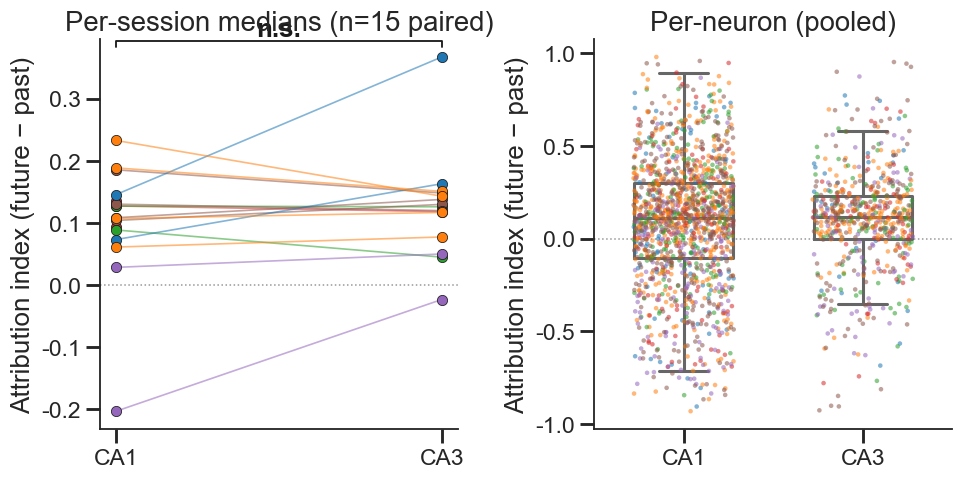

Attribution index (future − past) — CA1 vs CA3:
  neurons: CA1 n=1427 (median +0.110), CA3 n=610 (median +0.113)
  session medians: CA1 +0.108 vs CA3 +0.126 | paired Wilcoxon n=15, p=0.5614 n.s.
  prospective? (session medians vs 0): CA1 n=17 p=0.0026 **; CA3 n=15 p=0.0001 ***


In [44]:
# === Figure 4 (extra): attribution index (prospective coding) for CA1 vs CA3 cells ===
# Attribution index = clu_df['future_idx'], the scale-free future-minus-past position-
# attribution contrast (>0 prospective, <0 retrospective) from the fig4_attribution cell.
# Quantified CA1 vs CA3 at the SESSION level (nonparametric), matching the Fig 4 / ED Fig 6
# CA1/CA3 convention: aggregate per (session, subregion) over neurons (>= SUB_MIN_NEURONS),
# paired Wilcoxon across sessions present in both subregions, per-bat coloured points.
from scipy.stats import wilcoxon as _wilcoxon_ai
_MIN_N = globals().get('SUB_MIN_NEURONS', 10)

_ai = clu_df[clu_df['subregion'].isin(['CA1', 'CA3']) & clu_df['future_idx'].notna()].copy()
_ai['bat_str'] = _ai['session'].apply(parse_bat).astype(str)  # string bat id to match bat_palette() keys
# per-(session, subregion) median attribution over neurons; keep groups with a stable count
_ai_rows = []
for (sn, sr), grp in _ai.groupby(['session', 'subregion']):
    if len(grp) < _MIN_N:
        continue
    _ai_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                         attr_idx=float(grp['future_idx'].median()), n=len(grp)))
ai_sub_df = pd.DataFrame(_ai_rows)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw=dict(wspace=0.38))
# (A) session-level paired CA1 vs CA3 (one line per session, coloured by bat) + bracket
ph.paired_lines(axA, ai_sub_df, 'attr_idx', 'subregion', ['CA1', 'CA3'])
r_paired = ph.paired_session_test(ai_sub_df, 'attr_idx', 'subregion', 'CA1', 'CA3')  # med_a=CA1, med_b=CA3
ph.sig_bracket(axA, 0, 1, r_paired['p'], show_ns=True)
axA.axhline(0, color='0.6', ls=':', lw=1, zorder=0)  # 0 = balanced past/future
axA.set(ylabel='attribution index (future − past)', xlabel='',
        title=f'per-session medians (n={r_paired["n"]} paired)')
# (B) pooled neuron-level distribution by subregion, points coloured by bat
sns.boxplot(data=_ai, x='subregion', y='future_idx', order=['CA1', 'CA3'], ax=axB,
            showfliers=False, width=0.55, fill=False, color='0.4')
sns.stripplot(data=_ai, x='subregion', y='future_idx', order=['CA1', 'CA3'], hue='bat_str',
              palette=ph.bat_palette(), ax=axB, size=3, alpha=0.55, jitter=0.28, legend=False)
axB.axhline(0, color='0.6', ls=':', lw=1, zorder=0)
axB.set(ylabel='attribution index (future − past)', xlabel='', title='per-neuron (pooled)')
ph.save_fig(fig, 'fig4_attr_index_ca1_ca3'); plt.show()

# --- stats: paired CA1 vs CA3 (headline), plus one-sample (session medians vs 0) per subregion
#     to ask whether each subregion is significantly prospective/retrospective ---
def _vs0(sr):
    v = ai_sub_df.loc[ai_sub_df['subregion'] == sr, 'attr_idx'].to_numpy()
    if len(v) < 1 or np.all(v == 0):
        return len(v), np.nan
    return len(v), float(_wilcoxon_ai(v, alternative='two-sided').pvalue)


_ns = lambda p: ph.stars_for_p(p) or 'n.s.'
_neu_med = _ai.groupby('subregion')['future_idx'].median()
_n_ca1, _n_ca3 = int((_ai.subregion == 'CA1').sum()), int((_ai.subregion == 'CA3').sum())
n1, p1 = _vs0('CA1'); n3, p3 = _vs0('CA3')
print('Attribution index (future − past) — CA1 vs CA3:')
print(f'  neurons: CA1 n={_n_ca1} (median {_neu_med.get("CA1", float("nan")):+.3f}), '
      f'CA3 n={_n_ca3} (median {_neu_med.get("CA3", float("nan")):+.3f})')
print(f'  session medians: CA1 {r_paired["med_a"]:+.3f} vs CA3 {r_paired["med_b"]:+.3f} | '
      f'paired Wilcoxon n={r_paired["n"]}, p={r_paired["p"]:.4f} {_ns(r_paired["p"])}')
print(f'  prospective? (session medians vs 0): CA1 n={n1} p={p1:.4f} {_ns(p1)}; '
      f'CA3 n={n3} p={p3:.4f} {_ns(p3)}')


In [45]:
# === Figure 4 h–l data: MRM (R^2 / unique R^2) — replaces the (partial) Mantel analysis ===
# Multiple regression on distance matrices (MRM). For every session the non-flight rest noise-
# correlation (upper triangle, rank-z) is regressed on the three flight predictors — residual-
# readout cosine, rate-map correlation, symmetric coupling — and we report, per predictor:
#   * marginal R^2  -- predictor entered ALONE (simple rank R^2 of that similarity matrix)
#   * unique  R^2   -- semipartial: full 3-predictor model minus the model with that predictor
#                      dropped, i.e. its contribution "holding the other two fixed"
# Every R^2 also carries its OWN P and its own null mean, from a Freedman-Lane permutation test
# (nh.freedman_lane_r2): the reduced-model residuals are relabeled as a MATRIX (rows and columns
# jointly), so the exchangeable unit is the neuron and the pair-level dependence structure is
# preserved. For the marginal R^2 the reduced model is the intercept, so that null reduces to a
# plain Mantel relabeling. All vectors are rank-standardized (nh.zrank), so the MRM is the
# multiple-regression generalization of the Spearman Mantel. This is the COVARIATE-ONLY MRM
# (conditioning is on the three flight predictors; no probe/distance/FR nuisance regressors).
# CA1/CA3 rows repeat the joint MRM within each subregion (unique R^2 per predictor).
# Cached under ./out/fig4_cache/.
from scipy.stats import wilcoxon as _wilcoxon
from notebook_helpers import zrank as _zrank, ols_r2 as _ols_r2, freedman_lane_r2 as _fl_r2

MRM_MIN_PAIRS = 30
MRM_N_PERM = 2000    # neuron-relabeling permutations per (session, predictor, metric)
_MRM_PREDS = ['residual readout', 'rate map', 'coupling']


def _finite_node_subset(mats):
    """Neurons to keep so that EVERY surviving off-diagonal pair is finite in EVERY matrix.
    The permutation null relabels neurons, so non-finite pairs must be removed by dropping
    whole rows/columns rather than by masking individual pairs (as the pre-permutation version
    did). Greedy: repeatedly drop the neuron sitting in the most non-finite pairs."""
    B = np.ones(mats[0].shape, dtype=bool)
    for M in mats:
        B &= np.isfinite(M)
    np.fill_diagonal(B, True)
    keep = np.ones(len(B), dtype=bool)
    while keep.any():
        bad = (~B[np.ix_(keep, keep)]).sum(1)
        if bad.max() == 0:
            break
        keep[np.flatnonzero(keep)[int(np.argmax(bad))]] = False
    return keep


def _mrm_session_r2(y_mat, pred_mats, rng, metrics=('marginal', 'unique'),
                    n_perm=MRM_N_PERM, min_pairs=MRM_MIN_PAIRS):
    """Marginal and/or unique (semipartial) R^2 for each of the 3 flight predictors, each with
    its own Freedman-Lane P and the mean of its permutation null (intercept-only base; no
    nuisance). Takes the n x n matrices (the null permutes neurons, not pairs). Rank-z
    everything; None if too few pairs survive."""
    keep = _finite_node_subset([y_mat] + [pred_mats[k] for k in _MRM_PREDS])
    n = int(keep.sum())
    iu, ju = np.triu_indices(n, 1)
    if len(iu) < min_pairs:
        return None
    sl = np.ix_(keep, keep)
    y = _zrank(y_mat[sl][iu, ju])
    P = {k: _zrank(pred_mats[k][sl][iu, ju]) for k in _MRM_PREDS}
    one = np.ones((len(iu), 1))
    rec = dict(total=_ols_r2(y, np.column_stack([one] + [P[k] for k in _MRM_PREDS])),
               n_pairs=len(iu), n_units=n, n_units_all=int(len(keep)))
    for k in _MRM_PREDS:
        others = [P[m] for m in _MRM_PREDS if m != k]
        for metric in metrics:
            X = np.column_stack([one] + (others if metric == 'unique' else []) + [P[k]])
            r2, p_perm, null = _fl_r2(y, X, X.shape[1] - 1, rng, n_perm, n)
            rec[f'{metric}_{k}'] = r2
            rec[f'{metric}_{k}_p'] = p_perm
            rec[f'{metric}_{k}_null'] = float(np.mean(null))
    return rec


# The key hashes the REGRESSAND itself (not just the session list), so changing how the
# non-flight matrices are built -- e.g. raw vs sqrt counts -- invalidates the cache instead of
# silently returning R^2 computed against the previous version.
_mrm_r2_key = dict(
    kind='fig4_mrm_r2_covonly_perm_v2',
    joint=_ckpt_sig(JOINT_CKPT), coupling=_ckpt_sig(_COUP_CKPT),
    sessions=sorted(nonflight_corr.keys()),
    nonflight=tuple((sn, _arr_hash(np.nan_to_num(C)))
                    for sn, C in sorted(nonflight_corr.items())),
    bin_width=float(bin_width), min_pairs=int(MRM_MIN_PAIRS), sub_floor=int(SUB_MIN_NEURONS),
    n_perm=int(MRM_N_PERM), seed=int(seed),
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_mrm_r2():
    _rng = np.random.default_rng(seed)
    main_rows, region_rows = [], []
    for sn in nonflight_corr:
        M = session_matrices(sn)
        if M is None or M['coupling'] is None or M['ratemap'] is None:
            continue
        rec = _mrm_session_r2(M['nonflight'],
                              {'residual readout': M['residual'],
                               'rate map': M['ratemap'],
                               'coupling': M['coupling']}, _rng)
        if rec is not None:
            for k in _MRM_PREDS:
                for metric in ('marginal', 'unique'):
                    main_rows.append(dict(session=sn, bat=parse_bat(sn), metric=metric,
                                          predictor=k, r2=rec[f'{metric}_{k}'],
                                          r2_null=rec[f'{metric}_{k}_null'],
                                          p_perm=rec[f'{metric}_{k}_p'],
                                          n_units=rec['n_units'],
                                          n_units_all=rec['n_units_all']))

        # --- CA1/CA3-restricted joint MRM (unique R^2 per predictor) ---
        grp = clu_df[clu_df['session'] == sn]
        for sr in ('CA1', 'CA3'):
            g = grp[grp['subregion'] == sr]
            if len(g) < SUB_MIN_NEURONS or sn not in session_coupling_sim:
                continue
            units = g['unit'].to_numpy()
            Wr = np.stack(g['readout_weight_residual'].values)
            rec = _mrm_session_r2(nonflight_corr[sn][np.ix_(units, units)],
                                  {'residual readout': Wr @ Wr.T,
                                   'rate map': ratemap_corr_matrix(session_rate_maps[sn][units]),
                                   'coupling': session_coupling_sim[sn][np.ix_(units, units)]},
                                  _rng, metrics=('unique',))
            if rec is None:
                continue
            for k in _MRM_PREDS:
                region_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                                        predictor=k, metric='unique', r2=rec[f'unique_{k}'],
                                        r2_null=rec[f'unique_{k}_null'],
                                        p_perm=rec[f'unique_{k}_p'],
                                        n_units=rec['n_units'], n_units_all=rec['n_units_all']))
    main = pd.DataFrame(main_rows)
    region = pd.DataFrame(region_rows)
    for df in (main, region):
        if len(df):
            df['predictor'] = pd.Categorical(df['predictor'], _MRM_PREDS, ordered=True)
    return dict(mrm_r2_main=main, mrm_r2_region=region)


_mrm_r2_blob = _fig4_cache('fig4_mrm_r2', _mrm_r2_key, _compute_mrm_r2)
mrm_r2_main = _mrm_r2_blob['mrm_r2_main']
mrm_r2_region = _mrm_r2_blob['mrm_r2_region']
_mrm_nu = (mrm_r2_main[mrm_r2_main['metric'] == 'unique']
           .drop_duplicates('session')[['n_units', 'n_units_all']].sum())
print(f'MRM R^2 ready: {mrm_r2_main["session"].nunique()} sessions (main), '
      f'{mrm_r2_region["session"].nunique()} sessions with CA1/CA3 breakdown; '
      f'{MRM_N_PERM} Freedman-Lane permutations per test '
      f'({_mrm_nu["n_units"]}/{_mrm_nu["n_units_all"]} neurons kept after dropping units '
      f'with non-finite pairs).')


def _perm_vs_null(_d, **_extra):
    """Population summary for one (metric, predictor) or (subregion, predictor) cell: every
    session's observed R^2 against the MEAN of its own permutation null (paired Wilcoxon
    across sessions), plus how many sessions clear their individual Freedman-Lane test."""
    _d = _d.sort_values('session')
    _obs, _nul = _d['r2'].to_numpy(), _d['r2_null'].to_numpy()
    _p = (float(_wilcoxon(_obs, _nul, alternative='two-sided').pvalue)
          if len(_obs) and np.any(_obs != _nul) else np.nan)
    return dict(**_extra, n=len(_obs), med_obs=float(np.median(_obs)),
                med_null=float(np.median(_nul)), p=_p,
                n_sess_p05=int((_d['p_perm'] < 0.05).sum()),
                med_p_perm=float(np.median(_d['p_perm'])))


# Printed here rather than in the fig4_merged stats block so the permutation inference can be
# inspected without re-rendering the whole figure.
print('\nFig 4 h/i - MRM R^2 vs its own permutation null (per-session observed vs null mean, '
      'paired Wilcoxon; n_sess_p05 = sessions with individual Freedman-Lane P < 0.05):')
ph.p_table([_perm_vs_null(mrm_r2_main[(mrm_r2_main['metric'] == _metric) &
                                      (mrm_r2_main['predictor'] == _pred)],
                          metric=_metric, predictor=_pred)
            for _metric in ('marginal', 'unique') for _pred in _MRM_PREDS])
print('\nFig 4 j/k - CA1/CA3 unique R^2 vs its own permutation null (per-session observed vs '
      'null mean, paired Wilcoxon):')
ph.p_table([_perm_vs_null(mrm_r2_region[(mrm_r2_region['subregion'] == _sr) &
                                        (mrm_r2_region['predictor'] == _pred)],
                          subregion=_sr, predictor=_pred)
            for _sr in ('CA1', 'CA3') for _pred in _MRM_PREDS])

# --- Sleep counterpart (Fig 4 sleep panel): the same MRM against SLEEP correlations ---
# Identical machinery, with the REGRESSAND swapped from the non-flight WAKING rest matrix to the
# SLEEP (Dataset_0) matrix built by the UnitMatch cell. Only the sleep-matched sessions qualify,
# and within them only the neurons matched across the two recordings: unmatched rows/columns of
# the sleep matrix are NaN, so _finite_node_subset drops them automatically. The other three
# matrices come from session_matrices() in the same clu_df row order, so positional slicing keeps
# the CA1/CA3-restricted versions aligned (and is exactly the submatrix the waking loop rebuilds).
#
# Only n = 4 sessions survive the matching, so every session-level test on these values is
# PARAMETRIC (paired t-tests). The signed-rank test used for the waking panels cannot reach
# P < 0.05 two-sided at n = 4 -- its smallest attainable P is 0.125 -- so it would render every
# comparison vacuously n.s. regardless of effect size.
from scipy.stats import ttest_rel as _ttest_rel


def _paired_session_t(df, value_col, cond_col, cond_a, cond_b, session_col='session'):
    """Paired t-test on per-session values -- parametric counterpart of ph.paired_session_test."""
    piv = (df.groupby([session_col, cond_col], observed=True)[value_col].mean()
             .unstack(cond_col))
    if cond_a not in piv or cond_b not in piv:
        return dict(n=0, p=np.nan, t=np.nan, mean_a=np.nan, mean_b=np.nan)
    pair = piv[[cond_a, cond_b]].dropna()
    a, b = pair[cond_a].to_numpy(), pair[cond_b].to_numpy()
    if len(a) < 2 or np.allclose(a, b):
        return dict(n=len(a), p=np.nan, t=np.nan,
                    mean_a=float(np.mean(a)) if len(a) else np.nan,
                    mean_b=float(np.mean(b)) if len(b) else np.nan)
    _r = _ttest_rel(a, b)
    return dict(n=len(a), p=float(_r.pvalue), t=float(_r.statistic),
                mean_a=float(a.mean()), mean_b=float(b.mean()))


def _perm_vs_null_t(_d, **_extra):
    """Parametric counterpart of _perm_vs_null: observed R^2 vs the mean of its own
    Freedman-Lane null, paired t-test across sessions."""
    _d = _d.sort_values('session')
    _obs, _nul = _d['r2'].to_numpy(), _d['r2_null'].to_numpy()
    _p = (float(_ttest_rel(_obs, _nul).pvalue)
          if len(_obs) >= 2 and not np.allclose(_obs, _nul) else np.nan)
    return dict(**_extra, n=len(_obs), mean_obs=float(np.mean(_obs)) if len(_obs) else np.nan,
                mean_null=float(np.mean(_nul)) if len(_nul) else np.nan, p=_p,
                n_sess_p05=int((_d['p_perm'] < 0.05).sum()))


_sleep_mrm_key = dict(
    kind='fig4_mrm_r2_sleep_v1',
    joint=_ckpt_sig(JOINT_CKPT), coupling=_ckpt_sig(_COUP_CKPT),
    sessions=sorted(session_sleep_corr.keys()),
    sleep=tuple((sn, _arr_hash(np.nan_to_num(C))) for sn, C in sorted(session_sleep_corr.items())),
    bin_width=float(bin_width), min_pairs=int(MRM_MIN_PAIRS), sub_floor=int(SUB_MIN_NEURONS),
    n_perm=int(MRM_N_PERM), seed=int(seed),
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_sleep_mrm():
    _rng = np.random.default_rng(seed)
    main_rows, region_rows = [], []
    for sn in sorted(session_sleep_corr):
        M = session_matrices(sn)
        if M is None or M.get('sleep') is None or M['coupling'] is None or M['ratemap'] is None:
            continue
        preds = {'residual readout': M['residual'], 'rate map': M['ratemap'],
                 'coupling': M['coupling']}
        rec = _mrm_session_r2(M['sleep'], preds, _rng)
        if rec is not None:
            for k in _MRM_PREDS:
                for metric in ('marginal', 'unique'):
                    main_rows.append(dict(session=sn, bat=parse_bat(sn), metric=metric,
                                          predictor=k, r2=rec[f'{metric}_{k}'],
                                          r2_null=rec[f'{metric}_{k}_null'],
                                          p_perm=rec[f'{metric}_{k}_p'],
                                          n_units=rec['n_units'],
                                          n_units_all=rec['n_units_all']))

        # --- CA1/CA3-restricted joint MRM (unique R^2 per predictor); not plotted, printed below ---
        _sr_lab = M['grp']['subregion'].to_numpy()
        _matched = np.isfinite(np.diag(M['sleep']))
        for sr in ('CA1', 'CA3'):
            loc = np.flatnonzero((_sr_lab == sr) & _matched)
            if len(loc) < SUB_MIN_NEURONS:
                continue
            sl = np.ix_(loc, loc)
            rec = _mrm_session_r2(M['sleep'][sl], {k: v[sl] for k, v in preds.items()},
                                  _rng, metrics=('unique',))
            if rec is None:
                continue
            for k in _MRM_PREDS:
                region_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                                        predictor=k, metric='unique', r2=rec[f'unique_{k}'],
                                        r2_null=rec[f'unique_{k}_null'],
                                        p_perm=rec[f'unique_{k}_p'],
                                        n_units=rec['n_units'], n_units_all=rec['n_units_all']))
    main, region = pd.DataFrame(main_rows), pd.DataFrame(region_rows)
    for df in (main, region):
        if len(df):
            df['predictor'] = pd.Categorical(df['predictor'], _MRM_PREDS, ordered=True)
    return dict(sleep_mrm_main=main, sleep_mrm_region=region)


_sleep_mrm_blob = _fig4_cache('fig4_mrm_r2_sleep', _sleep_mrm_key, _compute_sleep_mrm)
sleep_mrm_main = _sleep_mrm_blob['sleep_mrm_main']
sleep_mrm_region = _sleep_mrm_blob['sleep_mrm_region']
_sl_nu = (sleep_mrm_main[sleep_mrm_main['metric'] == 'unique']
          .drop_duplicates('session')[['n_units', 'n_units_all']].sum())
print(f'\nSleep MRM ready: {sleep_mrm_main["session"].nunique()} sleep-matched sessions '
      f'({_sl_nu["n_units"]}/{_sl_nu["n_units_all"]} neurons kept after UnitMatch + finite-pair '
      f'filtering), {sleep_mrm_region["session"].nunique()} with a CA1/CA3 breakdown.')
print('\nSleep MRM - R^2 vs its own permutation null (per-session observed vs null mean, '
      'paired t-test; n_sess_p05 = sessions with individual Freedman-Lane P < 0.05):')
ph.p_table([_perm_vs_null_t(sleep_mrm_main[(sleep_mrm_main['metric'] == _metric) &
                                           (sleep_mrm_main['predictor'] == _pred)],
                            metric=_metric, predictor=_pred)
            for _metric in ('marginal', 'unique') for _pred in _MRM_PREDS])
print('\nSleep MRM - CA1/CA3 unique R^2 (not plotted): pairwise predictors, then vs their own '
      'permutation null (paired t-tests):')
ph.p_table([dict(subregion=_sr, comparison=f'{_MRM_PREDS[_a]} vs {_MRM_PREDS[_b]}',
                 **_paired_session_t(sleep_mrm_region[sleep_mrm_region['subregion'] == _sr],
                                     'r2', 'predictor', _MRM_PREDS[_a], _MRM_PREDS[_b]))
            for _sr in ('CA1', 'CA3') for _a, _b in [(0, 1), (1, 2), (0, 2)]])
ph.p_table([_perm_vs_null_t(sleep_mrm_region[(sleep_mrm_region['subregion'] == _sr) &
                                             (sleep_mrm_region['predictor'] == _pred)],
                            subregion=_sr, predictor=_pred)
            for _sr in ('CA1', 'CA3') for _pred in _MRM_PREDS])


  [cache hit] fig4_mrm_r2
MRM R^2 ready: 17 sessions (main), 17 sessions with CA1/CA3 breakdown.


In [ ]:
# === Figure 4 (a-j) on a single canvas ===
# Layout (three bands):
#   row 1 : [ a | f f f f f (cbar) ]   a=PC1/FR (narrow); f=5 similarity matrices (slid left into the old SVC slot)
#   row 2 : [ b | c/d/e ]   b=dendrogram + cosine-similarity square (major-cluster boundaries dashed white);
#           c/d/e = spatial info / attribution example / attribution index (stacked next to b)
#   row 3 : [ g=marginal R^2 | h=unique R^2 vs non-flight | i=unique R^2 vs sleep |
#             j=CA1-vs-CA3 decoding (narrow) | k=predictor x subregion interaction ]
# Clustering (Z, order, sim_ord, Wr_ord, clus_ord, N, D, XSPAN, CLUSTER_ORDER, CLUSTER_PALETTE,
# CLUSTER_GREY, _dendro_link_color) comes from the fig4_cluster cell; the SVM stats (g_df)
# from fig4_stats; the MRM R^2 (mrm_r2_main, mrm_r2_region) from the fig4_mrm_r2 cell; the attribution
# (attr_ex_matrix, attr_ex_ext, attr_excl_s, clu_df['future_idx']) from the fig4_attribution cell.
from itertools import combinations
from sklearn.decomposition import PCA as _PCA
from scipy.spatial.distance import squareform
from scipy.stats import kruskal as _kw, mannwhitneyu as _mwu, wilcoxon as _wil, f as _sp_f

FS = dict(title=24, label=24, tick=21, star=24)   # +2 pt across the board
plt.rcParams['mathtext.fontset'] = 'dejavusans'   # Arial-like math font (matches body text)
PRED_ORDER = ['residual readout', 'rate map', 'coupling']


def _star_only(ax, p, x=0, yfrac=1.02):
    """Significance asterisk (no bracket) near the top of the data."""
    s = ph.stars_for_p(p)
    if s:
        lo, hi = ax.get_ylim()
        ax.text(x, lo + yfrac * (hi - lo), s, ha='center', va='bottom',
                fontsize=FS['star'], fontweight='bold')


def _pairwise_cluster_brackets(ax, df, val_col, order, *, base=1.05, step=0.075):
    """Holm-corrected pairwise Mann-Whitney across clusters. Significant pairs are drawn as
    ph.sig_bracket, packed onto as few horizontal levels as possible: a bracket reuses a level
    only if its x-span does not overlap any bracket already placed there (else it goes higher)."""
    pv = {}
    for a, b in combinations(range(len(order)), 2):
        xa = df.loc[df['cluster'] == order[a], val_col].dropna().values
        xb = df.loc[df['cluster'] == order[b], val_col].dropna().values
        pv[(a, b)] = (_mwu(xa, xb, alternative='two-sided').pvalue
                      if len(xa) >= 3 and len(xb) >= 3 else np.nan)
    real = sorted([(k, p) for k, p in pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
    run, adj = 0.0, {}
    for i, (k, p) in enumerate(real):
        run = max(run, (len(real) - i) * p)
        adj[k] = min(run, 1.0)
    sig = sorted([k for k in adj if adj[k] < 0.05], key=lambda k: (k[1] - k[0], k))
    levels = []                                        # each entry = list of (a, b) spans on that line
    for (a, b) in sig:
        lvl = next((i for i, spans in enumerate(levels)
                    if all(b <= s or a >= e for (s, e) in spans)), None)   # touching brackets (shared endpoint) share a level -> side by side
        if lvl is None:
            levels.append([(a, b)]); lvl = len(levels) - 1
        else:
            levels[lvl].append((a, b))
        ph.sig_bracket(ax, a, b, adj[(a, b)], base=base + lvl * step, star_gap=-0.05, fontsize=FS['star'])   # tight star + compact stack
    return adj


def _cluster_dist(ax, df, val_col, ylabel, *, bracket_base=1.02):
    """Identical per-cluster box + individual-neuron dots + pairwise brackets style,
    shared by the spatial-info (i) and future-past (k) panels."""
    ph.cat_violin(ax, df, 'cluster', val_col, CLUSTER_ORDER, CLUSTER_PALETTE, trim_outliers=True)
    _pairwise_cluster_brackets(ax, df, val_col, CLUSTER_ORDER, base=bracket_base)
    ax.set_xlabel('cluster', fontsize=FS['label'])
    ax.set_ylabel(ylabel, fontsize=FS['label'])
    ax.tick_params(labelsize=FS['tick'])


fig4 = plt.figure(figsize=(21, 23))
outer = fig4.add_gridspec(5, 1, height_ratios=[1, 0.16, 4, 0.18, 1], hspace=0.15)   # row1 | spacer | row2 | spacer | row3

# ---- row 1: a (PC1/FR) | c (spatial info) | d (attribution example) | e (attribution index), horizontal ----
gs_top = outer[0].subgridspec(1, 5, width_ratios=[1.0, 1.6, 1.75, 0.3, 1.6], wspace=0.42)  # col 3 = spacer -> extra gap before e
ax_a = fig4.add_subplot(gs_top[0, 0])
ax_i = fig4.add_subplot(gs_top[0, 1])          # c: spatial information
ax_j = fig4.add_subplot(gs_top[0, 2])          # d: example attribution matrix
ax_k = fig4.add_subplot(gs_top[0, 4])          # e: future-past attribution index

# ---- row 2: b (dendrogram + square cos-sim) on the left | f (5 similarity matrices in a 3x2 grid) on the right ----
gs_r2 = outer[2].subgridspec(1, 4, width_ratios=[11.0, 2.5, 6.9, 0.4], wspace=0.05)        # B (left-aligned) | wider gap | F 3x2 (+cbar) | margin
gs_b = gs_r2[0, 0].subgridspec(2, 1, height_ratios=[0.28, 1.6], hspace=0.03)              # dendro + cos-sim (square via box_aspect), left-aligned
axb_dendro = fig4.add_subplot(gs_b[0])
axb_sim = fig4.add_subplot(gs_b[1])
gs_f = gs_r2[0, 2].subgridspec(3, 2, hspace=0.3, wspace=0.18)                             # 5 matrices in a 3x2 grid (bottom-right cell holds the cbar inset)
ax_c = [fig4.add_subplot(gs_f[_r, _cc]) for _r, _cc in [(0, 0), (0, 1), (1, 0), (1, 1), (2, 0)]]

# ---- row 3: g=marginal R^2 | h=unique R^2 (non-flight) | i=unique R^2 (sleep) | j=CA1-vs-CA3 decoding (narrow) | k=predictor x subregion interaction ----
gs_bot = outer[4].subgridspec(1, 5, width_ratios=[1.0, 1.0, 1.0, 0.6, 1.0], wspace=0.62)
ax_mrm_marg = fig4.add_subplot(gs_bot[0, 0])
ax_mrm_uniq = fig4.add_subplot(gs_bot[0, 1])
ax_mrm_uniq_sl = fig4.add_subplot(gs_bot[0, 2])   # same unique R^2, regressand = SLEEP correlations
ax_g = fig4.add_subplot(gs_bot[0, 3])          # balanced-accuracy CA1-vs-CA3 decoding
ax_int = fig4.add_subplot(gs_bot[0, 4])        # predictor x subregion interaction
_LOWER_TITLES = []      # (ax, text) for titles whose lower-case 'vs.' must survive capitalisation

# --- a: PC1 of readout weights correlates with mean firing rate (vs a random-direction null) ---
_rec = []
for sn, grp in clu_df.groupby('session'):
    W = np.stack(grp['readout_weight'].values)
    if len(grp) < 4:
        continue
    pc1 = _PCA(n_components=1, random_state=seed).fit_transform(W).ravel()
    r = np.corrcoef(pc1, grp['mean_fr'].values)[0, 1]
    _rec.append(dict(session=sn, bat=parse_bat(sn), r=abs(r)))
pc1_fr_df = pd.DataFrame(_rec)
# grey null boxplot: |corr(mean FR, 100 random readout-space directions)| per session
_rng_a = np.random.default_rng(seed)
_null_rows = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wa = np.stack(grp['readout_weight'].values); fra = grp['mean_fr'].values
    dirs = _rng_a.standard_normal((100, Wa.shape[1]))
    dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
    proj = Wa @ dirs.T                                        # (K, 100)
    for _kk in range(dirs.shape[0]):
        if proj[:, _kk].std() > 0:
            _null_rows.append(dict(session=sn, r=abs(np.corrcoef(proj[:, _kk], fra)[0, 1])))
null_a_df = pd.DataFrame(_null_rows)
_null_med = null_a_df.groupby('session')['r'].median()
_pc1_ser = pc1_fr_df.set_index('session')['r']
_common = _pc1_ser.index.intersection(_null_med.index)
_p_a = (_wil(_pc1_ser.loc[_common].values - _null_med.loc[_common].values, alternative='two-sided').pvalue
        if len(_common) >= 3 else np.nan)
sns.boxplot(y=null_a_df['r'], color='0.85', width=0.5, showfliers=False, ax=ax_a, zorder=0)
sns.swarmplot(data=pc1_fr_df, y='r', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(pc1_fr_df['bat'])],
              size=11, edgecolor='k', linewidth=0.4, ax=ax_a, legend=False, zorder=3)
ax_a.set(xlabel='', xticks=[], xlim=(-0.75, 0.75))
ax_a.set_ylabel('|corr(readout PC1,\nmean FR)|', fontsize=FS['label'], y=0.44)
ax_a.set_ylim(0, 1)
ax_a.tick_params(labelsize=FS['tick'])
ax_a.spines['bottom'].set_visible(False)
_star_only(ax_a, _p_a)                                        # PC1 > random-direction null (bat legend is in Fig 1a)

# --- i: residual readouts predict CA1 vs CA3 membership (per-session SVM swarm; new bottom row) ---
# One balanced-accuracy point per session (coloured by bat); chance = 0.5 (dashed).
# Computed in fig4_stats.
if len(g_df):
    sns.swarmplot(data=g_df, y='bal_acc', hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in bats if b in set(g_df['bat'])], size=11,
                  edgecolor='k', linewidth=0.4, ax=ax_g, legend=False)
    ax_g.axhline(0.5, color='0.5', ls='--', lw=1, zorder=0)   # chance line
    _res_g = ph.onesample_session_test(g_df, 'bal_acc', popmean=0.5)
    ax_g.set(xlim=(-0.75, 0.75), xticks=[], ylim=(0.4, 0.8))
    _star_only(ax_g, _res_g['p'])
else:                                                          # no session has both regions
    _res_g = dict(p=np.nan, n=0)
    ax_g.set_title('(no dual-region session)', fontsize=FS['label'])
ax_g.set_ylabel('Balanced accuracy', fontsize=FS['label'])
ax_g.set_title('CA1 vs. CA3', fontsize=FS['title'], y=1.22)     # row-3 titles share this height
_LOWER_TITLES.append((ax_g, 'CA1 vs. CA3'))
ax_g.tick_params(labelsize=FS['tick'])
ax_g.spines['bottom'].set_visible(False)

# --- b: residual-readout clustering (dendrogram / cosine similarity / weights, stacked) ---
dendrogram(Z, ax=axb_dendro, no_labels=True, link_color_func=_dendro_link_color)
axb_dendro.set(xlim=(0, XSPAN), ylim=(0.5, 1.0), xticks=[])
axb_dendro.set_yticks([0.5, 1.0]); axb_dendro.set_yticklabels(['0', '1'])   # 0.5 relabelled 0 (axis break)
axb_dendro.set_ylabel('cosine\ndistance', fontsize=FS['label'])
axb_dendro.set_title('Residual readout clustering', fontsize=FS['title'])
axb_dendro.tick_params(labelsize=FS['tick'])
for s in ('top', 'right', 'bottom'):
    axb_dendro.spines[s].set_visible(False)
_bk = dict(transform=axb_dendro.transAxes, color='k', clip_on=False, lw=1.2)   # axis-break marks (bottom)
axb_dendro.plot([-0.008, 0.008], [0.05, 0.085], **_bk)
axb_dendro.plot([-0.008, 0.008], [0.085, 0.12], **_bk)
# color scale constrained to the 2.5-97.5 percentiles of the OFF-DIAGONAL cosine
# similarities (the diagonal self-similarity is a trivial 1.0 that would clamp the scale)
_cos_off = sim_ord[~np.eye(sim_ord.shape[0], dtype=bool)]
_cos_lo, _cos_hi = np.nanpercentile(_cos_off, [2.5, 97.5])
im = axb_sim.imshow(sim_ord, cmap='RdBu_r', vmin=_cos_lo, vmax=_cos_hi, aspect='auto',
                    interpolation='nearest', extent=(0, XSPAN, 0, N), origin='upper')   # diagonal TL->BR
axb_sim.set(xlim=(0, XSPAN), xticks=[])
axb_sim.set_xlabel('neuron (clustered)', fontsize=FS['label'])
axb_sim.set_ylabel('neuron', fontsize=FS['label'])
axb_sim.tick_params(labelsize=FS['tick'])
axb_sim.set_box_aspect(1)                                     # force the cosine-similarity matrix square
# dashed white lines at the boundaries between the major (included) neuron clusters, along both axes
_maj_blocks = sorted((int(np.where(clus_ord == _c)[0].min()), int(np.where(clus_ord == _c)[0].max()))
                     for _c in CLUSTER_ORDER if (clus_ord == _c).any())
_maj_edges = sorted({_e for (_mn, _mx) in _maj_blocks for _e in (_mn / N, (_mx + 1) / N)})  # both ends of each major cluster
for _fb in _maj_edges:
    axb_sim.plot([_fb, _fb], [0, 1], transform=axb_sim.transAxes, color='w', ls='--', lw=2.8)          # vertical
    axb_sim.plot([0, 1], [1 - _fb, 1 - _fb], transform=axb_sim.transAxes, color='w', ls='--', lw=2.8)  # horizontal (origin='upper')
_cb1 = fig4.colorbar(im, cax=axb_sim.inset_axes([1.02, 0.0, 0.012, 1.0]))   # offset further right
_cb1.set_label('Cosine similarity', fontsize=FS['label'], rotation=270, labelpad=26); _cb1.ax.tick_params(labelsize=FS['tick'])

# --- f: example sleep-matched session — 5 similarity matrices, common (non-flight) order ---
# Restrict to neurons matched to the sleep (Dataset_0) session so Non-flight FR and Sleep FR
# are on IDENTICAL neurons/order (they should be near-indistinguishable). All five share the
# [-1, 1] scale, sorted by the non-flight-rest clustering; a single "similarity" colourbar.


def _matched_idx(sn):
    M = session_matrices(sn)
    if M is None or M.get('sleep') is None:
        return None
    good = np.isfinite(np.diag(M['sleep']))
    return np.where(good)[0] if good.sum() >= 3 else None


_c_cand = [(s, _matched_idx(s)) for s in session_sleep_corr]
_c_cand = [(s, idx) for s, idx in _c_cand if idx is not None]
c_last_im = None
if _c_cand:
    ex_session, ex_idx = max(_c_cand, key=lambda t: len(t[1]))
    Mc = session_matrices(ex_session)

    def _sub(m):
        return None if m is None else m[np.ix_(ex_idx, ex_idx)]
    nf_c, sl_c = _sub(Mc['nonflight']), _sub(Mc['sleep'])
    dmat = 1 - np.abs(np.nan_to_num(nf_c, nan=0.0)); np.fill_diagonal(dmat, 0.0)
    order_c = (dendrogram(linkage(squareform(dmat, checks=False), method='average'),
                          no_plot=True)['leaves'] if len(ex_idx) >= 2 else list(range(len(ex_idx))))
    cmats = [('Non-flight FR', nf_c), ('Sleep FR', sl_c), ('Residual\nreadout', _sub(Mc['residual'])),
             ('Rate map', _sub(Mc['ratemap'])), ('GLM coupling', _sub(Mc['coupling']))]
    for _fi, (ax, (name, mat)) in enumerate(zip(ax_c, cmats)):   # 3x2 row-major: Non-flight Sleep / Residual Rate / GLM -
        if mat is None:
            ax.axis('off'); ax.set_title(f'{name}\n(unavailable)', fontsize=FS['label']); continue
        Mo = mat[np.ix_(order_c, order_c)]
        if name == 'GLM coupling':                      # normalise coupling to [-1, 1]
            _s = np.nanmax(np.abs(Mo)) or 1.0
            Mo = Mo / _s
        c_last_im = ax.imshow(Mo, cmap='RdBu_r', vmin=-1, vmax=1, aspect='equal',
                              interpolation='nearest')
        ax.set(xticks=[], yticks=[]); ax.set_box_aspect(1)
        ax.set_title(name, fontsize=FS['label'])
        if _fi in (0, 2, 4):                            # left column -> "Neuron" ylabel
            ax.set_ylabel('Neuron', fontsize=FS['label'])
        if _fi in (3, 4):                               # bottom matrix of each column -> "Neuron" xlabel
            ax.set_xlabel('Neuron', fontsize=FS['label'])
    if c_last_im is not None:                           # single shared colourbar, labelled "similarity"
        cax_c = ax_c[4].inset_axes([1.15, 0.0, 0.08, 1.0])                    # vertical cbar next to GLM coupling
        _cbc = fig4.colorbar(c_last_im, cax=cax_c)
        _cbc.set_label('similarity', fontsize=FS['label'], rotation=270, labelpad=26); _cbc.ax.tick_params(labelsize=FS['tick'])
    _iu = np.triu_indices(len(ex_idx), 1)
    _a, _b = nf_c[np.ix_(order_c, order_c)][_iu], sl_c[np.ix_(order_c, order_c)][_iu]
    _ok = np.isfinite(_a) & np.isfinite(_b)
    _rc = np.corrcoef(_a[_ok], _b[_ok])[0, 1] if _ok.sum() > 2 else np.nan
    print(f'Fig 4c - {ex_session}: non-flight vs sleep FR-corr agreement r={_rc:.3f} '
          f'over {int(_ok.sum())} pairs (should be near 1)')
else:
    for ax in ax_c:
        ax.axis('off')
    ex_session = None
    print('Fig 4c - no sleep-matched session available')

# --- g/h/i: MRM vs variables — marginal R^2 (g) + unique R^2 against non-flight rest (h) and
# against sleep (i), bottom row ---
# Paired lines across the three flight predictors, one per session (coloured by bat, the same
# BAT_PALETTE in all three so a bat keeps its colour between the non-flight and sleep panels),
# with the residual-readout reference bracketed against each competitor.
# marginal = predictor entered alone; unique = its semipartial in the joint 3-predictor model.
# The two waking panels use the session-level paired Wilcoxon; the sleep panel uses a paired
# t-test, since only n = 4 sessions survive the UnitMatch sleep pairing and the signed-rank test
# cannot reach P < 0.05 two-sided there (smallest attainable P = 0.125). Titles name the
# REGRESSAND each R^2 is computed against; they are collected in _LOWER_TITLES and re-applied
# after ph.capitalize_labels so the leading 'vs.' stays lower-case in the body font.
_mrm_xlabels = ['Residual\nreadout', 'rate map', 'coupling']
for _ax, _src, _metric, _ylab, _title, _test in [
        (ax_mrm_marg, mrm_r2_main, 'marginal', 'Marginal $R^2$', 'vs. nonflight',
         ph.paired_session_test),
        (ax_mrm_uniq, mrm_r2_main, 'unique', 'Unique $R^2$', 'vs. nonflight',
         ph.paired_session_test),
        (ax_mrm_uniq_sl, sleep_mrm_main, 'unique', 'Unique $R^2$', 'vs. sleep',
         _paired_session_t)]:
    _sub = _src[_src['metric'] == _metric]
    ph.paired_lines(_ax, _sub, 'r2', 'predictor', PRED_ORDER, palette=BAT_PALETTE, jitter=0.04)
    _ax.axhline(0, color='0.6', ls='--', lw=0.8)
    _ax.set(xlabel='')
    _ax.set_ylabel(_ylab, fontsize=FS['label'])
    _ax.set_xlim(-0.55, 2.55)
    _ax.tick_params(labelsize=FS['tick'])
    _ax.set_xticklabels(_mrm_xlabels, rotation=45, ha='right', fontsize=FS['tick'])
    if _title:
        _ax.set_title(_title, fontsize=FS['title'], y=1.22)   # clear of the two bracket levels
        _LOWER_TITLES.append((_ax, _title))
    _lvl = 0
    for _j, _comp in [(1, 'rate map'), (2, 'coupling')]:
        _r = _test(_sub, 'r2', 'predictor', 'residual readout', _comp)
        if ph.stars_for_p(_r['p']):
            ph.sig_bracket(_ax, 0, _j, _r['p'], base=1.0 + _lvl * 0.09, star_gap=-0.05, fontsize=FS['star']); _lvl += 1
# --- j: predictor x subregion interaction — unique R^2 crossover between CA1 and CA3 ---
# Interaction plot: mean +/- SEM unique R^2 across sessions at each predictor, one line per subregion
# (distinct green/purple palette), with light per-session points. Annotated with the CA1 simple effect
# (residual readout > rate map & coupling; nonparametric paired Wilcoxon) and the two-way RM-ANOVA
# predictor x subregion interaction P (Greenhouse-Geisser corrected, complete-case sessions).
SUBREGION_PALETTE = {'CA1': '#1b7837', 'CA3': '#762a83'}      # green / purple, distinct from BAT_PALETTE
_rng_int = np.random.default_rng(seed)
for _sr, _off in [('CA1', -0.09), ('CA3', 0.09)]:
    d = mrm_r2_region[mrm_r2_region['subregion'] == _sr]
    _xj = d['predictor'].map({p: i for i, p in enumerate(PRED_ORDER)}).astype(float).to_numpy()
    ax_int.scatter(_xj + _off + _rng_int.uniform(-0.03, 0.03, len(_xj)), d['r2'].to_numpy(),
                   s=20, color=SUBREGION_PALETTE[_sr], alpha=0.25, linewidths=0, zorder=1)
    _m = d.groupby('predictor', observed=True)['r2'].agg(['mean', 'sem']).reindex(PRED_ORDER)
    ax_int.errorbar(range(len(PRED_ORDER)), _m['mean'], yerr=_m['sem'], color=SUBREGION_PALETTE[_sr],
                    marker='o', ms=11, lw=2.5, capsize=4, zorder=3, label=_sr)
ax_int.set_ylim(0, 0.05)
ax_int.set_xticks(range(len(PRED_ORDER)))
ax_int.set_xticklabels(_mrm_xlabels, rotation=45, ha='right', fontsize=FS['tick'])
ax_int.set_xlim(-0.55, 2.78)
ax_int.set_ylabel('Unique $R^2$', fontsize=FS['label'])
ax_int.tick_params(labelsize=FS['tick'])
ax_int.legend(fontsize=FS['tick'], loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
              columnspacing=1.0, frameon=False, handletextpad=0.4)
ax_int.set_title('vs. nonflight', fontsize=FS['title'], y=1.22)   # above the CA1/CA3 legend
_LOWER_TITLES.append((ax_int, 'vs. nonflight'))
# CA1 simple effect: residual readout > rate map & coupling (paired Wilcoxon, drawn in the CA1 colour)
_ca1 = mrm_r2_region[mrm_r2_region['subregion'] == 'CA1']
for _bi, _base in ((1, 0.86), (2, 0.97)):
    _r = ph.paired_session_test(_ca1, 'r2', 'predictor', PRED_ORDER[0], PRED_ORDER[_bi])
    if ph.stars_for_p(_r['p']):
        ph.sig_bracket(ax_int, 0, _bi, _r['p'], base=_base, star_gap=-0.05,
                       color=SUBREGION_PALETTE['CA1'], fontsize=FS['star'])
# two-way repeated-measures ANOVA predictor x subregion interaction (complete-case sessions in both
# regions); self-contained (reproduces pingouin's Greenhouse-Geisser p, no external dependency).
_both = set(_ca1['session']) & set(mrm_r2_region[mrm_r2_region['subregion'] == 'CA3']['session'])


def _ortho_contrasts(_k):
    return np.linalg.svd(np.ones((1, _k)))[2][1:].T          # (k, k-1) orthonormal, orthogonal to ones


def _rm_interaction_p(_Y):                                   # _Y: (n_subj, nA, nB), balanced complete-case
    _n, _a, _b = _Y.shape
    _gm = _Y.mean(); _Ma = _Y.mean((0, 2)); _Mb = _Y.mean((0, 1)); _Ms = _Y.mean((1, 2))
    _Mab = _Y.mean(0); _Msa = _Y.mean(2); _Msb = _Y.mean(1)
    _ss_ab = _n * ((_Mab - _Ma[:, None] - _Mb[None, :] + _gm) ** 2).sum()
    _yhat = (_Msa[:, :, None] + _Msb[:, None, :] + _Mab[None, :, :]
             - _Ms[:, None, None] - _Ma[None, :, None] - _Mb[None, None, :] + _gm)
    _ss_abs = ((_Y - _yhat) ** 2).sum()
    _df1 = (_a - 1) * (_b - 1); _df2 = _df1 * (_n - 1)
    _F = (_ss_ab / _df1) / (_ss_abs / _df2)
    _C = np.kron(_ortho_contrasts(_a), _ortho_contrasts(_b))
    _S = np.atleast_2d(np.cov(_Y.reshape(_n, _a * _b) @ _C, rowvar=False))
    _eps = min(1.0, max((np.trace(_S) ** 2) / (_df1 * np.sum(_S * _S)), 1.0 / _df1))
    return _F, float(_sp_f.sf(_F, _df1 * _eps, _df2 * _eps))


try:
    _bs = sorted(_both)
    _Yint = np.array([[[mrm_r2_region[(mrm_r2_region['session'] == _s) &
                                      (mrm_r2_region['predictor'] == _p) &
                                      (mrm_r2_region['subregion'] == _sr)]['r2'].iloc[0]
                        for _sr in ('CA1', 'CA3')] for _p in PRED_ORDER] for _s in _bs])
    _F_int, _p_int = _rm_interaction_p(_Yint)
except Exception as _e:
    _F_int, _p_int = np.nan, np.nan
# black asterisks for the interaction, beside a vertical bracket connecting the CA1 and CA3 lines on
# the RIGHT (at the coupling predictor).
_pk = len(PRED_ORDER) - 1
_ca1_c = mrm_r2_region[(mrm_r2_region['subregion'] == 'CA1') & (mrm_r2_region['predictor'] == PRED_ORDER[_pk])]['r2'].mean()
_ca3_c = mrm_r2_region[(mrm_r2_region['subregion'] == 'CA3') & (mrm_r2_region['predictor'] == PRED_ORDER[_pk])]['r2'].mean()
_ylo, _yhi = sorted([_ca1_c, _ca3_c])
_xb, _cap = _pk + 0.34, 0.08
ax_int.plot([_xb, _xb], [_ylo, _yhi], color='k', lw=1.4, clip_on=False)
ax_int.plot([_xb - _cap, _xb], [_yhi, _yhi], color='k', lw=1.4, clip_on=False)
ax_int.plot([_xb - _cap, _xb], [_ylo, _ylo], color='k', lw=1.4, clip_on=False)
ax_int.text(_xb + 0.03, (_ylo + _yhi) / 2, ph.stars_for_p(_p_int) or 'n.s.', ha='left', va='center',
            color='k', fontsize=FS['star'], fontweight='bold', clip_on=False)

# --- c: spatial information (bits/spike) per neuron, by readout cluster ---
def spatial_info(rmap, occ):
    p = occ / occ.sum()
    valid = np.isfinite(rmap) & (occ > 0)
    r = rmap[valid]; pv = p[valid]
    mr = np.nansum(pv * r)
    if mr <= 0:
        return np.nan
    ratio = r / mr
    with np.errstate(divide='ignore', invalid='ignore'):
        return float(np.nansum(pv * ratio * np.log2(ratio, where=ratio > 0)))


si_rows = []
for sn, grp in clu_df.groupby('session'):
    maps, occ = session_rate_maps[sn], session_occ[sn]
    for _, row in grp.iterrows():
        si_rows.append(dict(cluster=row['cluster'], bat=row['bat'],
                            si=spatial_info(maps[row['unit']], occ)))
si_df = pd.DataFrame(si_rows).dropna(subset=['si'])
si_df = si_df[si_df['cluster'].isin(CLUSTER_ORDER)]
_cluster_dist(ax_i, si_df, 'si', 'spatial info (bits/spike)', bracket_base=1.05)   # same style as k, dots = neurons
groups = [si_df.loc[si_df['cluster'] == c, 'si'].values for c in CLUSTER_ORDER]
groups = [g for g in groups if len(g) > 1]
p_si = _kw(*groups).pvalue if len(groups) >= 2 else np.nan

# --- d: example neural->position attribution matrix (input-gradient Jacobian) ---
imj = ax_j.imshow(attr_ex_matrix, origin='upper', aspect='equal', cmap='magma',
                  extent=[0, attr_ex_ext, attr_ex_ext, 0], interpolation='nearest')
ax_j.plot([0, attr_ex_ext], [0, attr_ex_ext], color='w', lw=1.0, ls='--', alpha=0.7)          # i = j
ax_j.plot([attr_excl_s, attr_ex_ext], [0, attr_ex_ext - attr_excl_s],                          # +200 ms band
          color='w', lw=0.7, ls=':', alpha=0.6)
ax_j.plot([0, attr_ex_ext - attr_excl_s], [attr_excl_s, attr_ex_ext],                          # -200 ms band
          color='w', lw=0.7, ls=':', alpha=0.6)
ax_j.text(0.96, 0.96, 'upper = future\n(prospective)', transform=ax_j.transAxes,               # top-right
          ha='right', va='top', color='w', fontsize=FS['tick'])
ax_j.text(0.04, 0.04, 'lower = past\n(retrospective)', transform=ax_j.transAxes,               # bottom-left
          ha='left', va='bottom', color='w', fontsize=FS['tick'])
ax_j.set_xlabel('behavior time (s)', fontsize=FS['label'])
ax_j.set_ylabel('neural time (s)', fontsize=FS['label'])
ax_j.set_title('Example attribution', fontsize=FS['title'])
ax_j.tick_params(labelsize=FS['tick'])
_cbj = fig4.colorbar(imj, cax=ax_j.inset_axes([1.06, 0.0, 0.045, 1.0]))   # separate cbar ax
# attribution colourbar left unlabelled (per request)
_cbj.ax.tick_params(labelsize=FS['tick'])

# --- e: future-past attribution index by readout cluster (>0 prospective) ---
attr_df = clu_df.dropna(subset=['future_idx']).copy()
attr_df = attr_df[attr_df['cluster'].isin(CLUSTER_ORDER)]
ax_k.axhline(0, color='0.5', ls='--', lw=1)
_cluster_dist(ax_k, attr_df, 'future_idx', 'Attribution index', bracket_base=0.97)   # stars lowered onto the plot
ax_k.set_ylim(-1.25, 1.25)
ax_k.axhline(1.0, color='0.7', ls=':', lw=0.8); ax_k.axhline(-1.0, color='0.7', ls=':', lw=0.8)
ax_k.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax_k.set_yticklabels(['-1', '-0.5', '0', '0.5', '1'], fontsize=FS['tick'])
# detach the y-axis from the x-axis and render it as a double-headed arrow, Future (top) / Past (bottom) at the ends
ax_k.spines['left'].set_visible(False)
ax_k.tick_params(axis='y', length=0, pad=48)
_tr_k = ax_k.get_yaxis_transform()                                   # x in axes fraction, y in data
ax_k.annotate('', xy=(-0.16, 1.0), xytext=(-0.16, -1.0), xycoords=_tr_k,
              arrowprops=dict(arrowstyle='<->', lw=1.6, color='k'), annotation_clip=False)
for _yt in (-0.5, 0.0, 0.5):                                         # tick marks on the arrow (not at the endpoints)
    ax_k.plot([-0.16, -0.185], [_yt, _yt], transform=_tr_k, color='k', lw=1.6, clip_on=False)
ax_k.text(-0.16, 1.18, 'Future', transform=_tr_k, ha='center', va='bottom', fontsize=FS['tick'])
ax_k.text(-0.16, -1.18, 'Past', transform=_tr_k, ha='center', va='top', fontsize=FS['tick'])
ax_k.yaxis.labelpad = 18   # push "Attribution index" out past the tick numbers (which now sit left of the arrow)

# c/d/e now live in row 1 next to panel A; no manual nudge needed.
# Uniform font sizes (panel A's sizes) on every data axis: ticks = FS['tick'], as a final guard.
for _axf in (ax_a, ax_g, ax_int, axb_dendro, axb_sim, ax_i, ax_k, ax_mrm_marg, ax_mrm_uniq,
             ax_mrm_uniq_sl):
    _axf.tick_params(labelsize=FS['tick'])
ph.capitalize_labels(fig4)                       # normal auto-capitalisation pass...
for _axt, _txt in _LOWER_TITLES:                 # ...then restore 'vs.' / 'CA1 vs. CA3' verbatim
    _axt.title.set_text(_txt)                    # in place, so the custom title y survives
ph.save_fig(fig4, 'fig4_full', capitalize=False); plt.show()
print('\nFig 4a - |corr(PC1, mean FR)| vs random-direction null (per session, two-sided Wilcoxon):')
ph.p_table([dict(comparison='PC1 corr vs random-dir null', n=len(_common),
                 median=float(_pc1_ser.loc[_common].median()),
                 median_null=float(_null_med.loc[_common].median()), p=_p_a)])
print('\nFig 4 h/i - MRM (covariate) marginal & unique R^2, residual readout vs competitors (per session):')
for _metric in ('marginal', 'unique'):
    _sub = mrm_r2_main[mrm_r2_main['metric'] == _metric]
    ph.p_table([dict(comparison=f'{_metric}: residual vs {_comp}',
                     **{_k: _v for _k, _v in ph.paired_session_test(
                         _sub, 'r2', 'predictor', 'residual readout', _comp).items()
                        if _k in ('n', 'p', 'med_a', 'med_b')})
                for _comp in ('rate map', 'coupling')])
print('\nFig 4 (sleep panel) - unique R^2 against SLEEP correlations, residual readout vs '
      'competitors (per-session PAIRED t-test; these ARE the plotted brackets):')
_sub_sl = sleep_mrm_main[sleep_mrm_main['metric'] == 'unique']
ph.p_table([dict(comparison=f'unique (sleep): residual vs {_comp}',
                 **_paired_session_t(_sub_sl, 'r2', 'predictor', 'residual readout', _comp))
            for _comp in ('rate map', 'coupling')])
print('\nFig 4 j/k - MRM within subregion: unique R^2 pairwise predictor tests (per session):')
ph.p_table([dict(subregion=_sr, comparison=f'{PRED_ORDER[_a]} vs {PRED_ORDER[_b]}',
                 **{_k: _v for _k, _v in ph.paired_session_test(
                     mrm_r2_region[mrm_r2_region['subregion'] == _sr],
                     'r2', 'predictor', PRED_ORDER[_a], PRED_ORDER[_b]).items()
                    if _k in ('n', 'p', 'med_a', 'med_b')})
            for _sr in ('CA1', 'CA3') for _a, _b in [(0, 1), (1, 2), (0, 2)]])
print('\nFig 4j - predictor x subregion RM-ANOVA interaction (complete-case sessions):')
ph.p_table([dict(comparison='predictor x subregion interaction', p=_p_int, n_sessions=len(_both))])
print('\nFig 4i - CA1-vs-CA3 decoding: per-session SVM balanced accuracy (Wilcoxon vs 0.5):')
ph.p_table([dict(comparison='SVM CA1 vs CA3', n_sessions=len(g_df),
                 median_bal_acc=float(g_df['bal_acc'].median()) if len(g_df) else np.nan,
                 **{'p': _res_g['p'], 'wilcoxon_vs_0.5_n': _res_g['n']})])
print('\nFig 4c - spatial info by cluster (Kruskal-Wallis):')
ph.p_table([dict(comparison='spatial info ~ cluster', p=p_si)])
print('\nFig 4c - spatial info, pairwise clusters (Holm-corrected two-sided Mann-Whitney U; these ARE the plotted brackets):')
_c_pv = {}
for _a, _b in combinations(range(len(CLUSTER_ORDER)), 2):
    _xa = si_df.loc[si_df['cluster'] == CLUSTER_ORDER[_a], 'si'].dropna().values
    _xb = si_df.loc[si_df['cluster'] == CLUSTER_ORDER[_b], 'si'].dropna().values
    _c_pv[(_a, _b)] = (_mwu(_xa, _xb, alternative='two-sided').pvalue if len(_xa) >= 3 and len(_xb) >= 3 else np.nan)
_c_real = sorted([(k, p) for k, p in _c_pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
_c_run, _c_adj = 0.0, {}
for _i, (_k, _p) in enumerate(_c_real):
    _c_run = max(_c_run, (len(_c_real) - _i) * _p); _c_adj[_k] = min(_c_run, 1.0)
ph.p_table([dict(comparison=f'cluster {CLUSTER_ORDER[_k[0]]} vs {CLUSTER_ORDER[_k[1]]}',
                 n_a=int((si_df['cluster'] == CLUSTER_ORDER[_k[0]]).sum()),
                 n_b=int((si_df['cluster'] == CLUSTER_ORDER[_k[1]]).sum()), p=_c_adj[_k])
            for _k in sorted(_c_adj, key=lambda k: _c_adj[k])])
print('\nFig 4e - future-past index, one-sample Wilcoxon vs 0 (per session):')
ph.p_table([dict(comparison='future-past vs 0', **ph.onesample_session_test(attr_df, 'future_idx'))])
print('\nFig 4e - future-past index, pairwise clusters (Holm-corrected two-sided Mann-Whitney U; these ARE the plotted brackets):')
_e_pv = {}
for _a, _b in combinations(range(len(CLUSTER_ORDER)), 2):
    _xa = attr_df.loc[attr_df['cluster'] == CLUSTER_ORDER[_a], 'future_idx'].dropna().values
    _xb = attr_df.loc[attr_df['cluster'] == CLUSTER_ORDER[_b], 'future_idx'].dropna().values
    _e_pv[(_a, _b)] = (_mwu(_xa, _xb, alternative='two-sided').pvalue if len(_xa) >= 3 and len(_xb) >= 3 else np.nan)
_e_real = sorted([(k, p) for k, p in _e_pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
_e_run, _e_adj = 0.0, {}
for _i, (_k, _p) in enumerate(_e_real):
    _e_run = max(_e_run, (len(_e_real) - _i) * _p); _e_adj[_k] = min(_e_run, 1.0)
ph.p_table([dict(comparison=f'cluster {CLUSTER_ORDER[_k[0]]} vs {CLUSTER_ORDER[_k[1]]}',
                 n_a=int((attr_df['cluster'] == CLUSTER_ORDER[_k[0]]).sum()),
                 n_b=int((attr_df['cluster'] == CLUSTER_ORDER[_k[1]]).sum()), p=_e_adj[_k])
            for _k in sorted(_e_adj, key=lambda k: _e_adj[k])])

/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/seaborn/categorical.py:3399: UserWarning:

23.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.



**Figure 4 | Neuronal readout weights encapsulate known and novel biological structure.** (A) The absolute Pearson correlation between the first principal component (PC1) of each session's readout weight matrix and that session's per-neuron mean firing rate (FR; one point per session, colored by bat; n = 17 sessions). Gray box = random-direction null per session; two-sided Wilcoxon signed-rank test comparing the observed per-session absolute correlation to its null median ($P = 1.53 \times 10^{-5}$). (B) Hierarchical clustering (average linkage, cosine distance) of the residual readout weights (each neuron's unit-normed readout vector orthogonalized against the population mean-firing-rate axis) across the 2,147 well-fit neurons (Poisson FDE $> 0$). Dendrogram (\textit{top}) and neuron$\times$neuron cosine-similarity matrix (\textit{bottom}), sharing the cluster-ordered neuron axis; dashed white lines mark the boundaries between the five well-populated clusters (colored). (C) Spatial information (bits/spike) per neuron, grouped by readout cluster. Kruskal–Wallis test across clusters overall ($P = 3.59 \times 10^{-6}$); brackets show Holm-corrected pairwise two-sided Mann–Whitney U tests (n = 211–454 neurons per cluster): cluster 11 carries more spatial information than clusters 1 and 4, and cluster 10 more than cluster 1 (1 vs 11 $P = 9.8 \times 10^{-6}$; 4 vs 11 $P = 4.6 \times 10^{-4}$; 1 vs 10 $P = 4.2 \times 10^{-3}$), while the remaining pairs do not differ (1 vs 7 $P = 0.084$; 4 vs 10 $P = 0.088$; 7 vs 11 $P = 0.13$; 10 vs 11 $P = 0.15$; 4 vs 7 $P = 0.28$; 1 vs 4 and 7 vs 10 $P = 0.76$). (D) Example neural$\to$position attribution (Jacobian) matrix over time for one test flight; upper triangle = future position (prospective), lower = past (retrospective). Color = $\|\partial\,\mathrm{rate}/\partial\,\mathrm{position}\|_{2}$; dashed line = neural time equals behavior time; dotted lines = $\pm$200 ms exclusion band around the diagonal. (E) Future-past attribution index, pooled across test flights; $>0$ = prospective) per neuron, grouped by readout cluster; dashed line at 0; $\pm$1 marked). Brackets are Holm-corrected pairwise two-sided Mann–Whitney U tests between readout clusters (n = 217–464 neurons per cluster): clusters 1 and 4 each differ significantly from clusters 7, 10 and 11 and from one another (1 vs 4 $P = 7.1 \times 10^{-5}$; 4 vs 7 $P < 10^{-300}$, 4 vs 10 $P = 3.0 \times 10^{-40}$, 4 vs 11 $P = 3.5 \times 10^{-36}$; 1 vs 7 $P = 2.3 \times 10^{-30}$, 1 vs 10 $P = 9.6 \times 10^{-23}$, 1 vs 11 $P = 3.4 \times 10^{-21}$), whereas clusters 7, 10 and 11 do not differ (7 vs 10 $P = 0.054$; 10 vs 11 and 7 vs 11 $P = 0.48$). (F) Example sleep-matched session: non-flight FR, sleep FR, residual-readout, rate-map and GLM-coupling similarity matrices over matched neurons, sorted by the non-flight rest clustering order on a common color scale. (G) Multiple regression on similarity matrices (MRM): marginal $R^{2}$ of each predictor (residual readout, rate map, coupling) entered alone. Brackets: paired session-level two-sided Wilcoxon signed-rank tests of each competitor vs the residual readout reference (residual readout vs rate map $P = 2.14 \times 10^{-4}$, vs coupling $P = 1.53 \times 10^{-5}$; n = 17 sessions). (H) MRM unique (semipartial) $R^{2}$ of each predictor, holding the other two fixed (residual readout vs rate map $P = 3.85 \times 10^{-3}$, vs coupling $P = 1.53 \times 10^{-5}$; n = 17 sessions). (I) The same unique (semipartial) $R^{2}$, but with the regressand swapped from non-flight rest to sleep noise correlations, over the n = 4 sessions with a matched sleep recording (202 of 487 well-fit neurons matched across the two recordings; 3 bats). Because n = 4 is too small for a signed-rank test, the brackets here are paired session-level two-sided \textit{t}-tests: residual readout vs rate map $P = 0.701$, vs coupling $P = 0.0205$. Compared with its own Freedman–Lane permutation null (paired \textit{t}-test of each session's observed unique $R^{2}$ against the mean of its own null), only the residual readout is significant ($P = 9.96 \times 10^{-3}$; rate map $P = 0.398$, coupling $P = 0.818$). (J) A per-session RBF SVC classifies CA1 vs CA3 membership from residual readouts; one balanced-accuracy point per session (colored by bat) across the n = 15 sessions with at least 10 neurons per region, session-level two-sided Wilcoxon signed-rank test vs chance = 0.5 ($P = 4.27 \times 10^{-4}$). (K) MRM unique (semipartial) $R^{2}$ of each predictor computed separately within CA1 (green) and CA3 (purple); points = individual sessions, lines = mean $\pm$ SEM. Green brackets: the CA1 simple effect (residual readout $>$ competitors), paired session-level two-sided Wilcoxon signed-rank tests (residual readout vs rate map $P = 1.53 \times 10^{-4}$, vs coupling $P = 2.90 \times 10^{-4}$; n = 17 sessions with sufficient CA1 neurons). Black asterisks beside the vertical bracket connecting the CA1 and CA3 lines mark the two-way repeated-measures ANOVA predictor $\times$ subregion interaction (Greenhouse–Geisser corrected $F_{2,28} = 8.83$, $P = 2.65 \times 10^{-3}$; n = 15 sessions present in both regions). For (K), each unique $R^{2}$ additionally carries its own significance test, not marked on the panel: a Freedman–Lane permutation null (2,000 permutations) in which the reduced-model residuals are relabeled jointly across the rows and columns of the neuron $\times$ neuron matrix, so that the exchangeable unit is the neuron rather than the pair. Comparing each session's observed unique $R^{2}$ with the mean of its own null (paired session-level two-sided Wilcoxon signed-rank tests; parentheses give the number of sessions individually significant at permutation $P < 0.05$) yields, in CA1, residual readout $P = 1.53 \times 10^{-5}$ (16/17 sessions), rate map $P = 7.63 \times 10^{-5}$ (13/17) and coupling $P = 6.56 \times 10^{-4}$ (10/17); in CA3, residual readout $P = 0.252$ (6/15), rate map $P = 6.10 \times 10^{-5}$ (8/15) and coupling $P = 2.63 \times 10^{-3}$ (10/15). See also Figure~\ref{fig:S6}.

---
## Extended Data Figure 6 — readout-cluster comparisons

**a** Residual readouts less orthogonal than shuffle. **b** Orthogonality does not differ CA1 vs CA3. **c** Cluster composition: session $\times$ cluster (top) and bat $\times$ cluster (bottom) fraction heatmaps. **d–g** Per readout-cluster: mean FR (**d**), Poisson FDE (**e**), fraction CA1 (**f**), correlation (**g**). **h–i** Rate-map correlation (**h**) and physical distance along the shank (**i**), within vs across cluster. All panels are on the joint model.

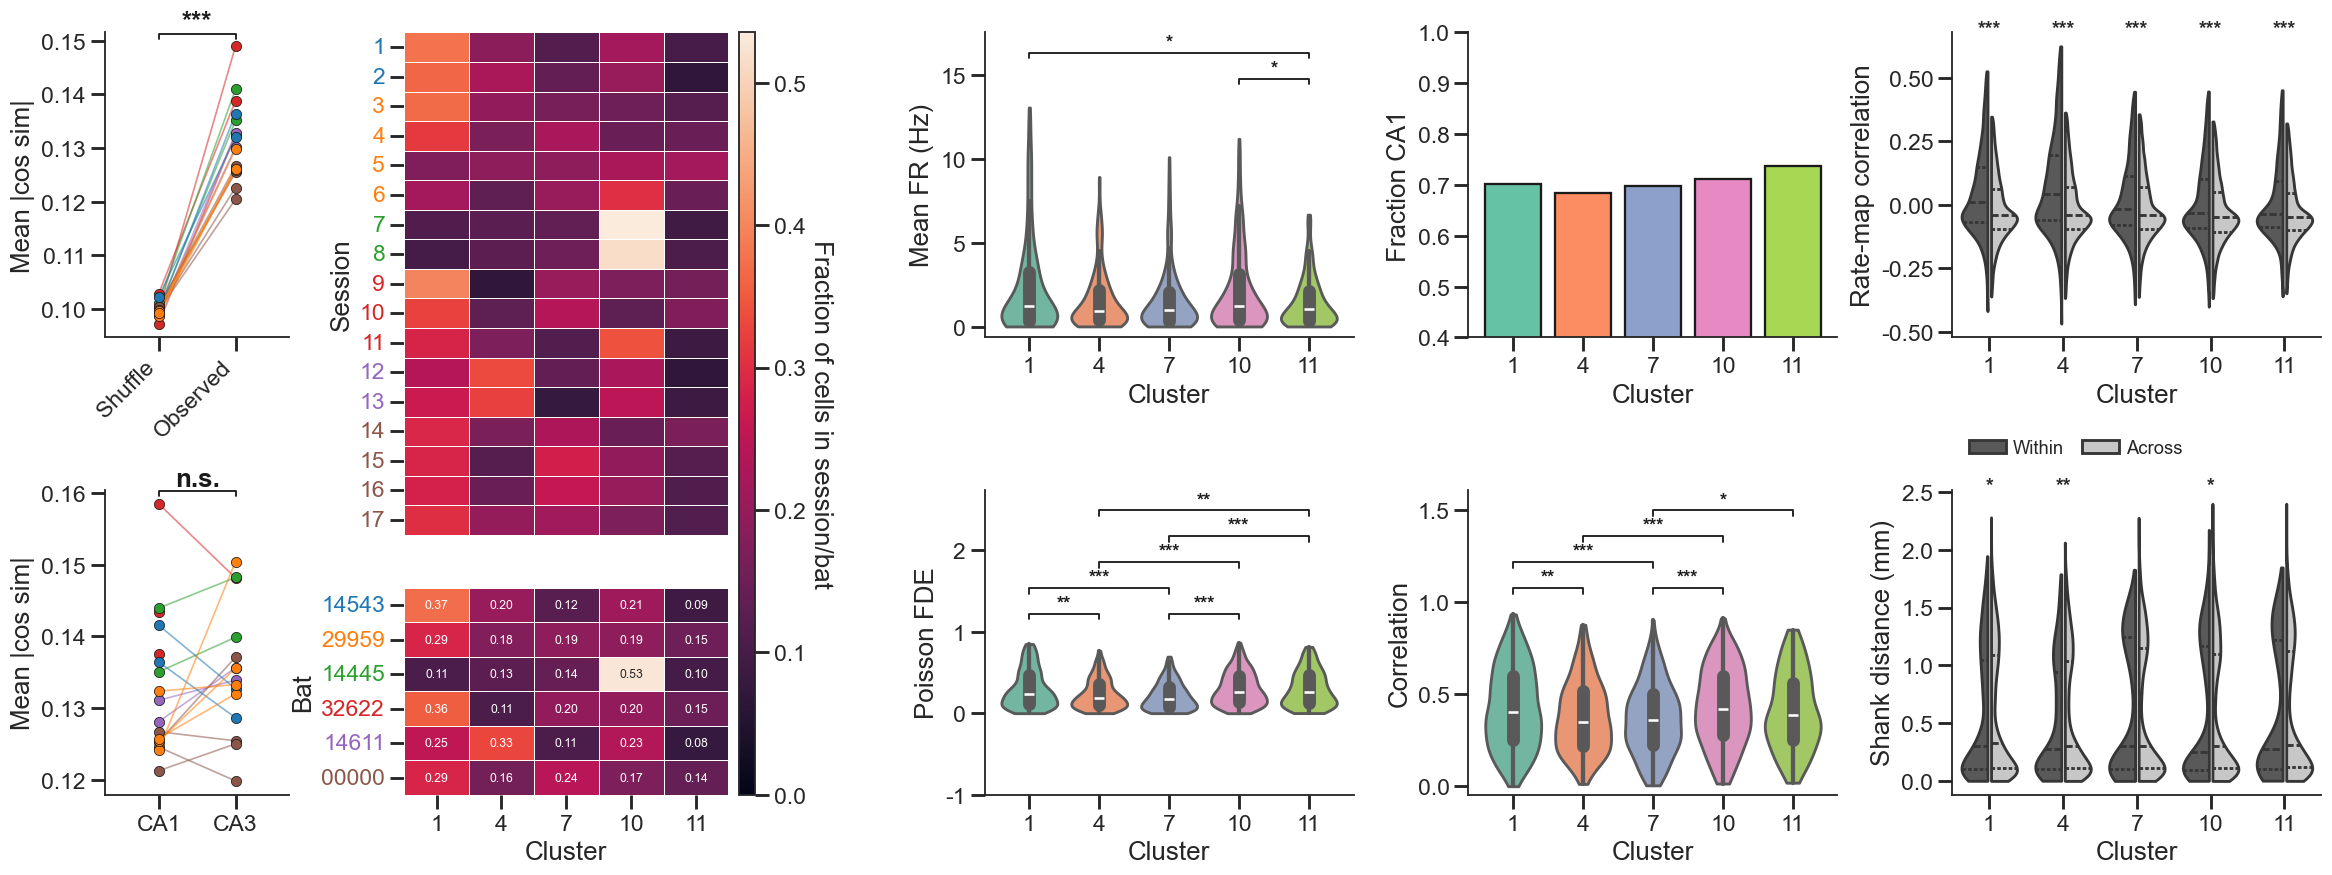

ED Fig 6 — panel statistics:
                  panel                   test          p          comparison   n  stat  med_a   med_b stars         P
                      c chi2 session x cluster  2.046e-23                 NaN NaN   NaN    NaN     NaN   *** P < 0.001
                      c     chi2 bat x cluster  9.149e-32                 NaN NaN   NaN    NaN     NaN   *** P < 0.001
                      a                    NaN  1.526e-05 observed vs shuffle  17     0 0.1301 0.09971   *** P < 0.001
                      b                    NaN     0.3303          CA3 vs CA1  15    42 0.1339  0.1281       P = 0.330
           Mean FR (Hz)         Kruskal-Wallis     0.1552                 NaN NaN   NaN    NaN     NaN       P = 0.155
           Mean FR (Hz)             MWU 1 vs 4     0.3088                 NaN NaN   NaN    NaN     NaN       P = 0.309
           Mean FR (Hz)             MWU 1 vs 7     0.3783                 NaN NaN   NaN    NaN     NaN       P = 0.378
           Mean FR 

,panel,test,p,comparison,n,stat,med_a,med_b,stars,P
0,c,chi2 session x cluster,2.045631e-23,NaN,NaN,NaN,NaN,NaN,***,P < 0.001
1,c,chi2 bat x cluster,9.148810e-32,NaN,NaN,NaN,NaN,NaN,***,P < 0.001
2,a,NaN,1.525879e-05,observed vs shuffle,17.0,0.0,0.130120,0.09971,***,P < 0.001
3,b,NaN,3.302612e-01,CA3 vs CA1,15.0,42.0,0.133894,0.12809,,P = 0.330
4,Mean FR (Hz),Kruskal-Wallis,1.552009e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.155
5,Mean FR (Hz),MWU 1 vs 4,3.087931e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.309
6,Mean FR (Hz),MWU 1 vs 7,3.783140e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.378
7,Mean FR (Hz),MWU 1 vs 10,6.622265e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.662
8,Mean FR (Hz),MWU 1 vs 11,1.270638e-02,NaN,NaN,NaN,NaN,NaN,*,P = 0.013
9,Mean FR (Hz),MWU 4 vs 7,8.967407e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.897


In [47]:
# === Extended Data Figure 6 (a-i) on a single canvas ===
# Layout (column-major lettering); first column is half-width, a thin spacer
# column (col 2) sets the panel-c heatmaps off from the box panels:
#   col 0 (half): a orthogonality vs shuffle | b CA1/CA3 orthogonality
#   col 1       : c session x cluster (top) + bat x cluster (bottom) heatmaps (shared cbar)
#   col 3       : d mean FR | e FDE   (per readout cluster, pairwise MWU brackets)
#   col 4       : f fraction CA1 | g corr
#   col 5       : h rate-map corr | i shank distance  (within vs across, per cluster)
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu, fisher_exact, chi2_contingency

WA_PAL = {'within': '0.35', 'across': '0.78'}   # within/across hue (not canonical)


def cluster_brackets(ax, pair_ps):
    """Stacked significance brackets over a categorical (cluster) x-axis.

    ``pair_ps`` is a list of ``(i, j, p)``. Significant pairs (p<.05) are packed
    into rows greedily so brackets spanning non-overlapping x-ranges (e.g.
    adjacent pairs) share a row, and the whole stack floats in the top margin of
    the axes (headroom added below). Stars sit snug just above their own bracket.
    """
    sig = [(i, j, p) for i, j, p in pair_ps if np.isfinite(p) and p < 0.05]
    if not sig:
        return
    rows = []                                    # each row: list of occupied (x1,x2)
    def assign(x1, x2):
        for r, ivs in enumerate(rows):
            if all(x2 < a - 0.25 or x1 > b + 0.25 for a, b in ivs):
                ivs.append((x1, x2)); return r
        rows.append([(x1, x2)]); return len(rows) - 1
    placed = [(i, j, p, assign(i, j))            # short spans first -> lowest rows
              for i, j, p in sorted(sig, key=lambda t: (t[1] - t[0], t[0]))]
    nrows = len(rows)
    row_h, pad, bh = 0.085, 0.04, 0.018
    zone = min(0.55, pad + nrows * row_h)        # axes-fraction reserved above data
    y0, y1 = ax.get_ylim()                        # push data down into (1-zone)
    ax.set_ylim(y0, y0 + (y1 - y0) / (1 - zone))
    trans = ax.get_xaxis_transform()             # x data, y axes-fraction
    ybase = 1 - zone + pad
    for i, j, p, r in placed:
        y = ybase + r * row_h
        ax.plot([i, i, j, j], [y, y + bh, y + bh, y], transform=trans,
                lw=1.2, color='k', clip_on=False)
        ax.text((i + j) / 2, y + bh + 0.004, ph.stars_for_p(p), transform=trans,
                ha='center', va='bottom', fontsize=12, fontweight='bold',
                color='k', clip_on=False)

fig_ed8 = plt.figure(figsize=(26, 9))
gs_ed8 = fig_ed8.add_gridspec(2, 6, width_ratios=[0.5, 0.95, 0, 1, 1, 1], hspace=0.5, wspace=0.42)
A_a = fig_ed8.add_subplot(gs_ed8[0, 0]); A_b = fig_ed8.add_subplot(gs_ed8[1, 0])
A_c = fig_ed8.add_subplot(gs_ed8[0, 3]); A_d = fig_ed8.add_subplot(gs_ed8[1, 3])
A_e = fig_ed8.add_subplot(gs_ed8[0, 4]); A_f = fig_ed8.add_subplot(gs_ed8[1, 4])
A_g = fig_ed8.add_subplot(gs_ed8[0, 5]); A_h = fig_ed8.add_subplot(gs_ed8[1, 5])
cats = CLUSTER_ORDER
ed8_p = []

# --- c, d: cluster-composition heatmaps stacked in column 1 with a single shared
#           colour scale.  Rows are sessions (c) or bats (d), columns are the five
#           included readout clusters; each row is the fraction of that session's /
#           bat's well-fit cells falling in each cluster (rows sum to 1). Row
#           (y-tick) labels are coloured by bat. ---
clu_df['bat'] = clu_df['session'].map(parse_bat)
BAT_PAL = ph.bat_palette()
_incl = clu_df[clu_df['cluster'].isin(cats)]
bats_ed = [b for b in BAT_PAL if b in set(_incl['bat'])]         # canonical bat order
_bo = {b: i for i, b in enumerate(bats_ed)}
sess_meta = _incl[['session', 'bat']].drop_duplicates()
sess_meta = sess_meta.assign(_bo=sess_meta['bat'].map(_bo)).sort_values(['_bo', 'session'])
sess_order = sess_meta['session'].tolist()
sess_n = pd.crosstab(_incl['session'], _incl['cluster']).reindex(index=sess_order, columns=cats, fill_value=0)
bat_n = pd.crosstab(_incl['bat'], _incl['cluster']).reindex(index=bats_ed, columns=cats, fill_value=0)
sess_frac = sess_n.div(sess_n.sum(axis=1), axis=0)              # per-session row -> fraction
bat_frac = bat_n.div(bat_n.sum(axis=1), axis=0)
vmax = float(max(sess_frac.to_numpy().max(), bat_frac.to_numpy().max()))
gs_comp = gs_ed8[:, 1].subgridspec(2, 2, width_ratios=[1, 0.05],
                                   height_ratios=[len(sess_order), len(bats_ed) + 1],
                                   hspace=0.15, wspace=0.06)
A_comp_s = fig_ed8.add_subplot(gs_comp[0, 0])                   # c: session x cluster
A_comp_b = fig_ed8.add_subplot(gs_comp[1, 0])                   # d: bat x cluster
cax_comp = fig_ed8.add_subplot(gs_comp[:, 1])
hm_kw = dict(cmap='rocket', vmin=0, vmax=vmax, linewidths=0.5, linecolor='w', cbar=False)
sns.heatmap(sess_frac, ax=A_comp_s, **hm_kw)
A_comp_s.set(xlabel='', ylabel='session')
A_comp_s.set_yticklabels([str(i) for i in range(1, len(sess_order) + 1)], rotation=0)
A_comp_s.tick_params(axis='x', labelbottom=False, bottom=False)
for _t, _s in zip(A_comp_s.get_yticklabels(), sess_order):
    _t.set_color(BAT_PAL[parse_bat(_s)])
sns.heatmap(bat_frac, ax=A_comp_b, annot=True, fmt='.2f', annot_kws={'fontsize': 8}, **hm_kw)
A_comp_b.set(xlabel='cluster', ylabel='bat')
A_comp_b.set_yticklabels(bats_ed, rotation=0)
for _t, _b in zip(A_comp_b.get_yticklabels(), bats_ed):
    _t.set_color(BAT_PAL[_b])
_cbar = fig_ed8.colorbar(A_comp_b.collections[0], cax=cax_comp)
_cbar.set_label('Fraction of cells in session/bat', rotation=270, labelpad=18)
ed8_p.append(dict(panel='c', test='chi2 session x cluster',
                  p=chi2_contingency(sess_n.values)[1] if (sess_n.values.sum(1) > 0).all() else np.nan))
ed8_p.append(dict(panel='c', test='chi2 bat x cluster',
                  p=chi2_contingency(bat_n.values)[1] if (bat_n.values.sum(1) > 0).all() else np.nan))

# --- a: residual-readout orthogonality (mean |cos|) vs chance ---
rng = np.random.default_rng(seed)
orth = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    obs = np.abs((Wr @ Wr.T)[iu]).mean()
    R = rng.standard_normal((len(grp), Wr.shape[1]))
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    cha = np.abs((R @ R.T)[iu]).mean()
    orth.append(dict(session=sn, bat=parse_bat(sn), observed=obs, chance=cha))
orth_df = pd.DataFrame(orth)
orth_long = orth_df.melt(['session', 'bat'], ['chance', 'observed'], 'kind', 'v')
ph.paired_lines(A_a, orth_long, 'v', 'kind', ['chance', 'observed'])
ra = ph.paired_session_test(orth_long, 'v', 'kind', 'observed', 'chance')
ph.sig_bracket(A_a, 0, 1, ra['p'])
A_a.set(ylabel='mean |cos sim|')
A_a.set_xticklabels(['shuffle', 'observed'], rotation=45, ha='right')  # data key = 'chance'
A_a.set_xlim(-0.7, 1.7)                                # widen so the points sit inward
ed8_p.append(dict(panel='a', comparison='observed vs shuffle', **ra))

# --- b: within-subregion orthogonality, CA1 vs CA3 (paired by session) ---
subo = []
for (sn, sr), grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby(['session', 'subregion']):
    if len(grp) < SUB_MIN_NEURONS:   # >=10 neurons per subregion, matching Fig 4 CA1/CA3
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    subo.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                     morth=np.abs((Wr @ Wr.T)[iu]).mean()))
subo_df = pd.DataFrame(subo)
ph.paired_lines(A_b, subo_df, 'morth', 'subregion', ['CA1', 'CA3'])
rb = ph.paired_session_test(subo_df, 'morth', 'subregion', 'CA3', 'CA1')
ph.sig_bracket(A_b, 0, 1, rb['p'], show_ns=True)      # annotate n.s.
A_b.set(ylabel='mean |cos sim|')
A_b.set_xlim(-0.7, 1.7)                                # widen so the points sit inward
ed8_p.append(dict(panel='b', comparison='CA3 vs CA1', **rb))

# --- c, d, e: per-cluster mean FR / FDE / corr (Kruskal-Wallis omnibus +
#              pairwise Mann-Whitney brackets between every significant pair) ---
clu_df['is_ca1'] = (clu_df['subregion'] == 'CA1').astype(float)
clu_df.loc[~clu_df['subregion'].isin(['CA1', 'CA3']), 'is_ca1'] = np.nan
for ax, (col, ylab, clip) in zip([A_c, A_d, A_f],
                                 [('mean_fr', 'Mean FR (Hz)', False),
                                  ('fde_all', 'Poisson FDE', True),
                                  ('corr_all', 'Correlation', False)]):
    ph.cat_violin(ax, clu_df, 'cluster', col, cats, CLUSTER_PALETTE, trim_outliers=True)
    ax.set(xlabel='cluster', ylabel=ylab)
    if clip:
        ax.set_ylim(-1, 1)                       # FDE display floored at -1
    vals = {c: clu_df.loc[clu_df['cluster'] == c, col].dropna().values for c in cats}
    grps = [vals[c] for c in cats if len(vals[c]) > 1]
    p_kw = kruskal(*grps).pvalue if len(grps) >= 2 else np.nan
    ed8_p.append(dict(panel=ylab, test='Kruskal-Wallis', p=p_kw))
    pair_ps = []
    for i, j in combinations(range(len(cats)), 2):
        a, b = vals[cats[i]], vals[cats[j]]
        if len(a) < 2 or len(b) < 2:
            continue
        pp = mannwhitneyu(a, b, alternative='two-sided').pvalue
        ed8_p.append(dict(panel=ylab, test=f'MWU {cats[i]} vs {cats[j]}', p=pp))
        pair_ps.append((i, j, pp))
    cluster_brackets(ax, pair_ps)

# --- f: fraction CA1 per cluster (y-axis starts at 0.4); per-cluster Fisher ---
frac = clu_df.groupby('cluster')['is_ca1'].mean().reindex(cats)
A_e.bar(range(len(cats)), frac.values, color=[CLUSTER_PALETTE[c] for c in cats], edgecolor='k')
A_e.set(xticks=range(len(cats)), xticklabels=cats, xlabel='cluster', ylabel='Fraction CA1')
A_e.set_ylim(0.4, 1.0)
ca1n = clu_df.groupby('cluster')['is_ca1'].agg(n_ca1='sum', n=lambda s: s.notna().sum())
tot_ca1, tot_n = ca1n['n_ca1'].sum(), ca1n['n'].sum()
tab = np.array([[ca1n.loc[c, 'n_ca1'], ca1n.loc[c, 'n'] - ca1n.loc[c, 'n_ca1']] for c in cats])
p_chi = chi2_contingency(tab)[1] if (tab.sum(1) > 0).all() else np.nan
ed8_p.append(dict(panel='Fraction CA1', test='chi2 across clusters', p=p_chi))
trans_f = A_e.get_xaxis_transform()
for xi, c in enumerate(cats):
    a1 = ca1n.loc[c, 'n_ca1']; a0 = ca1n.loc[c, 'n'] - a1
    b1 = tot_ca1 - a1; b0 = (tot_n - ca1n.loc[c, 'n']) - b1
    p = fisher_exact([[a1, a0], [b1, b0]])[1]
    ed8_p.append(dict(panel=f'Fraction CA1:cluster {c}', test='Fisher vs rest', p=p))
    s = ph.stars_for_p(p)
    if s:
        A_e.text(xi, 0.96, s, transform=trans_f, ha='center', va='bottom',
                 fontsize=12, fontweight='bold', clip_on=False)


def _within_across(ax, data, ycol, ylabel, panel, *, legend=False):
    """Boxplot of within- vs across-cluster values per cluster (x), one star
    over each cluster from a within-vs-across Mann-Whitney (no bracket)."""
    _vd = ph.tukey_trim(data, ycol, ['cluster', 'kind'])   # showfliers=False analogue (display only)
    sns.violinplot(data=_vd, x='cluster', y=ycol, order=cats, hue='kind',
                   hue_order=['within', 'across'], palette=WA_PAL,
                   split=True, inner='quartile', cut=0, density_norm='width',
                   gap=0.12, ax=ax)
    trans = ax.get_xaxis_transform()
    for xi, c in enumerate(cats):
        w = data.loc[(data['cluster'] == c) & (data['kind'] == 'within'), ycol].dropna().values
        a = data.loc[(data['cluster'] == c) & (data['kind'] == 'across'), ycol].dropna().values
        p = mannwhitneyu(w, a, alternative='two-sided').pvalue if len(w) > 1 and len(a) > 1 else np.nan
        ed8_p.append(dict(panel=f'{panel}:cluster {c}', test='MWU within vs across', p=p))
        s = ph.stars_for_p(p)
        if s:
            ax.text(xi, 0.98, s, transform=trans, ha='center', va='bottom',
                    fontsize=13, fontweight='bold', clip_on=False)
    ax.set(xlabel='cluster', ylabel=ylabel)
    if legend:
        ax.legend(title='', loc='upper left', bbox_to_anchor=(0.0, -0.28), ncol=2,
                  fontsize=12, frameon=False, columnspacing=1.0, handletextpad=0.4)
    elif ax.legend_ is not None:
        ax.legend_.remove()


# --- g: rate-map correlation, within vs across cluster, per cluster ---
rm_rows = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 2:
        continue
    units = grp['unit'].to_numpy(); cl = grp['cluster'].to_numpy()
    Cm = ratemap_corr_matrix(session_rate_maps[sn][units])
    iu, ju = np.triu_indices(len(units), 1)
    v = Cm[iu, ju]; ok = np.isfinite(v)
    for ci, cj, val in zip(cl[iu][ok], cl[ju][ok], v[ok]):
        if ci == cj:
            rm_rows.append((ci, 'within', val))
        else:
            rm_rows.append((ci, 'across', val)); rm_rows.append((cj, 'across', val))
rmc_df = pd.DataFrame(rm_rows, columns=['cluster', 'kind', 'r'])
_within_across(A_g, rmc_df, 'r', 'Rate-map correlation', 'h', legend=True)

# --- h: physical distance along shank, within vs across cluster, per cluster ---
dist_rows = []
for (sn, pr), grp in clu_df.groupby(['session', 'probe_id']):
    if len(grp) < 2:
        continue
    xy = grp[['lateral', 'depth']].to_numpy(); cl = grp['cluster'].to_numpy()
    iu, ju = np.triu_indices(len(grp), k=1)
    d = np.linalg.norm(xy[iu] - xy[ju], axis=1) / 1000.0          # µm -> mm
    for ci, cj, val in zip(cl[iu], cl[ju], d):
        if ci == cj:
            dist_rows.append((ci, 'within', val))
        else:
            dist_rows.append((ci, 'across', val)); dist_rows.append((cj, 'across', val))
dist_df = pd.DataFrame(dist_rows, columns=['cluster', 'kind', 'd'])
_within_across(A_h, dist_df, 'd', 'Shank distance (mm)', 'i')

ph.save_fig(fig_ed8, 'edfig6_full'); plt.show()
print('ED Fig 6 — panel statistics:'); ph.p_table(ed8_p)

**Extended Data Figure 6 | Residual readout cluster comparisons.** (A) Residual readout weights are less orthogonal (higher within-session mean absolute cosine similarity) than random unit vectors of matched dimension. Each line is one session (colored by bat), plotted as the per-session mean; observed versus shuffle compared by two-sided paired Wilcoxon signed-rank test on per-session values ($P = 1.53 \times 10^{-5}$; n = 17 sessions). (B) Orthogonality (within-subregion mean absolute cosine similarity) does not differ between CA1 and CA3; two-sided paired Wilcoxon signed-rank, $P = 0.330$, n.s.; n = 15 sessions with $\ge$10 neurons per subregion. (C) Fraction of each session's (top) or each bat's (bottom) well-fit neurons (Poisson FDE > 0), restricted to the five analyzed readout clusters, falling in each cluster. (D–G) Mean firing rate, fraction of CA1 neurons, Poisson FDE, and Pearson correlation per cluster. For (E), $\chi^{2}$ test of independence across clusters as omnibus, $P = 0.775$; two-sided Fisher's exact test of each cluster's CA1/CA3 split versus the pooled remaining clusters, all n.s.). For other panels, Kruskal–Wallis omnibus across clusters; brackets mark every significant pairwise two-sided Mann–Whitney U comparison. Mean FR: omnibus $P = 0.155$ (n.s.); significant pairs 1 vs 11 $P = 0.0127$, 10 vs 11 $P = 0.0279$. Poisson FDE: omnibus $P = 2.91 \times 10^{-8}$; significant pairs 1 vs 4 $P = 0.0026$, 1 vs 7 $P = 1.70 \times 10^{-5}$, 4 vs 10 $P = 3.18 \times 10^{-5}$, 4 vs 11 $P = 0.00462$, 7 vs 10 $P = 5.40 \times 10^{-8}$, 7 vs 11 $P = 8.23 \times 10^{-5}$. Pearson correlation: omnibus $P = 3.87 \times 10^{-5}$; significant pairs 1 vs 4 $P = 0.00457$, 1 vs 7 $P = 3.48 \times 10^{-4}$, 4 vs 10 $P = 4.84 \times 10^{-4}$, 7 vs 10 $P = 2.60 \times 10^{-5}$, 7 vs 11 $P = 0.0379$). (H–I) Rate-map correlation (H) and physical distance along the shank (I, mm) for neuron pairs within versus across cluster, shown per cluster, with a two-sided Mann–Whitney U comparing within versus across. (H) Cluster 1 $P = 2.19 \times 10^{-185}$, 4 $P = 3.13 \times 10^{-133}$, 7 $P = 3.65 \times 10^{-26}$, 10 $P = 4.31 \times 10^{-52}$, 11 $P = 4.40 \times 10^{-17}$. (I) Cluster 1 $P = 0.0118$, 4 $P = 0.00157$, 7 $P = 0.384$ (n.s.), 10 $P = 0.0264$, 11 $P = 0.834$ (n.s.).

## Extended Data Table 1 — Auxiliary masking-task sweep

Joint **Twin** model trained from scratch (1000 epochs, early stopping) at the
`base_6.3` hyperparameters (L4 / d64 / ff64, lr 4.5e-3, weight decay 3e-4, lam 0.61,
pos_weight 0.84), over `encode`+`decode` plus **every subset (0–4) of the four auxiliary
self-supervised masking tasks** `{within, cross, forecast, forecast_stim}` — 16
combinations. Scheme sampling weights are fixed at `w_encode`=1.93, `w_decode`=2.83, with
the **total auxiliary-task probability held constant** across combinations by setting
`w_aux = 0.67·3 / n_aux` (so `n_aux`=3 recovers 0.67 each). Models are selected on the
**validation** joint score `0.5·FDE/0.1 - 0.5·err/0.3`; the test column is shown for
reference. Reproduction / training code: `joint-encode-decode.ipynb` §6.8, which writes
`./out/joint/joint_scheme_sweep.pkl`. For reference, the warm-started fine-tune scores
test joint 0.127 and the `base_6.3` consensus 0.064.

In [ ]:
# === Extended Data Table 1: auxiliary masking-task sweep ===
# Loads the 16-combo sweep produced by joint-encode-decode.ipynb section 6.8 and tabulates
# it. Each combo = encode+decode plus a subset of {within, cross, forecast, forecast_stim},
# trained from scratch (1000 ep, early stopping) at the base_6.3 hyperparameters; scheme
# weights w_encode=1.93, w_decode=2.83 fixed, total aux probability held constant via
# w_aux = 0.67*3/n_aux. Model selection is on validation joint (test shown for reference).
_sweep = pd.read_pickle('./out/joint/joint_scheme_sweep.pkl')
_rows = []
for _key, _rec in _sweep.items():
    _aux = [s for s in _rec['schemes'] if s not in ('encode', 'decode')]
    _rows.append({
        'auxiliary tasks': ' + '.join(_aux) if _aux else '(none)',
        'n_aux': _rec['n_aux'],
        'w_aux': round(_rec['w_aux'], 3),
        'decode err (m)': _rec['test']['err'],
        'encode FDE': _rec['test']['fde'],
        'joint (valid)': _rec['valid']['joint'],
        'joint (test)': _rec['test']['joint'],
    })
ed_table1 = (pd.DataFrame(_rows)
             .sort_values('joint (valid)', ascending=False)
             .reset_index(drop=True))
ed_table1.index += 1                       # 1-based rank
ed_table1.to_csv('out/figures/ed_table1_scheme_sweep.csv')
print(f'Extended Data Table 1 - auxiliary masking-task sweep of the {OUR_MODEL} model')
print('(model selection on validation joint; 16 combos, base_6.3 hyperparameters)')
# --- LaTeX version for the manuscript: writes out/figures/ed_table1_scheme_sweep.tex ---
# booktabs only (no siunitx); swap table -> table* for a two-column layout.
_TEX_CAPTION = (
    r'\textbf{Extended Data Table 1 $|$ Auxiliary masking-task sweep.} '
    r'The joint Twin model was trained from scratch (1{,}000 epochs, early stopping, 4 transformer layers, latent dimension $d = 64$, feed-forward width 64, learning rate $4.5 \times 10^{-3}$, weight decay $3 \times 10^{-4}$, decoding weight $\lambda = 0.61$, positive weight 0.84) on the \texttt{encode} and \texttt{decode} tasks plus every subset (0--4) of the four auxiliary self-supervised masking tasks \texttt{within}, \texttt{cross} (also called \texttt{infill} in the main text), \texttt{forecast} and \texttt{forecast\_stim} --- 16 combinations in total. Scheme sampling weights are fixed at $w_{\mathrm{encode}} = 1.93$ and $w_{\mathrm{decode}} = 2.83$, and the total auxiliary-task probability is held constant across combinations by setting $w_{\mathrm{aux}} = 0.67 \times 3 / n_{\mathrm{aux}}$. Rows are ranked by the validation joint score $0.5 \, (\mathrm{FDE}/0.1) - 0.5 \, (\mathrm{err}/0.3)$, which is the model-selection criterion; the decode error, encode FDE and joint score in the remaining columns are held-out test values, shown for reference only. The combination with the best validation score is shown in bold. For reference, the further fine-tuning the parameters of the \texttt{cross} model reaches a test joint score of $0.127$.')


def _tex_num(v, nd=4):
    """Fixed-width number with a proper math minus sign."""
    return (r'$-$' if v < 0 else '') + f'{abs(v):.{nd}f}'


def _tex_tasks(s):
    return s if s == '(none)' else ' + '.join(r'\texttt{' + t.replace('_', r'\_') + '}'
                                              for t in s.split(' + '))


_tex_rows = []
for _rank, _r in ed_table1.iterrows():
    _cells = [str(_rank), _tex_tasks(_r['auxiliary tasks']), str(int(_r['n_aux'])),
              f"{_r['w_aux']:.3f}", _tex_num(_r['decode err (m)']), _tex_num(_r['encode FDE']),
              _tex_num(_r['joint (valid)']), _tex_num(_r['joint (test)'])]
    if _rank == 1:                                   # best validation joint
        _cells = [r'\textbf{' + _c + '}' for _c in _cells]
    _tex_rows.append('  ' + ' & '.join(_cells) + r' \\')

_tex = '\n'.join([
    r'% Extended Data Table 1 -- auxiliary masking-task sweep.',
    r'% Requires \usepackage{booktabs} and \usepackage{array}. Use table* if two-column.',
    r'\begin{table}[htbp]',
    r'\centering',
    r'\small',
    r'\setlength{\tabcolsep}{4pt}',
    r'\caption{' + _TEX_CAPTION + '}',
    r'\label{tab:S1}',
    r'\begin{tabular}{c>{\raggedright\arraybackslash}p{3.6cm}ccrrrr}',   # p{} wraps the task list
    r'\toprule',
    r'Rank & Auxiliary tasks & $n_{\mathrm{aux}}$ & $w_{\mathrm{aux}}$ & Decode err.\ (m) & '
    r'Encode FDE & Joint (valid) & Joint (test) \\',
    r'\midrule',
    *_tex_rows,
    r'\bottomrule',
    r'\end{tabular}',
    r'\end{table}',
])
with open('out/figures/ed_table1_scheme_sweep.tex', 'w') as _fh:
    _fh.write(_tex + '\n')
print('\nwrote out/figures/ed_table1_scheme_sweep.tex')
ed_table1.round(4)

Extended Data Table 1 - auxiliary masking-task sweep of the Twin model
(model selection on validation joint; 16 combos, base_6.3 hyperparameters)


,auxiliary tasks,n_aux,w_aux,decode err (m),encode FDE,joint (valid),joint (test)
1,cross,1,2.010,0.2812,0.1093,0.0747,0.0781
2,within + cross + forecast + forecast_stim,4,0.503,0.2859,0.1139,0.0387,0.0929
3,within + forecast_stim,2,1.005,0.2878,0.1159,0.0309,0.0997
4,within + cross,2,1.005,0.2806,0.1099,0.0236,0.0815
5,cross + forecast_stim,2,1.005,0.2940,0.1084,0.0223,0.0518
6,cross + forecast,2,1.005,0.2900,0.1088,0.0108,0.0605
7,within + cross + forecast,3,0.670,0.2769,0.1129,0.0071,0.1032
8,(none),0,0.000,0.2951,0.1029,-0.0087,0.0228
9,within + forecast,2,1.005,0.3045,0.1052,-0.0094,0.0185
10,within + cross + forecast_stim,3,0.670,0.2863,0.1152,-0.0116,0.0989
